# Restrições de geração eólica na Bahia: padrões de calendário e contribuição da meteorologia

**PCS5787 — Ciência dos Dados e Big Data**  
**Escola Politécnica da Universidade de São Paulo · Grupo 9**  
Matheus T. de Paula · Pedro A. M. A. Filho · Robert Caetano  
Professor: Pedro Luiz Pizzigatti Corrêa

Uma usina eólica nem sempre pode aproveitar todo o vento disponível. Em certas condições, a operação do sistema elétrico exige reduzir sua geração. Essas restrições representam energia que poderia estar disponível, mas que não é aproveitada segundo a apuração operacional. Antecipar quando elas ocorrem e estimar sua intensidade são problemas relevantes para a integração da energia eólica.

Neste estudo, integramos registros de geração e restrições do **Operador Nacional do Sistema Elétrico (ONS)** com medições do **Instituto Nacional de Meteorologia (INMET)**. O período analisado vai de janeiro de 2022 a setembro de 2026. O recorte energético compreende os conjuntos classificados como BA na fonte do ONS; ele não equivale automaticamente a todas as usinas fisicamente situadas na Bahia.

Investigamos duas fontes de informação para a previsão. A primeira é o **calendário**: a hora do dia, a época do ano e a região podem revelar regularidades nas restrições. A segunda é a **meteorologia**, que pode distinguir situações com o mesmo calendário, mas condições de vento diferentes. Também examinamos a importância de atualizar o treinamento e de prever a intensidade dos cortes, além de sua ocorrência.

O percurso começa nos dados, não nos algoritmos. Primeiro precisamos definir o que cada registro representa, avaliar sua qualidade e compatibilizar fontes com localizações e frequências diferentes. A análise exploratória orienta a construção dos atributos; os modelos permitem avaliar quanto dessas informações se transforma em capacidade de previsão.

### A observação que será prevista: uma região durante uma hora

**Cada linha da base principal descreve uma região durante uma hora.** Uma região é, aqui, um agrupamento de conjuntos eólicos associado a uma referência meteorológica. Não é necessariamente um município nem uma divisão oficial da rede elétrica. Os códigos A408, A423 e os demais identificam esses agrupamentos; explicaremos sua construção na integração espacial.

Por exemplo, os registros abaixo representam três observações diferentes:

| Região | Intervalo descrito | Por que é outra observação? |
|---|---|---|
| A408 | 15/07/2024, das 14h às 15h | Uma região em uma hora |
| A408 | 15/07/2024, das 15h às 16h | A região é a mesma, mas a hora mudou |
| A423 | 15/07/2024, das 14h às 15h | A hora é a mesma, mas a região mudou |

O exemplo ilustra a estrutura da tabela, sem atribuir valores energéticos a essas linhas. Em cada observação reunimos a energia de referência, a energia restringida, os motivos de restrição e os atributos disponíveis para prever o intervalo. **Região × hora** é apenas uma forma abreviada de nomear essa unidade de observação.

Uma parte das colunas descreve o resultado que queremos prever; outra contém as informações que o modelo pode conhecer antes dele. Separar esses papéis será essencial para não fornecer ao modelo a própria resposta.

<a id="secao-0"></a>

## 0. Organização do estudo e como executá-lo

A leitura acompanha as etapas de Ciência dos Dados. Primeiro apresentamos o problema, formulamos as perguntas e mostramos como os registros ONS e INMET foram administrados, limpos e integrados (seções 1–7). Em seguida, analisamos os padrões observados e construímos atributos motivados por esses resultados (seções 8–12). A síntese ao final da seção 12 mostra como cada descoberta leva a uma das quatro hipóteses.

As seções 13–14 explicam **quais modelos e estratégias de treinamento realmente precisamos comparar** e como interpretar as métricas. A seção 15 apresenta **quatro experimentos**, um para cada hipótese, sempre com os modelos, curvas, indicadores de decisão e interpretação próximos. A seção 16 estuda a intensidade total das restrições, enquanto as seções 17–19 discutem os resultados, permitem reproduzi-los e encerram com as conclusões.

**Execução.** Extraia o pacote completo e abra este notebook em Jupyter. Execute *Restart Kernel and Run All*, com Python 3.11 e as bibliotecas listadas em `requirements.txt`. Os arquivos de `dados/` permitem recalcular as figuras e tabelas sem baixar novamente toda a base bruta. O notebook demonstra um treinamento logístico completo; os demais resultados são reproduzidos a partir de previsões individuais existentes e verificáveis.

A reprodução integral dos dados brutos e o retreinamento de todos os modelos exigem as fontes originais e os protocolos documentados separadamente. A execução padrão distingue explicitamente essas modalidades, sem chamar recálculo de métricas de novo treinamento.


### Sumário

- [0 — Guia de leitura e execução](#secao-0)
- [1 — Geração eólica e restrições](#secao-1)
- [2 — Perguntas científicas e hipóteses](#secao-2)
- [3 — Gestão e organização dos dados](#secao-3)
- [4 — Fontes e variáveis](#secao-4)
- [5 — Limpeza e qualidade](#secao-5)
- [6 — Integração temporal e espacial](#secao-6)
- [7 — Alvos e observações](#secao-7)
- [8 — EDA energética](#secao-8)
- [9 — EDA meteorológica](#secao-9)
- [10 — Associações entre vento e restrições](#secao-10)
- [11 — Seleção de dados e PCA](#secao-11)
- [12 — Engenharia de atributos e ligação com as hipóteses](#secao-12)
- [13 — Modelos e treinamento](#secao-13)
- [14 — Métricas de avaliação](#secao-14)
- [15 — Quatro experimentos de classificação](#secao-15)
- [16 — Intensidade dos cortes](#secao-16)
- [17 — Discussão e limitações](#secao-17)
- [18 — Reprodução e material complementar](#secao-18)
- [19 — Conclusões](#secao-19)


**Leitura orientada da H2:** [contribuições SHAP e exemplo real](#h2-importancia) →
[permutação e seleção temporal](#h2-selecao) →
[modelos reduzidos e não inferioridade](#h2-avaliacao-reduzida).
O aprofundamento integra a H2; não cria uma nova hipótese nem altera as comparações históricas.


In [1]:
import os, sys, json, time, importlib.util
from pathlib import Path
INICIO = time.perf_counter()
for nome in ['OMP_NUM_THREADS', 'OPENBLAS_NUM_THREADS', 'MKL_NUM_THREADS', 'NUMEXPR_NUM_THREADS']:
    os.environ[nome] = '1'

# A raiz é a pasta do pacote, que reúne notebook, dados e código.
if os.environ.get('PCS5787_NOTEBOOK_ROOT'):
    ROOT = Path(os.environ['PCS5787_NOTEBOOK_ROOT']).resolve()
else:
    candidatos = [Path.cwd(), *Path.cwd().parents]
    ROOT = next((p for p in candidatos if (p/'dados/base_regiao_hora.npz').exists()), None)
    if ROOT is None:
        raise FileNotFoundError('Extraia o pacote completo e abra o notebook na pasta PCS5787_Projeto.')
OUT = ROOT/'resultados'
for pasta in ['figuras', 'tabelas', 'recibos']:
    (OUT/pasta).mkdir(parents=True, exist_ok=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from threadpoolctl import threadpool_limits
LIMITES_THREADS = threadpool_limits(limits=1)
SEED = 5787
np.random.seed(SEED)

def importar_modulo(nome, arquivo):
    spec = importlib.util.spec_from_file_location(nome, arquivo)
    modulo = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(modulo)
    return modulo

apoio = importar_modulo('apoio_projeto', ROOT/'codigo/apoio.py')
apresentacao = importar_modulo('apresentacao_projeto', ROOT/'codigo/apresentacao.py')
dados = importar_modulo('dados_projeto', ROOT/'codigo/dados.py')
ler_tabela = dados.carregar_tabela

def tabela(frame, nome, titulo=None):
    apresentacao.tabela(frame, nome, OUT, titulo, apoio.TABELAS)
def tabela_textual(frame, nome, titulo):
    apresentacao.tabela(frame, nome, OUT, titulo, apoio.TABELAS, textual=True)
def figura(fig, nome):
    apresentacao.figura(fig, nome, OUT, apoio.FIGURAS)
texto = apresentacao.texto

import importlib.metadata as metadata
versoes = {x: metadata.version(x) for x in
           ['numpy', 'pandas', 'scikit-learn', 'matplotlib', 'nbclient', 'scipy']}
tabela(pd.Series(versoes, name='Versão instalada'), 'ambiente', 'Bibliotecas utilizadas nesta execução')
base = ler_tabela(ROOT/'dados/base_regiao_hora.npz')
met = ['wind_lag1','wind_lag3','wind_lag6','wind_lag24',
       'gust_lag1','gust_lag24','wind_mean24','gust_max24']
motivos = ['ENE','CNF','REL']
tz = 'America/Bahia'
assert not base.duplicated(['region','time_local']).any()
print(f'Base: {len(base):,} observações, {base.region.nunique()} regiões; uma linha por região e hora.')

**Bibliotecas utilizadas nesta execução**

,Versão instalada
numpy,2.4.6
pandas,3.0.6
scikit-learn,1.9.1
matplotlib,3.11.2
nbclient,0.11.0
scipy,1.17.1


Base: 332,928 observações, 8 regiões; uma linha por região e hora.


### Encadeamento das etapas

Cada etapa prepara uma decisão da seguinte. A qualidade das medições determina quais observações podem ser usadas; a integração estabelece o significado de cada linha; a EDA identifica padrões e limitações; os atributos representam esses padrões para os modelos. Por fim, a avaliação verifica quais escolhas produziram previsões úteis. Esse fluxo permite voltar a uma etapa quando surge um problema, sem confundir mudança de método com melhoria já demonstrada.

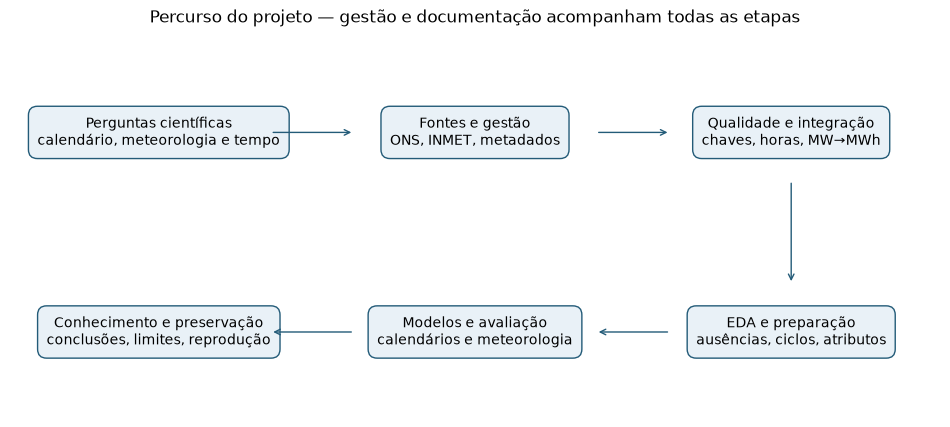

In [2]:
fig, ax = plt.subplots(figsize=(12,4.8)); ax.axis('off')
etapas = ['Perguntas científicas\ncalendário, meteorologia e tempo','Fontes e gestão\nONS, INMET, metadados',
          'Qualidade e integração\nchaves, horas, MW→MWh','EDA e preparação\nausências, ciclos, atributos',
          'Modelos e avaliação\ncalendários e meteorologia','Conhecimento e preservação\nconclusões, limites, reprodução']
pos = [(0.16,.77),(.50,.77),(.84,.77),(.84,.23),(.50,.23),(.16,.23)]
for (x,y),label in zip(pos,etapas):
    ax.text(x,y,label,ha='center',va='center',transform=ax.transAxes,
            bbox=dict(boxstyle='round,pad=.65',facecolor='#e9f1f7',edgecolor='#235b78'),fontsize=10)
setas=[((.28,.77),(.37,.77)),((.63,.77),(.71,.77)),((.84,.64),(.84,.36)),
       ((.71,.23),(.63,.23)),((.37,.23),(.28,.23))]
for a,b in setas:
    ax.annotate('',xy=b,xytext=a,xycoords='axes fraction',arrowprops=dict(arrowstyle='->',color='#235b78'))
ax.set_title('Percurso do projeto — gestão e documentação acompanham todas as etapas',pad=18)
figura(fig,'mapa_processo')

<a id="secao-1"></a>

## 1. Geração eólica e restrições de geração

### O vento disponível e a potência de uma turbina

O vento transporta energia cinética. As pás de uma turbina extraem parte dessa energia, produzem rotação e acionam um gerador elétrico. Em uma descrição idealizada, a potência do vento que atravessa a área varrida pelas pás é

$$P_{\mathrm{vento}}=\frac{1}{2}\rho A v^3,$$

em que $\rho$ é a densidade do ar, $A$ é a área e $v$ é a velocidade do vento. Com $\rho$ em kg/m³, $A$ em m² e $v$ em m/s, a potência resulta em watts. A potência elétrica efetiva depende também da eficiência da conversão.

A dependência cúbica ajuda a entender por que o vento é relevante, mas **uma turbina real não produz indefinidamente mais energia conforme o vento aumenta**. Ela possui uma velocidade mínima de partida, uma faixa de crescimento da potência e um limite nominal. Em ventos muito intensos, pode parar por proteção. A curva abaixo ilustra esses regimes; seus parâmetros são didáticos e não correspondem a uma turbina específica do conjunto de dados.

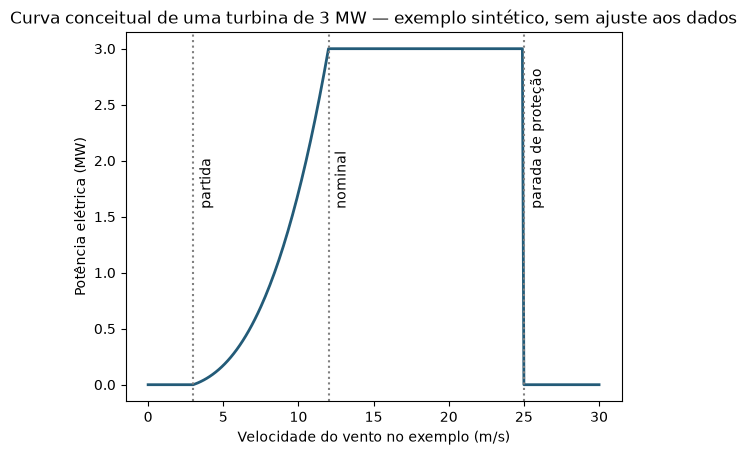

In [3]:
v = np.linspace(0,30,301)
pot = np.select([v<3,(v>=3)&(v<12),(v>=12)&(v<25)],
                [0,3*(v**3-3**3)/(12**3-3**3),3],default=0)
fig,ax=plt.subplots()
ax.plot(v,pot,color='#235b78',lw=2)
ax.set(xlabel='Velocidade do vento no exemplo (m/s)',ylabel='Potência elétrica (MW)',
       title='Curva conceitual de uma turbina de 3 MW — exemplo sintético, sem ajuste aos dados')
for x,label in [(3,'partida'),(12,'nominal'),(25,'parada de proteção')]:
    ax.axvline(x,ls=':',color='gray');ax.annotate(label,(x,1.5),xytext=(x+.4,1.6),rotation=90)
figura(fig,'curva_conceitual')

### Potência e energia não são a mesma grandeza

A curva anterior descreve potência: a taxa de produção de energia. Para saber quanta energia foi produzida durante um intervalo, precisamos considerar sua duração:

$$E=P\,\Delta t.$$

Uma potência média de **80 MW durante meia hora corresponde a 40 MWh**. Se a potência média for 120 MW na meia hora seguinte, a energia total da hora será $80\times0,5+120\times0,5=100$ MWh. Esse cálculo será necessário porque os dados energéticos utilizados têm intervalos de 30 minutos.

A fonte ONS apresenta grandezas com papéis diferentes. A **geração verificada** registra a potência efetivamente produzida. A **geração de referência** é uma estimativa operacional de geração potencial. A **geração não realizada apurada (GNR)** corresponde à potência associada à restrição segundo as regras da fonte. Utilizamos a GNR para calcular a energia restringida; não a substituímos automaticamente pela diferença entre referência e geração verificada.

O próximo exemplo mostra a conversão em dois intervalos. A fração restringida da hora é a soma da energia cortada dividida pela soma da energia de referência.

In [4]:
exemplo = pd.DataFrame({'patamar':['10:00–10:30','10:30–11:00'],
                        'referencia_MW':[100.,120.],'verificada_MW':[80.,90.],
                        'GNR_MW':[20.,30.],'duracao_h':[.5,.5]})
exemplo['corte_MWh']=exemplo.GNR_MW*exemplo.duracao_h
exemplo['referencia_MWh']=exemplo.referencia_MW*exemplo.duracao_h
tabela(exemplo,'exemplo_energia','Exemplo numérico sintético; valores escolhidos para ensinar unidades')
print('Fração energética da hora:',exemplo.corte_MWh.sum()/exemplo.referencia_MWh.sum())

**Exemplo numérico sintético; valores escolhidos para ensinar unidades**

,patamar,referencia_MW,verificada_MW,GNR_MW,duracao_h,corte_MWh,referencia_MWh
0,10:00–10:30,100.00000,80.00000,20.00000,0.50000,10.00000,50.00000
1,10:30–11:00,120.00000,90.00000,30.00000,0.50000,15.00000,60.00000


Fração energética da hora: 0.22727272727272727


### Motivos de restrição: ENE, CNF e REL

No exemplo, foram restringidos 25 MWh diante de uma referência de 110 MWh: cerca de **22,7% da energia de referência**. Esse tipo de restrição é denominado *constrained-off* ou, neste contexto, *curtailment*.

O ONS distingue três motivos utilizados no estudo:

| Código | Significado | Interpretação para este trabalho |
|---|---|---|
| **ENE** | Razão energética | A geração disponível não pode ser integralmente alocada à carga, considerando o balanço do sistema. |
| **CNF** | Confiabilidade elétrica | A geração precisa ser limitada para atender requisitos de segurança e confiabilidade da operação. |
| **REL** | Indisponibilidade externa | Uma instalação externa ao empreendimento está indisponível e limita o aproveitamento da geração. |

Vento elevado pode indicar maior recurso para geração, mas não determina sozinho a restrição. Demanda, geração de outras fontes e condições da rede também importam. Por isso, procuramos **informação útil para prever**, sem interpretar uma associação vento–corte como diagnóstico de uma linha elétrica ou prova de causalidade.

Uma região pode ter conjuntos sujeitos a motivos diferentes na mesma hora. Os três motivos não formam, portanto, classes mutuamente exclusivas. Construiremos um alvo separado para cada um. As definições e os campos de apuração seguem a documentação do ONS indicada nas referências [1].

<a id="secao-2"></a>

## 2. Perguntas científicas e hipóteses

Nossa pergunta central é: **quais padrões permitem prever as restrições de geração eólica e o que acrescentamos à previsão ao tratar adequadamente o tempo e incorporar meteorologia?**

Organizamos a investigação em quatro hipóteses:

**H1 — Os padrões de calendário contêm informação preditiva.** Certas horas, épocas do ano e regiões podem apresentar maior frequência de restrições ENE. Investigamos se modelos que representam essas regularidades conseguem distinguir horas com maior e menor risco, mesmo sem medir o vento. Também comparamos estratégias de calendário com diferentes formas de utilizar o histórico de dados.

**H2 — A meteorologia acrescenta informação ao calendário.** Duas observações podem ocorrer na mesma hora do dia e época do ano, mas ter vento e rajadas diferentes. Investigamos se essas medições permitem melhorar a previsão de ENE em relação a uma referência de calendário competitiva.

**H3 — A contribuição meteorológica depende do motivo de restrição.** ENE, CNF e REL representam condições operacionais distintas. Investigamos se acrescentar meteorologia produz o mesmo tipo de benefício para os três motivos.

**H4 — Atualizar o treinamento melhora a previsão.** A frequência e as condições das restrições podem mudar. Investigamos se incorporar dados mais recentes ao ajuste melhora o desempenho em comparação com manter um modelo treinado somente com um histórico mais antigo.

Há também uma pergunta complementar: **a meteorologia ajuda a prever a fração total de energia restringida?** Essa é uma tarefa de intensidade, não apenas de ocorrência. Ela será analisada separadamente para não confundir prever ENE acima de um limiar com prever a magnitude total dos cortes.

### Como as comparações respondem às hipóteses

Chamaremos de **modelo de calendário** aquele que recebe região, hora, dia da semana e mês, com as representações especificadas em cada experimento. O **modelo com meteorologia** recebe essas mesmas informações e acrescenta atributos do vento ou de outras medições atmosféricas.

Para estudar H2, os dois modelos devem ser avaliados **nas mesmas regiões e horas**, com o mesmo alvo e condições comparáveis de treinamento. Se o modelo meteorológico fosse avaliado apenas nas horas de sensores completos, enquanto o calendário fosse avaliado em todas as horas, a diferença poderia vir da seleção da amostra, e não da meteorologia.

Para H4, mantemos a estrutura do modelo e a população de avaliação, variando o histórico disponível ao treinamento. Isso separa duas perguntas: *acrescentar vento ajuda?* e *aprender com meses mais recentes ajuda?* Uma melhora após atualizar um modelo meteorológico não pode ser atribuída automaticamente ao vento.

A avaliação usará medidas de ordenação dos riscos, qualidade das probabilidades e erros de intensidade. Elas serão explicadas antes de interpretar os resultados. Não exigimos que um único sistema seja o melhor em todos os critérios: queremos entender suas vantagens e limitações.

In [5]:
plano = pd.DataFrame([
    ('H1 — Calendário', 'Distinguir riscos com hora, mês e região',
     'Frequência recente por região e hora, calendários logístico e combinado; score constante como referência básica'),
    ('H2 — Meteorologia', 'Medir a informação acrescentada por vento e rajada',
     'Calendário e calendário + meteorologia, nas mesmas observações'),
    ('H3 — Motivos', 'Examinar a contribuição meteorológica por ENE, CNF e REL',
     'Ganhos pareados por motivo; controle adicional em horas comuns'),
    ('H4 — Atualização', 'Avaliar a importância do histórico recente',
     'Mesmo modelo com treinamento congelado, atualizado e mensal'),
    ('Intensidade total', 'Estimar qual fração da energia será restringida',
     'Regressão direta e modelos de ocorrência + severidade')],
    columns=['Pergunta','Objetivo','Comparação'])
tabela_textual(plano, 'plano_analitico', 'Perguntas e comparações que orientam a análise')

**Perguntas e comparações que orientam a análise**

,Pergunta,Objetivo,Comparação
0,H1 — Calendário,"Distinguir riscos com hora, mês e região","Frequência recente por região e hora, calendários logístico e combinado; score constante como referência básica"
1,H2 — Meteorologia,Medir a informação acrescentada por vento e rajada,"Calendário e calendário + meteorologia, nas mesmas observações"
2,H3 — Motivos,"Examinar a contribuição meteorológica por ENE, CNF e REL",Ganhos pareados por motivo; controle adicional em horas comuns
3,H4 — Atualização,Avaliar a importância do histórico recente,"Mesmo modelo com treinamento congelado, atualizado e mensal"
4,Intensidade total,Estimar qual fração da energia será restringida,Regressão direta e modelos de ocorrência + severidade


Os testes são retrospectivos: usamos registros passados para simular previsões realizadas antes de cada hora-alvo. As divisões respeitam a ordem temporal, mas o conjunto de avaliações foi examinado ao longo da investigação; não se trata de uma confirmação prospectiva em dados inteiramente desconhecidos.

A evidência para uma hipótese vem de comparações definidas, não de escolher a maior métrica entre tabelas diferentes. Ao interpretar cada resultado, identificaremos o período, as observações incluídas e o que foi alterado entre os métodos. A preparação da base é o primeiro passo para tornar essas comparações possíveis.

<a id="secao-3"></a>

## 3. Gestão e organização dos dados

### Das medições a uma base interpretável

Um valor como “4,2” pouco informa sem sabermos o que foi medido, em qual unidade, onde e quando. No caso do vento, precisamos ao menos da estação, do instante e da unidade m/s. Para relacioná-lo a uma restrição, precisamos ainda encontrar o intervalo energético e o agrupamento geográfico correspondentes.

**A gestão dos dados preserva esse contexto.** Organizamos as fontes recebidas, os arquivos intermediários e os resultados de forma que seja possível seguir o caminho de uma medição até uma conclusão. O objetivo não é somente guardar o produto final, mas permitir a interpretação e a reconstrução das transformações.

O ciclo de vida dos dados apresentado na disciplina oferece uma estrutura para essa organização [2]. Abaixo mostramos sua aplicação ao estudo, incluindo as práticas realizadas e os cuidados necessários para manter o material utilizável.

### Aplicação do ciclo de vida DataONE

**Planejamento e coleta.** Definimos as perguntas, as fontes energéticas e meteorológicas, a unidade de observação e o período. Os arquivos recebidos são mantidos sem edição; as transformações produzem tabelas separadas. É importante distinguir a frequência das medições da frequência dos arquivos: dados semihorários podem estar reunidos em arquivos mensais, e medições horárias, em arquivos anuais.

**Garantia e controle de qualidade.** Regras para tipos, chaves e fusos ajudam a prevenir erros de integração — a *garantia da qualidade*, ou QA. Depois da coleta, verificamos ausências, duplicatas, valores inválidos e coerência energética — o *controle da qualidade*, ou QC. Como usamos dados de terceiros, nosso controle avalia os registros disponíveis; ele não substitui a calibração dos instrumentos.

**Descrição e preservação.** Dicionários explicam as variáveis, metadados identificam fontes e períodos, e resumos digitais dos arquivos permitem detectar alterações. Código e configurações acompanham os dados derivados. Backups e testes de restauração são necessários à preservação de longo prazo, além da cópia usada para a análise.

**Descoberta, integração e análise.** Os cadastros auxiliares ajudam a identificar os conjuntos e sua localização. A integração aproxima registros ONS e INMET no espaço e no tempo. A EDA, a engenharia de atributos e os modelos utilizam essa base para responder às perguntas.

**Compartilhamento.** Um conjunto reutilizável precisa incluir dados, descrições e instruções de execução. Disponibilizar um pacote não equivale a atribuir-lhe um DOI ou garantir arquivamento permanente; essas ações exigem um repositório e condições de compartilhamento apropriadas.

In [6]:
manifesto = json.loads((ROOT/'configuracoes/manifesto_dados.json').read_text())
arquivo = ROOT/'dados/base_regiao_hora.npz'
hash_atual = apoio.sha256(arquivo)
origem = next(x for x in manifesto if x['arquivo']=='dados/base_regiao_hora.npz')
assert hash_atual == origem['sha256']
tabela(pd.DataFrame([{'Arquivo':arquivo.name,'Tamanho (MiB)':arquivo.stat().st_size/2**20,
                     'SHA-256':hash_atual}]), 'hash_exemplo')
print('Arquivos de entrada verificados:', apoio.verificar_manifesto(ROOT))

**Identificação do arquivo de dados utilizado**

,Arquivo,Tamanho (MiB),SHA-256
0,base_regiao_hora.npz,14.48780,87e930d8340b7f7b32e31b5714ea18d8576bb6b78c041157060c5f2b1e80e4f9


Arquivos de entrada verificados: 26


Um **hash SHA-256** funciona como uma impressão digital dos bytes de um arquivo. Ao recalculá-lo, podemos verificar se estamos utilizando exatamente a cópia registrada. Isso é útil quando diferentes tabelas têm nomes semelhantes ou quando uma fonte publica atualizações.

Essa verificação diz respeito à **integridade**, não à veracidade física. Um arquivo pode permanecer inalterado e ainda conter falhas de sensor ou campos inconsistentes. Por isso, combinamos a identificação dos arquivos com as verificações de qualidade da seção 5.

In [7]:
metadados = {
 'nome': 'Restrições e meteorologia por região e hora',
 'periodo': {'inicio':str(base.time_local.min()), 'fim':str(base.time_local.max())},
 'chave': ['region', 'time_local'], 'fuso': 'America/Bahia',
 'fontes': ['ONS — restrições de geração', 'INMET — meteorologia'],
 'unidade_observacional': 'Agrupamento de conjuntos eólicos durante uma hora',
 'variavel_exemplo': {
     'campo':'reference_mwh', 'unidade':'MWh',
     'significado':'Energia de referência da região no intervalo',
     'papel':'Denominador do alvo; não é uma entrada contemporânea do preditor',
     'ausencia':'Informação insuficiente; não equivale a energia zero'}
}
print(json.dumps(metadados, indent=2, ensure_ascii=False))
(OUT/'recibos/metadados_dataset.json').write_text(json.dumps(metadados,indent=2,ensure_ascii=False));

{
  "nome": "Restrições e meteorologia por região e hora",
  "periodo": {
    "inicio": "2022-01-01 00:00:00-03:00",
    "fim": "2026-09-30 23:00:00-03:00"
  },
  "chave": [
    "region",
    "time_local"
  ],
  "fuso": "America/Bahia",
  "fontes": [
    "ONS — restrições de geração",
    "INMET — meteorologia"
  ],
  "unidade_observacional": "Agrupamento de conjuntos eólicos durante uma hora",
  "variavel_exemplo": {
    "campo": "reference_mwh",
    "unidade": "MWh",
    "significado": "Energia de referência da região no intervalo",
    "papel": "Denominador do alvo; não é uma entrada contemporânea do preditor",
    "ausencia": "Informação insuficiente; não equivale a energia zero"
  }
}


### Plano de organização e preservação

Cada tipo de objeto precisa de uma forma de armazenamento e de uma descrição compatíveis com seu uso:

| Objeto | Organização | Descrição necessária | Cuidado principal |
|---|---|---|---|
| Registros ONS e INMET recebidos | Arquivos brutos separados por fonte e período | Origem, aquisição, campos, unidades e códigos de ausência | Não editar os originais |
| Cadastros de estações e conjuntos | Tabelas de identificação e localização | Chaves, coordenadas, composição dos conjuntos e período de referência | Não confundir cadastro atual com configuração histórica certificada |
| Base região × hora | Tabela integrada com chave composta | Regras de agregação, qualidade, alvos e atributos | Distinguir zero, ausência e rótulo desconhecido |
| Configurações e previsões | Arquivos próprios de cada procedimento | Treinamento, atributos, parâmetros, datas e alvo | Manter condições comparáveis nos contrastes |
| Código, tabelas e figuras | Código executável e resultados associados | Dependências, fórmulas, critérios e instruções | Permitir reproduzir a análise |

Os arquivos de análise foram armazenados em Parquet, CSV e JSON. Para facilitar a execução sem um leitor Parquet, o pacote também representa as tabelas numéricas em arquivos NumPy comprimidos (`.npz`), acompanhados do esquema de colunas e fusos. A função de leitura restitui as tabelas; a representação de armazenamento não modifica o significado das observações.

A atribuição das fontes deve acompanhar os dados compartilhados. Uma licença da base integrada não pode ser presumida a partir do fato de os dados serem públicos: é necessário considerar as condições de cada fonte. A documentação técnica reúne identificação dos arquivos e instruções de reprodução.

### Tabelas relacionais e catálogo documental

A base analítica tem estrutura tabular: cada linha é identificada por região e hora. Isso permite operações relacionais como filtrar anos, contar observações e reunir tabelas por uma chave. A consulta SQL abaixo conta a grade e as horas energeticamente válidas de cada ano, usando SQLite em memória.

Os **metadados** têm outra finalidade. Um documento pode descrever uma estação, sua cobertura e seu período, sem representar uma hora de geração. Para esse catálogo usamos estrutura JSON e uma consulta documental. O exemplo pode ser executado com TinyDB; quando esse pacote não está instalado, o mesmo filtro de leitura é aplicado diretamente aos documentos JSON. A saída informa qual caminho foi utilizado.

Parquet e NumPy são formatos de arquivo, SQLite é um banco relacional e TinyDB é um banco documental. Essas escolhas não tornam o processamento distribuído: o estudo foi realizado em uma única máquina.

Além do catálogo de metadados, uma base documental também pode representar as próprias observações integradas. Depois de definir a base região × hora, mostraremos como armazenar e consultar conjuntamente seus campos energéticos e meteorológicos.


In [8]:
import sqlite3
with sqlite3.connect(':memory:') as con:
    base[['region','year','ons_eligible']].to_sql('horas',con,index=False)
    consulta = pd.read_sql_query('''SELECT year AS ano, COUNT(*) AS horas_grade,
        SUM(ons_eligible) AS horas_elegiveis FROM horas GROUP BY year ORDER BY year''',con)
tabela(consulta,'consulta_relacional','Consulta relacional real sobre a grade compacta')

**Consulta relacional real sobre a grade compacta**

,ano,horas_grade,horas_elegiveis
0,2022,70080,56938
1,2023,70080,66711
2,2024,70272,69822
3,2025,70080,69960
4,2026,52416,52397


In [9]:
catalogo = json.loads((ROOT/'configuracoes/catalogo_tinydb.json').read_text())
registros = list(catalogo['station_years'].values())

try:
    from tinydb import TinyDB, Query
    from tinydb.storages import MemoryStorage
except ImportError:
    # A consulta equivalente sobre os documentos JSON mantém a execução portátil.
    # Ela não substitui a demonstração do motor TinyDB quando ele está instalado.
    documentos = [r for r in registros if r['year']==2024 and r['coverage_vento_ms']>=.9]
    motor_catalogo = 'Consulta aos documentos JSON (TinyDB não instalado)'
else:
    db = TinyDB(storage=MemoryStorage)
    db.table('station_years').insert_multiple(registros)
    q = Query()
    documentos = db.table('station_years').search((q.year==2024)&(q.coverage_vento_ms>=.9))
    db.close()
    motor_catalogo = 'TinyDB — consulta documental NoSQL'
print(motor_catalogo)
tabela(pd.DataFrame(documentos)[['station','year','rows','coverage_vento_ms']].head(12),
       'consulta_nosql', f'Primeiros 12 de {len(documentos)} documentos de 2024 com cobertura de vento ≥90%')

Consulta aos documentos JSON (TinyDB não instalado)


**Primeiros 12 de 16 documentos de 2024 com cobertura de vento ≥90%**

,Estação,Ano,Registros,Cobertura de vento
0,A401,2024,8784,0.99954
1,A402,2024,8784,0.95663
2,A404,2024,8784,0.96653
3,A405,2024,8784,0.99863
4,A410,2024,8784,0.99989
5,A414,2024,8784,1.00000
6,A431,2024,8784,0.99829
7,A433,2024,8784,0.99932
8,A434,2024,8784,0.99989
9,A437,2024,8784,1.00000


A primeira consulta conta **observações região × hora**; a segunda seleciona **documentos estação × ano**. Os números não devem coincidir, porque as unidades descritas são diferentes.

Esse contraste ilustra a função do modelo de dados. A tabela de horas serve à análise energética; o catálogo ajuda a localizar sensores com cobertura adequada. Uma estação com boa cobertura geral ainda pode apresentar uma lacuna justamente em um mês importante. A seleção por metadados é, portanto, um primeiro filtro, seguido da inspeção temporal das medições.

In [10]:
inventario=pd.read_csv(ROOT/'dados/inventario_verificado.csv')
inventario['fonte']=inventario.fonte.replace({'INMET V1':'INMET — atributos iniciais','INMET V2':'INMET — atributos ampliados','Base V2':'Base integrada antes da seleção de campos'})
inventario['MiB']=inventario['bytes']/2**20
tabela(inventario[['fonte','linhas','colunas','MiB']],'inventario_volume')
apenas_vento=ler_tabela(ROOT/'dados/meteorologia.npz',columns=['station','time_utc','vento_ms'])
print('Leitura seletiva:',len(apenas_vento),'linhas e',len(apenas_vento.columns),'colunas.')
del apenas_vento

**Dimensão das tabelas de origem**

,fonte,linhas,colunas,MiB
0,ONS agregado,3642912,12,42.17490
1,INMET — atributos iniciais,1871136,8,9.92355
2,INMET — atributos ampliados,1871136,14,18.87609
3,Base integrada antes da seleção de campos,332928,177,77.55820


Leitura seletiva: 1871136 linhas e 3 colunas.


### Escala do acervo e escolhas de processamento

O inventário registra milhões de observações intermediárias, enquanto a base integrada tem centenas de milhares de linhas. **Volume**, **variedade** de fontes e **veracidade** dos registros são desafios concretos deste estudo. A dimensão temporal também exige atenção: a frequência de uma medição não garante que ela esteja imediatamente disponível para previsão. O **valor** dos dados está nas análises que sua integração permite realizar.

Apesar desse volume, não foi necessário um sistema distribuído. Tabelas tipadas, armazenamento comprimido, seleção de colunas e operações vetorizadas tornaram o processamento viável localmente. A escolha da infraestrutura deve atender à escala efetiva do problema, sem acrescentar complexidade apenas porque a disciplina aborda Big Data.

<a id="secao-4"></a>

## 4. Fontes de dados e significado das variáveis

Utilizamos fontes complementares, não intercambiáveis:

**ONS — restrições de geração eólica.** Fornece registros por conjunto e intervalo de 30 minutos, incluindo geração de referência, geração verificada, geração não realizada e motivos de restrição. É a fonte dos alvos energéticos.

**ONS — detalhamento das restrições.** Apresenta informação cadastral e de usinas que auxilia a identificar a composição dos conjuntos. Não somamos o detalhamento ao agregado, pois isso poderia contar duas vezes o mesmo fenômeno.

**INMET — estações meteorológicas.** Fornece registros horários de vento, rajada, temperatura, umidade e outras grandezas. A velocidade e a rajada têm janelas de medição próprias; aparecerem na mesma linha horária não significa que sejam a mesma média física.

**Cadastros geográficos.** A localização das estações e dos conjuntos permite construir a associação espacial. A composição cadastral também ajuda a acompanhar mudanças de identificadores.

As próximas tabelas mostram dimensões, exemplos e tipos. O recorte ONS de novembro de 2025 é um mês completo usado para demonstrar a integração. As estatísticas do acervo e a base de todo o período têm abrangência maior. Indicaremos essa diferença para que uma contagem de exemplo não seja interpretada como o tamanho total da pesquisa.

In [11]:
weather=ler_tabela(ROOT/'dados/meteorologia.npz')
ons=ler_tabela(ROOT/'dados/ons_novembro2025.npz')
detail=ler_tabela(ROOT/'dados/detail_duplicatas.npz')
cadastro=pd.read_csv(ROOT/'dados/cadastro_estacao_ano.csv')
geo=pd.read_csv(ROOT/'dados/mapeamento_conjuntos.csv')
fontes=pd.DataFrame([
 {'fonte':'INMET — meteorologia','registros':len(weather),'entidades':weather.station.nunique(),
  'primeiro':str(weather.time_utc.min()),'último':str(weather.time_utc.max()),'unidade':'estação × hora UTC'},
 {'fonte':'ONS — novembro de 2025','registros':len(ons),'entidades':ons.id_ons.nunique(),
  'primeiro':str(ons.time_local.min()),'último':str(ons.time_local.max()),'unidade':'conjunto × meia hora; novembro/2025'},
 {'fonte':'Base integrada','registros':len(base),'entidades':base.region.nunique(),
  'primeiro':str(base.time_local.min()),'último':str(base.time_local.max()),'unidade':'região × hora local'}])
tabela(fontes,'caracterizacao_fontes')
tabela(ons.head(4)[['id_ons','time_local','val_geracao','val_geracaoreferencia','cod_razaorestricao']],
       'linhas_ons','Exemplos reais ONS: potências em MW; motivo nulo exige interpretação conjunta')
tabela(weather.head(4)[['station','time_utc','vento_ms','rajada_ms','temperatura_c']],
       'linhas_inmet','Exemplos reais INMET: vento/rajada m/s e temperatura °C')
tabela(detail.head(4)[['ceg','id_ons_conjuntousina','din_instante','val_geracaoverificada']],
       'linhas_detail','Exemplos Detail: CEG identifica usina; conjunto é outro nível')
inv_detail=pd.read_csv(ROOT/'dados/inventario_detail_verificado.csv')
geo_prov=json.loads((ROOT/'configuracoes/geografia_proveniencia.json').read_text())
tabela(pd.DataFrame([{'fonte':'Detail BA importado','arquivos':len(inv_detail),
 'linhas_presentes_antes_deduplicacao':inv_detail.linhas.sum(),'colunas':str(sorted(int(v) for v in inv_detail.colunas.unique())),
 'periodo_inicial':inv_detail.periodo.min(),'periodo_final':inv_detail.periodo.max(),
 'MiB':inv_detail.bytes.sum()/2**20}]),'inventario_detail',
 'Inventário de arquivos do detalhamento; contagens documentadas na aquisição')
tabela(pd.DataFrame([{'pares_conjunto_mes':len(geo),'conjuntos_distintos':geo.id_ons.nunique(),
 'CEGs_correspondidos_historicamente':geo_prov['n_matched_plants'],
 'snapshot_SIGA':str(geo_prov['siga_snapshot']),'licenca_SIGA':geo_prov['license']}]),
 'cadastro_geografico','Conjuntos, correspondências cadastrais e data do cadastro geográfico')

**Fontes: unidades, frequência temporal e campos principais**

,fonte,registros,entidades,primeiro,último,unidade
0,INMET — meteorologia,1871136,47,2022-01-01 00:00:00+00:00,2026-09-30 23:00:00+00:00,estação × hora UTC
1,ONS — novembro de 2025,64800,45,2025-11-01 00:00:00-03:00,2025-11-30 23:30:00-03:00,conjunto × meia hora; novembro/2025
2,Base integrada,332928,8,2022-01-01 00:00:00-03:00,2026-09-30 23:00:00-03:00,região × hora local


**Exemplos reais ONS: potências em MW; motivo nulo exige interpretação conjunta**

,id_ons,Hora (Bahia),val_geracao,val_geracaoreferencia,cod_razaorestricao
0,CJU_BAARA,2025-11-01 00:00:00-03:00,11.27400,82.18400,REL
1,CJU_BAARA,2025-11-01 00:30:00-03:00,46.73100,95.84000,REL
2,CJU_BAARA,2025-11-01 01:00:00-03:00,91.64200,78.04500,REL
3,CJU_BAARA,2025-11-01 01:30:00-03:00,91.77500,55.40700,NaN


**Exemplos reais INMET: vento/rajada m/s e temperatura °C**

,Estação,Hora (UTC),Vento (m/s),Rajada (m/s),Temperatura (°C)
0,A401,2022-01-01 00:00:00+00:00,1.60000,8.70000,26.00000
1,A401,2022-01-01 01:00:00+00:00,2.00000,7.60000,26.10000
2,A401,2022-01-01 02:00:00+00:00,0.90000,5.70000,25.90000
3,A401,2022-01-01 03:00:00+00:00,1.10000,3.80000,25.50000


... (2 outputs left out)

**Detalhamento por usina: dimensão e período dos arquivos catalogados**

,fonte,arquivos,linhas_presentes_antes_deduplicacao,colunas,periodo_inicial,periodo_final,MiB
0,Detail BA importado,57,25518676,[18],2022_01,2026_09,192.26378


**Identificadores e vínculos geográficos disponíveis**

,pares_conjunto_mes,conjuntos_distintos,CEGs_correspondidos_historicamente,snapshot_SIGA,licenca_SIGA
0,2578,68,370,['2026-10-01'],ODbL; licença integrada não presumida


### A unidade muda entre as fontes

O inventário registra **3.642.912 linhas** no intermediário ONS agregado BA. A tabela meteorológica contém **1.871.136 observações estação × hora**. Já a base de modelagem possui **332.928 posições região × hora**. Esses números descrevem níveis de agregação diferentes; a redução de linhas não significa, por si só, descarte de observações inválidas.

Também precisamos separar as entidades. Uma **usina física** pode ter um identificador CEG; um **conjunto ONS** pode reunir várias usinas; uma **região do estudo** reúne conjuntos; uma **estação INMET** mede a atmosfera em uma localização. Essa distinção define quais chaves podem ser usadas nas junções e o alcance espacial das conclusões.

In [12]:
tipos=pd.DataFrame([
 ('region','nominal / identificador','código de região construído; não quantidade','—'),
 ('station / CEG','nominal / identificador','números/letras identificam entidades; média não faz sentido','—'),
 ('units / sp_count','quantitativo discreto','contagem de conjuntos / sensores válidos','unidades'),
 ('val_geracao','quantitativo contínuo','potência média do patamar','MW'),
 ('reference_mwh','quantitativo contínuo','energia de referência da hora','MWh'),
 ('vento_ms / rajada_ms','quantitativo contínuo','janelas observacionais distintas','m/s'),
 ('direction_deg','quantitativo circular','0° e 360° representam a mesma direção','grau'),
 ('hour / month','calendário discreto cíclico','distância linear não descreve a virada do ciclo','hora/mês'),
 ('y_ENE_02','binário nominal','evento acima de limiar; NaN indica desconhecido','0/1'),
 ('faixa_vento','qualitativo ordinal derivado','faixas ordenadas, criadas apenas para diagnóstico','—')],
 columns=['campo','tipo estatístico','interpretação','unidade'])
tabela(tipos,'tipos_atributos')
tabela(weather.dtypes.astype(str).rename('dtype').to_frame(),'tipos_computacionais')

,campo,tipo estatístico,interpretação,unidade
0,Região,nominal / identificador,código de região construído; não quantidade,—
1,station / CEG,nominal / identificador,números/letras identificam entidades; média não faz sentido,—
2,units / sp_count,quantitativo discreto,contagem de conjuntos / sensores válidos,unidades
3,val_geracao,quantitativo contínuo,potência média do patamar,MW
4,Energia de referência (MWh),quantitativo contínuo,energia de referência da hora,MWh
5,vento_ms / rajada_ms,quantitativo contínuo,janelas observacionais distintas,m/s
6,Direção (graus),quantitativo circular,0° e 360° representam a mesma direção,grau
7,hour / month,calendário discreto cíclico,distância linear não descreve a virada do ciclo,hora/mês
8,y_ENE_02,binário nominal,evento acima de limiar; NaN indica desconhecido,0/1
9,faixa_vento,qualitativo ordinal derivado,"faixas ordenadas, criadas apenas para diagnóstico",—


**Tipos de armazenamento das medições meteorológicas**

,dtype
Hora (UTC),"datetime64[ns, UTC]"
Estação,str
Vento (m/s),float64
Rajada (m/s),float64
Temperatura (°C),float64
Umidade (%),float64
Radiação (kJ/m²),float64
Precipitação (mm),float64
Direção (graus),float64
Pressão (hPa),float64


Um tipo computacional, como `float64`, informa como o valor está armazenado, não o que ele significa. A velocidade do vento é uma medida contínua com unidade. Um código de região é uma categoria nominal: calcular sua média não teria interpretação. A hora possui ordem e também uma estrutura circular, pois 23h e 0h são vizinhas.

Os alvos binários podem estar armazenados como números reais para acomodar valores ausentes. Nesse caso, `NaN` significa que o rótulo é desconhecido, não uma terceira classe física. Essas diferenças orientam tanto a estatística descritiva quanto as transformações exigidas pelos modelos.

<a id="secao-5"></a>

## 5. Qualidade dos dados e tratamento de registros

Antes de procurar padrões, precisamos verificar se eles podem ser consequência de falhas nos dados. Uma longa sequência sem vento pode indicar ausência de recurso, mas também pode resultar de uma estação sem comunicação. Uma linha repetida pode duplicar energia na soma. Um código de ausência interpretado como número altera médias e correlações.

A limpeza segue três princípios: **preservar o registro recebido, aplicar regras explícitas e contar seu efeito**. Não substituímos tudo que parece incomum por um valor mais conveniente. Identificamos separadamente ausência, erro de formato, inconsistência e valor extremo plausível.

Mais adiante utilizaremos uma **estação âncora**: uma estação INMET de referência geográfica para agrupar conjuntos eólicos em uma região. Isso não impede que várias estações contribuam posteriormente com medições para essa região.

Começamos com um recorte textual real do INMET. O código mantém a coluna recebida ao lado do valor convertido, permitindo observar como separadores decimais e códigos de ausência são tratados. Essa demonstração usa uma amostra; os padrões de cobertura serão calculados sobre as séries meteorológicas completas incluídas na base.

In [13]:
textual=ler_tabela(ROOT/'dados/inmet_textual.npz')
colvento='VENTO, VELOCIDADE HORARIA (m/s)'
def numero_inmet(s):
    numerico=pd.to_numeric(s.astype('string').str.strip().str.replace(',','.',regex=False),errors='coerce')
    return numerico.astype(float).replace([-9999,9999],np.nan)
vento_limpo=numero_inmet(textual[colvento])
vento_limpo=vento_limpo.where(vento_limpo.ge(0))
antes_depois=pd.DataFrame({'linha_original':textual.linha_origem,
                          'texto_original':textual[colvento],'vento_ms':vento_limpo})
exibir=pd.concat([antes_depois.head(6),antes_depois[antes_depois.vento_ms.isna()].head(6)]).drop_duplicates()
tabela(exibir,'parsing_inmet','Strings reais: vírgula decimal, nulos textuais e resultado numérico')
tabela(pd.DataFrame({'linhas':[len(textual)],'ausentes_apos_parsing':[vento_limpo.isna().sum()],
                    'sentinelas_numericas':[pd.to_numeric(textual[colvento],errors='coerce').isin([-9999,9999]).sum()]}),
       'contagem_parsing','Diagnóstico somente deste recorte intencional')

**Strings reais: vírgula decimal, nulos textuais e resultado numérico**

,linha_original,texto_original,Vento (m/s)
0,0,"3,7",3.70000
1,1,"2,8",2.80000
2,2,"1,9",1.90000
3,3,"2,8",2.80000
4,4,"2,4",2.40000
5,5,"3,7",3.70000
744,7072,,NaN
745,7073,,NaN
746,7074,,NaN
747,7075,,NaN


**Diagnóstico somente deste recorte intencional**

,linhas,ausentes_apos_parsing,sentinelas_numericas
0,752,8,0


A conversão produziu números nas linhas interpretáveis e valores ausentes nas demais. `errors='coerce'` evita uma interrupção por texto inválido, mas não deve esconder a causa: por isso mostramos o conteúdo antes e depois.

**Zero é um valor possível de vento; ausência significa que não temos uma medição utilizável.** Substituir ausência por zero criaria calmarias artificiais. Tampouco é adequado completar automaticamente longas falhas por interpolação: uma linha contínua visualmente agradável pode sugerir uma observação que nunca existiu. O próximo passo é medir onde e por quanto tempo faltam dados.

In [14]:
variaveis=['vento_ms','rajada_ms','temperatura_c','umidade_pct','direction_deg','pressure_hpa','radiacao_kjm2','precipitacao_mm']
weather['ano']=weather.time_utc.dt.year
ausencias=weather[variaveis].isna().mean().mul(100).rename('ausentes_%')
tabela(ausencias,'ausencias_variavel','Medições INMET, 2022–set/2026: denominador = registros presentes')
por_ano=weather.groupby('ano')[variaveis].agg(lambda x:x.isna().mean()*100)
tabela(por_ano,'ausencias_ano','Percentual ausente entre registros presentes, separado por ano UTC')
qualidade=weather.groupby(['station','ano']).agg(registros=('vento_ms','size'),vento_valido=('vento_ms','count'),rajada_valida=('rajada_ms','count')).reset_index()
def horas_esperadas(ano):
    fim=f'{ano+1}-01-01' if ano<2026 else '2026-10-01'
    return int((pd.Timestamp(fim)-pd.Timestamp(f'{ano}-01-01')).total_seconds()/3600)
qualidade['esperadas']=qualidade.ano.map(horas_esperadas)
qualidade['sem_registro']=qualidade.esperadas-qualidade.registros
qualidade['cobertura_vento']=qualidade.vento_valido/qualidade.esperadas
qualidade['cobertura_rajada']=qualidade.rajada_valida/qualidade.esperadas
tabela(qualidade[qualidade.station.isin(base.region.unique()) & qualidade.ano.eq(2025)],
       'qualidade_ancoras','Âncoras em 2025: denominador = horas esperadas do ano UTC')

**Ausências nas variáveis meteorológicas — 2022 a setembro de 2026**

,ausentes_%
Vento (m/s),43.08516
Rajada (m/s),43.21065
Temperatura (°C),38.84186
Umidade (%),46.63028
Direção (graus),44.24628
Pressão (hPa),39.20704
Radiação (kJ/m²),65.53153
Precipitação (mm),47.71209


**Percentual ausente entre registros presentes, separado por ano UTC**

,Vento (m/s),Rajada (m/s),Temperatura (°C),Umidade (%),Direção (graus),Pressão (hPa),Radiação (kJ/m²),Precipitação (mm)
ano,,,,,,,,
2022,42.02774,42.11758,39.11579,46.39741,44.19347,39.12051,67.32480,48.04298
2023,25.82978,25.92998,23.56443,28.80974,29.00964,23.56342,58.23135,32.91629
2024,35.78780,36.08986,29.11278,39.11303,35.89987,29.18564,58.31714,38.23467
2025,53.23846,53.35261,47.69888,57.96854,53.24176,47.88635,70.26788,55.99366
2026,64.56259,64.54397,60.86764,66.38652,64.56541,62.90317,76.56768,69.43753


**Âncoras em 2025: denominador = horas esperadas do ano UTC**

,Estação,ano,registros,vento_valido,rajada_valida,esperadas,sem_registro,cobertura_vento,cobertura_rajada
33,A408,2025,8760,8752,8752,8760,0,0.99909,0.99909
76,A423,2025,8760,191,181,8760,0,0.02180,0.02066
91,A426,2025,8760,8743,8743,8760,0,0.99806,0.99806
106,A429,2025,8760,8729,8729,8760,0,0.99646,0.99646
111,A430,2025,8760,0,0,8760,0,0.00000,0.00000
126,A433,2025,8760,7366,7340,8760,0,0.84087,0.83790
151,A439,2025,8760,6083,6083,8760,0,0.69441,0.69441
222,A458,2025,8760,8278,8258,8760,0,0.94498,0.94269


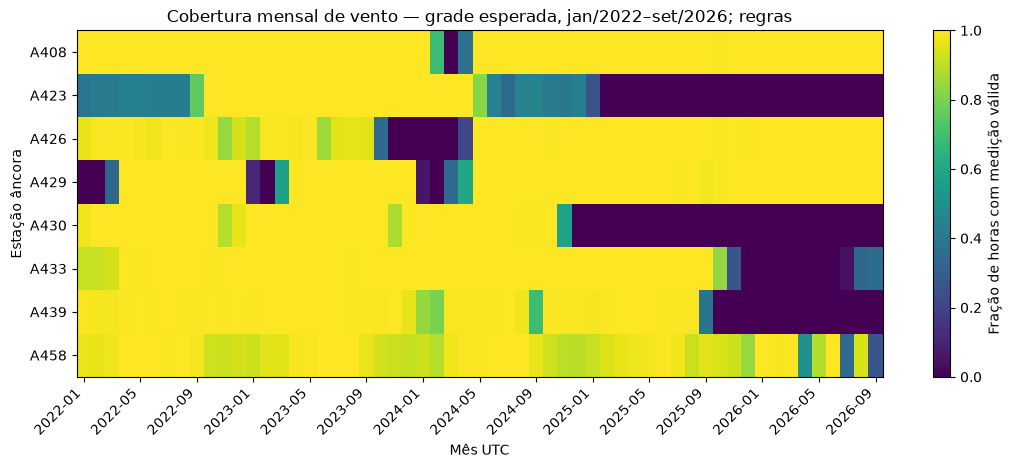

**Maiores sequências sem vento válido; incluem ausência de registro e exclusões geográficas**

,estacao,inicio_UTC,fim_UTC,Horas
941,A430,2024-11-18 10:00:00+00:00,2026-09-30 23:00:00+00:00,16358
576,A423,2025-01-23 20:00:00+00:00,2026-09-30 23:00:00+00:00,14764
1318,A439,2025-09-12 15:00:00+00:00,2026-09-30 23:00:00+00:00,9201
1079,A433,2025-11-17 22:00:00+00:00,2026-07-28 12:00:00+00:00,6063
828,A426,2023-10-26 14:00:00+00:00,2024-03-23 13:00:00+00:00,3576
847,A429,2022-01-15 17:00:00+00:00,2022-03-21 11:00:00+00:00,1555
850,A429,2024-01-02 18:00:00+00:00,2024-03-07 10:00:00+00:00,1553
0,A408,2024-02-20 21:00:00+00:00,2024-04-19 15:00:00+00:00,1411
849,A429,2023-01-18 16:00:00+00:00,2023-03-14 12:00:00+00:00,1317
829,A426,2024-03-23 15:00:00+00:00,2024-04-24 13:00:00+00:00,767


In [15]:
ancoras=sorted(base.region.unique())
grade_utc=pd.date_range('2022-01-01','2026-10-01',inclusive='left',freq='h',tz='UTC')
mat_vento=weather.pivot(index='time_utc',columns='station',values='vento_ms').reindex(grade_utc)
mensal=mat_vento[ancoras].notna().resample('MS').mean().T
fig,ax=plt.subplots(figsize=(13,4.5))
im=ax.imshow(mensal,aspect='auto',vmin=0,vmax=1,cmap='viridis')
ax.set_yticks(range(len(ancoras)),ancoras)
ticks=np.arange(0,len(mensal.columns),4)
ax.set_xticks(ticks,[mensal.columns[i].strftime('%Y-%m') for i in ticks],rotation=45,ha='right')
ax.set(xlabel='Mês UTC',ylabel='Estação âncora',title='Cobertura mensal de vento — grade esperada, jan/2022–set/2026; regras V2')
fig.colorbar(im,ax=ax,label='Fração de horas com medição válida')
figura(fig,'cobertura_mensal')
lacunas=[]
for station in ancoras:
    ausente=mat_vento[station].isna()
    grupos=ausente.ne(ausente.shift()).cumsum()
    for _,g in ausente[ausente].groupby(grupos[ausente]):
        lacunas.append({'estacao':station,'inicio_UTC':g.index.min(),'fim_UTC':g.index.max(),'horas':len(g)})
tabela(pd.DataFrame(lacunas).sort_values('horas',ascending=False).head(12),'maiores_lacunas',
       'Maiores sequências sem vento válido; incluem ausência de registro e exclusões geográficas')

As lacunas se concentram em determinadas estações e períodos. Por exemplo, A430 apresenta posições horárias em 2025, mas sem vento válido naquele ano. **Ter uma linha com data não equivale a ter a variável medida.** Esse é o motivo para calcular cobertura por variável, e não apenas contar registros.

Falhas prolongadas também mostram por que uma porcentagem única para toda a base é insuficiente. Duas estações podem ter a mesma cobertura total, mas uma perder horas dispersas e outra perder um ano inteiro. Para prever períodos recentes, essas situações têm consequências diferentes.

In [16]:
chave_detail=['ceg','din_instante']
antes=len(detail)
detail_unico=detail.drop_duplicates()
diagnostico=pd.DataFrame([{'recorte':'Detail intencional, com repetições reais','linhas':antes,
 'repeticoes_integrais':int(detail.duplicated().sum()),'duplicatas_chave_antes':int(detail.duplicated(chave_detail).sum()),
 'conflitos_apos_remover_identicas':int(detail_unico.duplicated(chave_detail).sum()),
 'linhas_apos':len(detail_unico)}])
assert not detail_unico.duplicated(chave_detail).any()
assert not ons.duplicated(['id_ons','time_local']).any()
assert not weather.duplicated(['station','time_utc']).any()
tabela(diagnostico,'duplicatas_detail')
tabela(detail[detail.duplicated(keep=False)].head(6)[['ceg','id_ons_conjuntousina','din_instante','val_geracaoverificada']],
       'duplicatas_exemplos','Repetições integrais reais preservadas na amostra original')

,recorte,linhas,repeticoes_integrais,duplicatas_chave_antes,conflitos_apos_remover_identicas,linhas_apos
0,"Detail intencional, com repetições reais",530,240,240,0,290


**Repetições integrais reais preservadas na amostra original**

,ceg,id_ons_conjuntousina,din_instante,val_geracaoverificada
50,EOL.CV.BA.049393-7.01,CJU_BASAR,2024-09-04 00:00:00,4.62700
51,EOL.CV.BA.049393-7.01,CJU_BASAR,2024-09-04 00:00:00,4.62700
52,EOL.CV.BA.049397-0.01,CJU_BASAR,2024-09-04 00:00:00,18.90800
53,EOL.CV.BA.049397-0.01,CJU_BASAR,2024-09-04 00:00:00,18.90800
54,EOL.CV.BA.049393-7.01,CJU_BASAR,2024-09-04 00:30:00,10.46600
55,EOL.CV.BA.049393-7.01,CJU_BASAR,2024-09-04 00:30:00,10.46600


A chave deve refletir a entidade observada. Duas usinas na mesma meia hora são dois registros legítimos; duas cópias idênticas da mesma usina no mesmo instante são uma duplicação. Removemos apenas repetições integrais. Se as chaves coincidirem e os valores divergirem, será necessário investigar o conflito, não escolher uma linha arbitrariamente.

O exemplo exibido foi selecionado por conter duplicatas e serve para demonstrar a regra. Sua proporção de repetições não estima a proporção de duplicatas do acervo inteiro. Após a remoção, verificamos se a chave continua única e se não restaram conflitos.

In [17]:
mins=ons[[f'num_minutos_{r.lower()}' for r in motivos]]
tem_limite=ons.val_geracaolimitada.notna()
qc=pd.Series({
 'linhas_no_mes':len(ons),'chaves_repetidas':ons.duplicated(['id_ons','time_local']).sum(),
 'referencia_ausente':ons.val_geracaoreferencia.isna().sum(),
 'potencia_negativa':ons[['val_geracao','val_geracaoreferencia']].lt(0).any(axis=1).sum(),
 'minutos_fora_0_30':(mins.lt(0)|mins.gt(30)).any(axis=1).sum(),
 'motivos_multiplos':mins.gt(0).sum(axis=1).gt(1).sum(),
 'limite_sem_motivo':(tem_limite & ons.cod_razaorestricao.isna()).sum(),
 'referencia_menor_verificada':ons.val_geracaoreferencia.lt(ons.val_geracao).sum(),
 'diferenca_GNR_maior_0_002_MW':(((ons.val_geracaoreferencia-ons.val_geracao).clip(lower=0)-ons.val_geracaonaorealizadaapurada).abs().gt(.002)&tem_limite).sum()
},name='quantidade')
tabela(qc,'qc_ons','QC calculado: agregado BA, novembro/2025')

**QC calculado: agregado BA, novembro/2025**

,quantidade
linhas_no_mes,64800
chaves_repetidas,0
referencia_ausente,0
potencia_negativa,0
minutos_fora_0_30,0
motivos_multiplos,625
limite_sem_motivo,0
referencia_menor_verificada,19435
diferenca_GNR_maior_0_002_MW,0


No mês examinado, **625 de 64.800 intervalos** possuem mais de um motivo ativo. Isso antecipa um problema real de construção dos rótulos: nem toda energia restringida pode ser atribuída sem ambiguidade a um único motivo.

Há também **19.435 intervalos em que a referência é inferior à geração verificada**. Não transformamos essa diferença em corte negativo, nem forçamos referência menos geração a coincidir com a GNR. Os campos têm definições operacionais próprias. Já minutos fora do intervalo permitido ou ausência de campos indispensáveis tornam o registro inadequado à soma energética.

A regra de qualidade também sinaliza potência superior a 1,5 vez a capacidade cadastrada positiva. Esse limite é uma regra de triagem, dependente da qualidade do cadastro. Na agregação, uma hora regional incompleta não é tratada como um total completo: perderá elegibilidade energética.

,Observações,Q1_ms,Q3_ms,IQR_ms,cerca_inferior_ms,cerca_superior_ms,fora_das_cercas
0,779802,0.70000,2.90000,2.20000,-2.60000,6.20000,7550


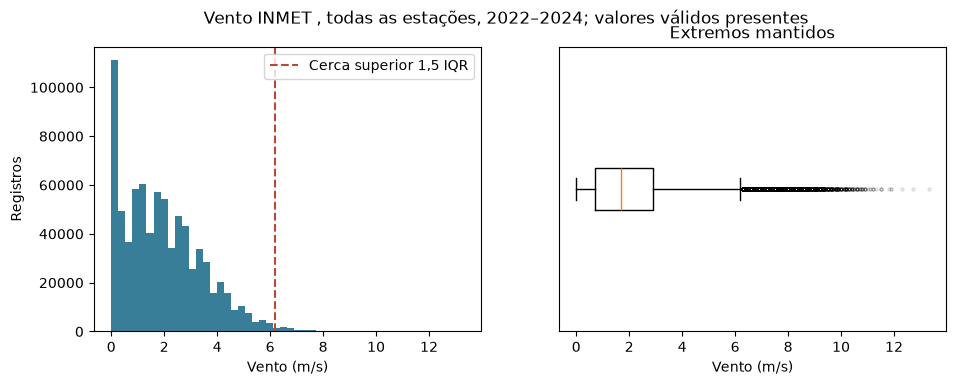

In [18]:
vento_treino=weather.loc[weather.ano.le(2024),'vento_ms'].dropna()
q1,q3=vento_treino.quantile([.25,.75]);iqr=q3-q1
lo,hi=q1-1.5*iqr,q3+1.5*iqr
tabela(pd.DataFrame([{'n':len(vento_treino),'Q1_ms':q1,'Q3_ms':q3,'IQR_ms':iqr,
                     'cerca_inferior_ms':lo,'cerca_superior_ms':hi,
                     'fora_das_cercas':int(((vento_treino<lo)|(vento_treino>hi)).sum())}]),'outliers_tukey')
fig,axs=plt.subplots(1,2,figsize=(11,3.7))
axs[0].hist(vento_treino,bins=50,color='#397e99');axs[0].axvline(hi,color='#b64a38',ls='--',label='Cerca superior 1,5 IQR')
axs[0].set(xlabel='Vento (m/s)',ylabel='Registros');axs[0].legend()
axs[1].boxplot(vento_treino,orientation='horizontal',flierprops={'markersize':2,'alpha':.15})
axs[1].set(xlabel='Vento (m/s)',yticks=[],title='Extremos mantidos')
fig.suptitle('Vento INMET V2, todas as estações, 2022–2024; valores válidos presentes')
figura(fig,'outliers_vento')

### Um valor extremo não é necessariamente um erro

A cerca superior de Tukey é **6,2 m/s**, com **7.550 observações** fora das cercas entre **779.802 medições válidas** de desenvolvimento. Essa velocidade não é fisicamente impossível. O critério identifica raridade em relação à distribuição agrupada, não defeito do sensor.

Eliminar toda a cauda apagaria situações que podem ser importantes para a geração. Mantemos os extremos plausíveis e examinamos suas distribuições por estação. As diferenças locais ajudam a distinguir um valor incomum para toda a base de um valor usual em um sensor mais exposto ao vento.

Para ausências, existem escolhas distintas. Excluir linhas simplifica a análise, mas reduz sua abrangência. Imputar permite usar uma coluna incompleta, mas não recupera a medição perdida. Combinar estações pode recuperar informação observada, ao custo de uma aproximação espacial. A escolha precisa ser acompanhada de uma contagem das observações incluídas.

**Critérios alternativos ENE; multissensor não é etapa posterior à âncora completa**

,grade,alvo_ENE_conhecido,ancora_vento_recente,ancora_oito_atributos,populacao_V1_comum,multissensor_recente
ano,,,,,,
2022,70080,56936,50841,42928,42914,56866
2023,70080,66701,63159,56632,56616,66698
2024,70272,69686,58331,50107,49984,69686
2025,70080,69384,47646,42619,42113,69321
2026,52416,52036,25045,24049,23849,52020


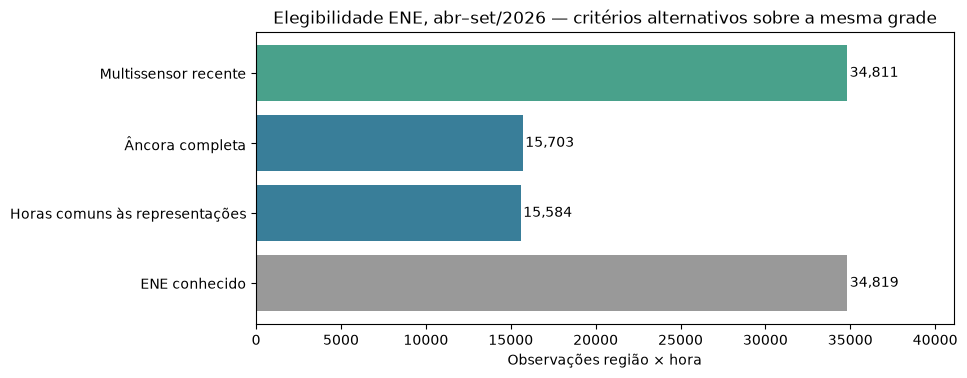

In [19]:
funil=[]
for ano,g in base.groupby('year'):
    conhecido=g.y_ENE_02.notna()
    completo=g[met].notna().all(axis=1)
    todos=g[[f'y_{r}_02' for r in motivos]].notna().all(axis=1)
    funil.append({'ano':ano,'grade':len(g),'alvo_ENE_conhecido':conhecido.sum(),
     'ancora_vento_recente':(conhecido & g.wind_lag1.notna()).sum(),
     'ancora_oito_atributos':(conhecido & completo).sum(),
     'populacao_V1_comum':(todos & completo).sum(),
     'multissensor_recente':(conhecido & g.sp_wind.notna()).sum()})
funil=pd.DataFrame(funil).set_index('ano')
tabela(funil,'funil_populacoes','Critérios alternativos ENE; multissensor não é etapa posterior à âncora completa')
externo=base.time_local.ge(pd.Timestamp('2026-04-01',tz=tz)) & base.time_local.lt(pd.Timestamp('2026-10-01',tz=tz))
x=base.loc[externo]
contagens={'ENE conhecido':int(x.y_ENE_02.notna().sum()),
 'Horas comuns às representações':int((x[[f'y_{r}_02' for r in motivos]+met].notna().all(axis=1)).sum()),
 'Âncora completa':int((x.y_ENE_02.notna()&x[met].notna().all(axis=1)).sum()),
 'Multissensor recente':int((x.y_ENE_02.notna()&x.sp_wind.notna()).sum())}
assert contagens['Horas comuns às representações']==15584 and contagens['Âncora completa']==15703 and contagens['Multissensor recente']==34811
fig,ax=plt.subplots(figsize=(9,3.8));ax.barh(list(contagens),list(contagens.values()),color=['#999999','#397e99','#397e99','#49a18b'])
for i,v in enumerate(contagens.values()):ax.text(v+150,i,f'{v:,}',va='center')
ax.set(xlabel='Observações região × hora',title='Elegibilidade ENE, abr–set/2026 — critérios alternativos sobre a mesma grade',xlim=(0,max(contagens.values())*1.18))
figura(fig,'populacoes_alternativas')

**Denominador: ENE conhecido na respectiva região/ano; 2026 parcial**

,Região,ano,ENE_conhecido,ancora_completa_pct,multissensor_pct
0,A408,2022,8661,99.74599,99.97691
1,A408,2023,8559,99.71959,99.96495
2,A408,2024,8728,83.84510,100.00000
3,A408,2025,8686,99.26318,99.90790
4,A408,2026,6525,99.21839,99.96935
...,...,...,...,...,...
35,A458,2022,2196,28.14208,100.00000
36,A458,2023,8660,51.67436,100.00000
37,A458,2024,8772,52.10898,100.00000
38,A458,2025,8709,54.62166,99.96555


*Mostradas as linhas iniciais e finais; a tabela completa, com 40 linhas, é salva em `resultados/tabelas/cobertura_regional_ano.csv`.*

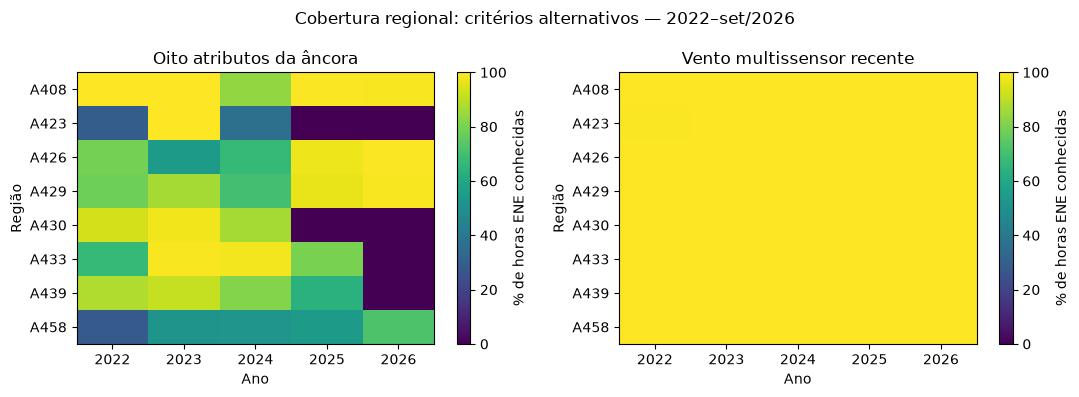

In [20]:
cob_reg=[]
for (r,ano),g in base.groupby(['region','year']):
    elegivel=g.y_ENE_02.notna();den=elegivel.sum()
    cob_reg.append({'regiao':r,'ano':ano,'ENE_conhecido':den,
      'ancora_completa_pct':100*(elegivel&g[met].notna().all(axis=1)).sum()/den,
      'multissensor_pct':100*(elegivel&g.sp_wind.notna()).sum()/den})
cob_reg=pd.DataFrame(cob_reg)
tabela(cob_reg,'cobertura_regional_ano','Denominador: ENE conhecido na respectiva região/ano; 2026 parcial')
fig,axs=plt.subplots(1,2,figsize=(11,4))
for ax,col,titulo in [(axs[0],'ancora_completa_pct','Oito atributos da âncora'),
                       (axs[1],'multissensor_pct','Vento multissensor recente')]:
    matc=cob_reg.pivot(index='regiao',columns='ano',values=col)
    im=ax.imshow(matc,vmin=0,vmax=100,aspect='auto',cmap='viridis')
    ax.set_xticks(range(5),matc.columns);ax.set_yticks(range(8),matc.index)
    ax.set(title=titulo,xlabel='Ano',ylabel='Região');fig.colorbar(im,ax=ax,label='% de horas ENE conhecidas')
fig.suptitle('Cobertura regional: critérios alternativos — 2022–set/2026')
fig.tight_layout();figura(fig,'cobertura_regional')

### Cobertura recuperada e comparação justa dos modelos

Em abril–setembro de 2026, o critério de oito atributos completos da estação âncora e ENE conhecido permite analisar **15.703 observações**. Ao exigir também os outros dois motivos conhecidos, restam **15.584**. Com a representação multissensor e ENE conhecido, a população chega a **34.811 observações**.

São **critérios alternativos**, não três etapas que devem ser somadas. O aumento de abrangência é relevante, principalmente em regiões com falhas prolongadas da âncora. Entretanto, avaliar modelos em uma população maior também muda a distribuição das observações.

Por isso, em cada comparação entre calendário e meteorologia, restringimos ambos às mesmas regiões e horas. O calendário não precisa de vento para prever, mas essa restrição experimental impede que a comparação favoreça um método simplesmente porque ele foi avaliado em casos diferentes. Mais cobertura é um resultado de preparação dos dados; melhor previsão será uma questão separada.

<a id="secao-6"></a>

## 6. Integração temporal e espacial das fontes

A integração precisa responder a duas perguntas: **quais registros descrevem o mesmo intervalo?** e **quais medições meteorológicas serão associadas a cada agrupamento eólico?**

No tempo, convertemos datas para uma referência comum e somamos dois intervalos energéticos de meia hora. No espaço, identificamos conjuntos, coordenadas e estações. Somente depois reunimos energia e meteorologia na tabela região × hora.

### Instantes e fusos horários

Os registros meteorológicos utilizam UTC, enquanto a apresentação do estudo usa o horário da Bahia (`America/Bahia`). Uma medição das 17h UTC corresponde às 14h nesse fuso. Converter o fuso preserva o instante físico; apenas muda sua representação no relógio. A tabela seguinte mostra essa correspondência em registros reais.

In [21]:
instantes=weather.loc[weather.station.eq('A408'),['time_utc']].head(6).copy()
instantes['time_local']=instantes.time_utc.dt.tz_convert(tz)
instantes['mesmo_instante_UTC']=instantes.time_local.dt.tz_convert('UTC')
assert instantes.time_utc.equals(instantes.mesmo_instante_UTC)
tabela(instantes,'fusos','Conversão real: a virada de data local pode anteceder a data UTC')
duas=ons[ons.id_ons.eq(ons.id_ons.iloc[0])].head(4).copy()
duas['hora']=duas.time_local.dt.floor('h')
duas['referencia_MWh']=duas.val_geracaoreferencia*.5
tabela(duas[['time_local','hora','val_geracaoreferencia','referencia_MWh']],
       'patamares_energia','Dados reais; referência MW × 0,5 h = energia MWh')
tabela(duas.groupby('hora').referencia_MWh.sum(),'energia_horaria_exemplo')

**Conversão real: a virada de data local pode anteceder a data UTC**

,Hora (UTC),Hora (Bahia),mesmo_instante_UTC
248976,2022-01-01 00:00:00+00:00,2021-12-31 21:00:00-03:00,2022-01-01 00:00:00+00:00
248977,2022-01-01 01:00:00+00:00,2021-12-31 22:00:00-03:00,2022-01-01 01:00:00+00:00
248978,2022-01-01 02:00:00+00:00,2021-12-31 23:00:00-03:00,2022-01-01 02:00:00+00:00
248979,2022-01-01 03:00:00+00:00,2022-01-01 00:00:00-03:00,2022-01-01 03:00:00+00:00
248980,2022-01-01 04:00:00+00:00,2022-01-01 01:00:00-03:00,2022-01-01 04:00:00+00:00
248981,2022-01-01 05:00:00+00:00,2022-01-01 02:00:00-03:00,2022-01-01 05:00:00+00:00


**Dados reais; referência MW × 0,5 h = energia MWh**

,Hora (Bahia),hora,val_geracaoreferencia,referencia_MWh
0,2025-11-01 00:00:00-03:00,2025-11-01 00:00:00-03:00,82.18400,41.09200
1,2025-11-01 00:30:00-03:00,2025-11-01 00:00:00-03:00,95.84000,47.92000
2,2025-11-01 01:00:00-03:00,2025-11-01 01:00:00-03:00,78.04500,39.02250
3,2025-11-01 01:30:00-03:00,2025-11-01 01:00:00-03:00,55.40700,27.70350


,referencia_MWh
hora,
2025-11-01 00:00:00-03:00,89.01200
2025-11-01 01:00:00-03:00,66.72600


### A fração regional deve ser calculada depois de somar as energias

Considere dois conjuntos na mesma região. Um possui referência de 10 MWh e corte de 5 MWh; o outro, referência de 90 MWh e nenhum corte. A média simples das frações individuais seria $(50\%+0\%)/2=25\%$.

Mas a região perdeu **5 MWh de uma referência de 100 MWh**, isto é, **5%**. Para medir a fração energética regional, o cálculo correto é

$$f_{r,t}=\frac{\sum_{j\in r}E_{\mathrm{corte},j,t}}{\sum_{j\in r}E_{\mathrm{ref},j,t}}.$$

O índice $j$ identifica conjuntos pertencentes à região $r$ e $t$ indica a hora. A fórmula dá maior participação energética aos conjuntos com maior referência, em vez de tratá-los como unidades de mesmo tamanho.

In [22]:
parques=pd.DataFrame({'referencia_MWh':[10.,90.],'corte_MWh':[5.,0.]})
parques['fracao']=parques.corte_MWh/parques.referencia_MWh
tabela(pd.DataFrame({'método':['média simples das frações','razão das somas'],
                    'fração':[parques.fracao.mean(),parques.corte_MWh.sum()/parques.referencia_MWh.sum()]}),
       'ponderacao_exemplo','Exemplo sintético de agregação regional')

**Exemplo sintético de agregação regional**

,método,fração
0,média simples das frações,0.25000
1,razão das somas,0.05000


### Da meia hora à tabela energética regional

A reconstrução de novembro de 2025 permite acompanhar o procedimento completo em um mês real. Para cada conjunto, associamos sua região, verificamos a validade do intervalo e convertemos referência e GNR de MW para MWh. Em seguida, agrupamos os dois intervalos da hora e os conjuntos da região.

Uma hora precisa conter os registros esperados e os campos necessários à apuração. Caso contrário, a soma observada pode ser apenas parcial. Mantemos essa condição identificada, em vez de apresentá-la como uma hora com pouca geração ou sem restrição.

Quando aparecem motivos mistos, calculamos limites inferiores e superiores de energia atribuível a cada motivo. Esses limites serão utilizados na seção 7 para construir rótulos sem inventar uma distribuição exata entre causas.

In [23]:
z=ons.copy();z['period']=z.time_local.dt.strftime('%Y_%m')
z=z.merge(geo,on=['id_ons','period'],how='left',validate='many_to_one')
assert z.region.notna().all() and len(z)==len(ons)
z['hora']=z.time_local.dt.floor('h')
minutos=z[[f'num_minutos_{r.lower()}' for r in motivos]]
ativos=minutos.gt(0);n_ativos=ativos.sum(axis=1)
limitado=z.val_geracaolimitada.notna()
sem_corte=(~limitado & z.cod_razaorestricao.isna() & z.val_geracaonaorealizadaapurada.isna()
           & minutos.fillna(0).eq(0).all(axis=1) & z.num_minutos_restricao.fillna(0).eq(0))
restrito_valido=(limitado & z.cod_razaorestricao.isin(motivos) & z.val_geracaolimitada.ge(0)
 & z.val_geracaonaorealizadaapurada.ge(0) & minutos.notna().all(axis=1)
 & minutos.ge(0).all(axis=1)&minutos.le(30).all(axis=1)&z.num_minutos_restricao.between(1,30)
 & minutos.sum(axis=1).eq(z.num_minutos_restricao)&n_ativos.ge(1))
validade_inicial=(sem_corte|restrito_valido)&z.val_geracao.ge(0)&z.val_geracaoreferencia.ge(0)
z['reference_mwh']=z.val_geracaoreferencia*.5
z['generation_mwh']=z.val_geracao*.5
corte=z.val_geracaonaorealizadaapurada.where(limitado,0)*.5
z['cut_total_mwh']=corte.where(validade_inicial)
for r in motivos:
    presente=ativos[f'num_minutos_{r.lower()}']
    z[f'cut_low_{r}']=corte.where(presente & n_ativos.eq(1),0).where(validade_inicial)
    z[f'cut_high_{r}']=corte.where(presente,0).where(validade_inicial)
z['contagem_patamares']=z.groupby(['id_ons','hora']).id_ons.transform('size')
suspeito=z.capacity_mw.gt(0)&(z.val_geracao.gt(1.5*z.capacity_mw)|z.val_geracaoreferencia.gt(1.5*z.capacity_mw))
z['valido']=validade_inicial & z.contagem_patamares.eq(2)&z.spatial_eligible&~suspeito
energia=['reference_mwh','generation_mwh','cut_total_mwh']+[f'cut_{b}_{r}' for r in motivos for b in ['low','high']]
h=z.groupby(['region','hora'])[energia].sum()
cont=z.groupby(['region','hora']).agg(rows=('id_ons','size'),units=('id_ons','nunique'),valid_rows=('valido','sum'))
h=h.join(cont);h['ons_eligible']=h.rows.eq(h.valid_rows)&h.rows.eq(2*h.units)&h.reference_mwh.gt(0)
h.loc[~h.ons_eligible,energia]=np.nan
h=h.reset_index().rename(columns={'hora':'time_local'})
comparacao=h.merge(base[['region','time_local']+energia+['ons_eligible']],on=['region','time_local'],suffixes=('_novo','_historico'),validate='one_to_one')
assert len(comparacao)==len(h)
for col in energia:
    np.testing.assert_allclose(comparacao[col+'_novo'],comparacao[col+'_historico'],atol=1e-8,rtol=1e-12,equal_nan=True)
np.testing.assert_array_equal(comparacao.ons_eligible_novo,comparacao.ons_eligible_historico)
tabela(h[['region','time_local','units','reference_mwh','cut_total_mwh','ons_eligible']].head(8),'integracao_reconstruida')
print(f'{len(h):,} horas-região reconstruídas; energia e elegibilidade coincidem com a base histórica.')

,Região,Hora (Bahia),Conjuntos,Energia de referência (MWh),Energia restringida (MWh),Registro energético válido
0,A408,2025-11-01 00:00:00-03:00,4,553.44800,84.75300,True
1,A408,2025-11-01 01:00:00-03:00,4,543.23300,40.66950,True
2,A408,2025-11-01 02:00:00-03:00,4,516.10400,0.00000,True
3,A408,2025-11-01 03:00:00-03:00,4,507.22900,0.00000,True
4,A408,2025-11-01 04:00:00-03:00,4,530.70000,0.00000,True
5,A408,2025-11-01 05:00:00-03:00,4,335.73800,0.00000,True
6,A408,2025-11-01 06:00:00-03:00,4,414.07250,91.49750,True
7,A408,2025-11-01 07:00:00-03:00,4,476.09600,210.31050,True


5,760 horas-região reconstruídas; energia e elegibilidade coincidem com a base histórica.


Os totais reconstruídos coincidem numericamente com a base integrada no mês examinado. A verificação cobre referência, energia restringida, limites por motivo e elegibilidade, mostrando que as regras expostas levam à tabela utilizada na análise.

O resultado também esclarece por que a limpeza precisa vir antes da modelagem: um registro ausente pode comprometer uma soma regional, e um motivo ambíguo pode impedir a determinação de um rótulo. Esses problemas não seriam resolvidos apenas escolhendo um algoritmo mais sofisticado.

### Associação geográfica: dos conjuntos eólicos às oito regiões

Os dados energéticos identificam **conjuntos de geração eólica**, enquanto o INMET registra medições em **estações meteorológicas**. Essas duas redes não coincidem: um conjunto eólico pode estar longe de uma estação, e uma estação pode servir de referência para diversos conjuntos. A integração precisa, portanto, definir uma correspondência geográfica antes de juntar energia e meteorologia.

**Primeiro, agrupamos os conjuntos eólicos.** Localizamos os conjuntos com apoio do cadastro SIGA/ANEEL e consideramos estações INMET com coordenadas e cobertura histórica adequadas. Cada conjunto foi associado à estação de referência mais próxima entre as candidatas aceitas, respeitando o raio estabelecido de 200 km. O processo produziu **oito agrupamentos de conjuntos eólicos**, chamados aqui de *regiões*. Cada região recebeu como identificador o código de sua **estação âncora**: A408, A423, A426, A429, A430, A433, A439 ou A458.

A palavra *âncora* descreve a referência geográfica **usada para formar e nomear o grupo**, não uma medição física realizada dentro de cada parque. Oito regiões significam oito grupos de conjuntos; **não significam oito conjuntos nem oito estações disponíveis no INMET**. Os conjuntos existentes e sua participação na base podem variar com o mês.

**Depois, associamos as medições.** Uma opção é utilizar o vento da estação âncora. Para reduzir as perdas quando ela não mede, construímos também uma representação que considera **até cinco estações próximas ao centroide de cada região**. Essas estações são escolhidas para a representação meteorológica, não para redefinir a quais regiões os conjuntos eólicos pertencem. Uma estação pode contribuir para mais de uma região, e a própria âncora pode não estar entre as cinco estações selecionadas.

Quando há mais de uma medição disponível, podemos calcular uma velocidade regional ponderada pela distância:

$$\bar v_{r,t}=\frac{\sum_{i\in S_{r,t}}w_i v_{i,t}}{\sum_{i\in S_{r,t}}w_i},\qquad
w_i=\frac{1}{\max(d_i,10\,\mathrm{km})^2}.$$

Aqui, $S_{r,t}$ é o conjunto de estações que efetivamente mediram no horário $t$; $d_i$ é a distância da estação ao centroide regional. O piso de 10 km impede que uma estação muito próxima domine o cálculo de maneira excessiva. Uma estação sem medição naquele horário não participa da média, e os pesos das demais são renormalizados. Se todas estiverem ausentes, o vento estimado permanece ausente.

O mapa seguinte ilustra a proximidade utilizada; a tabela posterior apresenta as quantidades e um exemplo real. Trata-se de uma aproximação meteorológica baseada em estações de superfície, **não de uma medição à altura dos rotores**.


**Distâncias ao centroide da região, não ao rotor de cada usina**

,sensores,distancia_min_km,distancia_max_km
Região,,,
A408,5,65.44159,130.92307
A423,5,7.72587,127.37310
A426,4,16.24364,143.38459
A429,5,69.69928,135.62118
A430,5,47.01281,149.56168
A433,5,27.07567,158.00658
A439,5,94.69747,154.69523
A458,5,29.44047,110.65408


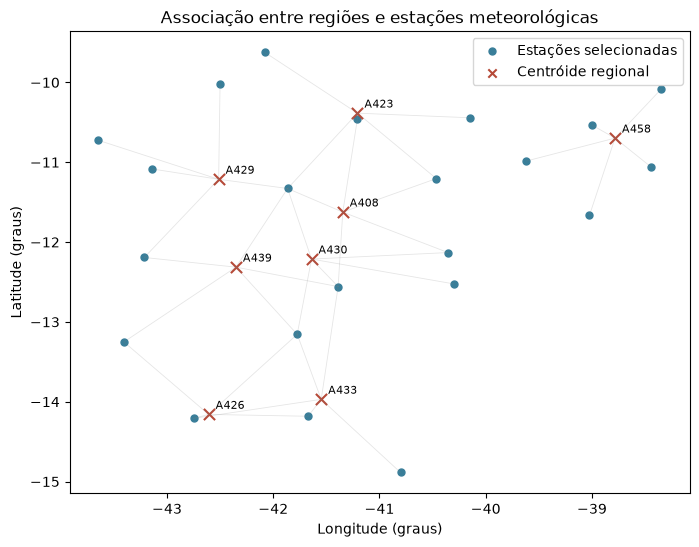

In [24]:
mapping=pd.read_csv(ROOT/'dados/sensores_por_regiao.csv')
coord=cadastro[cadastro.year.le(2024)].groupby('station')[['latitude','longitude']].median()
tabela(mapping.groupby('region').agg(sensores=('station','size'),distancia_min_km=('distance_km','min'),distancia_max_km=('distance_km','max')),
       'distancias_sensores','Distâncias ao centroide da região, não ao rotor de cada usina')
fig,ax=plt.subplots(figsize=(8,6))
usados=coord.loc[sorted(mapping.station.unique())]
ax.scatter(usados.longitude,usados.latitude,s=25,label='Estações selecionadas',color='#397e99')
for r,g in mapping.groupby('region'):
    a=g.iloc[0];ax.scatter(a.centroid_lon,a.centroid_lat,marker='x',s=65,color='#b64a38')
    ax.annotate(r,(a.centroid_lon,a.centroid_lat),xytext=(5,4),textcoords='offset points',fontsize=8)
    for linha in g.itertuples():
        s=coord.loc[linha.station];ax.plot([a.centroid_lon,s.longitude],[a.centroid_lat,s.latitude],color='gray',alpha=.2,lw=.6)
ax.scatter([],[],marker='x',color='#b64a38',label='Centróide regional')
ax.set(xlabel='Longitude (graus)',ylabel='Latitude (graus)',title='Associação entre regiões e estações meteorológicas')
ax.legend();figura(fig,'mapa_sensores')

### Quantos conjuntos, estações e regiões há no estudo?

É útil contar as entidades antes de discutir modelos. **Conjunto ONS** é uma unidade de registro energético; **estação INMET** é uma fonte de medições atmosféricas; **região** é o agrupamento construído para esta análise. A tabela abaixo distingue a quantidade encontrada ao longo de todo o histórico da quantidade observada em um único mês.


In [25]:
# Quantidades calculadas das fontes do projeto; identificadores não devem ser somados entre meses.
mapa_conjuntos = pd.read_csv(ROOT/'dados/mapeamento_conjuntos.csv')
estacoes_candidatas = pd.read_csv(ROOT/'dados/estacoes_ancora.csv')
sensores_regiao = pd.read_csv(ROOT/'dados/sensores_por_regiao.csv')
resumo_espacial = pd.DataFrame([
    ('Conjuntos ONS geograficamente associados em algum mês', mapa_conjuntos.id_ons.nunique()),
    ('Conjuntos presentes no exemplo energético de novembro/2025', ons.id_ons.nunique()),
    ('Estações INMET presentes na base meteorológica', weather.station.nunique()),
    ('Estações candidatas elegíveis para a seleção geográfica', int(estacoes_candidatas.eligible.sum())),
    ('Estações âncora que identificam as regiões', mapa_conjuntos.region.nunique()),
    ('Regiões construídas para a análise', base.region.nunique()),
    ('Estações distintas escolhidas para a representação multissensor', sensores_regiao.station.nunique()),
    ('Associações entre uma região e uma estação selecionada', len(sensores_regiao))
], columns=['Entidade / contagem', 'Quantidade'])
tabela(resumo_espacial,'contagens_espaciais','Universos distintos: conjuntos ONS, estações INMET e regiões')
assert resumo_espacial.Quantidade.to_list()==[68,45,47,17,8,8,22,39]

por_regiao=(mapa_conjuntos.groupby('region').id_ons.nunique().rename('Conjuntos diferentes no histórico')
            .to_frame().join(sensores_regiao.groupby('region').station.nunique().rename('Sensores multissensor'))
            .reset_index().rename(columns={'region':'Região'}))
tabela(por_regiao,'conjuntos_por_regiao','Conjuntos distintos ao longo do histórico e sensores associados por região')


**Universos distintos: conjuntos ONS, estações INMET e regiões**

,Entidade / contagem,Quantidade
0,Conjuntos ONS geograficamente associados em algum mês,68
1,Conjuntos presentes no exemplo energético de novembro/2025,45
2,Estações INMET presentes na base meteorológica,47
3,Estações candidatas elegíveis para a seleção geográfica,17
4,Estações âncora que identificam as regiões,8
5,Regiões construídas para a análise,8
6,Estações distintas escolhidas para a representação multissensor,22
7,Associações entre uma região e uma estação selecionada,39


**Conjuntos distintos ao longo do histórico e sensores associados por região**

,Região,Conjuntos diferentes no histórico,Sensores multissensor
0,A408,7,5
1,A423,21,5
2,A426,27,4
3,A429,5,5
4,A430,4,5
5,A433,1,5
6,A439,1,5
7,A458,2,5


In [26]:
regiao='A408';m=mapping[mapping.region.eq(regiao)].set_index('station')
mat=mat_vento.reindex(columns=m.index)
valid=mat.notna();pesos=pd.Series(m.weight,index=m.index)
denominador=valid.mul(pesos,axis=1).sum(axis=1)
media_espacial=mat.mul(pesos,axis=1).sum(axis=1).div(denominador.where(denominador>0))
# O instante de medição é convertido para o alvo duas horas depois.
alvo=media_espacial.copy();alvo.index=alvo.index.tz_convert(tz)+pd.Timedelta(hours=2)
comparar=base[base.region.eq(regiao)&base.time_local.between(pd.Timestamp('2025-11-01',tz=tz),pd.Timestamp('2025-11-30 23:00',tz=tz))].set_index('time_local')
np.testing.assert_allclose(alvo.reindex(comparar.index),comparar.sp_wind,atol=1e-12,equal_nan=True)
tabela(pd.DataFrame({'vento_multissensor_recalculado_ms':alvo.reindex(comparar.index),'vento_historico_ms':comparar.sp_wind,
                    'sensores_validos':comparar.sp_count}).head(8),'multissensor_recalculado')

,vento_multissensor_recalculado_ms,vento_historico_ms,sensores_validos
Hora (Bahia),,,
2025-11-01 00:00:00-03:00,3.10024,3.10024,2.00000
2025-11-01 01:00:00-03:00,4.00034,4.00034,2.00000
2025-11-01 02:00:00-03:00,2.91999,2.91999,2.00000
2025-11-01 03:00:00-03:00,2.08006,2.08006,2.00000
2025-11-01 04:00:00-03:00,1.33983,1.33983,2.00000
2025-11-01 05:00:00-03:00,1.35987,1.35987,2.00000
2025-11-01 06:00:00-03:00,0.81984,0.81984,2.00000
2025-11-01 07:00:00-03:00,1.97991,1.97991,2.00000


**Exemplo — região A408.** Seu nome provém da estação âncora A408, usada para identificar o agrupamento. Entretanto, as cinco fontes escolhidas para a média meteorológica dessa região são A424, A425, A440, A412 e A443. Portanto, **a estação que dá nome à região não é necessariamente uma das fontes selecionadas para estimar seu vento**. As duas etapas têm funções diferentes: formar o grupo de conjuntos e estimar uma condição meteorológica para ele.

Em novembro de 2025, o exemplo energético inclui 45 conjuntos em todo o recorte; em todo o histórico geográfico, encontramos 68 identificadores distintos. Não somamos conjuntos de meses diferentes para produzir uma suposta frota simultânea. Esse mesmo cuidado é necessário quando interpretamos os tamanhos das amostras de treinamento.


### O que muda — e o que não muda — ao utilizar várias estações

Ao reunir até cinco fontes de medição, podemos representar mais horas do que quando exigimos que uma única estação tenha valores válidos. A tabela anterior mostra também quantas estações sustentam a estimativa de cada hora: uma média baseada em apenas um sensor deve ser interpretada com mais cautela que uma média apoiada em vários.

**Mais cobertura não é automaticamente maior poder preditivo.** Há duas decisões distintas. A primeira determina **quais horas podem participar** de uma análise por causa da disponibilidade de sensores. A segunda determina **quais atributos meteorológicos entram de fato no modelo**. Um classificador pode ser avaliado numa população ampliada e ainda utilizar atributos básicos da estação âncora, com tratamento para suas ausências. Isso não significa que ele tenha recebido a média ponderada multissensor. Os modelos que utilizam resumos de várias estações serão identificados explicitamente na parte de previsão.

Por fim, relevo, distância e altura de medição podem fazer o vento da estação diferir daquele experimentado pelas turbinas. As oito regiões são agrupamentos de análise, não um mapa da conectividade elétrica do sistema. Essas limitações orientam a interpretação dos resultados meteorológicos.


<a id="secao-7"></a>

## 7. Base de observações e definição dos alvos

### Uma grade completa, inclusive onde faltam dados

A grade reúne oito regiões e todas as horas entre 01/01/2022 e 30/09/2026: **332.928 posições**. Completar a grade garante que o deslocamento de uma hora corresponda a uma hora física, mesmo durante uma falha de medição. Não significa que todas as posições tenham dados válidos.

Vamos distinguir três situações: **valor zero**, quando a grandeza observada é nula; **dado ausente**, quando falta uma medição; e **rótulo desconhecido**, quando não podemos decidir se o evento ocorreu. Nenhuma dessas situações deve substituir automaticamente as outras.

### Ocorrência por motivo: o limiar de 2%

Para cada motivo, queremos prever se sua energia restringida ultrapassa **2% da energia de referência regional**. Assim, ENE de 1% recebe rótulo 0 e ENE de 10% recebe rótulo 1. O zero significa “não ultrapassou 2%”, não necessariamente “nenhum corte”. Adotamos **2% como escolha do projeto** para distinguir pequenas restrições de eventos proporcionalmente mais relevantes. É uma definição da tarefa, não um limite regulatório nem um parâmetro otimizado sobre o teste.

Nos casos mistos, conhecemos apenas um intervalo possível. Sejam $L$ e $U$ os limites inferior e superior da energia do motivo e $R>0$ a referência da região e hora:

$$y=\begin{cases}
1,&L/R>0,02,\\
0,&U/R\leq0,02,\\
\text{desconhecido},&\text{caso contrário.}
\end{cases}$$

Se até o limite inferior supera 2%, temos certeza do rótulo positivo. Se nem o superior supera 2%, o rótulo é negativo. Se o intervalo atravessa o limiar, preservamos a incerteza.

In [27]:
grade=pd.date_range('2022-01-01','2026-10-01',inclusive='left',freq='h',tz=tz)
esperada=pd.MultiIndex.from_product([sorted(base.region.unique()),grade],names=['region','time_local'])
observada=pd.MultiIndex.from_frame(base[['region','time_local']])
assert len(esperada)==len(base) and esperada.difference(observada).empty
tabela(pd.DataFrame({'regioes':[base.region.nunique()],'horas_por_regiao':[len(grade)],'linhas_grade':[len(esperada)],
                    'horas_ONS_elegiveis':[int(base.ons_eligible.sum())]}),'grade_analitica')

,regioes,horas_por_regiao,linhas_grade,horas_ONS_elegiveis
0,8,41616,332928,315828


In [28]:
def rotulo_por_limites(frame,motivo,tau=.02):
    valido=frame.ons_eligible & frame.reference_mwh.gt(0)
    inferior=frame[f'cut_low_{motivo}']/frame.reference_mwh
    superior=frame[f'cut_high_{motivo}']/frame.reference_mwh
    resultado=pd.Series(np.nan,index=frame.index)
    resultado.loc[valido & superior.le(tau)]=0.
    resultado.loc[valido & inferior.gt(tau)]=1.
    return resultado
for r in motivos:
    reconstruido=rotulo_por_limites(base,r)
    np.testing.assert_allclose(reconstruido,base[f'y_{r}_02'],equal_nan=True)
base_conhecida=base.ons_eligible & base.reference_mwh.gt(0)
np.testing.assert_allclose(base.loc[base_conhecida,'fraction_total'],
                         base.loc[base_conhecida,'cut_total_mwh']/base.loc[base_conhecida,'reference_mwh'],equal_nan=True)
print('Três alvos binários e fração TOTAL conferidos em toda a grade.')
casos=pd.DataFrame({'reference_mwh':[100.,100.,100.,0.], 'cut_low_ENE':[0.,3.,1.,0.],
 'cut_high_ENE':[1.,3.,4.,0.],'ons_eligible':[True,True,True,False]},index=['corte pequeno','positivo certo','motivo ambíguo','referência nula'])
casos['rotulo_ENE']=rotulo_por_limites(casos,'ENE')
tabela(casos,'exemplos_rotulos','Exemplos sintéticos de limites: NaN não será convertido em zero')

Três alvos binários e fração TOTAL conferidos em toda a grade.


**Exemplos sintéticos de limites: NaN não será convertido em zero**

,Energia de referência (MWh),cut_low_ENE,cut_high_ENE,Registro energético válido,rotulo_ENE
corte pequeno,100.00000,0.00000,1.00000,True,0.00000
positivo certo,100.00000,3.00000,3.00000,True,1.00000
motivo ambíguo,100.00000,1.00000,4.00000,True,NaN
referência nula,0.00000,0.00000,0.00000,False,NaN


O exemplo com referência de 100 MWh torna a regra concreta. Um limite superior de 1 MWh garante rótulo negativo. Um limite inferior de 3 MWh garante rótulo positivo. Já um intervalo entre 1 e 4 MWh não permite decidir se o corte do motivo ultrapassou 2 MWh: o rótulo fica desconhecido.

As verificações aplicam essa regra às três colunas de ocorrência. Uma linha com referência nula ou sem qualidade energética suficiente também não produz um rótulo utilizável. O aprendizado de cada motivo inclui somente observações em que sua resposta pode ser determinada.

In [29]:
colunas=['region','time_local','reference_mwh','cut_total_mwh','cut_low_ENE','cut_high_ENE','y_ENE_02','y_CNF_02','y_REL_02','fraction_total','sp_wind']
ambigua=base.ons_eligible & base.y_ENE_02.isna()
exemplos=pd.concat([base[base.y_ENE_02.eq(0)].head(2),base[base.y_ENE_02.eq(1)].head(2),base[ambigua].head(2)])
tabela(exemplos[colunas],'base_integrada_exemplos','Linhas reais finais; energia em MWh, fração adimensional, vento em m/s')
assert base.loc[~base.ons_eligible,[f'y_{r}_02' for r in motivos]].isna().all().all()

**Linhas reais finais; energia em MWh, fração adimensional, vento em m/s**

,Região,Hora (Bahia),Energia de referência (MWh),Energia restringida (MWh),cut_low_ENE,cut_high_ENE,y_ENE_02,y_CNF_02,y_REL_02,Fração restringida,sp_wind
0,A408,2022-01-01 00:00:00-03:00,23.72100,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,NaN
1,A408,2022-01-01 01:00:00-03:00,16.35300,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,NaN
2886,A408,2022-05-01 06:00:00-03:00,449.37050,13.66600,13.66600,13.66600,1.00000,0.00000,0.00000,0.03041,1.67381
2887,A408,2022-05-01 07:00:00-03:00,480.21450,36.68350,36.68350,36.68350,1.00000,0.00000,0.00000,0.07639,1.78968
14824,A408,2023-09-10 16:00:00-03:00,269.56800,10.87650,0.00000,8.04850,NaN,NaN,0.00000,0.04035,2.91587
22712,A408,2024-08-04 08:00:00-03:00,484.30850,445.58050,0.00000,225.14250,NaN,0.00000,1.00000,0.92003,1.12009


### Ocorrência e intensidade são perguntas diferentes

Os três classificadores estimam probabilidades de ENE, CNF ou REL acima de 2%. A tarefa de intensidade usa outro alvo:

$$f_{\mathrm{total},r,t}=\frac{E_{\mathrm{corte,total},r,t}}{E_{\mathrm{referência},r,t}}\in[0,1].$$

Uma hora com REL de 50% e sem ENE é negativa para a classificação de ENE, mas tem magnitude total 0,50. Uma hora com ENE de 1% também é negativa nesse classificador, embora sua magnitude seja positiva. **Não podemos usar o sucesso em uma tarefa como confirmação automática da outra.**

A fração mede intensidade relativa. Prever quantos MWh serão perdidos exigiria também uma estimativa da referência energética futura. Com os alvos definidos, podemos explorar suas distribuições e decidir como representá-las para os modelos.

### Armazenamento documental da base integrada

Cada observação continua representando uma região durante uma hora. O que muda é sua organização: em vez de dispor todos os campos em colunas, podemos reuni-los em um **documento**, isto é, um registro estruturado com grupos de campos. Aqui, documento não significa um PDF ou texto corrido. A chave identifica região e hora; o grupo `ons` contém energias e rótulos; o grupo `inmet` reúne as medições meteorológicas associadas.

Essa organização mantém visível a origem das informações e permite consultas que combinam as duas fontes. Utilizaremos **TinyDB**, um banco documental que grava os registros em JSON [6]. A integração temporal e espacial já foi realizada nas etapas anteriores: o banco armazena e consulta seu resultado, não substitui aquelas transformações.

A demonstração usa as oito regiões de novembro de 2025. São **8 × 30 × 24 = 5.760 documentos**, incluindo horas com informações ausentes. Valores desconhecidos são preservados como `null` no JSON, e não transformados em zero. O exemplo exibido abaixo é um registro real; seus campos energéticos descrevem o resultado observado, enquanto os meteorológicos respeitam as defasagens da base.


In [30]:
# Importar TinyDB; a cópia de execução offline é usada apenas se necessário.
inc_documental = importar_modulo('incrementos_documental', ROOT/'codigo/incrementos.py')
tinydb_mod, origem_tinydb = inc_documental.importar_tinydb(ROOT)
TinyDB, Query = tinydb_mod.TinyDB, tinydb_mod.Query
nov_documental = base.loc[
    base.time_local.ge(pd.Timestamp('2025-11-01', tz=tz)) &
    base.time_local.lt(pd.Timestamp('2025-12-01', tz=tz))].copy()

def numero_documento(valor):
    if pd.isna(valor):
        return None
    if not np.isfinite(valor):
        raise ValueError('Número não finito na base documental.')
    return float(valor)

def documento_integrado(linha):
    return {
        'chave': f'{linha.region}|{linha.time_local.isoformat()}',
        'regiao': str(linha.region), 'hora_local': linha.time_local.isoformat(),
        'ons': {
            'registro_valido': bool(linha.ons_eligible),
            'referencia_mwh': numero_documento(linha.reference_mwh),
            'corte_total_mwh': numero_documento(linha.cut_total_mwh),
            'fracao_total': numero_documento(linha.fraction_total),
            'rotulos_2pct': {m: None if pd.isna(getattr(linha, f'y_{m}_02'))
                            else int(getattr(linha, f'y_{m}_02')) for m in motivos}},
        'inmet': {
            'vento_t2_ms': numero_documento(linha.wind_lag1),
            'rajada_t2_ms': numero_documento(linha.gust_lag1),
            'vento_multissensor_ms': numero_documento(linha.sp_wind),
            'sensores_validos': None if pd.isna(linha.sp_count) else int(linha.sp_count)}}

docs_integrados = [documento_integrado(r) for r in nov_documental.itertuples(index=False)]
assert len(docs_integrados) == len({d['chave'] for d in docs_integrados}) == 5760
pasta_nosql = OUT/'nosql'; pasta_nosql.mkdir(exist_ok=True)
arquivo_documental = pasta_nosql/'base_documental_nov2025.json'
# Reexecução idempotente: somente a tabela desta demonstração é recriada.
with TinyDB(arquivo_documental, encoding='utf-8', ensure_ascii=False, allow_nan=False) as db:
    tab_documental = db.table('regiao_hora')
    tab_documental.truncate()
    tab_documental.insert_multiple(docs_integrados)
assert json.loads(arquivo_documental.read_text(encoding='utf-8'))
(OUT/'recibos/tinydb_integrado.json').write_text(json.dumps({
    'motor': 'TinyDB', 'versao': tinydb_mod.__version__, 'origem': origem_tinydb,
    'documentos': len(docs_integrados), 'arquivo': 'resultados/nosql/base_documental_nov2025.json'},
    ensure_ascii=False, indent=2), encoding='utf-8')
print(f'Motor: TinyDB {tinydb_mod.__version__} — {len(docs_integrados):,} documentos gravados.')
print('Exemplo real de um documento região × hora:')
print(json.dumps(docs_integrados[0], ensure_ascii=False, indent=2, allow_nan=False))


Motor: TinyDB 4.8.2 — 5,760 documentos gravados.
Exemplo real de um documento região × hora:
{
  "chave": "A408|2025-11-01T00:00:00-03:00",
  "regiao": "A408",
  "hora_local": "2025-11-01T00:00:00-03:00",
  "ons": {
    "registro_valido": true,
    "referencia_mwh": 553.448,
    "corte_total_mwh": 84.75299999999999,
    "fracao_total": 0.15313633801188187,
    "rotulos_2pct": {
      "ENE": 0,
      "CNF": 1,
      "REL": 0
    }
  },
  "inmet": {
    "vento_t2_ms": 2.4,
    "rajada_t2_ms": 6.0,
    "vento_multissensor_ms": 3.100243751590467,
    "sensores_validos": 2
  }
}


In [31]:
# Consulta: ENE > 2% e vento multissensor de pelo menos 3 m/s.
# O valor de 3 m/s é uma condição demonstrativa, não um limiar preditivo escolhido.
with TinyDB(arquivo_documental, encoding='utf-8') as db:
    tab_documental = db.table('regiao_hora')
    q = Query()
    consulta = ((q.ons.rotulos_2pct.ENE == 1) &
                q.inmet.vento_multissensor_ms.test(lambda v: v is not None and v >= 3))
    encontrados = tab_documental.search(consulta)
    total_documentos = len(tab_documental)
    total_ene = tab_documental.count(q.ons.rotulos_2pct.ENE == 1)
    relidos = tab_documental.all()

# A mesma pergunta na tabela original deve retornar as MESMAS chaves, não só o mesmo total.
selecao_tabela = nov_documental.loc[nov_documental.y_ENE_02.eq(1) & nov_documental.sp_wind.ge(3)]
chaves_documentos = {d['chave'] for d in encontrados}
chaves_tabela = {f'{r.region}|{r.time_local.isoformat()}' for r in selecao_tabela.itertuples(index=False)}
assert chaves_documentos == chaves_tabela
assert {d['chave']: dict(d) for d in relidos} == {d['chave']: d for d in docs_integrados}
assert total_documentos == len(nov_documental)
assert total_ene == int(nov_documental.y_ENE_02.eq(1).sum())
resumo_documental = pd.DataFrame([{
    'Documentos': total_documentos, 'ENE > 2%': total_ene,
    'ENE > 2% e vento ≥ 3 m/s': len(encontrados),
    'Mesmas chaves na tabela': chaves_documentos == chaves_tabela,
    'Conteúdo preservado após reabrir': True}])
tabela(resumo_documental, 'consulta_documental_integrada',
       'Base documental — novembro de 2025; consulta e conteúdo conferidos contra a base integrada')
_ = (OUT/'recibos/documental_chaves.json').write_text(json.dumps({
    'chaves_consulta': sorted(chaves_documentos), 'igualdade_com_tabela': True,
    'documentos_sem_duplicatas': total_documentos,
    'nulos_preservados': sum(d['ons']['rotulos_2pct']['ENE'] is None for d in docs_integrados)},
    ensure_ascii=False, indent=2), encoding='utf-8')


**Base documental — novembro de 2025; consulta e conteúdo conferidos contra a base integrada**

,Documentos,ENE > 2%,ENE > 2% e vento ≥ 3 m/s,Mesmas chaves na tabela,Conteúdo preservado após reabrir
0,5760,1839,632,True,True


A consulta encontra **632 documentos** que atendem simultaneamente às duas condições, entre **1.839 horas com ENE acima de 2%**. A conferência compara as chaves região × hora e o conteúdo recuperado após reabrir o banco. Assim, não basta obter a mesma quantidade: verificamos que os registros são efetivamente os mesmos e que a gravação preserva seus valores.

O exemplo amplia o papel da gestão dos dados: além de descrever as fontes em um catálogo, podemos armazenar e consultar as observações integradas preservando sua organização e seus valores ausentes. Não se trata de um teste de velocidade entre bancos, de processamento distribuído nem de evidência de que vento de 3 m/s provoque restrições. A demonstração documental não altera a base utilizada pelos modelos. A seguir, voltamos à forma tabular para investigar as distribuições e os padrões das variáveis.


<a id="secao-8"></a>

## 8. Análise exploratória das restrições de geração

### Valores típicos, dispersão e extremos

A análise exploratória — EDA — procura entender o comportamento dos dados antes de resumir o problema em um modelo. Começamos pelas horas com qualidade energética suficiente, descrevendo referência, geração, energia restringida e fração total de corte.

A **média** considera todos os valores e é sensível a uma cauda de cortes intensos. A **mediana** divide as observações ordenadas ao meio. Os quartis $Q_1$ e $Q_3$ delimitam os 50% centrais, e $IQR=Q_3-Q_1$ mede sua dispersão. Para a variabilidade geral, calculamos a variância amostral e o desvio padrão:

$$s^2=\frac{1}{n-1}\sum_{i=1}^n(x_i-\bar x)^2,\qquad s=\sqrt{s^2}.$$

O desvio volta à unidade original; a variância tem unidade ao quadrado. Também calculamos o desvio médio absoluto, $DMA=\frac{1}{n}\sum_i|x_i-\bar x|$. Esses resumos são complementares: uma única média pode esconder muitos zeros e poucos cortes muito elevados.

Nas estatísticas de fração, cada região e hora recebe o mesmo peso. Isso responde como se distribuem as observações. A razão entre somas de energia responde a outra pergunta — qual parcela da energia total foi restringida — e será identificada quando utilizada.

In [32]:
energia_base=base[base.ons_eligible].copy()
energia_base['mes_civil']=energia_base.time_local.dt.month
est=apoio.descrever(energia_base,['reference_mwh','generation_mwh','cut_total_mwh','fraction_total'])
tabela(est[['n','ausentes','media','mediana','moda','q1','q3','p95','p99']],'estatisticas_energia_localizacao',
       'Horas ONS elegíveis, 2022–set/2026; três energias em MWh e fração adimensional')
tabela(est[['minimo','maximo','amplitude','variancia','desvio','IQR','DMA']],
       'estatisticas_energia_dispersao','Variância em MWh² ou fração²; demais medidas nas unidades originais')
texto(f"A fração mediana é **{est.loc['fraction_total','mediana']:.4f}**, enquanto a média é **{est.loc['fraction_total','media']:.4f}**. "
      f"O percentil 95 é **{est.loc['fraction_total','p95']:.4f}**. A diferença entre média, mediana e cauda exige analisar zeros e positivos separadamente.")

**Horas ONS elegíveis, 2022–set/2026; três energias em MWh e fração adimensional**

,Observações,Ausentes,Média,Mediana,Moda,q1,q3,p95,p99
Variável,,,,,,,,,
Energia de referência (MWh),315828,0,516.22715,197.91825,0.00400,62.59488,610.34525,"2,134.25450","3,280.66855"
generation_mwh,315828,0,495.71846,190.15875,0.00000,53.00787,588.89125,"2,184.13325","3,159.94285"
Energia restringida (MWh),315828,0,58.93293,0.00000,0.00000,0.00000,0.00000,332.23867,"1,313.87952"
Fração restringida,315828,0,0.09481,0.00000,0.00000,0.00000,0.00000,0.73577,0.99961


**Variância em MWh² ou fração²; demais medidas nas unidades originais**

,Mínimo,Máximo,Amplitude,Variância,Desvio padrão,IQR,DMA
Variável,,,,,,,
Energia de referência (MWh),0.00200,"4,334.97250","4,334.97050","521,428.67489",722.10018,547.75038,516.62924
generation_mwh,0.00000,"4,232.74150","4,232.74150","504,422.40947",710.22701,535.88338,503.64456
Energia restringida (MWh),0.00000,"4,029.17200","4,029.17200","51,998.56488",228.03194,0.00000,97.40402
Fração restringida,0.00000,1.00000,1.00000,0.05455,0.23356,0.00000,0.15030


A fração mediana é **0.0000**, enquanto a média é **0.0948**. O percentil 95 é **0.7358**. A diferença entre média, mediana e cauda exige analisar zeros e positivos separadamente.

### Horas sem corte e intensidade dos cortes positivos

A distribuição completa pode ser dominada por valores zero. Para enxergar a intensidade dos eventos, mostramos também a distribuição **somente nas horas com corte positivo**. O primeiro gráfico responde com que frequência cada magnitude ocorre na base; o segundo descreve a severidade quando há restrição.

Nos boxplots, a caixa representa os quartis e a linha interna, a mediana. Uma distribuição com muitos zeros pode ter $Q_1=Q_3=0$, fazendo valores positivos aparecerem além da cerca. Isso não é motivo para excluí-los: eles são justamente os eventos que queremos estudar.

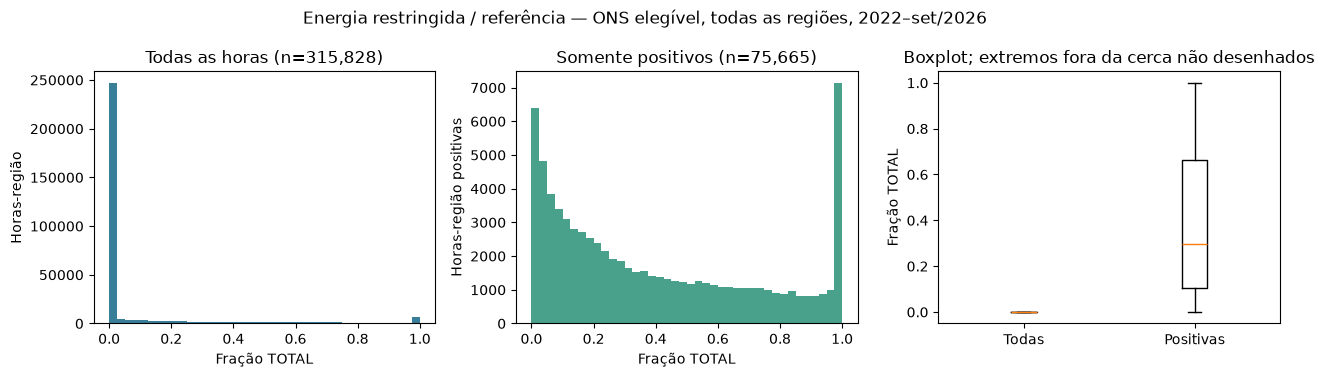

**Severos estão contidos nos positivos; as três linhas não são uma partição**

,grupo,Observações,fracao_do_total
0,zero,240163,0.76042
1,positivo,75665,0.23958
2,"severo ≥0,5",26345,0.08342


In [33]:
frac=energia_base.fraction_total.dropna();positivos=frac[frac>0]
fig,axs=plt.subplots(1,3,figsize=(13,3.8))
axs[0].hist(frac,bins=np.linspace(0,1,41),color='#397e99');axs[0].set(title=f'Todas as horas (n={len(frac):,})',xlabel='Fração TOTAL',ylabel='Horas-região')
axs[1].hist(positivos,bins=np.linspace(0,1,41),color='#49a18b');axs[1].set(title=f'Somente positivos (n={len(positivos):,})',xlabel='Fração TOTAL',ylabel='Horas-região positivas')
axs[2].boxplot([frac,positivos],tick_labels=['Todas','Positivas'],showfliers=False)
axs[2].set(ylabel='Fração TOTAL',title='Boxplot; extremos fora da cerca não desenhados')
fig.suptitle('Energia restringida / referência — ONS elegível, todas as regiões, 2022–set/2026')
fig.tight_layout();figura(fig,'distribuicao_fracao')
tabela(pd.DataFrame({'grupo':['zero','positivo','severo ≥0,5'],
 'n':[frac.eq(0).sum(),len(positivos),frac.ge(.5).sum()],
 'fracao_do_total':[frac.eq(0).mean(),frac.gt(0).mean(),frac.ge(.5).mean()]}),
 'massa_zero','Severos estão contidos nos positivos; as três linhas não são uma partição')

A diferença entre média e mediana e a concentração em zero mostram que a tarefa combina **ocorrência** e **intensidade**. Isso motiva comparar uma regressão direta com um modelo que trate separadamente essas duas partes. A forma da distribuição sugere a comparação, mas não determina antecipadamente qual modelo terá menor erro.

A tabela também identifica horas com fração igual ou superior a 0,5. Nelas, pelo menos metade da energia de referência foi restringida. Esses casos severos estão contidos no grupo de positivos; não constituem uma terceira categoria que possa ser somada às outras duas.

**Prevalência = positivos / rótulos conhecidos, por motivo; 2026 parcial**

,ano,motivo,grade,conhecidos,desconhecidos,Eventos positivos,Frequência de eventos
0,2022,ENE,70080,56936,13144,112,0.00197
1,2022,CNF,70080,56928,13152,936,0.01644
2,2022,REL,70080,56929,13151,502,0.00882
3,2023,ENE,70080,66701,3379,2394,0.03589
4,2023,CNF,70080,66701,3379,1206,0.01808
...,...,...,...,...,...,...,...
10,2025,CNF,70080,69403,677,8850,0.12752
11,2025,REL,70080,69560,520,5764,0.08286
12,2026,ENE,52416,52036,380,15112,0.29041
13,2026,CNF,52416,52125,291,2117,0.04061


*Mostradas as linhas iniciais e finais; a tabela completa, com 15 linhas, é salva em `resultados/tabelas/frequencias_motivos.csv`.*

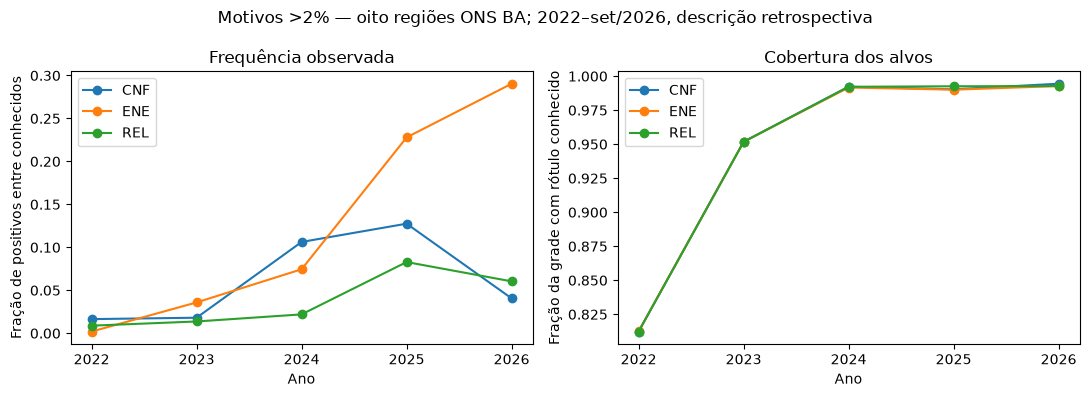

In [34]:
frequencias=[]
for ano,g in base.groupby('year'):
    for r in motivos:
        y=g[f'y_{r}_02']
        frequencias.append({'ano':ano,'motivo':r,'grade':len(g),'conhecidos':y.notna().sum(),
                           'desconhecidos':y.isna().sum(),'positivos':y.eq(1).sum(),
                           'prevalencia':y.mean()})
freq=pd.DataFrame(frequencias)
tabela(freq,'frequencias_motivos','Prevalência = positivos / rótulos conhecidos, por motivo; 2026 parcial')
fig,axs=plt.subplots(1,2,figsize=(11,4))
for r,g in freq.groupby('motivo'):
    axs[0].plot(g.ano,g.prevalencia,marker='o',label=r)
    axs[1].plot(g.ano,g.conhecidos/g.grade,marker='o',label=r)
axs[0].set(ylabel='Fração de positivos entre conhecidos',xlabel='Ano',title='Frequência observada')
axs[1].set(ylabel='Fração da grade com rótulo conhecido',xlabel='Ano',title='Cobertura dos alvos')
for ax in axs:ax.legend();ax.set_xticks(range(2022,2027))
fig.suptitle('Motivos >2% — oito regiões ONS BA; 2022–set/2026, descrição retrospectiva')
fig.tight_layout();figura(fig,'prevalencia_e_cobertura')

### A frequência dos motivos muda ao longo dos anos

A prevalência é a razão entre positivos e rótulos conhecidos. ENE apresenta um aumento acentuado no período, enquanto CNF e REL seguem trajetórias diferentes. Mostrar cobertura e prevalência juntas é importante: mais eventos contados podem refletir mais observações disponíveis, sem necessariamente representar uma frequência maior.

Os motivos não somam 100%, pois podem coexistir e têm conjuntos de rótulos conhecidos ligeiramente diferentes. O ano de 2026 também é parcial, de janeiro a setembro. Essas condições precisam acompanhar a leitura da evolução.

A mudança observada torna pertinente H4: um modelo ajustado somente a anos com poucas restrições pode representar mal um período mais recente. A causa da mudança, porém, não está identificada apenas pelo gráfico; alterações na operação, na frota e na cobertura podem participar dela.

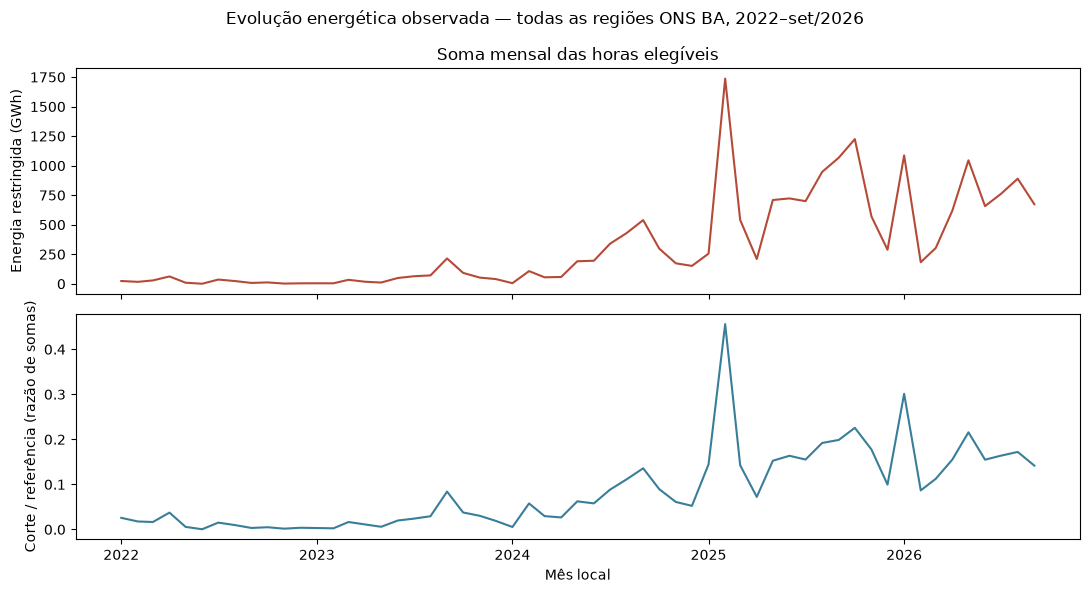

**Valores mensais; somas só incluem horas ONS elegíveis**

,referencia,corte,Horas,fracao_energetica
Hora (Bahia),,,,
2026-02-01 00:00:00-03:00,"2,107,887.43900","182,639.85050",5373,0.08665
2026-03-01 00:00:00-03:00,"2,699,546.02600","303,198.52100",5952,0.11231
2026-04-01 00:00:00-03:00,"3,994,535.71850","619,714.70400",5754,0.15514
2026-05-01 00:00:00-03:00,"4,847,886.72000","1,045,210.65650",5951,0.21560
2026-06-01 00:00:00-03:00,"4,247,633.99650","657,684.60700",5759,0.15484
2026-07-01 00:00:00-03:00,"4,652,596.05350","762,320.57200",5949,0.16385
2026-08-01 00:00:00-03:00,"5,173,400.79500","890,069.93700",5952,0.17205
2026-09-01 00:00:00-03:00,"4,754,077.68450","673,388.08400",5755,0.14164


In [35]:
mensal_energia=energia_base.set_index('time_local').resample('MS').agg(referencia=('reference_mwh','sum'),corte=('cut_total_mwh','sum'),horas=('fraction_total','count'))
mensal_energia['fracao_energetica']=mensal_energia.corte/mensal_energia.referencia
fig,axs=plt.subplots(2,1,figsize=(11,6),sharex=True)
axs[0].plot(mensal_energia.index,mensal_energia.corte/1000,color='#b64a38');axs[0].set(ylabel='Energia restringida (GWh)',title='Soma mensal das horas elegíveis')
axs[1].plot(mensal_energia.index,mensal_energia.fracao_energetica,color='#397e99');axs[1].set(ylabel='Corte / referência (razão de somas)',xlabel='Mês local')
fig.suptitle('Evolução energética observada — todas as regiões ONS BA, 2022–set/2026')
fig.tight_layout();figura(fig,'energia_mensal')
tabela(mensal_energia.tail(8),'energia_mensal_recente','Valores mensais; somas só incluem horas ONS elegíveis')

### Comparação de anos com uma composição de conjuntos mais estável

Os totais de energia podem aumentar porque mais conjuntos passaram a ser observados. Para examinar parte desse efeito, utilizamos também uma **coorte**, isto é, um grupo de unidades mantido comparável ao longo dos anos.

O controle reúne 15 conjuntos de três regiões e compara as mesmas combinações de região, dia do calendário e hora entre janeiro e 24 de março de 2022, 2024, 2025 e 2026. Permanecem apenas as observações em que todos os membros necessários estão presentes. Os resultados desse controle estão incluídos no pacote; sua reconstrução exige os registros semihorários dos anos comparados.

Esse recorte reduz uma diferença de composição, mas seleciona conjuntos com boa continuidade observacional. Não representa toda a Bahia nem elimina outras mudanças nas fontes ou na operação.

**Restrições na coorte com composição comparável entre anos**

,Motivo,Ano,n_matched_hours,positive,Frequência de eventos,cohort_units,regions
0,ENE,2022,1156,0,0.00000,15,3
1,ENE,2024,1156,9,0.00779,15,3
2,ENE,2025,1156,80,0.06920,15,3
3,ENE,2026,1156,209,0.18080,15,3
4,CNF,2022,1158,36,0.03109,15,3
5,CNF,2024,1158,8,0.00691,15,3
6,CNF,2025,1158,4,0.00345,15,3
7,CNF,2026,1158,119,0.10276,15,3
8,REL,2022,1155,0,0.00000,15,3
9,REL,2024,1155,0,0.00000,15,3


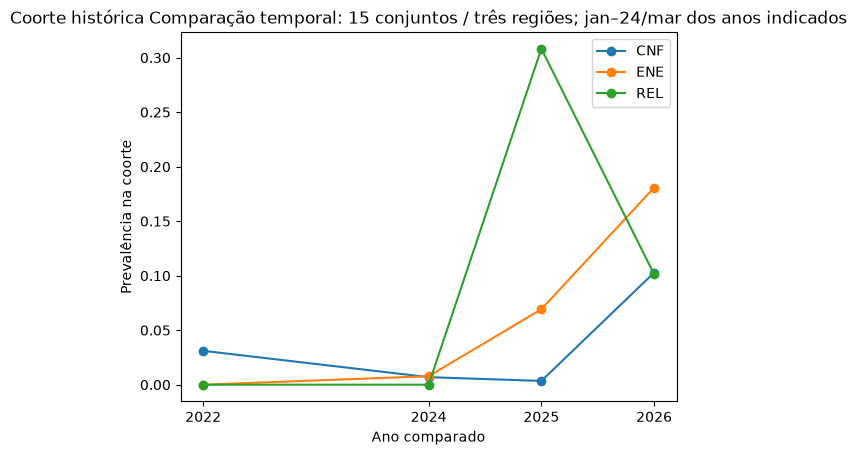

In [36]:
coorte=pd.read_csv(ROOT/'dados/prevalencia_coorte.csv')
tabela(coorte[['reason','year','n_matched_hours','positive','prevalence','cohort_units','regions']],
       'coorte_historica','Controle de composição: mesmos conjuntos e posições de calendário nos anos comparados')
fig,ax=plt.subplots()
for r,g in coorte.groupby('reason'):ax.plot(g.year,g.prevalence,marker='o',label=r)
ax.set(xlabel='Ano comparado',ylabel='Prevalência na coorte',title='Coorte histórica Comparação temporal: 15 conjuntos / três regiões; jan–24/mar dos anos indicados')
ax.set_xticks(sorted(coorte.year.unique()));ax.legend();figura(fig,'coorte_comparavel')

ENE passa de zero para **209 positivos em 1.156 observações comparáveis** entre 2022 e 2026. Assim, o aumento não desaparece ao manter esse grupo de conjuntos e as mesmas posições do calendário. O resultado reforça a importância de examinar atualização temporal, sem identificar por si só a causa do aumento.

### Padrões por hora, mês e região

Além de mudar entre anos, a frequência pode variar dentro do dia e do ano. Os mapas seguintes mostram a prevalência por **região e hora** e por **região e mês**, utilizando 2022–2024. Cada célula divide os positivos pelos rótulos conhecidos naquela combinação.

Se o perfil horário diferir entre regiões, um efeito de hora único para toda a base será uma representação restritiva. Essa observação motiva atributos de interação: o modelo poderá aprender um padrão de hora específico de cada região.

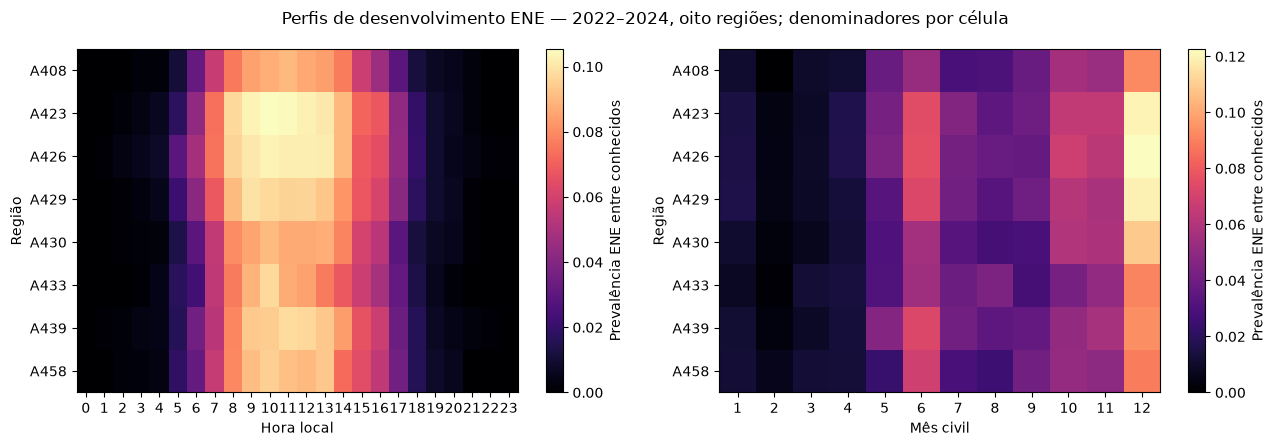

,Horas,Eventos positivos,Frequência de eventos
Região,,,
A408,25948,918.00000,0.03538
A423,26163,"1,166.00000",0.04457
A426,26172,"1,180.00000",0.04509
A429,23722,"1,029.00000",0.04338
A430,25946,940.00000,0.03623
A433,19799,692.00000,0.03495
A439,25945,"1,022.00000",0.03939
A458,19628,749.00000,0.03816


In [37]:
dev=base[base.year.le(2024)].copy()
dev['mes_civil']=dev.time_local.dt.month
perfil_hora=dev.pivot_table(index='region',columns='hour',values='y_ENE_02',aggfunc='mean')
perfil_mes=dev.pivot_table(index='region',columns='mes_civil',values='y_ENE_02',aggfunc='mean')
fig,axs=plt.subplots(1,2,figsize=(13,4.5))
for ax,mat,xlab in [(axs[0],perfil_hora,'Hora local'),(axs[1],perfil_mes,'Mês civil')]:
    im=ax.imshow(mat,aspect='auto',vmin=0,cmap='magma')
    ax.set_yticks(range(len(mat)),mat.index);ax.set_xticks(range(len(mat.columns)),mat.columns)
    ax.set(xlabel=xlab,ylabel='Região');fig.colorbar(im,ax=ax,label='Prevalência ENE entre conhecidos')
fig.suptitle('Perfis de desenvolvimento ENE — 2022–2024, oito regiões; denominadores por célula')
fig.tight_layout();figura(fig,'perfis_calendario')
tabela(dev.groupby('region').agg(horas=('y_ENE_02','count'),positivos=('y_ENE_02','sum'),prevalencia=('y_ENE_02','mean')),
       'frequencia_regiao_treino')

In [38]:
episodios=[]
for r,g in dev.sort_values('time_local').groupby('region'):
    y=g.set_index('time_local').y_ENE_02
    # A grade é regular; NaN quebra episódios e preserva a censura.
    positivo=y.eq(1);blocos=positivo.ne(positivo.shift()).cumsum()
    for _,run in positivo[positivo].groupby(blocos[positivo]):
        inicio,fim=run.index.min(),run.index.max()
        anterior=y.get(inicio-pd.Timedelta(hours=1),np.nan)
        posterior=y.get(fim+pd.Timedelta(hours=1),np.nan)
        episodios.append({'regiao':r,'duracao_h':len(run),'censura_inicio':pd.isna(anterior),'censura_fim':pd.isna(posterior)})
ep=pd.DataFrame(episodios)
tabela(ep.groupby('regiao').agg(episodios=('duracao_h','size'),mediana_h=('duracao_h','median'),
  maximo_h=('duracao_h','max'),inicio_censurado=('censura_inicio','sum'),fim_censurado=('censura_fim','sum')),
 'episodios_treino','Episódios ENE observados em 2022–2024; não atravessam horas desconhecidas')

**Episódios ENE observados em 2022–2024; não atravessam horas desconhecidas**

,episodios,mediana_h,maximo_h,inicio_censurado,fim_censurado
Região,,,,,
A408,143,7.00000,15,13,3
A423,134,9.00000,17,19,5
A426,137,9.00000,17,20,7
A429,151,7.00000,16,19,5
A430,141,7.00000,16,13,3
A433,154,3.00000,15,12,4
A439,143,7.00000,16,15,4
A458,160,3.50000,15,6,3


### O que a EDA indica para a previsão

Os perfis apresentam concentração de ENE em horas diurnas, especialmente próximas ao meio do dia, e diferenças sazonais entre regiões. **Há estrutura que um modelo de calendário pode aproveitar sem receber meteorologia.** Essa é a motivação empírica de H1 e a razão para utilizar uma referência de calendário forte ao testar H2.

A tabela de episódios acrescenta uma dimensão: várias horas positivas podem pertencer à mesma ocorrência prolongada. Logo, muitas linhas não significam muitos eventos independentes. Uma borda é marcada como censurada quando não conhecemos a hora anterior ou posterior e, portanto, não podemos determinar o começo ou o fim com segurança.

Essas observações orientam o desenho da análise: representar ciclos e diferenças regionais, respeitar o tempo na validação, examinar erros por intensidade e levar a dependência entre horas em conta na incerteza. O calendário resume regularidades; ele não explica necessariamente o mecanismo elétrico que as produz.

<a id="secao-9"></a>

## 9. Análise exploratória das medições meteorológicas

### O que cada variável acrescenta à descrição

O vento descreve o nível de velocidade observado; a rajada, um extremo em sua janela de medição. Temperatura, umidade e pressão fornecem contexto atmosférico, com unidades e coberturas próprias. Antes de combinar essas variáveis, precisamos entender suas distribuições.

Nesta seção, analisamos **observações estação × hora** de 2022–2024, nas estações utilizadas na associação meteorológica. Não são ainda médias regionais ponderadas: cada registro corresponde a um sensor em um instante. Essa distinção evita interpretar uma distribuição de estações como se fosse diretamente a distribuição do vento de todos os conjuntos eólicos.

**Estatísticas meteorológicas — 2022–2024**

,Observações,Ausentes,Média,Mediana,q1,q3,p95,Desvio padrão,IQR,DMA
Variável,,,,,,,,,,
Vento (m/s),383487,177657,2.16082,2.00000,0.90000,3.10000,5.00000,1.56944,2.20000,1.26419
Rajada (m/s),382514,178630,5.40795,5.30000,3.10000,7.40000,10.30000,2.88690,4.30000,2.36767
Temperatura (°C),394573,166571,25.21597,24.80000,21.90000,28.70000,33.50000,4.79826,6.80000,3.90749
Umidade (%),368677,192467,65.18056,66.00000,49.00000,83.00000,96.00000,21.02846,34.00000,17.87658
Pressão (hPa),394601,166543,956.72441,963.50000,951.70000,973.50000,991.30000,28.96504,21.80000,20.56648


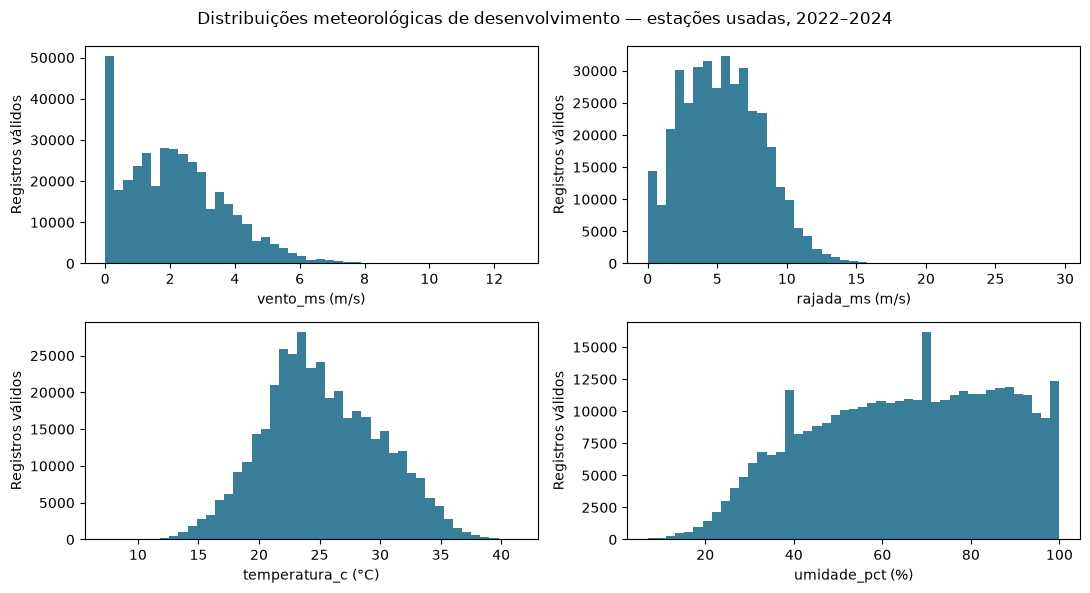

In [39]:
sensores=set(mapping.station)
wdev=weather[weather.ano.le(2024)&weather.station.isin(sensores)].copy()
wm=apoio.descrever(wdev,['vento_ms','rajada_ms','temperatura_c','umidade_pct','pressure_hpa'])
tabela(wm[['n','ausentes','media','mediana','q1','q3','p95','desvio','IQR','DMA']],
       'estatisticas_meteorologia','Estações meteorológicas, 2022–2024; m/s, m/s, °C, %, hPa')
fig,axs=plt.subplots(2,2,figsize=(11,6))
for ax,col,un in zip(axs.flat,['vento_ms','rajada_ms','temperatura_c','umidade_pct'],['m/s','m/s','°C','%']):
    ax.hist(wdev[col].dropna(),bins=45,color='#397e99');ax.set(xlabel=f'{col} ({un})',ylabel='Registros válidos')
fig.suptitle('Distribuições meteorológicas de desenvolvimento — estações usadas, 2022–2024')
fig.tight_layout();figura(fig,'distribuicoes_meteorologicas')

Vento e rajada se concentram em valores menores e apresentam caudas à direita. Temperatura e umidade têm outros limites e formatos. Comparar seus desvios padrão sem considerar as unidades seria inadequado: um desvio de 2 m/s e um de 2 °C não representam o mesmo tipo de variação.

O número de medições válidas também muda entre colunas. Para descrever uma variável, usamos seus valores disponíveis. Para comparar variáveis em uma mesma matriz de correlação, usaremos um conjunto comum de observações, evitando que a população mude de um par para outro.

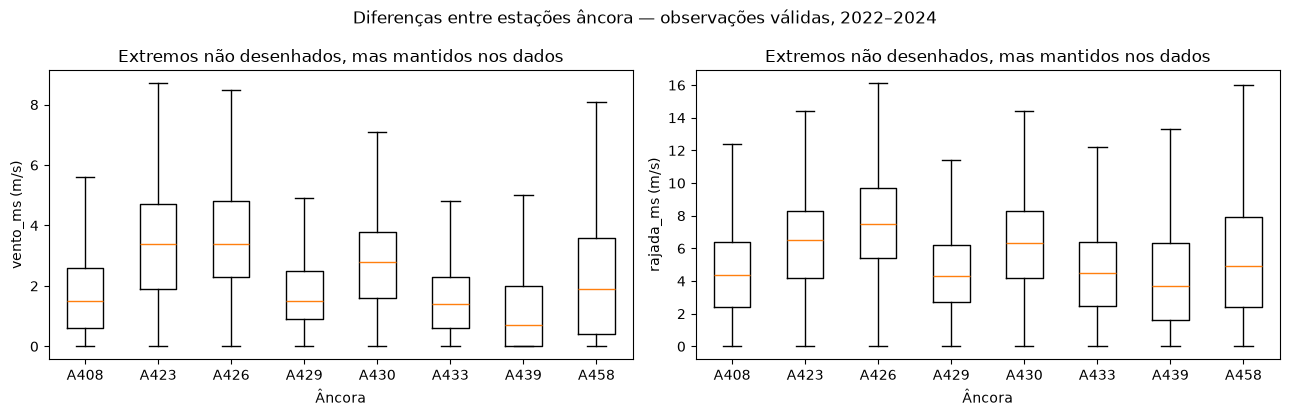

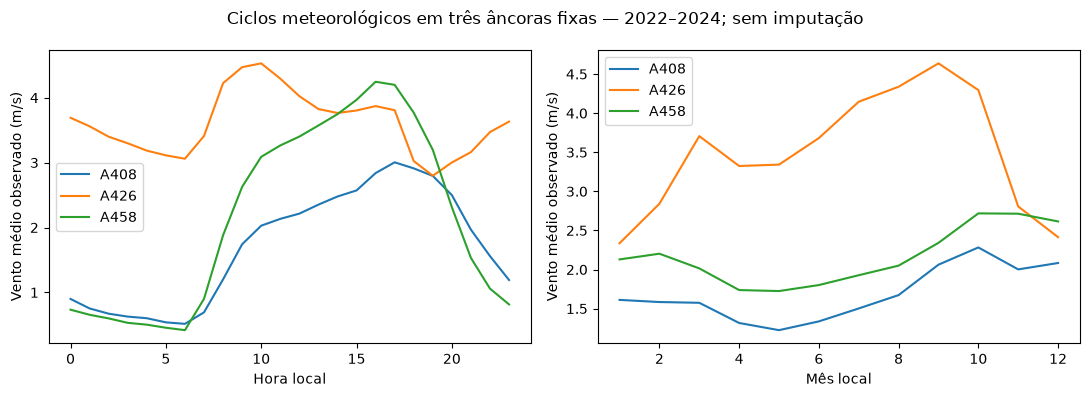

In [40]:
fig,axs=plt.subplots(1,2,figsize=(13,4.2))
for ax,col,un in [(axs[0],'vento_ms','m/s'),(axs[1],'rajada_ms','m/s')]:
    grupos=[wdev.loc[wdev.station.eq(s),col].dropna() for s in ancoras]
    ax.boxplot(grupos,tick_labels=ancoras,showfliers=False)
    ax.set(ylabel=f'{col} ({un})',xlabel='Âncora',title='Extremos não desenhados, mas mantidos nos dados')
fig.suptitle('Diferenças entre estações âncora — observações válidas, 2022–2024')
fig.tight_layout();figura(fig,'boxplots_estacoes')
wdev['hora_local']=wdev.time_utc.dt.tz_convert(tz).dt.hour
wdev['mes_local']=wdev.time_utc.dt.tz_convert(tz).dt.month
fig,axs=plt.subplots(1,2,figsize=(11,4))
for s in ['A408','A426','A458']:
    g=wdev[wdev.station.eq(s)]
    axs[0].plot(g.groupby('hora_local').vento_ms.mean(),label=s)
    axs[1].plot(g.groupby('mes_local').vento_ms.mean(),label=s)
axs[0].set(xlabel='Hora local',ylabel='Vento médio observado (m/s)')
axs[1].set(xlabel='Mês local',ylabel='Vento médio observado (m/s)')
for ax in axs:ax.legend()
fig.suptitle('Ciclos meteorológicos em três âncoras fixas — 2022–2024; sem imputação')
fig.tight_layout();figura(fig,'ciclos_meteorologicos')

### Diferenças locais e ciclos meteorológicos

A426 apresenta velocidades médias maiores que A408 nos perfis exibidos. A408 e A458 têm mínimos no começo da manhã e crescimento à tarde, enquanto A426 apresenta outro padrão diário. Portanto, uma distribuição média de todas as estações pode esconder diferenças locais importantes.

Esses perfis ajudam a entender duas possibilidades. Parte da meteorologia acompanha o calendário e pode ser redundante com seus atributos. Outra parte varia **dentro da mesma hora e época**, podendo acrescentar informação sobre condições particulares. Médias móveis, rampas e variabilidade recente procuram representar essa segunda dimensão.

As médias são calculadas nas medições disponíveis, sem imputação. Diferenças de cobertura podem participar dos perfis; por isso, sua interpretação deve considerar os diagnósticos de ausência.

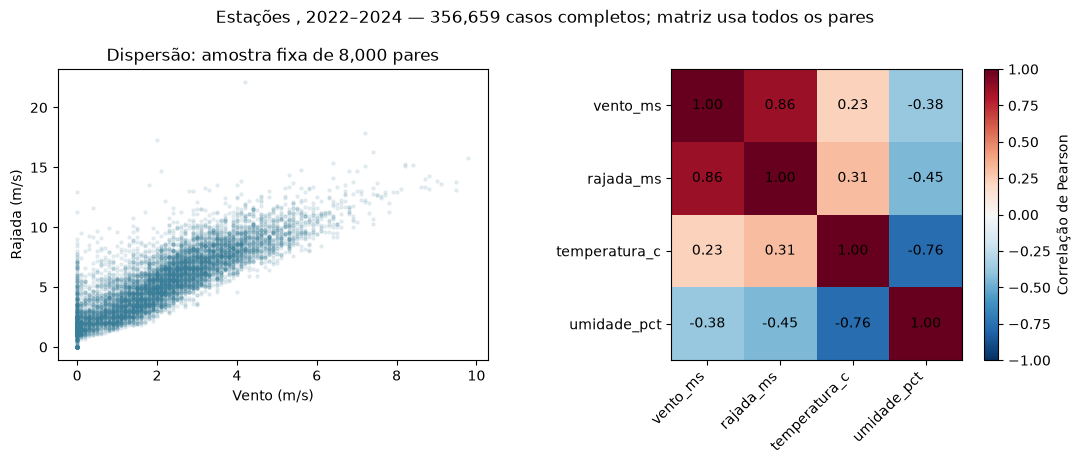

**Coobservações UTC; não é correlação de séries sem alinhamento**

,estacoes,n_simultaneo,Pearson,Spearman
0,A424/A425,12281,0.37917,0.36735


In [41]:
pares=wdev[['vento_ms','rajada_ms','temperatura_c','umidade_pct']].dropna()
corrmet=pares.corr()
fig,axs=plt.subplots(1,2,figsize=(11,4.5))
amostra=pares.sample(min(8000,len(pares)),random_state=SEED)
axs[0].scatter(amostra.vento_ms,amostra.rajada_ms,s=5,alpha=.1,color='#397e99')
axs[0].set(xlabel='Vento (m/s)',ylabel='Rajada (m/s)',title=f'Dispersão: amostra fixa de {len(amostra):,} pares')
im=axs[1].imshow(corrmet,vmin=-1,vmax=1,cmap='RdBu_r')
axs[1].set_xticks(range(4),corrmet.columns,rotation=45,ha='right');axs[1].set_yticks(range(4),corrmet.index)
for i in range(4):
    for j in range(4):axs[1].text(j,i,f'{corrmet.iloc[i,j]:.2f}',ha='center',va='center')
fig.colorbar(im,ax=axs[1],label='Correlação de Pearson')
fig.suptitle(f'Estações V2, 2022–2024 — {len(pares):,} casos completos; matriz usa todos os pares')
fig.tight_layout();figura(fig,'relacoes_meteorologicas')
dupla=mat_vento.loc[mat_vento.index.year<=2024,['A424','A425']].dropna()
tabela(pd.DataFrame([{'estacoes':'A424/A425','n_simultaneo':len(dupla),
                      'Pearson':dupla.A424.corr(dupla.A425),'Spearman':dupla.A424.corr(dupla.A425,method='spearman')}]),
       'correlacao_entre_estacoes','Coobservações UTC; não é correlação de séries sem alinhamento')

A relação vento–rajada é forte, mas não perfeita. Isso sugere redundância parcial, não que uma variável seja dispensável em qualquer modelo. Uma rajada pode diferenciar duas observações com velocidade média semelhante. A regularização e as comparações de grupos de atributos ajudam a avaliar esse tipo de situação.

A comparação entre A424 e A425 utiliza medições simultâneas. Correlacionar séries sem alinhar seus instantes não mediria o mesmo fenômeno. Mesmo alinhada, uma correlação alta indica covariação entre estações de superfície, não qual delas reproduz melhor o vento das turbinas.

Para a leitura multivariada, priorizamos dispersões, mapas de correlação e projeção PCA. Eles preservam eixos quantitativos e facilitam comparar grandezas. Representações por faces ou polígonos podem resumir muitos atributos, mas não acrescentam aqui uma leitura física tão direta.

<a id="secao-10"></a>

## 10. Relações entre meteorologia e restrições

### Associação observada e informação adicional para previsão

Agora relacionamos meteorologia e energia na mesma observação região × hora. Usamos principalmente dados de 2022–2024 e medições disponíveis antes da hora-alvo. O vento identificado como `wind_lag1` corresponde, nesta base, à medição de duas horas antes do alvo; o significado das defasagens será detalhado na seção 12.

A **covariância** mede se duas variáveis tendem a crescer ou diminuir juntas, mas depende das unidades. A correlação de **Pearson** a divide pelos desvios padrão, produzindo uma medida adimensional de associação linear. **Spearman** utiliza os postos dos valores e descreve associação monotônica, que pode não ser linear.

$$\operatorname{corr}_{\mathrm{Pearson}}(x,y)=\frac{\operatorname{cov}(x,y)}{s_xs_y}.$$

Uma correlação pequena não prova ausência de qualquer relação. E uma correlação alta não demonstra informação adicional ao calendário: vento e restrições podem compartilhar ciclos horários e sazonais. A EDA descreve a associação; a comparação preditiva entre modelos avaliará o incremento meteorológico.

In [42]:
cols=['wind_lag1','gust_lag1','temperatura_c_lag2','fraction_total']
rel=dev[cols].dropna()
cov=rel.cov();pearson=rel.corr();spearman=rel.corr(method='spearman')
tabela(cov,'covariancia','Mesmos casos completos: vento/rajada m/s, temperatura °C, fração TOTAL adimensional')
tabela(pearson,'pearson',f'Pearson, n={len(rel):,}; região×hora, 2022–2024')
tabela(spearman,'spearman',f'Spearman, mesma máscara e período')
np.testing.assert_allclose(np.diag(cov),rel.var(ddof=1))

**Mesmos casos completos: vento/rajada m/s, temperatura °C, fração TOTAL adimensional**

,Vento admissível (m/s),Rajada admissível (m/s),temperatura_c_lag2,Fração restringida
Vento admissível (m/s),3.06669,4.67466,1.80510,0.02415
Rajada admissível (m/s),4.67466,9.58415,4.08371,0.04130
temperatura_c_lag2,1.80510,4.08371,24.72213,-0.00908
Fração restringida,0.02415,0.04130,-0.00908,0.02013


**Pearson, n=172,247; região×hora, 2022–2024**

,Vento admissível (m/s),Rajada admissível (m/s),temperatura_c_lag2,Fração restringida
Vento admissível (m/s),1.00000,0.86226,0.20731,0.09719
Rajada admissível (m/s),0.86226,1.00000,0.26530,0.09402
temperatura_c_lag2,0.20731,0.26530,1.00000,-0.01287
Fração restringida,0.09719,0.09402,-0.01287,1.00000


**Spearman, mesma máscara e período**

,Vento admissível (m/s),Rajada admissível (m/s),temperatura_c_lag2,Fração restringida
Vento admissível (m/s),1.00000,0.86763,0.26743,0.13542
Rajada admissível (m/s),0.86763,1.00000,0.32280,0.12866
temperatura_c_lag2,0.26743,0.32280,1.00000,-0.00810
Fração restringida,0.13542,0.12866,-0.00810,1.00000


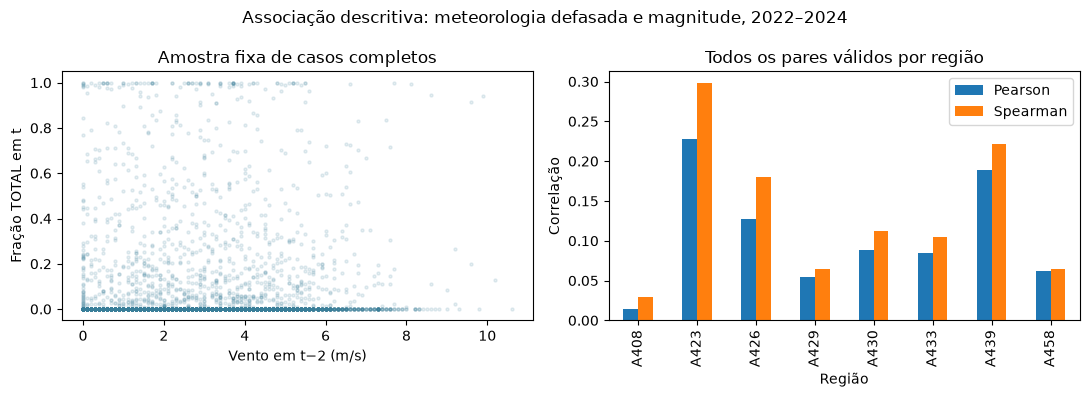

,Observações,Pearson,Spearman
Região,,,
A408,24577,0.01391,0.02923
A423,19509,0.22821,0.29790
A426,20947,0.12756,0.17983
A429,18848,0.05440,0.06509
A430,24696,0.08881,0.11195
A433,19723,0.08493,0.10528
A439,25382,0.18947,0.22093
A458,18777,0.06214,0.06422


**Controle descritivo no mesmo conjunto de linhas de 2022–2024; não entra no modelo**

,entrada,Observações,Pearson
0,vento contemporâneo t (indisponível na emissão),170160,0.14718
1,vento admissível t−2,170160,0.09936


In [43]:
fig,axs=plt.subplots(1,2,figsize=(11,4))
a=rel.sample(min(10000,len(rel)),random_state=SEED)
axs[0].scatter(a.wind_lag1,a.fraction_total,s=5,alpha=.12,color='#397e99')
axs[0].set(xlabel='Vento em t−2 (m/s)',ylabel='Fração TOTAL em t',title='Amostra fixa de casos completos')
por_regiao=[]
for r,g in dev.groupby('region'):
    d=g[['wind_lag1','fraction_total']].dropna()
    por_regiao.append({'regiao':r,'n':len(d),'Pearson':d.wind_lag1.corr(d.fraction_total),
                       'Spearman':d.wind_lag1.corr(d.fraction_total,method='spearman')})
cr=pd.DataFrame(por_regiao).set_index('regiao')
cr[['Pearson','Spearman']].plot.bar(ax=axs[1]);axs[1].set(ylabel='Correlação',xlabel='Região',title='Todos os pares válidos por região')
fig.suptitle('Associação descritiva: meteorologia defasada e magnitude, 2022–2024')
fig.tight_layout();figura(fig,'vento_fracao')
tabela(cr,'correlacao_regional')
contemp=dev[['vento_ms','wind_lag1','fraction_total']].dropna()
tabela(pd.DataFrame({'entrada':['vento contemporâneo t (indisponível na emissão)','vento admissível t−2'],
 'n':[len(contemp)]*2,'Pearson':[contemp.vento_ms.corr(contemp.fraction_total),
                               contemp.wind_lag1.corr(contemp.fraction_total)]}),
 'associacao_contemporanea','Controle descritivo no mesmo conjunto de linhas de 2022–2024; não entra no modelo')

A nuvem de pontos combina muitas horas sem corte com uma ampla faixa de magnitudes positivas. Por isso, uma única correlação resume apenas parte da relação. Os resultados separados por região também mostram que misturar locais pode esconder associações diferentes.

O controle contemporâneo compara o vento da própria hora-alvo com o vento defasado, usando as mesmas linhas. Ele é útil para descrever a sensibilidade da associação ao tempo. **O vento contemporâneo não será fornecido ao modelo de previsão**, porque não estaria disponível no instante em que a previsão é emitida.

In [44]:
faixas=[0,2,4,6,8,np.inf]
relmot=dev[['region','time_local','hour','wind_lag1']+[f'y_{r}_02' for r in motivos]].copy()
relmot['faixa_vento']=pd.cut(relmot.wind_lag1,faixas,right=False)
tabfaixas=[]
for r in motivos:
    g=relmot.dropna(subset=['faixa_vento',f'y_{r}_02']).groupby('faixa_vento',observed=True)[f'y_{r}_02'].agg(['size','mean'])
    for faixa,row in g.iterrows():tabfaixas.append({'motivo':r,'faixa_ms':str(faixa),'n':int(row['size']),'prevalencia':row['mean']})
tabela(pd.DataFrame(tabfaixas),'prevalencia_faixas','Intervalos fixos antes da avaliação; denominador próprio de cada motivo/faixa')
# Condicionamento descritivo: comparação dentro de região e hora, sem treinar preditor.
cond=dev[['region','hour','wind_lag1','fraction_total']].dropna().copy()
for col in ['wind_lag1','fraction_total']:
    cond[col+'_centrado']=cond[col]-cond.groupby(['region','hour'])[col].transform('mean')
tabela(pd.DataFrame({'associação':['marginal','após centrar por região×hora'],
 'Pearson':[cond.wind_lag1.corr(cond.fraction_total),cond.wind_lag1_centrado.corr(cond.fraction_total_centrado)]}),
 'associacao_condicionada','Diagnóstico no desenvolvimento; centrar não controla todos os confundidores')

**Intervalos fixos antes da avaliação; denominador próprio de cada motivo/faixa**

,motivo,faixa_ms,Observações,Frequência de eventos
0,ENE,"[0.0, 2.0)",84127,0.02872
1,ENE,"[2.0, 4.0)",58461,0.04516
2,ENE,"[4.0, 6.0)",24654,0.06015
3,ENE,"[6.0, 8.0)",4585,0.08113
4,ENE,"[8.0, inf)",504,0.04762
...,...,...,...,...
10,REL,"[0.0, 2.0)",84138,0.00913
11,REL,"[2.0, 4.0)",58469,0.01329
12,REL,"[4.0, 6.0)",24655,0.02811
13,REL,"[6.0, 8.0)",4590,0.04967


*Mostradas as linhas iniciais e finais; a tabela completa, com 15 linhas, é salva em `resultados/tabelas/prevalencia_faixas.csv`.*

**Diagnóstico no desenvolvimento; centrar não controla todos os confundidores**

,associação,Pearson
0,marginal,0.09817
1,após centrar por região×hora,0.11270


A frequência por faixas de vento torna a relação mais fácil de ler, mas perde diferenças dentro de cada intervalo. Faixas com poucas observações devem ser interpretadas com cuidado, e a composição de regiões e horários pode variar entre elas.

O ajuste descritivo por grupos de calendário retira parte do perfil médio compartilhado. A associação restante não é uma estimativa causal: fatores operacionais não observados ainda podem afetar os dois lados da relação. O objetivo é verificar se uma correlação marginal estava resumindo sobretudo ciclos conhecidos, não descobrir uma causa elétrica a partir de uma única tabela.

Essa análise leva a uma pergunta complementar de EDA: **as distribuições de vento são diferentes entre horas que ultrapassam e que não ultrapassam o limiar de ENE?**

### Distribuição do vento em horas com ENE acima e até 2%

Comparamos dois grupos de 2022–2024: horas com **ENE > 2%** e horas com **ENE ≤ 2%**, sempre com referência positiva, alvo conhecido e vento da âncora disponível em $t-2$. Não imputamos vento para esse teste.

O grupo negativo não significa ausência de toda restrição: ele pode conter ENE pequeno ou cortes por CNF e REL. Essa definição deve permanecer clara porque é a mesma distinção feita pelo classificador de ENE.

Primeiro mostramos tamanhos, médias, medianas e quartis. Depois aplicamos o teste de Mann–Whitney e calculamos um tamanho de efeito. A visualização e o efeito são importantes: uma diferença estatisticamente detectável pode coexistir com grande sobreposição entre os grupos.

In [45]:
mw_inicio=pd.Timestamp('2022-01-01',tz=tz)
mw_fim=pd.Timestamp('2025-01-01',tz=tz)
mw_desenvolvimento=base[base.time_local.ge(mw_inicio)&base.time_local.lt(mw_fim)]
mw_alvo=(mw_desenvolvimento.ons_eligible & mw_desenvolvimento.reference_mwh.gt(0)
         & mw_desenvolvimento.y_ENE_02.isin([0,1]))
mw_vento=np.isfinite(mw_desenvolvimento.wind_lag1)&mw_desenvolvimento.wind_lag1.ge(0)
mw= mw_desenvolvimento.loc[mw_alvo&mw_vento,['region','time_local','wind_lag1','y_ENE_02']].copy()
assert not mw.duplicated(['region','time_local']).any() and mw.region.nunique()==8
assert mw.time_local.lt(mw_fim).all() and mw.notna().all().all()
nomes_mw={0:'ENE ≤2% (negativo)',1:'ENE >2% (positivo)'}
grupo1=mw.loc[mw.y_ENE_02.eq(1),'wind_lag1'].to_numpy()
grupo0=mw.loc[mw.y_ENE_02.eq(0),'wind_lag1'].to_numpy()
tabela(pd.DataFrame([{'grade_desenvolvimento':len(mw_desenvolvimento),'alvos_admissiveis':int(mw_alvo.sum()),
 'excluidos_apos_alvo_por_vento':int((mw_alvo&~mw_vento).sum()),'pares_validos':len(mw),
 'regioes':mw.region.nunique(),'inicio_alvo':str(mw.time_local.min()),'fim_alvo':str(mw.time_local.max())}]),
 'mw_elegibilidade','Mann–Whitney: seleção cumulativa somente nesta análise; 2022–2024, âncora t−2')
descritivas_mw=[]
for classe,g in mw.groupby('y_ENE_02'):
    x=g.wind_lag1;q=x.quantile([.25,.5,.75])
    descritivas_mw.append({'grupo':nomes_mw[int(classe)],'n':len(x),'media_ms':x.mean(),
      'Q1_ms':q.loc[.25],'mediana_ms':q.loc[.5],'Q3_ms':q.loc[.75],
      'desvio_amostral_ms':x.std(ddof=1),'IQR_ms':q.loc[.75]-q.loc[.25]})
descritivas_mw=pd.DataFrame(descritivas_mw).set_index('grupo')
tabela(descritivas_mw,'mw_descritivas','Vento real em m/s; cada região×hora elegível tem peso igual; sem imputação')
texto(f"São **{len(grupo1):,}** positivos e **{len(grupo0):,}** negativos. A retirada de vento ausente/inválido "
      f"exclui **{int((mw_alvo&~mw_vento).sum()):,}** linhas após a elegibilidade do alvo. "
      "As diferenças de n e de cobertura não são corrigidas pelo teste; elas delimitam a população estudada.")

**Mann–Whitney: seleção cumulativa somente nesta análise; 2022–2024, âncora t−2**

,grade_desenvolvimento,alvos_admissiveis,excluidos_apos_alvo_por_vento,pares_validos,regioes,inicio_alvo,fim_alvo
0,210432,193323,20992,172331,8,2022-01-01 00:00:00-03:00,2024-12-31 23:00:00-03:00


**Vento real em m/s; cada região×hora elegível tem peso igual; sem imputação**

,Observações,media_ms,Q1_ms,mediana_ms,Q3_ms,desvio_amostral_ms,IQR_ms
grupo,,,,,,,
ENE ≤2% (negativo),165396,2.20515,0.80000,2.00000,3.30000,1.74351,2.50000
ENE >2% (positivo),6935,2.83837,1.40000,2.70000,4.10000,1.84045,2.70000


São **6,935** positivos e **165,396** negativos. A retirada de vento ausente/inválido exclui **20,992** linhas após a elegibilidade do alvo. As diferenças de n e de cobertura não são corrigidas pelo teste; elas delimitam a população estudada.

### Comparação por postos e tamanho do efeito

O teste de Mann–Whitney ordena conjuntamente os valores dos dois grupos. Sua estatística $U$ pode ser entendida como a contagem de pares em que o vento do grupo positivo supera o do negativo, atribuindo meio ponto aos empates:

$$U=\sum_{i=1}^{n_1}\sum_{j=1}^{n_0}\left[\mathbb{1}(v_{1i}>v_{0j})+\tfrac12\mathbb{1}(v_{1i}=v_{0j})\right].$$

Não é necessário gerar todos os pares no computador: o cálculo por postos é eficiente. A razão $U/(n_1n_0)$ resume a superioridade empírica com empates ponderados. Usamos também o **delta de Cliff**,

$$\delta=\frac{2U}{n_1n_0}-1.$$

Nesta orientação, $\delta>0$ indica vento tendendo a ser maior no grupo ENE > 2%. Por exemplo, uma superioridade ponderada de 60% corresponde a $\delta=0,20$. Isso **não** significa vento 20% mais veloz: é uma medida de ordenação dos valores.

O teste bilateral convencional pressupõe amostras independentes e examina uma diferença nas distribuições por postos. Ele não é, em geral, um teste exclusivo de igualdade de medianas; essa interpretação exige condições adicionais sobre a forma das distribuições. Calculamos o p-valor nominal, mas consideraremos a dependência temporal antes de interpretá-lo [5].

**Mann–Whitney bilateral; U do grupo ENE >2%; p nominal sob independência, efeito adimensional**

,n_positivo,n_negativo,U_positivo,p_nominal,superioridade_com_empates,delta_positivo_menos_negativo
0,6935,165396,"690,687,709.50000",1.128342e-183,0.60216,0.20432


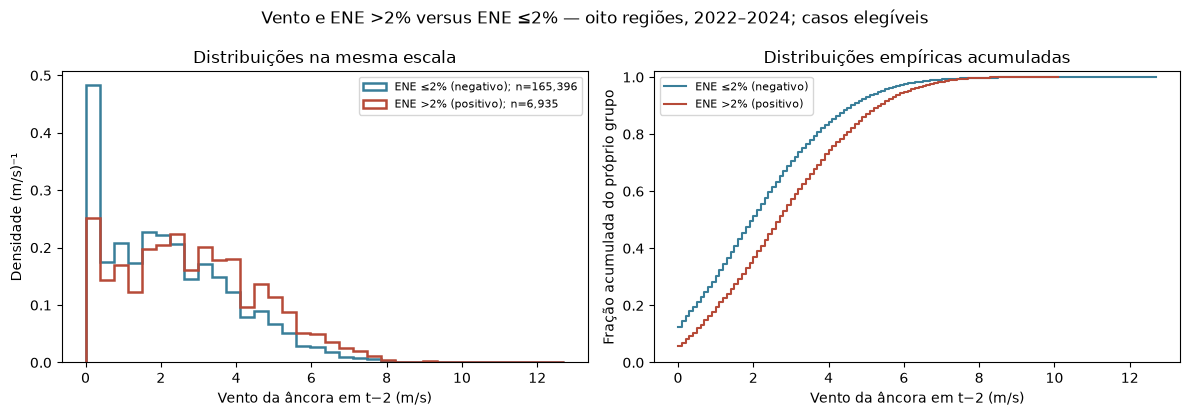

In [46]:
from scipy.stats import mannwhitneyu
resultado_mw=mannwhitneyu(grupo1,grupo0,alternative='two-sided',method='asymptotic',
                         use_continuity=True,nan_policy='raise')
superioridade_mw=float(resultado_mw.statistic/(len(grupo1)*len(grupo0)))
delta_mw=2*superioridade_mw-1
resumo_mw={'n_positivo':len(grupo1),'n_negativo':len(grupo0),'U_positivo':float(resultado_mw.statistic),
           'p_nominal':float(resultado_mw.pvalue),'superioridade_com_empates':superioridade_mw,
           'delta_positivo_menos_negativo':delta_mw}
# A notação científica evita que a apresentação arredonde um p pequeno para zero.
tabela(pd.DataFrame([{**resumo_mw,'p_nominal':f'{resultado_mw.pvalue:.6e}'}]),'mw_resultado',
 'Mann–Whitney bilateral; U do grupo ENE >2%; p nominal sob independência, efeito adimensional')
fig,axs=plt.subplots(1,2,figsize=(12,4.2))
bins=np.linspace(0,max(grupo0.max(),grupo1.max()),35)
for valores,rotulo,cor in [(grupo0,nomes_mw[0],'#397e99'),(grupo1,nomes_mw[1],'#b64a38')]:
    axs[0].hist(valores,bins=bins,density=True,histtype='step',linewidth=1.8,
                label=f'{rotulo}; n={len(valores):,}',color=cor)
    vs,ns=np.unique(valores,return_counts=True)
    axs[1].step(vs,np.cumsum(ns)/len(valores),where='post',label=rotulo,color=cor)
axs[0].set(xlabel='Vento da âncora em t−2 (m/s)',ylabel='Densidade (m/s)⁻¹',title='Distribuições na mesma escala')
axs[1].set(xlabel='Vento da âncora em t−2 (m/s)',ylabel='Fração acumulada do próprio grupo',
           title='Distribuições empíricas acumuladas',ylim=(0,1.02))
for ax in axs:ax.legend(fontsize=8)
fig.suptitle('Vento e ENE >2% versus ENE ≤2% — oito regiões, 2022–2024; casos elegíveis')
fig.tight_layout();figura(fig,'mann_whitney_vento')

As medianas foram **2,7 m/s nas horas positivas e 2,0 m/s nas negativas**. A distribuição positiva tende a se deslocar para valores maiores, mas as curvas se sobrepõem amplamente. O vento não separa quase perfeitamente as duas situações.

Além disso, horas de um mesmo episódio e observações simultâneas de regiões distintas não são independentes. O p-valor convencional pode, assim, exagerar a precisão da evidência.

Para examinar a estabilidade do tamanho de efeito, reamostramos **blocos de 28 dias**, mantendo juntas todas as regiões de cada bloco. Em cada uma das 500 réplicas recalculamos $\delta$; os percentis 2,5 e 97,5 formam um intervalo descritivo de 95%. O procedimento preserva parte da dependência temporal e espacial. Não remove sazonalidade ou diferenças de composição, nem produz um teste causal.

In [47]:
spec_est=importlib.util.spec_from_file_location('estatistica_projeto',ROOT/'codigo/estatistica.py')
estatistica=importlib.util.module_from_spec(spec_est);spec_est.loader.exec_module(estatistica)
mw_boot,mw_blocos,mw_replicas=estatistica.bootstrap_delta(
    mw,inicio=mw_inicio,fim=mw_fim,horas=672,repeticoes=500,seed=SEED)
np.testing.assert_allclose(mw_boot['delta'],delta_mw,atol=1e-12,rtol=0)
tabela(pd.DataFrame([mw_boot]),'mw_blocos_intervalo',
 'δ: intervalo percentil descritivo 95%; 40 blocos de calendário sincronizados; não é p-valor causal')
tabela(mw_blocos,'mw_blocos_contagens','Contagens por bloco; ambos os grupos são reamostrados juntos, com a mesma multiplicidade')
# Réplicas completas para auditoria, sem uma tabela de 500 linhas no corpo do notebook.
mw_replicas.to_csv(OUT/'tabelas/mw_replicas_completas.csv',index=False)
texto(f"**Resultado:** δ={delta_mw:.6f}, com superioridade ponderada de **{superioridade_mw:.2%}**; "
      f"intervalo por blocos **[{mw_boot['inferior']:.6f}; {mw_boot['superior']:.6f}]** "
      f"em {mw_boot['replicas_validas']} réplicas válidas. O p nominal é {resultado_mw.pvalue:.3e}. "
      "O sinal positivo permanece neste controle, mas o efeito de ordenação é modesto e há grande sobreposição.")

**δ: intervalo percentil descritivo 95%; 40 blocos de calendário sincronizados; não é p-valor causal**

,Diferença,Limite inferior,Limite superior,horas_bloco,blocos_calendario,blocos_nao_vazios,replicas,replicas_validas,seed
0,0.20432,0.15898,0.24688,672,40,40,500,500,5787


**Contagens por bloco; ambos os grupos são reamostrados juntos, com a mesma multiplicidade**

,bloco,inicio,n_ENE_maior_2,n_ENE_ate_2,fim_exclusivo
0,0,2022-01-01 00:00:00-03:00,0,3030,2022-01-29 00:00:00-03:00
1,1,2022-01-29 00:00:00-03:00,0,3553,2022-02-26 00:00:00-03:00
2,2,2022-02-26 00:00:00-03:00,0,3162,2022-03-26 00:00:00-03:00
3,3,2022-03-26 00:00:00-03:00,0,3632,2022-04-23 00:00:00-03:00
4,4,2022-04-23 00:00:00-03:00,52,3581,2022-05-21 00:00:00-03:00
...,...,...,...,...,...
35,35,2024-09-07 00:00:00-03:00,386,4315,2024-10-05 00:00:00-03:00
36,36,2024-10-05 00:00:00-03:00,595,4284,2024-11-02 00:00:00-03:00
37,37,2024-11-02 00:00:00-03:00,547,4054,2024-11-30 00:00:00-03:00
38,38,2024-11-30 00:00:00-03:00,939,3276,2024-12-28 00:00:00-03:00


*Mostradas as linhas iniciais e finais; a tabela completa, com 40 linhas, é salva em `resultados/tabelas/mw_blocos_contagens.csv`.*

**Resultado:** δ=0.204315, com superioridade ponderada de **60.22%**; intervalo por blocos **[0.158975; 0.246879]** em 500 réplicas válidas. O p nominal é 1.128e-183. O sinal positivo permanece neste controle, mas o efeito de ordenação é modesto e há grande sobreposição.

O efeito foi **$\delta\approx0,204$**, equivalente a aproximadamente **60,22% de superioridade ponderada por empates**. O intervalo por blocos, **[0,159; 0,247]**, mantém o sinal positivo sob essa reamostragem. A associação é perceptível, mas a sobreposição mostra que ela está longe de identificar sozinha cada evento.

Esse resultado ajuda a motivar H2, mas não a resolve. As horas positivas e negativas também diferem em calendário, região e condições operacionais. Para saber se o vento acrescenta previsão além dessas regularidades, ainda precisamos comparar modelos de calendário e de calendário com meteorologia nas mesmas observações.

<a id="secao-11"></a>

## 11. Seleção de observações, classes desbalanceadas e dimensionalidade

### Amostragem não é o mesmo que dividir treino e teste

Selecionar observações pode reduzir custo de visualização ou permitir uma comparação controlada. Mas uma amostra precisa representar o aspecto que pretendemos estudar. Uma amostra aleatória pode aproximar a distribuição geral; uma estratificada pode preservar a proporção de classes; um bloco temporal mantém a sequência local, mas pode concentrar uma estação do ano.

Comparamos abaixo amostras de mesmo tamanho dentro de 2022–2024. Esse exercício mostra como a seleção altera prevalência e composição. Ele não substitui a divisão temporal da avaliação preditiva, na qual o treinamento deve anteceder as observações previstas.

In [48]:
from sklearn.model_selection import train_test_split
candidatos=dev.dropna(subset=met+['y_ENE_02']).sort_values(['time_local','region']).copy()
n_amostra=2000
aleatoria=candidatos.sample(n_amostra,random_state=SEED)
estratificada,_=train_test_split(candidatos,train_size=n_amostra,random_state=SEED,
                                stratify=candidatos.y_ENE_02)
janela=candidatos.tail(n_amostra)
resumo_amostra=[]
for nome,g in [('população de desenvolvimento',candidatos),('aleatória',aleatoria),
               ('estratificada por classe',estratificada),('janela mais recente',janela)]:
    resumo_amostra.append({'seleção':nome,'n':len(g),'positivos':g.y_ENE_02.sum(),
      'prevalencia':g.y_ENE_02.mean(),'regioes':g.region.nunique(),
      'inicio':str(g.time_local.min()),'fim':str(g.time_local.max())})
tabela(pd.DataFrame(resumo_amostra),'amostragem','Mesma fonte admissível; três mecanismos de seleção')

**Mesma fonte admissível; três mecanismos de seleção**

,seleção,Observações,Eventos positivos,Frequência de eventos,regioes,inicio,fim
0,população de desenvolvimento,149667,"5,806.00000",0.03879,8,2022-01-01 22:00:00-03:00,2024-12-31 23:00:00-03:00
1,aleatória,2000,66.00000,0.03300,8,2022-01-02 15:00:00-03:00,2024-12-31 22:00:00-03:00
2,estratificada por classe,2000,78.00000,0.03900,8,2022-01-01 22:00:00-03:00,2024-12-31 03:00:00-03:00
3,janela mais recente,2000,653.00000,0.32650,5,2024-12-14 14:00:00-03:00,2024-12-31 23:00:00-03:00


A estratificação mantém aproximadamente a proporção de positivos, mas não garante a mesma distribuição de regiões, horários e episódios. Um bloco recente preserva a ordem temporal, porém pode conter condições muito diferentes do conjunto de anos. Nenhuma amostragem resolve automaticamente todas as dimensões de representatividade.

### Desbalanceamento entre classes

Para CNF e REL, os eventos positivos são raros em vários períodos. Um classificador que sempre responde “negativo” pode obter acurácia alta sem detectar um único corte. Por isso, calculamos a prevalência e apresentamos medidas que distinguem acertos e erros da classe positiva.

Os pesos de classe aumentam a contribuição dos exemplos da classe menos frequente à função de perda. Eles não criam novas observações e não garantem melhores probabilidades; alteram o compromisso que o treinamento procura resolver.

In [49]:
bal=[]
for r in motivos:
    y=dev[f'y_{r}_02'].dropna().astype(int);n0=y.eq(0).sum();n1=y.eq(1).sum()
    bal.append({'motivo':r,'n':len(y),'n0':n0,'n1':n1,'prevalencia':y.mean(),
                'acuracia_sempre_zero':1-y.mean(),'recall_sempre_zero':0,
                'peso_classe0':len(y)/(2*n0),'peso_classe1':len(y)/(2*n1)})
tabela(pd.DataFrame(bal),'desbalanceamento','Treinamento 2022–2024; cada motivo usa seus rótulos conhecidos')

**Treinamento 2022–2024; cada motivo usa seus rótulos conhecidos**

,motivo,Observações,n0,n1,Frequência de eventos,acuracia_sempre_zero,recall_sempre_zero,peso_classe0,peso_classe1
0,ENE,193323,185627,7696,0.03981,0.96019,0,0.52073,12.55997
1,CNF,193358,183807,9551,0.04940,0.95060,0,0.52598,10.12240
2,REL,193353,190406,2947,0.01524,0.98476,0,0.50774,32.80506


O **undersampling** reduz a quantidade de exemplos majoritários e pode diminuir o custo, mas descarta situações sem evento. O **oversampling** repete ou sintetiza exemplos minoritários; repetir uma hora não cria um episódio independente. Métodos como SMOTE interpolam atributos e exigiriam cuidado adicional com calendário, geografia e medições correlacionadas.

Não aplicamos essas técnicas indiscriminadamente. Qualquer reamostragem destinada ao treinamento deve ocorrer somente dentro do conjunto de treino, preservando a prevalência observada da validação e do teste. Aqui, a caracterização do desbalanceamento orienta principalmente a escolha e a interpretação das métricas.

### Seleção pelo significado dos atributos

Algumas exclusões decorrem da definição do problema. A energia cortada da hora futura é a resposta; não pode ser uma entrada. A referência energética contemporânea também não é considerada conhecida antecipadamente. Identificadores livres não devem ser confundidos com medições numéricas.

A lista de entradas separa o bloco de calendário do bloco meteorológico. Mantemos somente campos com significado definido e disponibilidade compatível com a emissão. Essa seleção por conhecimento do problema antecede qualquer ranking estatístico de importância.

In [50]:
cat=['region','hour','weekday','month']
entradas_v1=cat+met
proibidas={'reference_mwh','generation_mwh','cut_total_mwh','fraction_total',
           'y_ENE_02','y_CNF_02','y_REL_02','onset_ENE','previous_ENE'}
assert not set(entradas_v1)&proibidas
tabela(pd.DataFrame({'atributo':entradas_v1,
 'família':['calendário/região']*len(cat)+['meteorologia passada']*len(met)}),
 'entradas_v1','Entradas históricas A = quatro categorias; B = A + oito medições transformadas')

**Entradas históricas A = quatro categorias; B = A + oito medições transformadas**

,atributo,família
0,Região,calendário/região
1,Hora do dia,calendário/região
2,Dia da semana (código),calendário/região
3,Mês codificado,calendário/região
4,Vento admissível (m/s),meteorologia passada
5,Vento em t−4 (m/s),meteorologia passada
6,Vento em t−7 (m/s),meteorologia passada
7,Vento em t−25 (m/s),meteorologia passada
8,Rajada admissível (m/s),meteorologia passada
9,Rajada em t−25 (m/s),meteorologia passada


### Atributos constantes e redundância

Um atributo que tem o mesmo valor em todas as observações de treino não ajuda a distingui-las. `VarianceThreshold` identifica esse caso. Para variáveis não constantes, um limiar de variância depende da escala: uma grandeza medida em unidades pequenas não é automaticamente pouco informativa.

A correlação entre atributos é outro diagnóstico. Defasagens próximas do vento podem variar de maneira semelhante. Isso sugere redundância e pode motivar regularização ou seleção, mas **alta correlação entre duas entradas não prova que uma delas seja inútil**. Elas ainda podem distinguir situações específicas ou interagir de forma diferente com outras variáveis.

In [51]:
from sklearn.feature_selection import VarianceThreshold, mutual_info_classif
x_selecao=candidatos[met+['ons_eligible']].astype(float)
vt=VarianceThreshold(threshold=0).fit(x_selecao)
tabela(pd.DataFrame({'atributo':x_selecao.columns,'variancia_populacional':vt.variances_,
                     'mantido':vt.get_support()}),'selecao_variancia')
assert 'ons_eligible' not in x_selecao.columns[vt.get_support()]

,atributo,variancia_populacional,mantido
0,Vento admissível (m/s),2.91094,True
1,Vento em t−4 (m/s),2.91009,True
2,Vento em t−7 (m/s),2.91400,True
3,Vento em t−25 (m/s),2.91976,True
4,Rajada admissível (m/s),9.40303,True
5,Rajada em t−25 (m/s),9.43191,True
6,Vento médio em 24 h (m/s),1.36164,True
7,Maior rajada em 24 h (m/s),6.34175,True
8,Registro energético válido,0.00000,False


In [52]:
cor=candidatos[met].corr().abs()
pares_redundantes=[{'atributo1':a,'atributo2':b,'abs_Pearson':cor.loc[a,b]}
 for i,a in enumerate(met) for b in met[i+1:] if cor.loc[a,b]>.85]
tabela(pd.DataFrame(pares_redundantes,columns=['atributo1','atributo2','abs_Pearson']),
 'redundancia','Limiar 0,85 apenas para diagnóstico; nenhuma exclusão dos modelos históricos')

**Limiar 0,85 apenas para diagnóstico; nenhuma exclusão dos modelos históricos**

,atributo1,atributo2,abs_Pearson
0,Vento admissível (m/s),Rajada admissível (m/s),0.85825
1,Vento em t−25 (m/s),Rajada em t−25 (m/s),0.85830


### Dependência univariada por informação mútua

A informação mútua procura medir dependência entre cada atributo e o alvo sem restringi-la a uma relação linear. Calculamos um ranking em uma amostra fixa de treinamento. O cálculo é supervisionado porque utiliza os rótulos; por isso, não usamos os dados de avaliação para estimá-lo.

Esse ranking é um diagnóstico de cada variável isolada, não uma seleção automática do melhor conjunto de entradas.

In [53]:
mi_dados=candidatos.sample(min(5000,len(candidatos)),random_state=SEED)
mi=mutual_info_classif(mi_dados[met],mi_dados.y_ENE_02.astype(int),
                       discrete_features=False,random_state=SEED,n_jobs=1)
tabela(pd.Series(mi,index=met,name='informação_mútua_nats').sort_values(ascending=False),
 'informacao_mutua','Amostra de desenvolvimento; estimativas negativas são truncadas em zero pelo estimador')

**Amostra de desenvolvimento; estimativas negativas são truncadas em zero pelo estimador**

,informação_mútua_nats
Rajada em t−25 (m/s),0.00216
Maior rajada em 24 h (m/s),0.00159
Vento em t−7 (m/s),0.00133
Vento em t−25 (m/s),0.00124
Vento médio em 24 h (m/s),0.00039
Vento admissível (m/s),0.00005
Vento em t−4 (m/s),0.00000
Rajada admissível (m/s),0.00000


Os valores estimados são pequenos e alguns são zero. Isso não comprova independência: o estimador tem variabilidade e pode não detectar relações fracas. Além disso, uma variável pouco informativa isoladamente pode ser útil em conjunto com calendário ou outra medição.

A seleção estatística deve, portanto, complementar o conhecimento do problema e a validação. Não modificamos os modelos comparados adiante apenas porque uma variável ocupou uma posição alta neste ranking.

### PCA: representar muitos atributos por poucas combinações

Adicionar entradas aumenta a flexibilidade, mas também a quantidade de relações que o modelo precisa estimar. Horas vizinhas são dependentes; ter muitas linhas não elimina automaticamente a dificuldade de aprender em um espaço com muitos atributos.

Há duas formas distintas de reduzir a dimensão. **Seleção** mantém algumas colunas originais. **Extração** cria combinações, como a análise de componentes principais — PCA. Nesta última, projetamos os dados em direções que capturam a maior variabilidade:

$$z_k=\sum_j a_{jk}\,x_j^{\mathrm{padronizado}}.$$

Os coeficientes $a_{jk}$, chamados *loadings*, indicam como cada variável participa do componente. Os componentes são não correlacionados no conjunto em que a PCA foi ajustada; isso não implica independência estatística geral.

Aplicamos imputação e padronização antes da PCA, usando somente o desenvolvimento. Sem padronizar, uma variável de grande escala poderia dominar a variância por sua unidade. Mostramos a variância acumulada, os coeficientes e a projeção em duas dimensões. A cor pelo alvo ajuda a examinar o espaço, mas não participa do ajuste da PCA.

**PCA exploratória no desenvolvimento; não alimenta os finalistas**

,componente,variancia_explicada,acumulada
0,1,0.51368,0.51368
1,2,0.25612,0.76980
2,3,0.10959,0.87939
3,4,0.05957,0.93896
4,5,0.03852,0.97747
5,6,0.02253,1.00000


**Sinal do componente pode inverter sem mudar a solução**

,coef_PC1,coef_PC2,loading_PC1,loading_PC2
Vento admissível (m/s),0.49883,-0.09044,0.87574,-0.11211
Vento em t−7 (m/s),0.38258,-0.30231,0.67165,-0.37476
Rajada admissível (m/s),0.50331,-0.02964,0.88360,-0.03674
Vento médio em 24 h (m/s),0.40859,-0.40619,0.71731,-0.50353
temperatura_c_lag2,0.22303,0.68593,0.39156,0.85030
umidade_pct_lag2,-0.36714,-0.51388,-0.64455,-0.63702


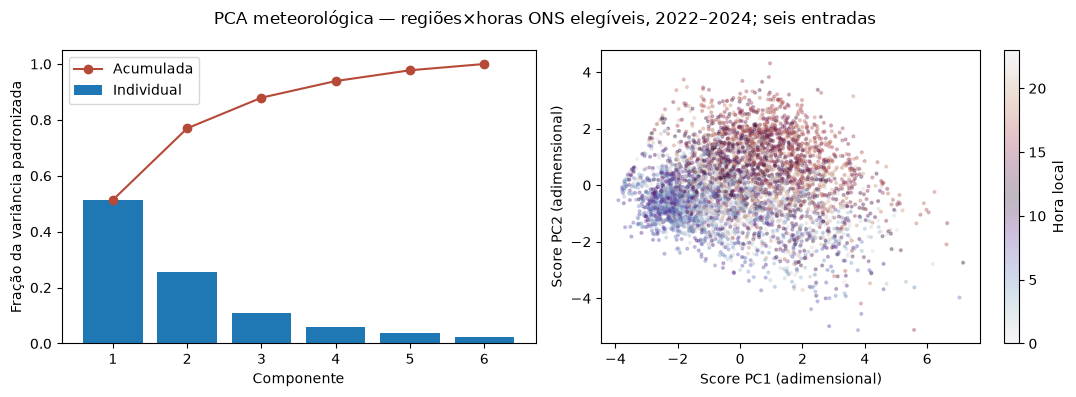

Os dois primeiros componentes preservam **77.0%** da variância padronizada. A projeção descarta **23.0%**; esse percentual não mede perda de capacidade preditiva.

In [54]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, MinMaxScaler, OneHotEncoder
from sklearn.decomposition import PCA
pca_cols=['wind_lag1','wind_lag6','gust_lag1','wind_mean24','temperatura_c_lag2','umidade_pct_lag2']
pca_dados=dev.loc[dev.ons_eligible,pca_cols]
pca_pre=Pipeline([('imputar',SimpleImputer(strategy='median')),('padronizar',StandardScaler())])
xp=pca_pre.fit_transform(pca_dados)
pca=PCA(svd_solver='full').fit(xp)
scores=pca.transform(xp)
var_pca=pd.DataFrame({'componente':np.arange(1,len(pca_cols)+1),
 'variancia_explicada':pca.explained_variance_ratio_,
 'acumulada':np.cumsum(pca.explained_variance_ratio_)})
tabela(var_pca,'pca_variancia','PCA exploratória no desenvolvimento; não alimenta os finalistas')
coef=pd.DataFrame(pca.components_[:2].T,index=pca_cols,columns=['coef_PC1','coef_PC2'])
# Loadings definidos aqui como autovetores × raiz do autovalor, não como os scores.
loads=pca.components_[:2].T*np.sqrt(pca.explained_variance_[:2])
coef[['loading_PC1','loading_PC2']]=loads
tabela(coef,'pca_coeficientes','Sinal do componente pode inverter sem mudar a solução')
fig,axs=plt.subplots(1,2,figsize=(11,4))
axs[0].bar(var_pca.componente,var_pca.variancia_explicada,label='Individual')
axs[0].plot(var_pca.componente,var_pca.acumulada,marker='o',color='#b64a38',label='Acumulada')
axs[0].set(xlabel='Componente',ylabel='Fração da variância padronizada',ylim=(0,1.05));axs[0].legend()
idx=np.random.default_rng(SEED).choice(len(scores),min(5000,len(scores)),replace=False)
sc=axs[1].scatter(scores[idx,0],scores[idx,1],c=dev.loc[dev.ons_eligible,'hour'].to_numpy()[idx],
                  s=4,alpha=.3,cmap='twilight',vmin=0,vmax=23)
axs[1].set(xlabel='Score PC1 (adimensional)',ylabel='Score PC2 (adimensional)')
fig.colorbar(sc,ax=axs[1],label='Hora local')
fig.suptitle('PCA meteorológica — regiões×horas ONS elegíveis, 2022–2024; seis entradas')
fig.tight_layout();figura(fig,'pca_meteorologia')
texto(f"Os dois primeiros componentes preservam **{var_pca.acumulada.iloc[1]:.1%}** da variância padronizada. "
      f"A projeção descarta **{1-var_pca.acumulada.iloc[1]:.1%}**; esse percentual não mede perda de capacidade preditiva.")

Os dois primeiros componentes preservam aproximadamente **77% da variância dos atributos padronizados** neste exemplo. Isso permite uma representação visual compacta, mas não significa preservar 77% da informação útil para prever cortes: PCA procura variabilidade das entradas, não separação do alvo.

Os coeficientes ajudam a interpretar quais grupos de variáveis definem os eixos. Já a sobreposição de observações no gráfico lembra que uma projeção bidimensional não constitui um classificador nem uma prova de ausência de informação nas dimensões restantes.

A PCA permanece uma análise descritiva. Nos modelos apresentados, os atributos conservam suas representações especificadas em cada configuração. A decisão de selecionar ou extrair variáveis deve considerar interpretação, custo e desempenho na validação, não apenas a aparência do gráfico.

<a id="secao-12"></a>

## 12. Engenharia de atributos de calendário e meteorologia

As entradas precisam representar informações que façam sentido para o algoritmo. Nesta seção distinguimos três usos do tempo: **calendário**, que descreve ciclos; **dinâmica meteorológica**, que descreve o comportamento recente das medições; e **histórico de treinamento**, que determina de quais períodos o modelo aprende. O último será tratado na validação.

### Calendário e interações regionais

Hora, dia da semana, mês e região podem ser codificados como categorias. No *one-hot encoding*, cada categoria gera uma coluna indicadora: a coluna vale 1 quando a observação pertence à categoria e 0 caso contrário. Assim, o modelo não interpreta o código de uma região como uma quantidade ordenada.

Uma interação região × hora permite aprender um perfil horário diferente em cada região. Ela responde diretamente aos padrões da EDA: a mesma hora não precisa ter a mesma frequência de restrição em todos os locais.

Na tabela de código, `weekday` usa 0 para segunda-feira e 6 para domingo. O campo `month` foi armazenado de 0 a 11: **0 representa janeiro e 11, dezembro**. Para os gráficos, utilizamos o mês civil de 1 a 12. Essa codificação não altera o fenômeno, mas precisa ser conhecida para ler as colunas indicadoras.

In [55]:
am_cat=dev[cat].copy()
enc=OneHotEncoder(handle_unknown='ignore',sparse_output=False).fit(am_cat)
pequeno=am_cat.drop_duplicates().head(6)
onehot=pd.DataFrame(enc.transform(pequeno),columns=enc.get_feature_names_out(cat))
ativas=onehot.columns[onehot.sum()>0]
tabela(pd.concat([pequeno.reset_index(drop=True),onehot[ativas]],axis=1),
 'onehot_exemplo','Amostra real; exibidos somente indicadores ativos nessas seis linhas')
inter=dev[['region','hour','month']].copy()
inter['regiao_hora']=inter.region.astype(str)+'_'+inter.hour.astype(str)
inter['regiao_mes']=inter.region.astype(str)+'_'+inter.month.astype(str)
inter['hora_sin']=np.sin(2*np.pi*inter.hour/24)
inter['hora_cos']=np.cos(2*np.pi*inter.hour/24)
tabela(inter.head(6),'interacoes_calendario','Mês codificado de 0 a 11; mês civil = código + 1')
print('Indicadores do calendário:',len(enc.get_feature_names_out()),'; categorias região×hora:',inter.regiao_hora.nunique())

**Amostra real; exibidos somente indicadores ativos nessas seis linhas**

,Região,Hora do dia,Dia da semana (código),Mês codificado,region_A408,hour_0,hour_1,hour_2,hour_3,hour_4,hour_5,weekday_5,month_0
0,A408,0,5,0,1.00000,1.00000,0.00000,0.00000,0.00000,0.00000,0.00000,1.00000,1.00000
1,A408,1,5,0,1.00000,0.00000,1.00000,0.00000,0.00000,0.00000,0.00000,1.00000,1.00000
2,A408,2,5,0,1.00000,0.00000,0.00000,1.00000,0.00000,0.00000,0.00000,1.00000,1.00000
3,A408,3,5,0,1.00000,0.00000,0.00000,0.00000,1.00000,0.00000,0.00000,1.00000,1.00000
4,A408,4,5,0,1.00000,0.00000,0.00000,0.00000,0.00000,1.00000,0.00000,1.00000,1.00000
5,A408,5,5,0,1.00000,0.00000,0.00000,0.00000,0.00000,0.00000,1.00000,1.00000,1.00000


**Mês codificado de 0 a 11; mês civil = código + 1**

,Região,Hora do dia,Mês codificado,regiao_hora,regiao_mes,hora_sin,hora_cos
0,A408,0,0,A408_0,A408_0,0.00000,1.00000
1,A408,1,0,A408_1,A408_0,0.25882,0.96593
2,A408,2,0,A408_2,A408_0,0.50000,0.86603
3,A408,3,0,A408_3,A408_0,0.70711,0.70711
4,A408,4,0,A408_4,A408_0,0.86603,0.50000
5,A408,5,0,A408_5,A408_0,0.96593,0.25882


Indicadores do calendário: 51 ; categorias região×hora: 192


### Variáveis cíclicas: hora e direção

Codificar a hora como um número simples cria uma distância artificial entre 23h e 0h. Uma alternativa é representá-la por

$$x_{\sin}=\sin(2\pi h/24),\qquad x_{\cos}=\cos(2\pi h/24).$$

As duas coordenadas colocam as horas em um círculo. Uma única dupla seno/cosseno descreve um padrão suave; indicadores de hora permitem um perfil mais livre. São escolhas com diferentes flexibilidades, que devem ser comparadas na validação.

A direção do vento exige cuidado semelhante. A média aritmética entre 359° e 1° é 180°, embora as duas direções estejam próximas do norte. Usar componentes circulares evita essa interpretação equivocada. O exemplo seguinte demonstra a diferença.

In [56]:
ang=np.deg2rad([359,1])
media_circular=np.rad2deg(np.arctan2(np.sin(ang).mean(),np.cos(ang).mean()))%360
print(f'Exemplo sintético: média aritmética=180°; média circular={media_circular:.6f}° (equivalente a 0°).')
direcao=weather.loc[weather.station.eq('A424')&weather.direction_deg.notna(),
                   ['time_utc','direction_deg','direction_sin','direction_cos','wind_u','wind_v']].head(6)
tabela(direcao,'direcao_real','Registros meteorológicos e componentes calculadas em m/s')

Exemplo sintético: média aritmética=180°; média circular=360.000000° (equivalente a 0°).


**Direção do vento e componentes vetoriais em registros reais**

,Hora (UTC),Direção (graus),Seno da direção,Cosseno da direção,Vento leste–oeste (m/s),Vento norte–sul (m/s)
652032,2022-01-01 00:00:00+00:00,51.00000,0.77715,0.62932,-1.01029,-0.81812
652033,2022-01-01 01:00:00+00:00,345.00000,-0.25882,0.96593,0.64705,-2.41481
652034,2022-01-01 02:00:00+00:00,340.00000,-0.34202,0.93969,0.61564,-1.69145
652035,2022-01-01 03:00:00+00:00,317.00000,-0.68200,0.73135,1.09120,-1.17017
652036,2022-01-01 04:00:00+00:00,256.00000,-0.97030,-0.24192,0.29109,0.07258
652037,2022-01-01 05:00:00+00:00,218.00000,-0.61566,-0.78801,0.06157,0.07880


### Defasagens, médias móveis, rampas e variabilidade

Duas horas podem ter vento de 5 m/s, mas histórias diferentes: em uma, ele acabou de subir de 2 para 5 m/s; na outra, caiu de 8 para 5 m/s. O valor recente sozinho não distingue essas trajetórias. Por isso construímos:

- **Defasagens (*lags*):** medições em instantes anteriores.
- **Média móvel:** nível médio em uma janela recente.
- **Rampa:** diferença entre duas medições separadas no tempo.
- **Desvio móvel:** variabilidade ao longo da janela.

Para o alvo na hora $t$, utilizamos meteorologia até $t-2$. A média completa de 24 horas é

$$\bar v_{24}(t)=\frac{1}{24}\sum_{k=2}^{25}v(t-k),$$

e a rampa de seis horas é $v(t-2)-v(t-8)$. A rampa tem unidade m/s porque é uma **diferença de velocidades**; para expressá-la como taxa por hora, seria necessário dividir por seis.

No exemplo real de A408, reindexamos a série em uma grade horária antes de aplicar `shift`. Assim, deslocar duas linhas significa deslocar duas horas físicas, mesmo quando falta uma medição. A tabela permite acompanhar cada atributo a partir do instante que será previsto.

In [57]:
serie=weather.loc[weather.station.eq('A408')].set_index('time_utc').vento_ms.sort_index()
serie=serie.reindex(pd.date_range('2022-01-01','2026-10-01',freq='h',inclusive='left',tz='UTC'))
serie.index=serie.index.tz_convert(tz)
fe=pd.DataFrame({'vento_observado_t':serie})
fe['vento_disponivel']=serie.shift(2)
fe['wind_lag1']=serie.shift(2);fe['wind_lag3']=serie.shift(4)
fe['wind_lag6']=serie.shift(7);fe['wind_lag24']=serie.shift(25)
fe['wind_mean24']=serie.shift(2).rolling(24,min_periods=24).mean()
fe['media_parcial12']=serie.shift(2).rolling(24,min_periods=12).mean()
fe['cobertura24']=serie.shift(2).rolling(24,min_periods=1).count()/24
fe['rampa6']=serie.shift(2)-serie.shift(8)
fe['desvio24']=serie.shift(2).rolling(24,min_periods=12).std()
fe['ausente_atual_admissivel']=fe.vento_disponivel.isna()
fe['emissao']=fe.index-pd.Timedelta(hours=1)
fe['ultima_met_admissivel']=fe.index-pd.Timedelta(hours=2)
exfe=fe.loc['2024-07-15 08:00':'2024-07-15 15:00'].copy()
tabela(exfe[['emissao','ultima_met_admissivel','vento_observado_t','vento_disponivel','wind_lag3',
            'wind_mean24','rampa6','cobertura24','ausente_atual_admissivel']],
 'atributos_antes_depois','Índice = hora-alvo; vento/lag/média/rampa em m/s; janela real A408')
checagem=base[base.region.eq('A408')&base.year.eq(2024)].set_index('time_local')
for c in ['wind_lag1','wind_lag3','wind_lag6','wind_lag24','wind_mean24']:
    np.testing.assert_allclose(checagem[c],fe[c].reindex(checagem.index),equal_nan=True,atol=1e-10)
print('Cinco atributos reconstruídos coincidem com a base histórica de A408 em 2024.')

**Índice = hora-alvo; vento/lag/média/rampa em m/s; janela real A408**

,Emissão da previsão,Última medição admissível,Vento contemporâneo (m/s),Vento disponível (m/s),Vento em t−4 (m/s),Vento médio em 24 h (m/s),Variação do vento em 6 h (m/s),Cobertura da janela de 24 h,Medição admissível ausente
2024-07-15 08:00:00-03:00,2024-07-15 07:00:00-03:00,2024-07-15 06:00:00-03:00,0.80000,0.00000,0.00000,2.11250,-0.10000,1.00000,False
2024-07-15 09:00:00-03:00,2024-07-15 08:00:00-03:00,2024-07-15 07:00:00-03:00,2.00000,0.20000,0.80000,2.12083,0.20000,1.00000,False
2024-07-15 10:00:00-03:00,2024-07-15 09:00:00-03:00,2024-07-15 08:00:00-03:00,3.00000,0.80000,0.00000,2.12083,0.60000,1.00000,False
2024-07-15 11:00:00-03:00,2024-07-15 10:00:00-03:00,2024-07-15 09:00:00-03:00,2.90000,2.00000,0.20000,2.06250,2.00000,1.00000,False
2024-07-15 12:00:00-03:00,2024-07-15 11:00:00-03:00,2024-07-15 10:00:00-03:00,3.20000,3.00000,0.80000,1.97917,3.00000,1.00000,False
2024-07-15 13:00:00-03:00,2024-07-15 12:00:00-03:00,2024-07-15 11:00:00-03:00,3.10000,2.90000,2.00000,1.91667,2.10000,1.00000,False
2024-07-15 14:00:00-03:00,2024-07-15 13:00:00-03:00,2024-07-15 12:00:00-03:00,4.10000,3.20000,3.00000,1.88750,3.20000,1.00000,False
2024-07-15 15:00:00-03:00,2024-07-15 14:00:00-03:00,2024-07-15 13:00:00-03:00,4.40000,3.10000,2.90000,1.81250,2.90000,1.00000,False


Cinco atributos reconstruídos coincidem com a base histórica de A408 em 2024.


A primeira coluna temporal identifica a emissão; a seguinte, a última medição admissível. O vento observado na própria hora-alvo é mostrado somente para comparação, não como entrada. A rampa distingue crescimento de queda, a média resume o nível recente e o desvio descreve oscilação.

As defasagens nos nomes armazenados seguem uma convenção particular: `wind_lag1`, `wind_lag3`, `wind_lag6` e `wind_lag24` usam, respectivamente, $t-2$, $t-4$, $t-7$ e $t-25$. A tabela explicita os instantes para evitar que o nome esconda a disponibilidade real.

Uma média parcial pode ser calculada com pelo menos 12 das 24 medições. Nesse caso, registramos também a cobertura da janela. **Construir um atributo plausível não demonstra que ele, isoladamente, melhora a previsão.** Os resultados dos modelos avaliam os grupos de atributos adotados; não atribuiremos a uma rampa todo o ganho de um sistema com várias mudanças.

### Informações disponíveis antes da hora-alvo

O cenário adotado prevê o intervalo $[t,t+1)$ com emissão em $t-1$. Assumindo uma hora de atraso para a meteorologia, a última medição utilizável é a de $t-2$. Por exemplo, para prever 14h–15h às 13h, usamos vento até 12h.

Para rótulos e contexto operacional do ONS, o cenário utiliza **168 horas de atraso após o fim do intervalo**. A hora $s$ só pode ser usada se $s+1\mathrm{h}+168\mathrm{h}\leq t-1\mathrm{h}$, o que resulta em $s\leq t-170\mathrm{h}$.

Esses atrasos são hipóteses de disponibilidade da avaliação retrospectiva. Eles evitam usar o resultado recente como se já fosse conhecido, mas não certificam os horários reais de publicação de todos os registros.

In [58]:
origem=pd.Timestamp('2026-04-01',tz=tz)
emissao=origem-pd.Timedelta(hours=1)
ultimo_rotulo=origem-pd.Timedelta(hours=170)
assert ultimo_rotulo+pd.Timedelta(hours=169)<=emissao
tabela(pd.DataFrame([{'hora_alvo':origem,'emissao':emissao,
 'ultima_meteorologia':origem-pd.Timedelta(hours=2),'ultimo_rotulo_ONS':ultimo_rotulo,
 'rotulo_disponivel_em':ultimo_rotulo+pd.Timedelta(hours=169)}]),'disponibilidade')

,hora_alvo,Emissão da previsão,ultima_meteorologia,ultimo_rotulo_ONS,rotulo_disponivel_em
0,2026-04-01 00:00:00-03:00,2026-03-31 23:00:00-03:00,2026-03-31 22:00:00-03:00,2026-03-24 22:00:00-03:00,2026-03-31 23:00:00-03:00


### Imputação sem aprender com o futuro

Uma imputação por mediana substitui uma entrada ausente pela mediana estimada no treinamento. A mesma mediana é aplicada às observações posteriores. Recalculá-la juntando treino e avaliação permitiria que o período futuro influenciasse a preparação.

O exemplo ajusta o imputador no desenvolvimento e aplica a transformação a outro conjunto. Um indicador adicional registra quais valores estavam ausentes. Esse indicador não recupera a medição, mas informa ao modelo que aquele número foi preenchido.

A imputação é adequada a entradas em pipelines que a exigem. **Não imputamos a resposta desconhecida** de um corte para transformá-la em dado de treinamento. Alvo desconhecido e atributo ausente têm papéis diferentes.

In [59]:
imputador=SimpleImputer(strategy='median',add_indicator=True).fit(pca_dados)
destino=base.loc[base.year.eq(2025)&base.ons_eligible,pca_cols]
transformado=imputador.transform(destino)
tabela(pd.DataFrame({'variavel':pca_cols,'mediana_treino':imputador.statistics_,
 'faltantes_2025':destino.isna().sum().values}),'imputacao_parametros')
tabela(pd.DataFrame([{'horas_2025_elegiveis':len(destino),'casos_completos':destino.notna().all(axis=1).sum(),
 'linhas_apos_imputacao':len(transformado),'colunas_com_indicadores':transformado.shape[1]}]),
 'imputacao_populacao','Aproveitamento numérico não equivale a recuperação da verdade meteorológica')
assert np.isfinite(transformado).all()

,Variável,mediana_treino,faltantes_2025
0,Vento admissível (m/s),2.00000,21927
1,Vento em t−7 (m/s),2.00000,21917
2,Rajada admissível (m/s),5.30000,21983
3,Vento médio em 24 h (m/s),1.92917,26953
4,temperatura_c_lag2,25.20000,19232
5,umidade_pct_lag2,63.00000,19822


**Aproveitamento numérico não equivale a recuperação da verdade meteorológica**

,horas_2025_elegiveis,casos_completos,linhas_apos_imputacao,colunas_com_indicadores
0,69960,42435,69960,12


### Reescala e padronização

A reescala min–max transforma a variável por $x'=(x-x_{\min})/(x_{\max}-x_{\min})$. A padronização usa $z=(x-\mu)/\sigma$, resultando em média zero e variância unitária no treino. Valores futuros podem ultrapassar o intervalo min–max observado; isso não significa, por si só, erro.

Escala é importante para penalizações e métodos baseados em distância ou variância, como regressão regularizada e PCA. Árvores, em geral, não exigem essa transformação. O `StandardScaler` usa desvio com denominador $n$ e não é robusto a outliers. Essa convenção difere da variância amostral com $n-1$ usada nas tabelas descritivas.

A seguir, mostramos as duas transformações e uma discretização ordinal do vento. As faixas ordenadas servem à leitura dos dados; não tornam os motivos ENE, CNF e REL categorias ordenadas.

In [60]:
esc_cols=['wind_lag1','temperatura_c_lag2','umidade_pct_lag2']
xe=dev[esc_cols].dropna()
mm=MinMaxScaler().fit(xe);ss=StandardScaler().fit(xe)
ex_esc=xe.head(5).reset_index(drop=True)
comparacao=pd.concat({'original':ex_esc,'min_max':pd.DataFrame(mm.transform(ex_esc),columns=esc_cols),
 'z_score':pd.DataFrame(ss.transform(ex_esc),columns=esc_cols)},axis=1)
tabela(comparacao,'escalas_antes_depois','Valores reais; parâmetros ajustados exclusivamente em 2022–2024')
tabela(pd.DataFrame({'variavel':esc_cols,'minimo':mm.data_min_,'maximo':mm.data_max_,
 'media':ss.mean_,'desvio_ddof0':ss.scale_}),'parametros_escalas')

**Valores reais; parâmetros ajustados exclusivamente em 2022–2024**

original                                                    min_max                                                    z_score  \
  Vento admissível (m/s) temperatura_c_lag2 umidade_pct_lag2 Vento admissível (m/s) temperatura_c_lag2 umidade_pct_lag2 Vento admissível (m/s)   
0                1.10000           24.00000         89.00000                0.08661            0.45597          0.88172               -0.64150   
1                0.90000           23.60000         91.00000                0.07087            0.44340          0.90323               -0.75665   
2                0.80000           23.30000         92.00000                0.06299            0.43396          0.91398               -0.81422   
3                0.30000           22.80000         96.00000                0.02362            0.41824          0.95699               -1.10208   
4                0.90000           22.60000         97.00000                0.07087            0.41195          0.96774               -0.75665   

                                       
  temperatura_c_lag2 umidade_pct_lag2  
0           -0.30413          1.26555  
1           -0.38501          1.36310  
2           -0.44567          1.41188  
3           -0.54677          1.60699  
4           -0.58721          1.65577

,Variável,Mínimo,Máximo,Média,desvio_ddof0
0,Vento admissível (m/s),0.00000,12.70000,2.21424,1.73693
1,temperatura_c_lag2,9.50000,41.30000,25.50409,4.94559
2,umidade_pct_lag2,7.00000,100.00000,63.05451,20.50136


In [61]:
ordinal=pd.DataFrame({'vento_ms':xe.wind_lag1.head(8).values})
ordinal['faixa_ordenada']=pd.cut(ordinal.vento_ms,[-np.inf,2,4,6,np.inf],
 labels=['baixo (<2)','moderado [2,4)','alto [4,6)','muito alto (≥6)'],right=False,ordered=True)
ordinal['codigo_ordinal']=ordinal.faixa_ordenada.cat.codes
tabela(ordinal,'ordinal','Faixas didáticas arbitrárias; códigos ordenam intervalos, não motivos ONS')

**Faixas didáticas arbitrárias; códigos ordenam intervalos, não motivos ONS**

,Vento (m/s),faixa_ordenada,codigo_ordinal
0,1.10000,baixo (<2),0
1,0.90000,baixo (<2),0
2,0.80000,baixo (<2),0
3,0.30000,baixo (<2),0
4,0.90000,baixo (<2),0
5,0.80000,baixo (<2),0
6,0.50000,baixo (<2),0
7,0.20000,baixo (<2),0


### O que cada transformação permite representar

Os atributos de calendário identificam *quando* e *em qual região* uma hora ocorre. As interações permitem perfis horários e sazonais diferentes entre regiões. Os atributos meteorológicos representam condições observadas **antes** da hora a prever: nível do vento, rajadas, persistência, variações e dados ausentes. Nenhum deles deve utilizar medições da própria hora futura.

A engenharia de atributos não determina, sozinha, que uma variável melhorará a previsão. Ela constrói representações plausíveis, que devem ser comparadas posteriormente com os mesmos alvos, períodos e critérios de avaliação. A próxima síntese reúne as perguntas motivadas pelas análises anteriores.


### Da análise exploratória às quatro perguntas que vamos testar

As etapas anteriores não foram apenas uma preparação mecânica para o treinamento. Cada uma revelou alguma característica importante dos dados e sugeriu **como representar o problema**. A tabela liga essas descobertas aos experimentos que faremos a seguir.

| Resultado ou limitação identificado | Escolha de representação | Pergunta avaliada na modelagem |
|---|---|---|
| A frequência de restrições varia entre horas, meses e regiões. | Hora, mês, dia da semana, região e interações entre categorias. | **H1 — Os padrões de calendário contêm informação preditiva sobre a ocorrência de ENE?** |
| Vento e rajada apresentam variação temporal e associações observadas com restrições; há ausências relevantes entre sensores. | Vento, rajadas, defasagens, rampas, médias móveis e resumos meteorológicos. | **H2 — A meteorologia acrescenta informação à previsão feita com calendário?** |
| Os três motivos não têm a mesma frequência e representam situações operacionais diferentes. | Um alvo por motivo, com seus próprios rótulos conhecidos e negativos. | **H3 — A contribuição meteorológica é diferente para ENE, CNF e REL?** |
| As distribuições e a frequência dos eventos variam ao longo do período estudado. | Estratégias de treinamento que dão acesso a observações mais recentes. | **H4 — Atualizar o treinamento melhora a previsão?** |

Há uma diferença crucial entre **observar um padrão** e **demonstrar que ele melhora uma previsão**. A EDA ajuda a formular perguntas e escolher atributos. Para respondê-las, compararemos modelos em observações equivalentes e com informações disponíveis antes de cada hora prevista. Também avaliaremos a intensidade total dos cortes como tarefa complementar, motivada pela presença de muitos zeros e pela grande diferença entre cortes pequenos e severos.

Assim, a parte preditiva terá **quatro comparações de classificação, uma por hipótese**, seguidas de uma análise mais breve da intensidade.

As frequências por região e horário também permitem construir uma previsão simples: estimar o risco de uma hora pela proporção recente de eventos observados naquele mesmo grupo. Essa **referência empírica** — calculada diretamente das contagens — permitirá verificar se os modelos de calendário acrescentam algo além da repetição dos padrões recentes identificados na EDA.


<a id="secao-13"></a>

## 13. Modelos de previsão e organização do treinamento

Nosso objetivo inicial é prever **se a fração de energia restringida por ENE ultrapassará 2% em uma região durante a próxima hora**. O modelo recebe informações disponíveis antes do intervalo e produz uma probabilidade entre 0 e 1. Mais adiante, repetiremos a tarefa de ocorrência para CNF e REL e, em uma análise separada, preveremos a **fração total restringida**.

É importante distinguir três decisões que costumam receber o nome genérico de “modelo”:

| Decisão | Exemplo | O que ela responde? |
|---|---|---|
| **Atributos de entrada** | Calendário ou calendário + vento | Quais informações o modelo conhece? |
| **Algoritmo** | Regressão logística ou árvores LightGBM | Como o modelo transforma essas informações em previsão? |
| **Histórico de treinamento** | Treinamento fixo ou atualização mensal | Com quais exemplos passados o modelo aprende, e quando é reajustado? |

**Calendário não é um algoritmo.** É um conjunto de atributos. Regiões, meses e horários podem ser utilizados por regressão logística ou por árvores. Do mesmo modo, “modelo meteorológico” significa que alguma informação de meteorologia foi acrescentada; o algoritmo pode continuar o mesmo.

### 13.1. Regressão logística e árvores: duas maneiras de aprender

A **regressão logística** combina contribuições de atributos e as transforma em probabilidade. Um indicador de horário pode aumentar o risco estimado; um indicador de região pode modificá-lo. O ajuste usa regularização para evitar coeficientes excessivos. Essa técnica permite construir uma referência interpretável e relativamente simples.

As **árvores de decisão** aprendem regras como “determinada faixa horária e determinada região”. O **LightGBM** combina árvores sucessivas (*gradient boosting*) e pode aprender relações não lineares e interações entre atributos. Não é necessário impor que a contribuição de uma hora seja igual em todas as regiões.


### 13.2. Quais modelos utilizaremos nas comparações principais?

Começaremos com uma referência de frequência recente e dois modelos **sem meteorologia** para estudar como diferentes estratégias aproveitam o calendário.

**Frequência recente por região e horário.** Para prever uma região às 14h, por exemplo, calculamos a proporção de eventos ENE registrada às 14h nessa região em um histórico recente já disponível. Uma frequência de 18 eventos em 28 observações seria aproximadamente 64%, antes da suavização. Aplicamos uma pequena suavização em direção à frequência geral da região para não confiar excessivamente em grupos pouco observados. A janela de 28 ou 91 dias é escolhida em validação. É uma regra estatística estimada dos dados, mas não ajusta regressão ou árvores. Ela já usa calendário e fornece uma referência competitiva para avaliar o que os modelos mais elaborados acrescentam.

**Calendário logístico.** Recebe região, hora, dia da semana e mês. Na comparação de calendários mais elaborados, sua versão utiliza todo o histórico admissível, atribuindo pesos progressivamente menores a observações antigas (meia-vida de 180 dias). Assim, aprende com o passado sem tratar uma hora muito antiga como tão relevante quanto uma recente.

**Calendário combinado.** Reúne as previsões de **dois componentes**: a regressão logística ponderada acima e um modelo LightGBM ajustado com **três meses recentes** e interações como região × hora e região × mês. Em vez de descartar uma das abordagens, combina os escores das duas, com peso definido durante o desenvolvimento. Portanto, “combinado” não significa apenas acrescentar uma coluna: significa **combinar dois modelos que aproveitam o tempo de maneiras diferentes**.

Para estudar a meteorologia sem mudar a família de algoritmo, utilizaremos um terceiro par:

**Calendário com interações (LightGBM)** e **LightGBM com calendário e meteorologia ampliada**. Ambos utilizam a mesma população, janela recente de três meses, atualização mensal e família de algoritmo. No segundo acrescentamos vento, rajadas, indicadores temporais, variabilidade, direção, outras medições e resumos espaciais permitidos. **A regularização foi selecionada separadamente para cada conjunto de atributos durante o desenvolvimento** (penalidade L2 de 40 no calendário e 10 no meteorológico). Portanto, esta comparação avalia o ganho de uma **receita com meteorologia bem ajustada** em relação à sua referência, e não o efeito matematicamente isolado de acrescentar colunas com todos os hiperparâmetros fixos.

| Nome usado nos resultados | Atributos | Algoritmo e histórico | Utilidade no estudo |
|---|---|---|---|
| Frequência recente por região e horário | Região e hora; eventos passados admissíveis para estimar frequências | Contagens suavizadas; janela escolhida entre 28 e 91 dias | Referência empírica para H1 |
| Calendário logístico ponderado | Calendário | Regressão logística; passado admissível ponderado | Referência para H1 |
| Calendário combinado | Calendário | Logística ponderada + LightGBM recente de 3 meses | Testar uma representação mais flexível em H1 |
| Calendário com interações | Calendário | LightGBM, janela de 3 meses | Referência meteorológica para H2 |
| Calendário com interações + meteorologia | Calendário e atributos meteorológicos | Mesmo LightGBM e mesma janela | Testar H2 com maior controle |

No experimento de atualização temporal (H4), utilizaremos **uma única regressão logística de calendário**, mantendo seus atributos e alterando apenas a política de atualização: congelado, atualizado antes da avaliação ou reajustado mensalmente. Nesse caso, não estamos apresentando outro algoritmo.

Para H3, cada motivo possui um par calendário/meteorologia treinado com uma receita adequada à sua frequência: o algoritmo pode variar **entre motivos**, mas é mantido **dentro de cada par**. As comparações ocorrerão em horas comuns com rótulo conhecido para todos os motivos.

**Entradas concretas.** A referência empírica distingue região e hora; o tempo define a janela de contagem, e os rótulos passados estimam as frequências. Ela não recebe valores de vento. Os demais modelos de calendário usam `region` (região), `hour` (hora local), `weekday` (dia da semana) e `month` (mês). O LightGBM de calendário utiliza também a possibilidade de aprender interações dessas categorias — particularmente região × hora e região × mês. Os modelos meteorológicos da H2 e da regressão direta acrescentam **51 colunas de medições passadas**; o código abaixo mostra a lista exata agrupada por significado. As oito primeiras são resumos de vento e rajada da estação de referência; as demais capturam evolução temporal, outras grandezas atmosféricas e diversas estações. Nenhuma entrada é a energia restringida da hora-alvo.

Em H3, o par ENE utiliza o calendário básico com vento básico; o par CNF usa LightGBM e o par REL utiliza logística com transformações suaves (*splines*). O calendário puro de H4 mantém as quatro categorias, sem medições meteorológicas.


In [62]:
# Inventário real dos atributos meteorológicos da receita principal (abril de 2026).
origem_modelos=json.loads((ROOT/'configuracoes/modelos_origem.json').read_text())
registro_b=next(z['metadata']['identity'] for z in origem_modelos
    if z['campaign']=='V3' and z['metadata'].get('identity',{}).get('name')=='B_v2'
    and z['metadata']['identity'].get('origin')=='2026-04-01')
atributos_b=registro_b['columns']
assert len(atributos_b)==51 and len(set(atributos_b))==51
blocos_entradas=[
 ('Vento e rajada na âncora', atributos_b[:8]),
 ('Dinâmica temporal: médias, rampas e dispersão', atributos_b[8:28]),
 ('Direção e outras medições atmosféricas', atributos_b[28:37]),
 ('Medições integradas de várias estações', atributos_b[37:]),
]
assert sum(len(cols) for _,cols in blocos_entradas)==len(atributos_b)
quadro_entradas=pd.DataFrame([{'Bloco de entradas':nome,'Nº de variáveis':len(cols),
 'Colunas empregadas':', '.join(cols)} for nome,cols in blocos_entradas])
tabela(quadro_entradas,'atributos_meteorologicos_principais',
       'Variáveis meteorológicas reais do LightGBM: os nomes correspondem às colunas do conjunto de dados')

**Variáveis meteorológicas reais do LightGBM: os nomes correspondem às colunas do conjunto de dados**

,Bloco de entradas,Nº de variáveis,Colunas empregadas
0,Vento e rajada na âncora,8,"wind_lag1, wind_lag3, wind_lag6, wind_lag24, gust_lag1, gust_lag24, wind_mean24, gust_max24"
1,"Dinâmica temporal: médias, rampas e dispersão",20,"wind_ramp6, wind_ramp24, wind_cubic_proxy, gust_excess, gust_ratio, wind_mean6_partial, win..."
2,Direção e outras medições atmosféricas,9,"wind_u_lag2, wind_v_lag2, temperatura_c_lag2, umidade_pct_lag2, pressure_hpa_lag2, radiacao..."
3,Medições integradas de várias estações,14,"sp_wind, sp_count, sp_distance, sp_wind_std, sp_wind_q25, sp_wind_q75, sp_gust, sp_u, sp_v,..."


### 13.3. Treinamento, validação e avaliação dos modelos apresentados

**Treino** significa estimar coeficientes ou árvores; **validação** significa escolher uma configuração sem conhecer as respostas do período final; **reajuste** aplica essa configuração escolhida aos dados admissíveis mais recentes; **avaliação** mede o desempenho nas horas posteriores. Para cada modelo, a ordem é essa — nunca usamos rótulos de uma hora futura para construir sua previsão.

O exemplo logístico executado na seção 13.4 separa **treino em 2022–2023**, **validação em 2024** (regularização e limiar de decisão), **reajuste em 2022–2024** e **avaliação em 2025**. Trata-se de um modelo mostrado no próprio notebook, com essas datas verificáveis pelo código.

Para as receitas logísticas, de árvores e de combinação dos experimentos principais H1, H2, H3 e da previsão de intensidade, as configurações são avaliadas em três blocos de **validação temporal**: janeiro–junho de 2025, julho–dezembro de 2025 e janeiro–março de 2026, com a borda final limitada pela disponibilidade dos rótulos. Em cada bloco, o modelo é ajustado com observações **anteriores** ao início do bloco; comparam-se as receitas usando suas previsões nesses blocos. **2025 é, portanto, um ano de validação desses sistemas e também integra ajustes posteriores quando já pertence ao passado admissível.** Os critérios usados são AP para a classificação, log loss para os pesos de combinação do calendário, MAE para intensidade e F1 para as regras de alerta. O código consulta as pontuações realmente registradas.

A **avaliação principal ocorre de abril a setembro de 2026**, mês a mês. É o intervalo posterior aos blocos de desenvolvimento e disponível integralmente no recorte encerrado em setembro. Não cobre um ciclo sazonal completo. As políticas de reajuste distinguem os experimentos:

| Experimento e modelos exibidos | Ajuste usado para as horas de abril/2026 | Ajustes posteriores | Avaliação |
|---|---|---|---|
| **H1 — logística ponderada e calendário combinado** | Logística com todo o passado elegível desde 2022, com pesos decrescentes; componente LightGBM com 3 meses recentes | Ambos reajustados antes de cada mês | Abril–setembro/2026 |
| **H2 — LightGBM calendário e calendário + meteorologia** | Ambos usam os 3 meses recentes (incluindo o fim de dezembro/2025) | Reajuste mensal com janela móvel de 3 meses | Abril–setembro/2026 |
| **H3 — pares ENE, CNF e REL** | ENE: histórico ponderado desde 2022; CNF: janela de 3 meses; REL: janela de 12 meses | **Sem reajuste** no semestre de avaliação | Abril–setembro/2026 |
| **H4 — três políticas do mesmo calendário logístico** | Congelado: treino até 2024; atualizado: incorpora 2025 e início de 2026 | Somente a terceira política é reajustada mensalmente | Mesmas 15.584 horas de abril–setembro/2026 |
| **Intensidade — duas regressões diretas** | Histórico ponderado desde 2022, com corte admissível anterior a abril | **Sem reajuste** durante o semestre | Abril–setembro/2026 |

**Disponibilidade dos dados.** Para simular a previsão de uma hora, admitimos que medições meteorológicas precisem de pelo menos 2 horas de atraso e que o rótulo energético de uma hora só esteja disponível 7 dias depois. Essas são hipóteses de disponibilidade, não horários de publicação certificados. As tabelas a seguir mostram os blocos de validação e, diretamente dos registros de ajuste, as primeiras e últimas horas de treino das receitas utilizadas. Portanto, as expressões “três meses recentes” e “histórico ponderado” podem ser conferidas em datas, e não apenas aceitas como descrições.

**Procedimento temporal da referência empírica da H1 — informação preditiva do calendário.** A janela é escolhida usando previsões mensais de janeiro de 2025 a março de 2026. Antes de cada mês, as frequências são calculadas apenas com rótulos já disponíveis na emissão de sua primeira hora. A AP das previsões de validação escolhe entre 28 e 91 dias; o F1 na mesma validação escolhe o limiar de alerta, na grade de 0,01 a 0,99. A suavização tem pseudocontagem fixa de 5, não otimizada. A borda final da validação exclui rótulos ainda indisponíveis antes de abril: entram horas até **24/03/2026 às 22h**, inclusive, no fuso local.

Após essas escolhas, janela, suavização e limiar ficam fixos. Apenas as frequências são recalculadas antes de cada mês de abril a setembro, com o passado então admissível. O código da H1 mostra as pontuações de validação e as datas reais de cada janela. A presença de vento multissensor é usada **somente para manter a mesma população** dos calendários; seu valor não entra na regra empírica. Nenhuma observação de avaliação participa da escolha da janela ou do limiar.


In [63]:
# Três blocos de validação usados pelas receitas de classificação e combinação.
prot_v=json.loads((ROOT/'configuracoes/protocolo_temporal.json').read_text())
prot_c=json.loads((ROOT/'configuracoes/protocolo_modelos_combinados.json').read_text())
blocos=[]
for fold in prot_v['development_folds']:
    limite=next((f.get('end') for f in prot_c['development_folds'] if f['name']==fold['name']),fold['end'])
    blocos.append({'Bloco':fold['name'],'Início da validação':fold['origin'],
       'Término nominal (exclusivo)':fold['end'],'Última data admissível registrada':limite,
       'Finalidade':'Escolha de receitas e parâmetros antes da avaliação de abril/2026'})
tabela(pd.DataFrame(blocos),'blocos_validacao_modelos',
       'Validação temporal: em cada bloco o treino utiliza apenas observações anteriores à sua origem')

**Validação temporal: em cada bloco o treino utiliza apenas observações anteriores à sua origem**

,Bloco,Início da validação,Término nominal (exclusivo),Última data admissível registrada,Finalidade
0,F1,2025-01-01,2025-07-01,2025-07-01,Escolha de receitas e parâmetros antes da avaliação de abril/2026
1,F2,2025-07-01,2026-01-01,2026-01-01,Escolha de receitas e parâmetros antes da avaliação de abril/2026
2,F3,2026-01-01,2026-04-01,2026-03-24 23:00:00,Escolha de receitas e parâmetros antes da avaliação de abril/2026


In [64]:
cmp=importar_modulo('comparacoes_projeto', ROOT/'codigo/comparacoes.py')
cmp.configurar(OUT,apoio.TABELAS,figura)


In [65]:
origens=pd.date_range('2026-04-01','2026-09-01',freq='MS',tz=tz)
cmp.mostrar(pd.DataFrame({'Mês previsto':origens.strftime('%m/%Y'),
 'Primeira emissão':origens-pd.Timedelta(hours=1),
 'Último rótulo horário admissível':origens-pd.Timedelta(hours=170)}),
 'origens_mensais','Atualização mensal: datas locais e atraso operacional presumido')

Mês previsto,Primeira emissão,Último rótulo horário admissível
04/2026,2026-03-31 23:00:00-03:00,2026-03-24 22:00:00-03:00
05/2026,2026-04-30 23:00:00-03:00,2026-04-23 22:00:00-03:00
06/2026,2026-05-31 23:00:00-03:00,2026-05-24 22:00:00-03:00
07/2026,2026-06-30 23:00:00-03:00,2026-06-23 22:00:00-03:00
08/2026,2026-07-31 23:00:00-03:00,2026-07-24 22:00:00-03:00
09/2026,2026-08-31 23:00:00-03:00,2026-08-24 22:00:00-03:00


In [66]:
# Datas de treino efetivas, recuperadas dos registros dos modelos usados nas figuras.
# H1: dois componentes reais; H2: as duas variantes LightGBM; H3 e intensidade: ajuste único.
def ajuste_v3(nome, mes):
    a=[z['metadata'] for z in origem_modelos if z['campaign']=='V3'
       and z['metadata'].get('identity',{}).get('name')==nome
       and z['metadata']['identity'].get('origin')==mes]
    assert len(a)==1,(nome,mes,len(a))
    return a[0]['train_first'],a[0]['train_last']
def ajuste_v2(familia,motivo,variante,algoritmo,mes,pop='spatial_recent'):
    a=[z['metadata'] for z in origem_modelos if z['campaign']=='V2'
       and z['metadata'].get('spec',{}).get('family')==familia
       and z['metadata']['spec'].get('reason')==motivo
       and z['metadata']['spec'].get('variant')==variante
       and z['metadata']['spec'].get('algorithm')==algoritmo
       and z['metadata']['spec'].get('population')==pop
       and z['metadata'].get('fold',{}).get('origin')==mes]
    assert len(a)==1,(familia,motivo,variante,algoritmo,mes,len(a))
    return a[0]['train_start'],a[0]['train_end']
registros=[]
def registrar(experimento,receita,mes,datas,avaliacao):
    registros.append({'Experimento':experimento,'Receita efetivamente ajustada':receita,
      'Treino: primeira hora':datas[0],'Treino: última hora':datas[1],
      'Início do bloco avaliado':avaliacao})
for mes in ['2026-04-01','2026-09-01']:
    registrar('H1','Calendário: logística ponderada',mes,ajuste_v3('A_log',mes),mes)
    registrar('H1','Calendário combinado: componente LightGBM',mes,ajuste_v3('A_tree',mes),mes)
    registrar('H2','LightGBM de calendário',mes,ajuste_v2('final_P2','ENE','A','lightgbm',mes),mes)
    registrar('H2','LightGBM com meteorologia',mes,ajuste_v2('final_P2','ENE','B','lightgbm',mes),mes)
for motivo,alg in [('ENE','logistic'),('CNF','lightgbm'),('REL','logistic_spline')]:
    for variant,label in [('A','calendário'),('B','com meteorologia')]:
        registrar('H3 — '+motivo,label,'2026-04-01',
          ajuste_v2('final_P1',motivo,variant,alg,'2026-04-01'),'2026-04-01')
for variant,label in [('A','regressão calendário'),('B','regressão com meteorologia')]:
    registrar('Intensidade',label,'2026-04-01',
      ajuste_v2('final_task','magnitude',variant,'lightgbm','2026-04-01'),'2026-04-01')
tabela(pd.DataFrame(registros),'ajustes_efetivos_modelos',
       'Registros verificáveis: treino efetivo por receita, em abril e setembro (quando há atualização)')

**Registros verificáveis: treino efetivo por receita, em abril e setembro (quando há atualização)**

,Experimento,Receita efetivamente ajustada,Treino: primeira hora,Treino: última hora,Início do bloco avaliado
0,H1,Calendário: logística ponderada,2022-01-01 02:00:00-03:00,2026-03-24 22:00:00-03:00,2026-04-01
1,H1,Calendário combinado: componente LightGBM,2025-12-24 23:00:00-03:00,2026-03-24 22:00:00-03:00,2026-04-01
2,H2,LightGBM de calendário,2025-12-24 23:00:00-03:00,2026-03-24 22:00:00-03:00,2026-04-01
3,H2,LightGBM com meteorologia,2025-12-24 23:00:00-03:00,2026-03-24 22:00:00-03:00,2026-04-01
4,H1,Calendário: logística ponderada,2022-01-01 02:00:00-03:00,2026-08-24 22:00:00-03:00,2026-09-01
...,...,...,...,...,...
11,H3 — CNF,com meteorologia,2025-12-24 23:00:00-03:00,2026-03-24 22:00:00-03:00,2026-04-01
12,H3 — REL,calendário,2025-03-24 23:00:00-03:00,2026-03-24 22:00:00-03:00,2026-04-01
13,H3 — REL,com meteorologia,2025-03-24 23:00:00-03:00,2026-03-24 22:00:00-03:00,2026-04-01
14,Intensidade,regressão calendário,2022-01-01 02:00:00-03:00,2026-03-24 22:00:00-03:00,2026-04-01


*Mostradas as linhas iniciais e finais; a tabela completa, com 16 linhas, é salva em `resultados/tabelas/ajustes_efetivos_modelos.csv`.*

In [67]:
# H4: regras temporais extraídas do protocolo (limites de elegibilidade, não um log de todos os ajustes).
protocolo_anual=json.loads((ROOT/'configuracoes/protocolo_comparacao_anual.json').read_text())
assert protocolo_anual['refit_years']==[2022,2023,2024]
assert prot_v['final_origin']=='2026-04-01'
linhas_h4=[]
for rotulo,final_treino,reajuste in [
    ('Congelado', '31/12/2024', 'Não reajusta em 2026'),
    ('Atualizado antes de abril', '24/03/2026', 'Uma vez, antes de abril'),
    ('Atualizado mensalmente — abril', '24/03/2026', 'Antes de abril'),
    ('Atualizado mensalmente — setembro', '24/08/2026', 'Antes de setembro')]:
    linhas_h4.append({'Calendário':rotulo,'Histórico elegível desde':'2022',
                     'Fim do histórico (limite)':final_treino,'Reajuste':reajuste,
                     'Avaliado em':'abril–setembro/2026'})
tabela(pd.DataFrame(linhas_h4),'h4_periodos_calendario',
       'H4 — diferenças de histórico e reajuste; o calendário não recebe meteorologia')
# Regularização da receita básica de calendário, escolhida na validação anual de 2024.
selecao_ene_a=next(r for r in json.loads((ROOT/'configuracoes/selecao_classificadores.json').read_text())
    if r['reason']=='ENE' and r['variant']=='A' and r['algorithm']=='logistic')
assert selecao_ene_a['parameter']==1.0


**H4 — diferenças de histórico e reajuste; o calendário não recebe meteorologia**

,Calendário,Histórico elegível desde,Fim do histórico (limite),Reajuste,Avaliado em
0,Congelado,2022,31/12/2024,Não reajusta em 2026,abril–setembro/2026
1,Atualizado antes de abril,2022,24/03/2026,"Uma vez, antes de abril",abril–setembro/2026
2,Atualizado mensalmente — abril,2022,24/03/2026,Antes de abril,abril–setembro/2026
3,Atualizado mensalmente — setembro,2022,24/08/2026,Antes de setembro,abril–setembro/2026


**Como sabemos o que foi escolhido?** Os arquivos de configuração incluem a média dos resultados nos três blocos de validação. Para os classificadores, usamos **AP média** para comparar receitas; para os dois componentes do calendário combinado, o peso da combinação foi escolhido pela **menor log loss**; para a regressão direta, avaliamos **MAE**. O código seguinte apresenta apenas as configurações que aparecem nos resultados deste notebook. Não usa as horas de abril–setembro/2026 para escolhê-las.

In [68]:
# Conferência de escolhas a partir das pontuações guardadas na validação, não do teste.
f2=json.loads((ROOT/'configuracoes/modelos_temporais.json').read_text())
f3=json.loads((ROOT/'configuracoes/modelos_combinados.json').read_text())
validacao=[]
for motivo,colecao in [('ENE','quad'),('CNF','best_AB'),('REL','best_AB')]:
    for v in ['A','B']:
        candidatas=[r for r in f2[colecao] if r['spec']['reason']==motivo
           and r['spec']['population']=='spatial_recent' and r['spec']['variant']==v]
        modelo_esperado='lightgbm' if motivo in ['ENE','CNF'] else 'logistic_spline'
        if motivo=='ENE':
            candidatas=[r for r in candidatas if r['spec']['algorithm']=='lightgbm']
        assert len(candidatas)==1,(motivo,v,len(candidatas))
        r=candidatas[0];sp=r['spec'];p=sp['params']
        np.testing.assert_allclose(np.mean(r['fold_ap']),r['mean_ap'],atol=1e-12)
        validacao.append({'Experimento':'H2' if motivo=='ENE' else 'H3 — '+motivo,
           'Entradas':'Calendário' if v=='A' else 'Calendário + meteorologia',
           'Algoritmo':sp['algorithm'],'Memória':sp['strategy'],
           'Regularização':p.get('l2',p.get('C')),
           'AP média em validação':r['mean_ap']})
# Para H3-ENE, a receita exibida é a logística ponderada (não o LightGBM H2).
for v in ['A','B']:
    r=next(r for r in f2['best_AB'] if r['spec']['reason']=='ENE'
        and r['spec']['population']=='spatial_recent' and r['spec']['variant']==v)
    sp=r['spec']
    validacao.append({'Experimento':'H3 — ENE','Entradas':'Calendário' if v=='A' else 'Calendário + meteorologia',
      'Algoritmo':'logistic','Memória':sp['strategy'],
      'Regularização':sp['params']['C'],'AP média em validação':r['mean_ap']})
quadro_validacao=pd.DataFrame(validacao)
quadro_validacao['ordem']=quadro_validacao.Experimento.map({'H2':0,'H3 — ENE':1,'H3 — CNF':2,'H3 — REL':3})
quadro_validacao=quadro_validacao.sort_values(['ordem','Entradas']).drop(columns='ordem')
tabela(quadro_validacao,'configuracoes_ap_validacao',
       'Receitas de classificação exibidas: AP média nos três blocos de validação')
comb=next(r for r in f3['selection'] if r['system']=='A_multiscale')
resultados_pesos=pd.DataFrame(comb['means'])[['value','ap','log_loss']]
assert resultados_pesos.loc[resultados_pesos.log_loss.idxmin(),'value']==comb['chosen']==0.5
tabela(resultados_pesos.rename(columns={'value':'Peso do componente recente',
  'ap':'AP de validação','log_loss':'Log loss de validação'}),
  'validacao_peso_calendario','H1 — peso da combinação do calendário: escolha pela menor log loss')
mag=[]
for v in ['A','B']:
    r=next(r for r in f2['tasks'] if r['spec']['reason']=='magnitude'
        and r['spec']['variant']==v)
    assert r['metric']=='mae'
    mag.append({'Modelo':'Calendário' if v=='A' else 'Calendário + meteorologia',
      'Memória':r['spec']['strategy'],'MAE médio nos blocos de validação':r['mean_score']})
tabela(pd.DataFrame(mag),'validacao_regressao_direta',
       'Intensidade — receita de regressão direta e MAE médio em validação')

**Receitas de classificação exibidas: AP média nos três blocos de validação**

,Experimento,Entradas,Algoritmo,Memória,Regularização,AP média em validação
0,H2,Calendário,Árvores com boosting,window3,40.00000,0.70002
1,H2,Calendário + meteorologia,Árvores com boosting,window3,10.00000,0.70801
6,H3 — ENE,Calendário,Regressão logística,half_life180,20.00000,0.71649
7,H3 — ENE,Calendário + meteorologia,Regressão logística,half_life180,20.00000,0.70807
2,H3 — CNF,Calendário,Árvores com boosting,window3,5.00000,0.21717
3,H3 — CNF,Calendário + meteorologia,Árvores com boosting,window3,10.00000,0.25589
4,H3 — REL,Calendário,logistic_spline,window12,0.06000,0.12594
5,H3 — REL,Calendário + meteorologia,logistic_spline,window12,6.00000,0.14237


**H1 — peso da combinação do calendário: escolha pela menor log loss**

,Peso do componente recente,AP de validação,Log loss de validação
0,0.00000,0.75074,0.36887
1,0.25000,0.75435,0.33075
2,0.50000,0.75434,0.33044
3,0.75000,0.74804,0.36837
4,1.00000,0.73459,0.43955


**Intensidade — receita de regressão direta e MAE médio em validação**

,Modelo,Memória,MAE médio nos blocos de validação
0,Calendário,half_life180,0.18362
1,Calendário + meteorologia,half_life180,0.17848


### 13.4. Treinamento demonstrativo: da tabela de atributos às probabilidades

Antes de comparar os sistemas completos, vale executar um exemplo de treinamento. Utilizaremos uma **regressão logística com calendário e oito atributos meteorológicos básicos**, ajustada com observações de **2022–2024** e aplicada a **2025**. Esse exemplo mostra o funcionamento do pipeline; suas métricas não serão misturadas com as comparações de abril–setembro de 2026.

Um `Pipeline` encadeia as transformações e o classificador. Primeiro, codificamos região, hora, dia da semana e mês como indicadores; depois, padronizamos os atributos meteorológicos; por fim, a regressão logística aprende seus coeficientes. **O ajuste de transformações utiliza apenas o treino**: não podemos aprender médias, escalas ou parâmetros observando o período usado para avaliar.

A primeira célula demonstra o pré-processamento; a segunda recupera a escolha da regularização realizada em **2024**; a terceira executa o reajuste em 2022–2024 e a avaliação em 2025. Na seção 14, reproduziremos também a busca do **limiar de decisão** a partir das probabilidades de validação, usando esses mesmos dados reais.


In [69]:
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
num_pipe=Pipeline([('imputar',SimpleImputer(strategy='median',add_indicator=True)),
                   ('padronizar',StandardScaler())])
pre_didatico=ColumnTransformer([('calendario',OneHotEncoder(handle_unknown='ignore',sparse_output=False),cat),
                               ('meteo',num_pipe,pca_cols)])
pipeline_didatico=Pipeline([('preparar',pre_didatico),
                           ('classificar',LogisticRegression(C=.1,max_iter=500,random_state=SEED))])
treino_pre=dev.loc[dev.ons_eligible,cat+pca_cols]
pre_didatico.fit(treino_pre)
aplicacao=base.loc[base.year.eq(2025)&base.ons_eligible,cat+pca_cols].head(8)
matriz_aplicada=pre_didatico.transform(aplicacao)
print(pipeline_didatico)
print('Entrada:',aplicacao.shape,'→ matriz numérica:',matriz_aplicada.shape)
print('Primeiros nomes:',pre_didatico.get_feature_names_out()[:12].tolist())
assert np.isfinite(matriz_aplicada).all()

Pipeline(steps=[('preparar',
                 ColumnTransformer(transformers=[('calendario',
                                                  OneHotEncoder(handle_unknown='ignore',
                                                                sparse_output=False),
                                                  ['region', 'hour', 'weekday',
                                                   'month']),
                                                 ('meteo',
                                                  Pipeline(steps=[('imputar',
                                                                   SimpleImputer(add_indicator=True,
                                                                                 strategy='median')),
                                                                  ('padronizar',
                                                                   StandardScaler())]),
                                                  ['wind_lag1', 'wind_lag6',
    

In [70]:
selecao=json.loads((ROOT/'configuracoes/selecao_classificadores.json').read_text())
escolhido=next(x for x in selecao if x['reason']=='ENE' and x['algorithm']=='logistic' and x['variant']=='B')
cmp.mostrar(pd.DataFrame(escolhido['trials']).rename(columns={'parameter':'C','validation_ap':'AP na validação','threshold':'Limiar de decisão'}),
 'selecao_logistica_vento','Escolha da regularização na validação de 2024')

C,AP na validação,Limiar de decisão
"0,1000","0,5510","0,0600"
"1,0000","0,5502","0,0700"


In [71]:
# Uma amostra por região e hora, com alvos e oito entradas meteorológicas completos.
mascara_completa = base[[f'y_{r}_02' for r in motivos]+met].notna().all(axis=1)
populacao_modelo = base.loc[mascara_completa].sort_values(['time_local','region']).reset_index(drop=True)
dados_treino = populacao_modelo[populacao_modelo.year.le(2024)]
dados_teste = populacao_modelo[populacao_modelo.year.eq(2025)]
previsoes_anuais = ler_tabela(ROOT/'dados/previsoes_comparacao_anual.npz')
referencia_logistica = previsoes_anuais.query("reason=='ENE' and algorithm=='logistic' and variant=='B' and year==2025")
entradas_modelo = cat + met

# Todas as transformações aprendem no treino; o teste recebe apenas transform().
from sklearn.linear_model import LogisticRegression
modelo = Pipeline([
    ('preparacao', ColumnTransformer([
        ('calendario', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat),
        ('meteorologia', StandardScaler(), met)])),
    ('classificador', LogisticRegression(C=escolhido['parameter'], max_iter=500,
                                         random_state=SEED))])
t0 = time.perf_counter()
modelo.fit(dados_treino[entradas_modelo], dados_treino.y_ENE_02.astype(int))
p_novo = modelo.predict_proba(dados_teste[entradas_modelo])[:,1]
tempo_fit = time.perf_counter()-t0

novas_previsoes = dados_teste[['region','time_local','y_ENE_02']].rename(columns={'y_ENE_02':'y'}).assign(p=p_novo)
replica = apoio.parear(referencia_logistica, novas_previsoes)
erro_prob = float(np.max(np.abs(replica.p_a-replica.p_b)))
assert len(dados_treino)==149514 and len(replica)==42113
assert erro_prob < 1e-5, f'Diferença de reprodução acima da tolerância: {erro_prob}'
recibo_refit = pd.DataFrame([{'n_treino':len(dados_treino), 'n_teste':len(replica),
 'segundos_fit_inferencia':tempo_fit, 'iteracoes':int(modelo.named_steps['classificador'].n_iter_[0]),
 'max_diferenca_probabilidade':erro_prob}])
tabela(recibo_refit, 'treinamento_executado', 'Treinamento e previsão executados nesta célula')
tabela(novas_previsoes.head(6), 'exemplos_previsoes', 'Probabilidades de restrição ENE para seis observações de 2025')

**Treinamento e previsão executados nesta célula**

,n_treino,n_teste,segundos_fit_inferencia,iteracoes,max_diferenca_probabilidade
0,149514,42113,0.41952,39,0.00000


**Probabilidades de restrição ENE para seis observações de 2025**

,Região,Hora (Bahia),y,p
149514,A408,2025-01-01 00:00:00-03:00,0.00000,0.00011
149515,A426,2025-01-01 00:00:00-03:00,0.00000,0.00008
149516,A429,2025-01-01 00:00:00-03:00,0.00000,0.00010
149517,A433,2025-01-01 00:00:00-03:00,0.00000,0.00006
149518,A439,2025-01-01 00:00:00-03:00,0.00000,0.00010
149519,A408,2025-01-01 01:00:00-03:00,0.00000,0.00011


O exemplo verifica que conseguimos reconstruir previsões já registradas, sem modificar o conjunto de avaliação. **Treinar**, **selecionar uma configuração** e **avaliar** são passos diferentes: a escolha de parâmetros ocorre em períodos anteriores; somente depois aplicamos a receita escolhida às horas futuras.

Nos resultados seguintes, serão utilizadas previsões armazenadas dos sistemas completos, produzidas com as políticas temporais descritas acima. Antes de cada comparação, verificaremos que os modelos observam **as mesmas regiões, horas e respostas verdadeiras**. Essa verificação é essencial: um valor de AP maior em uma população diferente não prova que um algoritmo tenha melhorado.


<a id="secao-14"></a>

## 14. Métricas: como interpretar o desempenho

Antes de olhar os resultados, precisamos saber **o que cada número mede**. Para ocorrência, há três perguntas: o modelo ordena bem os riscos, fornece probabilidades adequadas e produz bons alertas? Para intensidade, medimos o tamanho dos erros na fração cortada [4].

### 14.1. De uma probabilidade a um alerta

Se o modelo prevê probabilidade 0,30, isso ainda não é uma decisão. Com um **limiar de decisão** de 0,20, emitimos alerta; com limiar 0,50, não emitimos. Esse limiar probabilístico é diferente do **limiar energético de 2%**, que define o evento verdadeiro.

| Resultado | Evento observado? | Alerta emitido? | Interpretação |
|---|---|---|---|
| Verdadeiro positivo — VP | Sim | Sim | Restrição detectada. |
| Falso negativo — FN | Sim | Não | Restrição não detectada. |
| Falso positivo — FP | Não | Sim | Alerta sem o evento definido. |
| Verdadeiro negativo — VN | Não | Não | Ausência do evento corretamente reconhecida. |

“Evento não observado” significa não ultrapassar o limiar do motivo estudado, não necessariamente ausência de qualquer corte. **O limiar energético de 2% define o evento; o limiar probabilístico determina o alerta.** O segundo foi escolhido com previsões anteriores ao período avaliado, como demonstraremos abaixo.

**Precisão** é a fração dos alertas que estavam corretos. **Recall** é a fração dos eventos que foram detectados. **F1** combina precisão e recall; **especificidade** é a fração das horas negativas reconhecidas como negativas. **Acurácia** mede os acertos totais, mas pode parecer alta apenas porque existem muitos negativos.

$$\mathrm{Precisão}=\frac{VP}{VP+FP},\qquad
\mathrm{Recall}=\frac{VP}{VP+FN},\qquad
F1=\frac{2VP}{2VP+FP+FN}.$$

$$\mathrm{Especificidade}=\frac{VN}{VN+FP},\qquad
\mathrm{Acurácia}=\frac{VP+VN}{n}.$$

Imagine 100 horas, com 20 eventos. Um modelo detecta 15 e emite 10 alertas falsos: sua precisão é 15/25 = 60%, seu recall é 15/20 = 75% e seu F1 é aproximadamente 66,7%. Esses números descrevem consequências diferentes. Não existe “o melhor” sem considerar a finalidade do alerta.

In [72]:
# Exemplo numérico didático, não observações do dataset.
VP, FN, FP, VN = 15, 5, 10, 70
exemplo_decisao=pd.DataFrame([
 ('Precisão',VP/(VP+FP)),('Recall',VP/(VP+FN)),
 ('F1',2*VP/(2*VP+FP+FN)),('Especificidade',VN/(VN+FP)),
 ('Acurácia',(VP+VN)/(VP+FN+FP+VN)),('Taxa de erro',(FP+FN)/(VP+FN+FP+VN))
],columns=['Medida','Valor'])
cmp.mostrar(exemplo_decisao,'exemplo_metricas_decisao','Exemplo sintético: 100 horas, 20 eventos e 25 alertas')

Medida,Valor
Precisão,"0,6000"
Recall,"0,7500"
F1,"0,6667"
Especificidade,"0,8750"
Acurácia,"0,8500"
Taxa de erro,"0,1500"


### Selecionar o limiar usando apenas a validação

O limiar de alerta é escolhido **depois de treinar o modelo e antes de avaliá-lo**. Calculamos a precisão e o recall para limiares de **0,01 a 0,99**, obtemos o F1 de cada um e selecionamos o de maior F1. Em caso de empate, escolhemos o menor limiar.

A célula seguinte **refaz uma seleção com dados reais** para a regressão logística com vento básico demonstrada na seção 13: treino em **2022–2023**, validação em **2024**. Reproduzimos tanto a comparação de regularização pela AP de 2024 quanto o limiar escolhido pelo F1. Depois desse procedimento, a seção 13 reajusta a configuração com 2022–2024 e avalia 2025, sem consultar 2025 para escolher o limiar.

Para os sistemas centrais de 2026, as regras foram selecionadas a partir de **previsões de desenvolvimento de 2025 e janeiro–março/2026**, seguindo o mesmo princípio. Os valores registrados, inclusive os diferentes limiares mensais, são lidos junto com as previsões na seção 15. O pacote contém essas escolhas e os escores agregados de validação, mas não todas as previsões individuais usadas para recalcular cada uma das buscas: portanto, o exemplo abaixo é uma **reprodução exata do procedimento anual**, não uma alegação de ter reexecutado todas as seleções.

In [73]:
# Seleção REAL por grade, com a amostra de treinamento/validação do próprio projeto.
# 2025 e abril-setembro/2026 não participam desta busca.
from sklearn.metrics import f1_score, average_precision_score
valid_train=populacao_modelo[populacao_modelo.year.le(2023)]
valid_2024=populacao_modelo[populacao_modelo.year.eq(2024)]
y_val=valid_2024.y_ENE_02.astype(int).to_numpy()
limiares_candidatos=np.arange(1,100)/100
ensaios=[]
for trial in escolhido['trials']:
    C=trial['parameter']
    estimador=Pipeline([
        ('preparacao',ColumnTransformer([
            ('calendario',OneHotEncoder(handle_unknown='ignore',sparse_output=False),cat),
            ('meteorologia',StandardScaler(),met)])),
        ('classificador',LogisticRegression(C=C,max_iter=500,random_state=SEED))])
    estimador.fit(valid_train[cat+met],valid_train.y_ENE_02.astype(int))
    p_val=estimador.predict_proba(valid_2024[cat+met])[:,1]
    curva_f1=np.array([f1_score(y_val,p_val>=lim,zero_division=0)
                       for lim in limiares_candidatos])
    pos=int(np.argmax(curva_f1))  # primeiro máximo -> menor limiar no empate
    ap_val=average_precision_score(y_val,p_val)
    lim_escolhido=float(limiares_candidatos[pos])
    np.testing.assert_allclose(ap_val,trial['validation_ap'],atol=1e-10)
    np.testing.assert_allclose(lim_escolhido,trial['threshold'],atol=1e-12)
    ensaios.append({'C (regularização)':C,'AP em 2024':ap_val,
      'Limiar de maior F1':lim_escolhido,'F1 máximo em 2024':curva_f1[pos]})
resultado_limiares=pd.DataFrame(ensaios)
assert resultado_limiares.loc[resultado_limiares['AP em 2024'].idxmax(),'C (regularização)']==escolhido['parameter']
assert abs(escolhido['threshold']-.06)<1e-12
tabela(resultado_limiares,'selecao_limiar_validacao_real',
 'Validação REAL em 2024: AP escolhe C; F1 escolhe o limiar do modelo de 2025')

**Validação REAL em 2024: AP escolhe C; F1 escolhe o limiar do modelo de 2025**

,C (regularização),AP em 2024,Limiar de maior F1,F1 máximo em 2024
0,0.10000,0.55099,0.06000,0.56838
1,1.00000,0.55016,0.07000,0.57158


### 14.2. Ordenação dos riscos: ROC-AUC e Average Precision

Para estudar o ranking, variamos o limiar em vez de escolher uma única decisão.

A curva **ROC** relaciona o recall à taxa de falsos positivos. A **ROC-AUC** é a área sob essa curva: resume a capacidade de dar um escore maior a um positivo do que a um negativo. Valor 0,5 representa ausência de discriminação; valor 1 corresponde à separação perfeita no conjunto avaliado.

A curva **precisão–recall** relaciona quantos eventos são recuperados à qualidade dos alertas. Ela é particularmente informativa quando os eventos são raros, pois evidencia o efeito dos falsos positivos sobre a precisão.

**AP significa Average Precision, ou precisão média.** Resume a curva precisão–recall ponderando a precisão pelo aumento de recall em cada ponto:

$$AP=\sum_k (R_k-R_{k-1})P_k.$$

Aqui, $P_k$ é a precisão e $R_k$ é o recall. Maior AP é melhor, mas **AP de 0,85 não significa 85% de acurácia nem 85% dos eventos detectados**. Uma previsão constante não ordena as horas e tem AP igual à prevalência nesse conjunto. Por isso, não devemos comparar AP de populações ou motivos com frequências muito diferentes como se as tarefas fossem idênticas.

### 14.3. Probabilidades: Brier, log loss e calibração

Um modelo pode colocar as horas positivas à frente das negativas e ainda fornecer números inadequados como probabilidades. Se ele prevê risco 10% em um grupo de horas, esperamos cerca de 10% de eventos nesse grupo — não 50%.

O **Brier score** é a média de $(p-y)^2$, com $y=1$ para evento e $y=0$ para ausência dele. A **log loss**, ou perda logarítmica, penaliza especialmente previsões muito confiantes que contradizem o observado. **Menor é melhor** nas duas. Elas avaliam as probabilidades como um todo; não são medidas exclusivas de calibração.

A **curva de calibração** reúne previsões em faixas e compara a probabilidade média à frequência observada. Pontos acima da diagonal indicam subestimação. A comparação entre probabilidade média total e prevalência também ajuda, mas não substitui a curva: erros em faixas diferentes podem se compensar.

O exemplo abaixo mantém a ordem dos riscos e divide as probabilidades por dez. O ranking permanece, mas a qualidade probabilística muda.

In [74]:
exemplo_rank=pd.DataFrame({'y':[0,0,1,1],'p_original':[.1,.2,.8,.9]})
exemplo_rank['p_dividida_por_10']=exemplo_rank.p_original/10
tabela(exemplo_rank,'ranking_exemplo_probabilidades','Exemplo sintético de quatro observações')
ranking_metricas=[]
for c in ['p_original','p_dividida_por_10']:
    m=apoio.classificacao(exemplo_rank.y,exemplo_rank[c])
    ranking_metricas.append({'escala':c,**{k:m[k] for k in ['AP','ROC_AUC','media_p','prevalencia','Brier','log_loss']}})
tabela(pd.DataFrame(ranking_metricas),'ranking_exemplo_metricas',
 'Mesma ordenação, erro probabilístico diferente: AP/AUC não são medidas de calibração')

**Exemplo sintético de quatro observações**

,y,p_original,p_dividida_por_10
0,0,0.10000,0.01000
1,0,0.20000,0.02000
2,1,0.80000,0.08000
3,1,0.90000,0.09000


**Mesma ordenação, erro probabilístico diferente: AP/AUC não são medidas de calibração**

,escala,AP,ROC-AUC,Probabilidade média,Frequência de eventos,Brier,Perda logarítmica
0,p_original,1.00000,1.00000,0.50000,0.50000,0.02500,0.16425
1,p_dividida_por_10,1.00000,1.00000,0.05000,0.50000,0.41875,1.24098


### 14.4. Intensidade: erro absoluto, erro quadrático e viés

Na regressão, uma previsão de 0,30 diante de uma fração verdadeira de 0,50 tem erro de −0,20: subestima 20 pontos percentuais da referência.

$$MAE=\frac1n\sum_i |\hat f_i-f_i|,\qquad
RMSE=\sqrt{\frac1n\sum_i(\hat f_i-f_i)^2}.$$

**MAE** resume o erro absoluto médio. **RMSE** dá mais peso a erros grandes. O **viés**, média de $\hat f-f$, informa a tendência a superestimar ou subestimar, embora erros de sinais opostos possam se compensar. Usaremos unidades de fração e, no texto, pontos percentuais.

Nossa regressão direta prevê a **mediana condicional da fração restringida**, apropriada ao MAE. Avaliaremos MAE, RMSE e viés sobre essa mesma saída, sem trocar silenciosamente mediana por média entre os dois modelos.

### 14.5. Como ler os blocos de resultados

Cada comparação de classificação terá duas tabelas adjacentes: **ranking e probabilidades** — AP, ROC-AUC, Brier e log loss — e **decisões** — precisão, recall, F1, especificidade e acurácia. A segunda mostrará os limiares registrados no desenvolvimento. Eles podem diferir entre modelos e mudar entre meses; portanto, F1 não é uma propriedade isolada do algoritmo.

Não escolheremos limiares pelo resultado de teste. Um limiar comum 0,50 será mostrado como diagnóstico complementar, não como regra obrigatoriamente adequada. As taxas são apresentadas entre zero e um. Uma faixa de valores na coluna de limiar indica que ele mudou entre origens mensais. As contagens VP/FP/VN/FN e as métricas calculadas no limiar comum 0,50 ficam também no CSV completo de cada painel; os quadros principais exibem as medidas necessárias à leitura conjunta.

Também examinaremos a regularidade mensal e os intervalos dos contrastes. Horas vizinhas e regiões no mesmo instante não são independentes. A reamostragem por blocos de tempo mantém parte dessa dependência. Seus intervalos descrevem a incerteza do contraste com os modelos fixos, não toda a incerteza das escolhas feitas durante a pesquisa.

### 14.6. Incerteza das diferenças de desempenho

Uma vantagem calculada sobre seis meses pode depender mais de alguns períodos do que de outros. Além da diferença observada, examinaremos sua sensibilidade por **bootstrap em blocos temporais**: formamos várias amostras sorteando blocos inteiros do período, com reposição. Um bloco pode aparecer duas vezes e outro não aparecer em determinada repetição. Horas próximas não são separadas dentro do bloco, e todas as regiões observadas naquele intervalo são mantidas juntas [7].

A comparação é **pareada**. Em cada repetição, ambos os modelos recebem exatamente os mesmos blocos e multiplicidades. Calculamos a métrica de cada um e sua diferença, sempre na ordem **comparado menos referência**. Para AP, uma diferença positiva favorece o comparado; para Brier, uma diferença negativa o favorece.

Utilizamos 500 repetições, semente fixa e blocos de **7 e 28 dias**. Os percentis 2,5% e 97,5% delimitam um intervalo descritivo de 95%. Se o intervalo inclui zero, a diferença pontual não estabelece uma vantagem estável sob esse procedimento; isso não prova equivalência. Apresentamos os dois tamanhos para não escolher apenas o que favorece uma conclusão.

Os intervalos usam **as previsões já calculadas**, sem retreinar os modelos. Não representam a incerteza completa de escolher atributos e hiperparâmetros, nem são intervalos de previsão de uma hora futura. O semestre contém 27 blocos semanais ou somente 7 blocos de 28 dias, incluindo o último parcial: o pequeno número de blocos e as mudanças temporais recomendam uma interpretação descritiva, não uma certificação de desempenho futuro. Na H2 examinaremos AP e Brier separadamente, pois ordenação e qualidade probabilística não são a mesma propriedade.


In [75]:
inc = importar_modulo('incrementos_projeto', ROOT/'codigo/incrementos.py')

def intervalo_pareado(referencia, comparado, dias_bloco, metrica='AP',
                      repeticoes=500, semente=5787):
    """Diferença comparado − referência, nas mesmas horas e regiões.

    Sorteia blocos não sobrepostos de calendário, com reposição. Todas as
    regiões de um bloco recebem a mesma multiplicidade nos dois sistemas.
    Não treina modelos nem altera probabilidades ou limiares.
    """
    a, b = inc.alinhar(referencia, comparado)
    codigos, n_blocos, inicio = inc.codigo_blocos(a.time_local, dias_bloco)
    y = a.y.to_numpy(dtype=int)
    if metrica == 'AP':
        # Ordenação reutilizada: cálculo equivalente à AP ponderada do sklearn.
        avaliar_a = inc.APOrdenada(y, a.p)
        avaliar_b = inc.APOrdenada(y, b.p)
    elif metrica == 'Brier':
        erros_a = (a.p.to_numpy() - y)**2
        erros_b = (b.p.to_numpy() - y)**2
        avaliar_a = lambda w: float(np.average(erros_a, weights=w))
        avaliar_b = lambda w: float(np.average(erros_b, weights=w))
    else:
        raise ValueError('Este experimento utiliza apenas AP e Brier.')
    rng = np.random.default_rng(semente)
    diferencas = []
    for _ in range(repeticoes):
        # Multiplicidades equivalem a sortear n_blocos blocos com reposição.
        multiplicidade = rng.multinomial(n_blocos, np.full(n_blocos, 1/n_blocos))
        pesos = multiplicidade[codigos]
        diferencas.append(avaliar_b(pesos) - avaliar_a(pesos))
    diferencas = np.asarray(diferencas)
    validas = np.isfinite(diferencas)
    if validas.sum() < .95*repeticoes:
        raise ValueError('Muitas réplicas sem as duas classes: intervalo inadequado.')
    inferior, superior = np.quantile(diferencas[validas], [.025, .975])
    w = np.ones(len(a))
    resumo = {'Métrica': metrica, 'Bloco (dias)': dias_bloco,
              'Blocos disponíveis': n_blocos, 'Observações': len(a),
              'Diferença observada': avaliar_b(w)-avaliar_a(w),
              'Limite inferior 95%': inferior, 'Limite superior 95%': superior,
              'Réplicas válidas': int(validas.sum()), 'Réplicas solicitadas': repeticoes}
    return resumo, diferencas

def tabela_intervalos(sistemas, pares, nome_arquivo, metricas=('AP',)):
    """Pares: (nome da referência, nome do comparado, descrição do contraste)."""
    linhas, replicas = [], {}
    for i, (ref, comp, descricao) in enumerate(pares):
        for metrica in metricas:
            for dias in [7, 28]:
                resumo, valores = intervalo_pareado(sistemas[ref], sistemas[comp], dias, metrica)
                linhas.append({'Comparação': descricao, **resumo})
                replicas[f'contraste_{i}_{metrica}_{dias}d'] = valores
    completo = pd.DataFrame(linhas)
    completo.to_csv(OUT/'tabelas'/f'{nome_arquivo}_completo.csv', index=False)
    np.savez_compressed(OUT/'recibos'/f'{nome_arquivo}_replicas.npz', **replicas)
    exibicao = completo[['Comparação','Métrica','Diferença observada']].drop_duplicates().copy()
    for dias in [7, 28]:
        r = completo[completo['Bloco (dias)'].eq(dias)]
        intervalos = r[['Comparação','Métrica']].copy()
        intervalos[f'Intervalo 95% — blocos de {dias} dias'] = [
            f'[{lo:+.5f}; {hi:+.5f}]'.replace('.', ',')
            for lo, hi in zip(r['Limite inferior 95%'], r['Limite superior 95%'])]
        exibicao = exibicao.merge(intervalos, on=['Comparação','Métrica'], validate='one_to_one')
    cmp.mostrar(exibicao, nome_arquivo,
                'Diferença: comparado menos referência — AP positiva favorece o comparado; Brier negativo favorece o comparado')
    return completo


<a id="secao-15"></a>

## 15. Quatro experimentos para responder às hipóteses

Os experimentos foram organizados em torno de **quatro perguntas**, e não de todas as combinações que poderiam ser construídas. Em cada comparação, os modelos compartilham as mesmas observações e o mesmo alvo. Primeiro mostramos os resultados de **ordenação e probabilidades** (AP, ROC-AUC, Brier, log loss); depois os de **decisão** (precisão, recall, F1, especificidade e acurácia), com os respectivos limiares. A curva ROC acompanha cada experimento de classificação.

Não devemos comparar numericamente tabelas de populações diferentes como se fossem um único experimento controlado. Por isso, o número de horas, o motivo previsto, o período e a política de treinamento são informados novamente em cada bloco.


In [76]:
# Ler apenas as colunas necessárias evita duplicar identificadores longos na memória.
previsoes_temporais=ler_tabela(ROOT/'dados/previsoes_experimentos_temporais.npz',
 columns=['region','time_local','y','p','p_raw','threshold','evidence','protocol','population','reason','variant','algorithm'])
previsoes_combinadas=ler_tabela(ROOT/'dados/previsoes_calendarios_combinados.npz',
 columns=['region','time_local','y','p','threshold','protocol','system'])
previsoes_intensidade=ler_tabela(ROOT/'dados/previsoes_modelos_intensidade.npz',
 columns=['region','time_local','y','p_positive','mean','q10','q50','q90','protocol','system'])
# Codificação categórica em memória: os rótulos e os valores não mudam.
for quadro in [previsoes_temporais,previsoes_combinadas,previsoes_intensidade]:
    for coluna in ['evidence','protocol','population','reason','variant','algorithm','system']:
        if coluna in quadro:
            quadro[coluna]=quadro[coluna].astype('category')
f2=json.loads((ROOT/'configuracoes/modelos_temporais.json').read_text())
f3=json.loads((ROOT/'configuracoes/modelos_combinados.json').read_text())
keys=['region','time_local']
def selecionar_previsoes(evidencia,protocolo,populacao,motivo,variante):
    q=previsoes_temporais[(previsoes_temporais.evidence==evidencia)&(previsoes_temporais.protocol==protocolo)&
       (previsoes_temporais.population==populacao)&(previsoes_temporais.reason==motivo)&
       (previsoes_temporais.variant==variante)].copy()
    if q.empty or q.duplicated(keys).any():raise ValueError('Painel ausente ou duplicado.')
    return q

def anual(ano,alg,var=None):
    q=previsoes_anuais[(previsoes_anuais.year==ano)&(previsoes_anuais.reason=='ENE')&
                        (previsoes_anuais.algorithm==alg)]
    return q.copy() if var is None else q[q.variant==var].copy()

### 15.1. H1 — Os padrões de calendário contêm informação preditiva sobre a ocorrência de ENE?

A EDA mostrou que horários, meses e regiões não apresentam necessariamente a mesma frequência de restrições. **Queremos verificar se é possível utilizar essas regularidades para ordenar as horas por risco**, sem conhecer o vento. Para isso, comparamos duas maneiras de aprender o calendário: a regressão logística que pondera as observações antigas e a combinação dessa logística com um LightGBM treinado sobre três meses recentes e interações regionais.

Os dois sistemas foram **atualizados mensalmente** e avaliados nas mesmas **34.811 observações região × hora de abril–setembro de 2026**. A curva ROC inclui uma diagonal que representa ausência de discriminação. Uma referência constante teria AP igual à prevalência observada nessa população, aproximadamente um terço; isso fornece uma escala intuitiva para interpretar as APs dos modelos.

Acrescentamos a essa comparação a **frequência recente por região e horário**, apresentada na seção 13. Ela responde a uma pergunta mais exigente que a referência constante: os calendários aprendidos conseguem ordenar os riscos melhor que uma regra que simplesmente aproveita as frequências recentes? As três estratégias serão avaliadas nas mesmas chaves região × hora, sem reduzir a população dos dois calendários.


#### Da frequência observada à previsão de risco

Se $k_{rh}$ eventos ocorreram em $n_{rh}$ observações recentes da região $r$ na hora $h$, a proporção simples seria $k_{rh}/n_{rh}$. Para evitar estimativas extremas baseadas em poucos registros, utilizamos:

$$\widehat p_{rh}=\frac{k_{rh}+5\,\widehat\pi_r}{n_{rh}+5},$$

em que $\widehat\pi_r$ é a frequência de eventos da região, calculada na mesma janela admissível. O peso 5 equivale a acrescentar cinco observações de referência com essa frequência regional. Quando há muitos registros no grupo, sua própria contagem predomina; quando há poucos, a estimativa se aproxima da região. Se o horário não tiver observações, usamos a frequência regional; na ausência de todo o histórico regional, usamos a frequência global admissível e registramos esse caso.

Escolhemos entre 28 e 91 dias **pela AP da validação**, não pelo resultado de abril–setembro. Depois escolhemos o limiar que maximiza F1 nessa mesma validação. O limite final respeita a disponibilidade dos rótulos: a seleção não utiliza as últimas horas de março cuja resposta só seria conhecida em abril. Essa regra é simples, mas constitui uma previsão estimada a partir dos dados — não uma observação da resposta futura.


In [77]:
# Seleção reproduzível: previsões mensais fora do próprio período de contagem.
# A implementação explícita de cortes e suavização está em codigo/incrementos.py.
config_freq, validacao_freq, grade_limiar_freq, previsoes_validacao_freq, janelas_validacao_freq = inc.selecionar_referencia(base)
assert pd.Timestamp(config_freq['validacao_ultima_hora']) + pd.Timedelta(hours=169) <= pd.Timestamp(config_freq['emissao_selecao'])
tabela(validacao_freq, 'h1_frequencia_validacao',
       'H1 — duas janelas comparadas somente na validação temporal anterior a abril/2026')
linha_limiar = grade_limiar_freq.loc[grade_limiar_freq.Escolhido].copy()
linha_limiar['Janela escolhida (dias)'] = config_freq['janela_dias']
linha_limiar['Última hora de validação'] = config_freq['validacao_ultima_hora']
tabela(linha_limiar, 'h1_frequencia_limiar', 'Regra de alerta escolhida pelo F1 da validação; mantida no semestre avaliado')
# Conservar os resultados intermediários permite conferir a escolha sem repetir modelos antigos.
previsoes_validacao_freq.to_csv(OUT/'tabelas/h1_frequencia_previsoes_validacao.csv', index=False)
grade_limiar_freq.to_csv(OUT/'tabelas/h1_frequencia_grade_limiares.csv', index=False)
janelas_validacao_freq.to_csv(OUT/'tabelas/h1_frequencia_janelas_validacao.csv', index=False)
_ = (OUT/'recibos/h1_frequencia_selecao.json').write_text(json.dumps(config_freq, ensure_ascii=False, indent=2), encoding='utf-8')


**H1 — duas janelas comparadas somente na validação temporal anterior a abril/2026**

,Janela (dias),AP na validação,Observações de validação,Escolhida
0,28,0.61102,85185,True
1,91,0.60168,85185,False


**Regra de alerta escolhida pelo F1 da validação; mantida no semestre avaliado**

,Limiar,F1 na validação,Escolhido,Janela escolhida (dias),Última hora de validação
29,0.30000,0.64500,True,28,2026-03-24 22:00:00-03:00


In [78]:
# Não selecionar nada em abril–setembro: somente recalcular as frequências passadas.
origens_freq = pd.date_range('2026-04-01', '2026-09-01', freq='MS', tz=tz)
frequencia_recente, janelas_freq = inc.prever_frequencias(
    base, origens_freq, config_freq['janela_dias'], pseudo=config_freq['pseudo_contagem'])
frequencia_recente['threshold'] = config_freq['limiar']
referencia_chaves_h1 = previsoes_combinadas.loc[
    previsoes_combinadas.protocol.eq('P2') & previsoes_combinadas.system.eq('A_multiscale')]
inc.verificar_chaves_referencia(frequencia_recente, referencia_chaves_h1)
assert len(frequencia_recente) == 34811
nome_frequencia = f"Frequência recente ({config_freq['janela_dias']} dias)"
frequencia_recente.to_csv(OUT/'tabelas/h1_frequencia_previsoes_avaliacao.csv', index=False)
janelas_freq.to_csv(OUT/'tabelas/h1_frequencia_janelas_completas.csv', index=False)
tabela(janelas_freq[['Origem','Primeira hora usada','Última hora usada','Horas de treinamento','Horas previstas']],
       'h1_frequencia_janelas', 'H1 — histórico efetivamente usado antes de cada mês; rótulos com atraso de sete dias')


**H1 — histórico efetivamente usado antes de cada mês; rótulos com atraso de sete dias**

,Origem,Primeira hora usada,Última hora usada,Horas de treinamento,Horas previstas
0,2026-04-01 00:00:00-03:00,2026-02-24 23:00:00-03:00,2026-03-24 22:00:00-03:00,5355,5694
1,2026-05-01 00:00:00-03:00,2026-03-26 23:00:00-03:00,2026-04-23 22:00:00-03:00,5340,5896
2,2026-06-01 00:00:00-03:00,2026-04-26 23:00:00-03:00,2026-05-24 22:00:00-03:00,5314,5702
3,2026-07-01 00:00:00-03:00,2026-05-26 23:00:00-03:00,2026-06-23 22:00:00-03:00,5309,5891
4,2026-08-01 00:00:00-03:00,2026-06-26 23:00:00-03:00,2026-07-24 22:00:00-03:00,5328,5894
5,2026-09-01 00:00:00-03:00,2026-07-27 23:00:00-03:00,2026-08-24 22:00:00-03:00,5330,5734


**H1 — frequência recente e modelos de calendário**

Ocorrência de ENE > 2%; mesmas horas; atualização mensal. Os limiares das decisões foram escolhidos anteriormente.

Mesmas **34,811 observações região × hora**, **11,521 eventos positivos** (**33.10%**).

Modelo,AP ↑,ROC-AUC ↑,Brier ↓,Log loss ↓,Probabilidade média
Frequência recente (28 dias),"0,8374","0,9343","0,0960","0,3104","0,3109"
Calendário logístico ponderado,"0,8762","0,9450","0,1133","0,3379","0,2208"
Calendário combinado,"0,8910","0,9508","0,0935","0,2878","0,2596"


Modelo,Limiar de decisão,Precisão ↑,Recall ↑,F1 ↑,Especificidade ↑,Acurácia ↑
Frequência recente (28 dias),0.30,"0,7499","0,9319","0,8311","0,8463","0,8746"
Calendário logístico ponderado,0.07,"0,6846","0,9773","0,8052","0,7772","0,8435"
Calendário combinado,0.15,"0,7377","0,9547","0,8323","0,8321","0,8727"


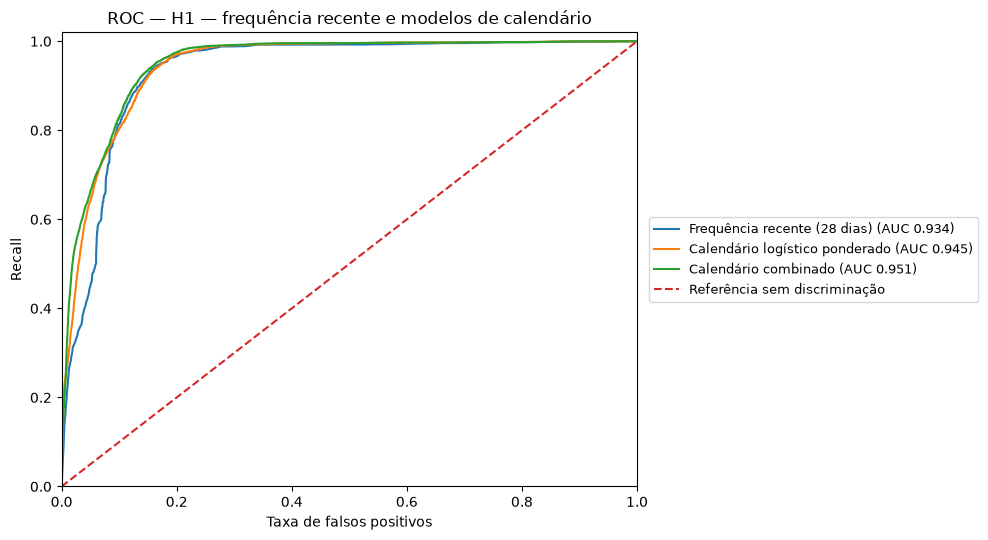

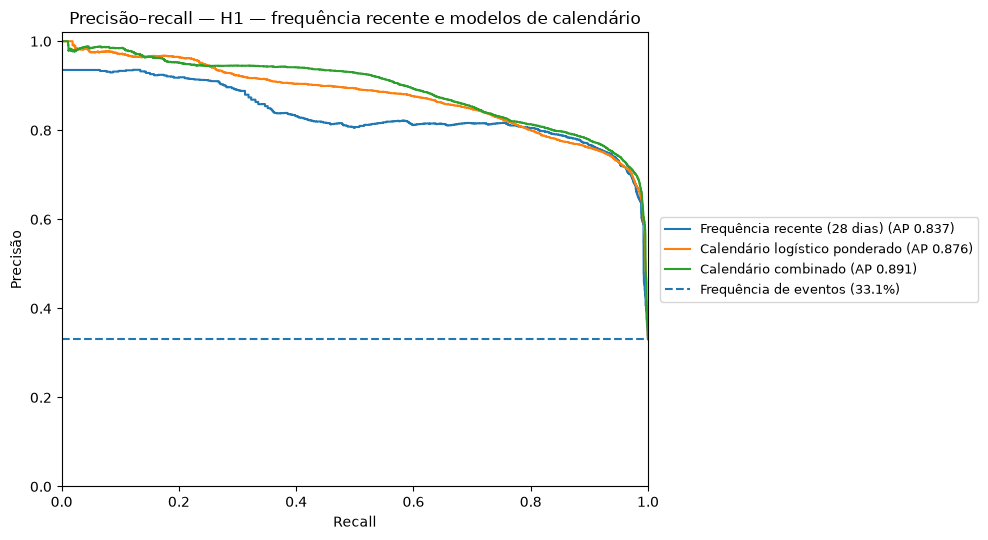

**Matriz de confusão do calendário combinado — linhas: realidade; colunas: decisão**

,Sem alerta,Com alerta
Sem ENE > 2%,19380,3910
Com ENE > 2%,522,10999


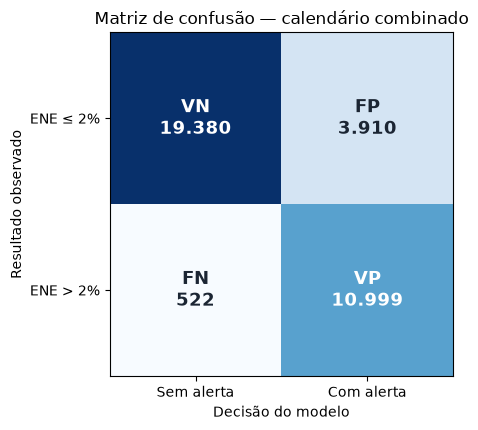

In [79]:
sistemas_h1={
 nome_frequencia:frequencia_recente,
 'Calendário logístico ponderado':previsoes_combinadas[(previsoes_combinadas.protocol=='P2')&
                                                    (previsoes_combinadas.system=='A_log')].copy(),
 'Calendário combinado':previsoes_combinadas[(previsoes_combinadas.protocol=='P2')&
                                           (previsoes_combinadas.system=='A_multiscale')].copy()
}
res_h1=cmp.painel(sistemas_h1,'h1_calendarios','H1 — frequência recente e modelos de calendário',
 'Ocorrência de ENE > 2%; mesmas horas; atualização mensal. Os limiares das decisões foram escolhidos anteriormente.',
 curvas=('roc','pr'))
# Matriz de confusão REAL do calendário combinado, com sua regra de alerta já selecionada.
from sklearn.metrics import confusion_matrix
modelo_confusao=sistemas_h1['Calendário combinado']
cm=confusion_matrix(modelo_confusao.y,modelo_confusao.p>=modelo_confusao.threshold,labels=[0,1])
mat_conf=pd.DataFrame(cm,index=['Sem ENE > 2%','Com ENE > 2%'],
                      columns=['Sem alerta','Com alerta'])
assert int(cm.sum())==len(modelo_confusao)
tabela(mat_conf,'h1_matriz_confusao',
 'Matriz de confusão do calendário combinado — linhas: realidade; colunas: decisão')
fig,ax=plt.subplots(figsize=(6.8,4.4))
ax.imshow(cm,cmap='Blues')
for (i,j),valor in np.ndenumerate(cm):
    sigla={ (0,0):'VN', (0,1):'FP', (1,0):'FN', (1,1):'VP'}[(i,j)]
    ax.text(j,i,f'{sigla}\n{valor:,}'.replace(',','.'),ha='center',va='center',
            color='white' if valor>=cm.max()/2 else '#1b2533',fontsize=13,fontweight='bold')
ax.set_xticks([0,1],['Sem alerta','Com alerta'])
ax.set_yticks([0,1],['ENE ≤ 2%','ENE > 2%'])
ax.set(xlabel='Decisão do modelo',ylabel='Resultado observado',
       title='Matriz de confusão — calendário combinado')
fig.tight_layout();figura(fig,'h1_confusao_figura')


In [80]:
intervalos_h1 = tabela_intervalos(sistemas_h1, [
    (nome_frequencia, 'Calendário logístico ponderado', 'Logístico − frequência recente'),
    (nome_frequencia, 'Calendário combinado', 'Combinado − frequência recente'),
    ('Calendário logístico ponderado', 'Calendário combinado', 'Combinado − logístico')],
    'h1_intervalos_pareados')


Comparação,Métrica,Diferença observada,Intervalo 95% — blocos de 7 dias,Intervalo 95% — blocos de 28 dias
Logístico − frequência recente,AP,"0,0388","[+0,00142; +0,08609]","[+0,00277; +0,10377]"
Combinado − frequência recente,AP,"0,0536","[+0,01986; +0,09573]","[+0,01785; +0,10787]"
Combinado − logístico,AP,"0,0148","[-0,00025; +0,03438]","[+0,00296; +0,02775]"


**O calendário contém informação preditiva.** A logística ponderada alcança AP de aproximadamente **0,876**; o calendário combinado, **0,891**. A ROC-AUC aumenta de cerca de **0,945 para 0,951**, enquanto o Brier diminui de **0,1133 para 0,0935**. São duas melhorias observadas **sem acrescentar meteorologia**. Esse resultado é relevante porque estabelece uma referência exigente para qualquer fonte adicional de informação.

As métricas de decisão também mostram um compromisso: com os limiares definidos no desenvolvimento, o calendário combinado aumenta a **precisão** de aproximadamente 68,5% para 73,8% e o **F1** de 0,805 para 0,832, mas reduz o **recall** de aproximadamente 97,7% para 95,5%. A matriz de confusão mostra os números absolutos por trás dessas taxas. Limiar diferente não altera AP nem ROC-AUC, mas influencia as decisões.

Na amostra avaliada, a comparação mostra a utilidade de combinar formas de aprender o calendário; **não isola qual componente da combinação produziu todo o ganho**. A descoberta central é que o calendário, quando bem modelado, já distingue muitos eventos, sem medir diretamente as condições atmosféricas.

**O contraste com a regra empírica torna a evidência mais exigente.** A frequência recente alcança AP de aproximadamente **0,837**: os padrões identificados na EDA já são úteis mesmo sem regressão ou árvores. A logística acrescenta cerca de **0,039** e a combinação, **0,054** de AP. Os intervalos desses dois incrementos permanecem positivos nos tamanhos de bloco examinados, especialmente no contraste combinado − frequência recente.

Isso não significa superioridade em toda decisão. Com seus limiares de validação, frequência recente e combinado têm F1 muito próximo: aproximadamente **0,831 e 0,832**. O combinado deixa passar **522** horas positivas, contra **785** da referência, mas emite **3.910** alertas falsos, contra **3.580**. A melhora de ranking convive, portanto, com um compromisso entre eventos detectados e alertas falsos.

**A vantagem adicional da combinação sobre a logística é menos estável.** Sua diferença pontual de AP é cerca de +0,0148; o intervalo semanal inclui zero, enquanto o de 28 dias permanece positivo. A conclusão da **H1 — os padrões de calendário contêm informação preditiva sobre ENE** é favorável; a afirmação mais específica de que combinar os calendários é sempre melhor deve ser mais cautelosa. Esses intervalos se referem à AP, não a uma análise de incerteza de todas as métricas da tabela.


### 15.2. H2 — Acrescentar informações meteorológicas melhora a previsão de ENE em relação ao calendário?

As análises de vento e rajadas sugerem relações com as restrições, mas associação não garante valor preditivo adicional: o vento também varia por hora e época do ano. Para testar o incremento, comparamos **dois LightGBM da mesma família**, ajustados na mesma população e com a mesma janela recente de treinamento. Ambos recebem calendário e interações regionais; **o segundo também recebe meteorologia ampliada**, incluindo informações de vento, rajada, variabilidade, direção e resumos de estações disponíveis antes do alvo.

A comparação utiliza **34.811 observações de abril–setembro de 2026**, com atualização mensal. O algoritmo e a política temporal são mantidos, mas a regularização foi ajustada separadamente no desenvolvimento (L2 = 40 e 10, respectivamente). Por isso, o contraste é entre **dois modelos comparáveis da mesma família**, e não uma ablação com absolutamente todos os parâmetros fixos.


**H2 — mesmo algoritmo com e sem meteorologia**

LightGBM, interações regionais, janela de três meses e atualização mensal; ENE > 2%.

Mesmas **34,811 observações região × hora**, **11,521 eventos positivos** (**33.10%**).

Modelo,AP ↑,ROC-AUC ↑,Brier ↓,Log loss ↓,Probabilidade média
Calendário com interações,"0,8877","0,9496","0,0872","0,2708","0,2923"
Calendário + meteorologia ampliada,"0,8994","0,9547","0,0799","0,2531","0,3102"


Modelo,Limiar de decisão,Precisão ↑,Recall ↑,F1 ↑,Especificidade ↑,Acurácia ↑
Calendário com interações,0.15 a 0.44,"0,7727","0,8810","0,8233","0,8718","0,8748"
Calendário + meteorologia ampliada,0.22 a 0.49,"0,7777","0,8567","0,8153","0,8789","0,8715"


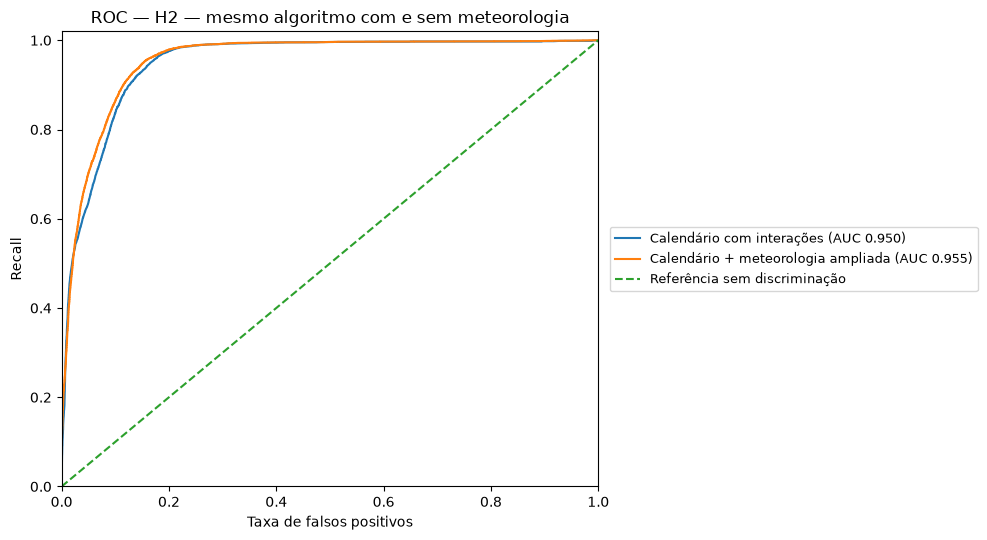

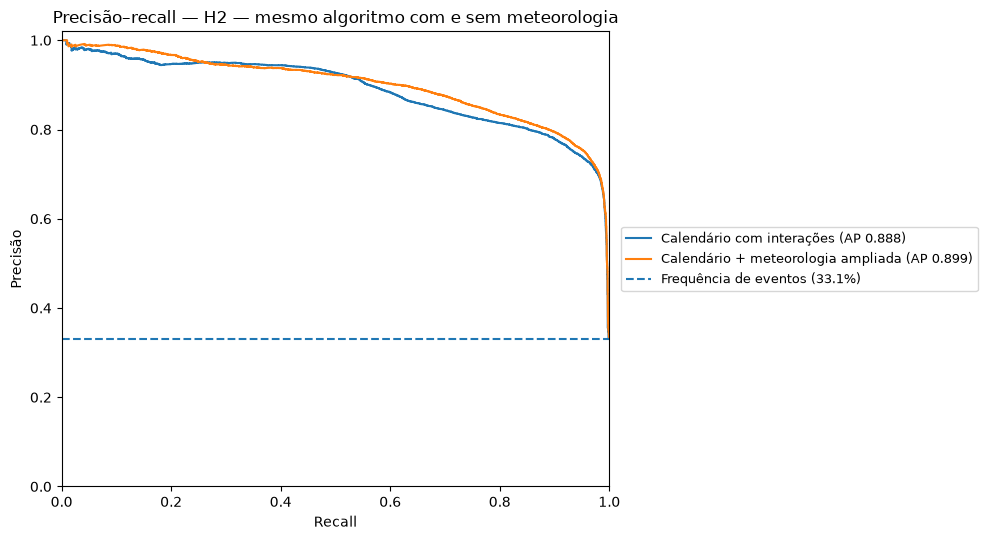

In [81]:
sistemas_h2={
 'Calendário com interações':previsoes_temporais[(previsoes_temporais.evidence=='E3')&
   (previsoes_temporais.protocol=='P2')&(previsoes_temporais.reason=='ENE')&
   (previsoes_temporais.variant=='A')].copy(),
 'Calendário + meteorologia ampliada':previsoes_temporais[(previsoes_temporais.evidence=='E3')&
   (previsoes_temporais.protocol=='P2')&(previsoes_temporais.reason=='ENE')&
   (previsoes_temporais.variant=='B')].copy()
}
res_h2=cmp.painel(sistemas_h2,'h2_meteorologia','H2 — mesmo algoritmo com e sem meteorologia',
 'LightGBM, interações regionais, janela de três meses e atualização mensal; ENE > 2%.',
 curvas=('roc','pr'))


In [82]:
intervalos_h2 = tabela_intervalos(sistemas_h2, [
    ('Calendário com interações', 'Calendário + meteorologia ampliada', 'Meteorologia − calendário')],
    'h2_intervalos_pareados', metricas=('AP','Brier'))


Comparação,Métrica,Diferença observada,Intervalo 95% — blocos de 7 dias,Intervalo 95% — blocos de 28 dias
Meteorologia − calendário,AP,"0,0117","[-0,00553; +0,03379]","[-0,00583; +0,03927]"
Meteorologia − calendário,Brier,"-0,0073","[-0,01283; -0,00224]","[-0,01383; -0,00159]"


**Nessa configuração, as métricas pontuais favorecem a inclusão de meteorologia.** A AP passou de aproximadamente **0,888 para 0,899**, a ROC-AUC de **0,950 para 0,955**, e o Brier caiu de **0,0872 para 0,0799**. Na amostra avaliada, isso indica melhora na ordenação e na qualidade global das probabilidades da previsão.

Entretanto, nem todas as métricas melhoraram: com os limiares escolhidos para cada modelo, o **recall** caiu de aproximadamente **88,1% para 85,7%**, e o **F1** de 0,823 para 0,815. A precisão subiu um pouco e a especificidade também. Portanto, um modelo pode melhorar AP e Brier sem produzir, sob a regra de alerta considerada, mais eventos corretamente detectados.

A conclusão pontual é **favorável em parte das métricas desse par de modelos**, não universal. Em comparações complementares de logística com vento básico, acrescentar meteorologia por vezes diminuiu AP. Parte dessas diferenças também depende da cobertura e da população considerada. Não concluímos que todo atributo de vento, em qualquer modelo, melhora a previsão de ENE.

**A incerteza distingue as duas formas de benefício.** O ganho de AP é aproximadamente **+0,0117**, mas seus intervalos com blocos de 7 e 28 dias incluem zero. Assim, não estabelecemos uma vantagem estável de ordenação sob esse procedimento. Já a diferença de Brier é aproximadamente **−0,00730**, com ambos os intervalos inteiramente negativos: há evidência favorável à redução dessa perda probabilística nesse par.

A resposta à **H2 — acrescentar meteorologia melhora a previsão de ENE em relação ao calendário** continua sendo condicional. A informação meteorológica reduz o Brier neste experimento, sem que o ganho de AP fique robustamente estabelecido pelos blocos. Brier não mede exclusivamente calibração; sua redução não identifica, sozinha, qual aspecto das probabilidades melhorou. As regularizações dos dois finalistas foram selecionadas separadamente, como documentado na seção 13.


<a id="h2-importancia"></a>

#### 15.2.1. Da previsão ao entendimento: quais atributos meteorológicos importam?

A H2 começou com a comparação entre calendário (A) e calendário acrescido de meteorologia (B). O modelo B utiliza **51 variáveis meteorológicas**, produzidas a partir de medições e resumos temporais/espaciais. Como cada uma tem também um indicador explícito de ausência, somamos **51 valores + 51 indicadores + seis categorias de calendário**, ou **108 entradas efetivas**.

Contudo, **influenciar a previsão não significa ser indispensável**. Um modelo pode usar intensamente uma variável, enquanto outra contém quase a mesma informação. Também pode depender de uma família de variáveis sem depender muito de qualquer membro isolado. Por isso, não eliminamos automaticamente as colunas de baixa importância.

Nosso procedimento possui três perguntas complementares:

1. **SHAP — explicação:** como cada entrada participa das previsões dos seis modelos B históricos?
2. **Permutação — dependência:** quanto piora o desempenho de B se perturbarmos uma variável ou família, mantendo suas árvores?
3. **Ablação e seleção — necessidade:** após novo treinamento, conseguimos manter o desempenho com menos variáveis?

Para a terceira pergunta, a escolha dos atributos usa apenas o **desenvolvimento temporalmente admissível**; as listas são congeladas antes da avaliação de abril–setembro/2026. A escolha ocorreu retrospectivamente, depois de o semestre já ter sido examinado em análises anteriores: mesmo com controles temporais, **não é uma confirmação prospectiva ou originalmente cega**.

Esta versão do notebook **recalcula estatísticas, agregações e figuras a partir de resultados científicos persistidos**. Não retreina LightGBM nem refaz a campanha SHAP ou as permutações; os procedimentos integrais estão documentados separadamente.


In [83]:
h2 = importar_modulo('h2_aprofundamento', ROOT/'codigo/h2_aprofundamento.py')
h2_recibo = h2.verificar_insumos(ROOT)
print(f"{h2_recibo['insumos_verificados']} insumos e documentos de proveniência conferidos por SHA-256.")
print('Listas congeladas preservadas. Nenhum novo ajuste ou seleção nesta seção.')


91 insumos e documentos de proveniência conferidos por SHA-256.
Listas congeladas preservadas. Nenhum novo ajuste ou seleção nesta seção.


#### 15.2.2. SHAP: como os atributos se combinam em uma previsão?

Um LightGBM produz um escore antes de convertê-lo em probabilidade. Para uma observação $x$ e o modelo mensal $m$, as contribuições SHAP decompõem esse escore, chamado **margem bruta** [8, 9]:

$$f_m(x)=b_m+\sum_{j=1}^{108}\phi_{m,j}(x),\qquad
p_m(x)=\frac{1}{1+\exp[-f_m(x)]}.$$

- $b_m$ é a **margem de referência do próprio modelo B daquele mês**, não a previsão do modelo A (calendário).
- $\phi_{m,j}$ representa a contribuição atribuída a uma entrada; contribuições positivas aumentam a margem em relação à referência e negativas a reduzem.
- A soma completa é convertida pela **sigmoide** em probabilidade da classe positiva: restrição **ENE acima de 2%**. Uma contribuição de $+0,5$ em log-odds **não é um aumento de 50 pontos percentuais**: a mudança de probabilidade depende da margem inicial.

As contribuições foram calculadas com `pred_contrib=True` do LightGBM 4.7.0, nos **seis modelos B históricos**, preservando seus próprios valores de referência. A campanha conferiu a margem nativa e a probabilidade. Aqui repetimos a verificação com as contribuições armazenadas e apresentamos **uma previsão real selecionada pela regra objetiva da campanha**: verdadeiro positivo de junho/2026, região A426, em 05/06 às 16h. Ela não é uma observação sintética nem foi escolhida para maximizar uma contribuição meteorológica.

Nesse exemplo, a margem-base é **−2,6146** (probabilidade-base de aproximadamente **6,82%**). As seis entradas de calendário somam **+2,2323** e as 102 entradas meteorológicas, **+2,0916**. A margem final é **+1,7093**, cuja sigmoide produz **84,67%**, igual à previsão registrada. O gráfico e a tabela seguintes detalham a conta. **Essa decomposição explica B**, sem representar efeitos físicos causais ou uma comparação contrafactual com A.

Para resumir a importância, tratamos cada variável meteorológica e seu indicador de ausência como uma **variável lógica**: $\psi_j=\phi_{j,valor}+\phi_{j,ausência}$. A importância global é a média de $|\psi_j|$ nas **34.811 observações**, mantendo o peso de cada linha. Também preservamos as contribuições dos componentes separadamente.


origin,n,base_value,margin_max_residual,probability_max_residual,repeat_max_residual,positive_class,scale,contribution_columns
P2_2026-04,5694,"-3,031070","0,000000","0,000000","0,000000",1,log-odds,108
P2_2026-05,5896,"-2,829303","0,000000","0,000000","0,000000",1,log-odds,108
P2_2026-06,5702,"-2,614604","0,000000","0,000000","0,000000",1,log-odds,108
P2_2026-07,5891,"-2,506200","0,000000","0,000000","0,000000",1,log-odds,108
P2_2026-08,5894,"-2,090919","0,000000","0,000000","0,000000",1,log-odds,108
P2_2026-09,5734,"-2,048723","0,000000","0,000000","0,000000",1,log-odds,108


Resíduo máximo recalculado de sigmoid(base + soma SHAP): 2.1094237467877974e-15
Maior contribuição absoluta dos indicadores explícitos: 0.0


Parcela,Contribuição (log-odds)
Margem-base do B,"-2,614604"
Calendário — seis entradas,"2,232300"
Meteorologia — 102 entradas,"2,091612"
Margem final,"1,709308"


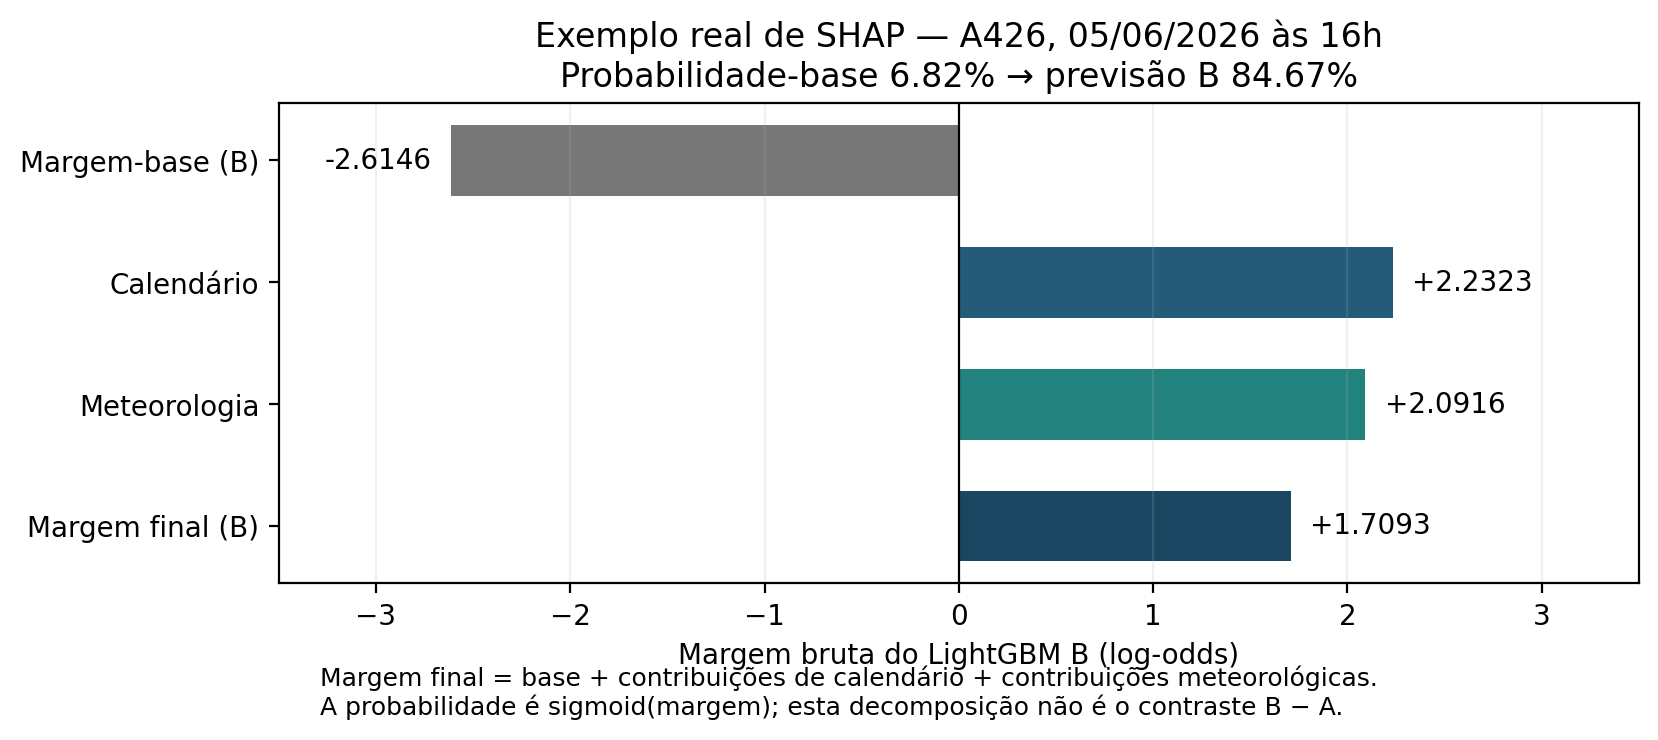

In [84]:
h2_shap = h2.carregar_shap(ROOT)
h2_controle = h2.csv(ROOT, 'importancia', 'evaluation/shap_verification.csv')
h2.mostrar(h2_controle, ROOT, 'h2_shap_aditividade',
           'Verificações da campanha nos seis modelos; resíduos na margem e na probabilidade')
print('Resíduo máximo recalculado de sigmoid(base + soma SHAP):', h2_shap['qc']['probability_residual'])
print('Maior contribuição absoluta dos indicadores explícitos:', h2_shap['qc']['max_abs_indicator'])
h2_shap['variables'].to_csv(OUT/'tabelas/h2_shap_51_variaveis.csv', index=False)
# Exemplo real selecionado antes desta revisão: TP de junho, sem procurar a previsão mais conveniente.
h2_exemplo = h2.exemplo_shap_local(ROOT)
h2.mostrar(pd.DataFrame([{'Parcela':'Margem-base do B','Contribuição (log-odds)':h2_exemplo['base']},
                         {'Parcela':'Calendário — seis entradas','Contribuição (log-odds)':h2_exemplo['calendar']},
                         {'Parcela':'Meteorologia — 102 entradas','Contribuição (log-odds)':h2_exemplo['meteorology']},
                         {'Parcela':'Margem final','Contribuição (log-odds)':h2_exemplo['margin']}]),
          ROOT,'h2_exemplo_shap_numerico',
          f"Exemplo real: A426, 05/06/2026 às 16 h; p(B) = {h2_exemplo['probability']:.6f}")
h2.guardar_figura(h2.figura_exemplo_shap(h2_exemplo),ROOT,'h2_shap_exemplo_local')


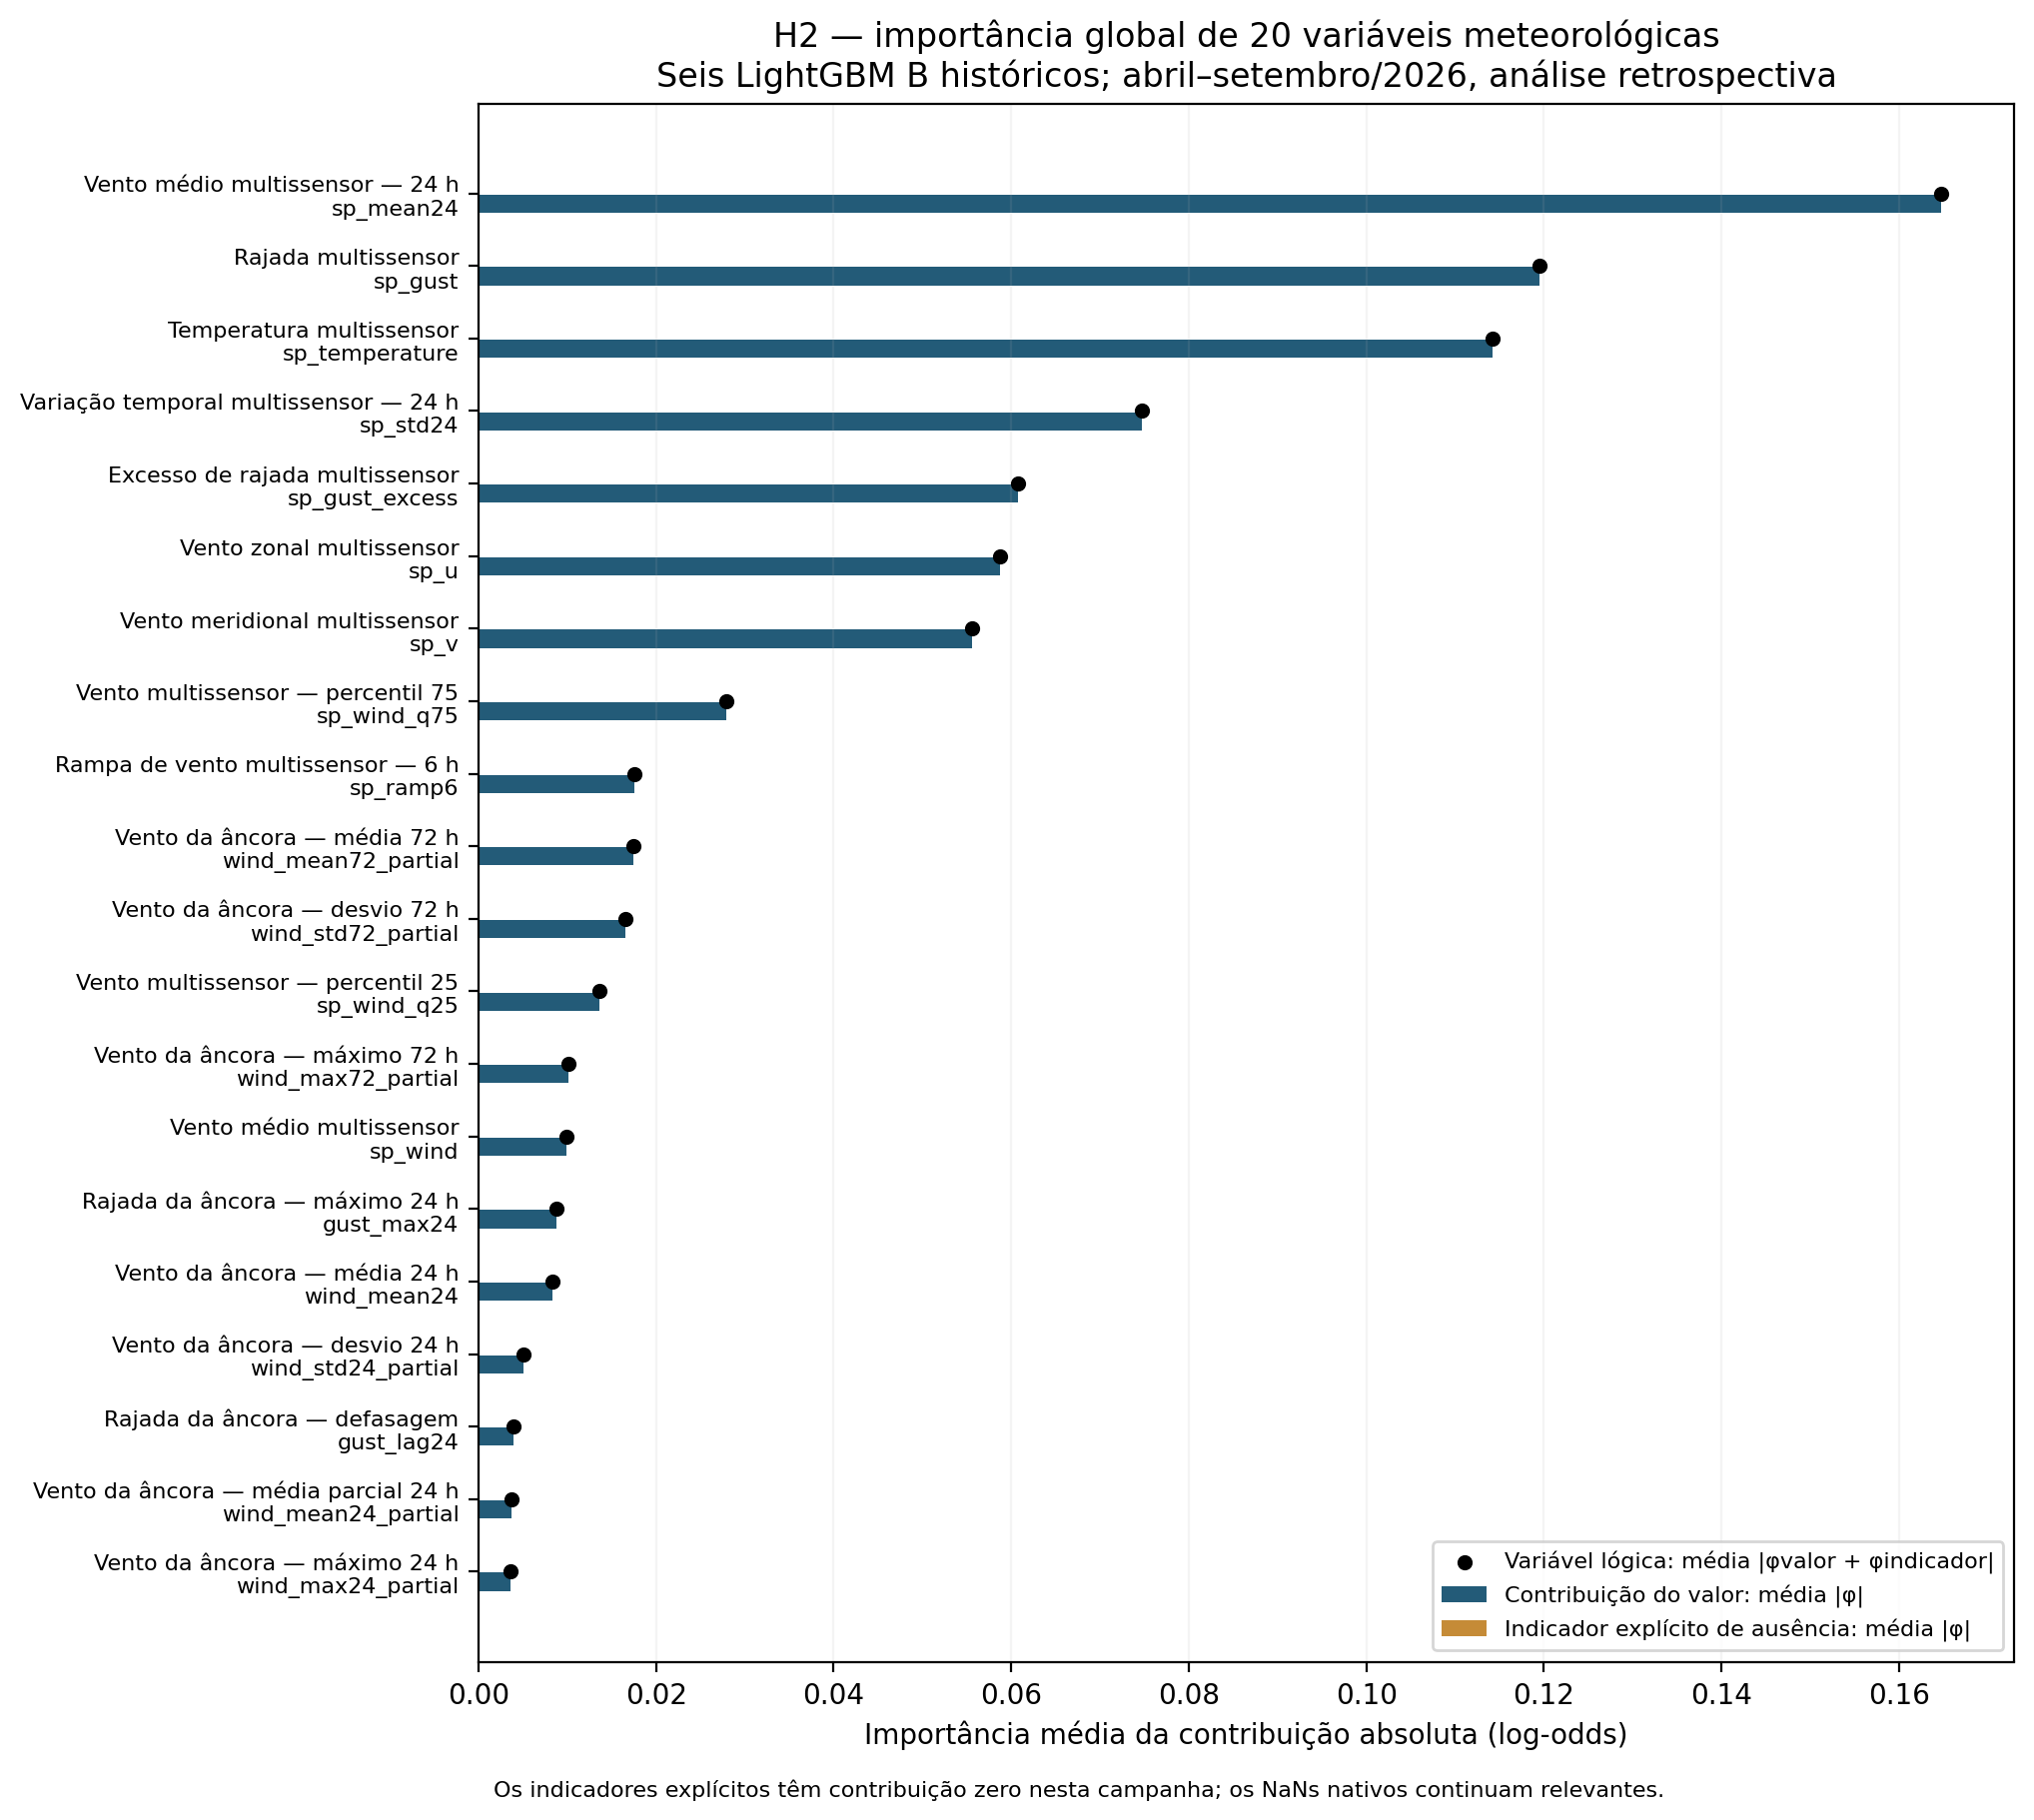

In [85]:
h2.guardar_figura(h2.figura_shap_global(h2_shap), ROOT, 'h2_shap_importancia_global')


**Da previsão individual ao padrão geral.** A decomposição local anterior descreve **uma hora específica**. Para saber o que costuma influenciar B, calculamos a média das contribuições absolutas das variáveis meteorológicas em **todas as 34.811 observações**. Isso produz um ranking de influência *sobre as previsões do modelo*, não uma medida direta da perda de AP causada pela remoção da variável.

As maiores importâncias são de **`sp_mean24` (média de vento multissensor nas 24 h anteriores admissíveis), `sp_gust` (rajada multissensor) e `sp_temperature` (temperatura multissensor)**. O gráfico apresenta as 20 maiores e a tabela CSV conserva todas as 51. Os nomes técnicos permanecem no gráfico para permitir correspondência exata com os dados, acompanhados de descrições físicas.

Os **51 indicadores explícitos de ausência não tiveram splits nem SHAP diferente de zero** nos modelos examinados. Isso não significa que faltar uma medição seja irrelevante: o LightGBM também usa os próprios valores `NaN` para decidir caminhos nas árvores, e `sp_count` ou `sp_distance` carregam informação sobre a disponibilidade e a composição da rede de sensores.

No **beeswarm**, cada ponto é uma observação real: a posição horizontal é a contribuição (log-odds), a cor representa o **percentil do valor válido** daquela variável e uma cruz cinza marca valor ausente. À direita de zero a contribuição é positiva; à esquerda, negativa. A amostragem de até 4.000 pontos por variável é **apenas para exibição**; os rankings utilizam todas as observações. Nem a posição vertical deslocada nem a cor representam outra previsão.


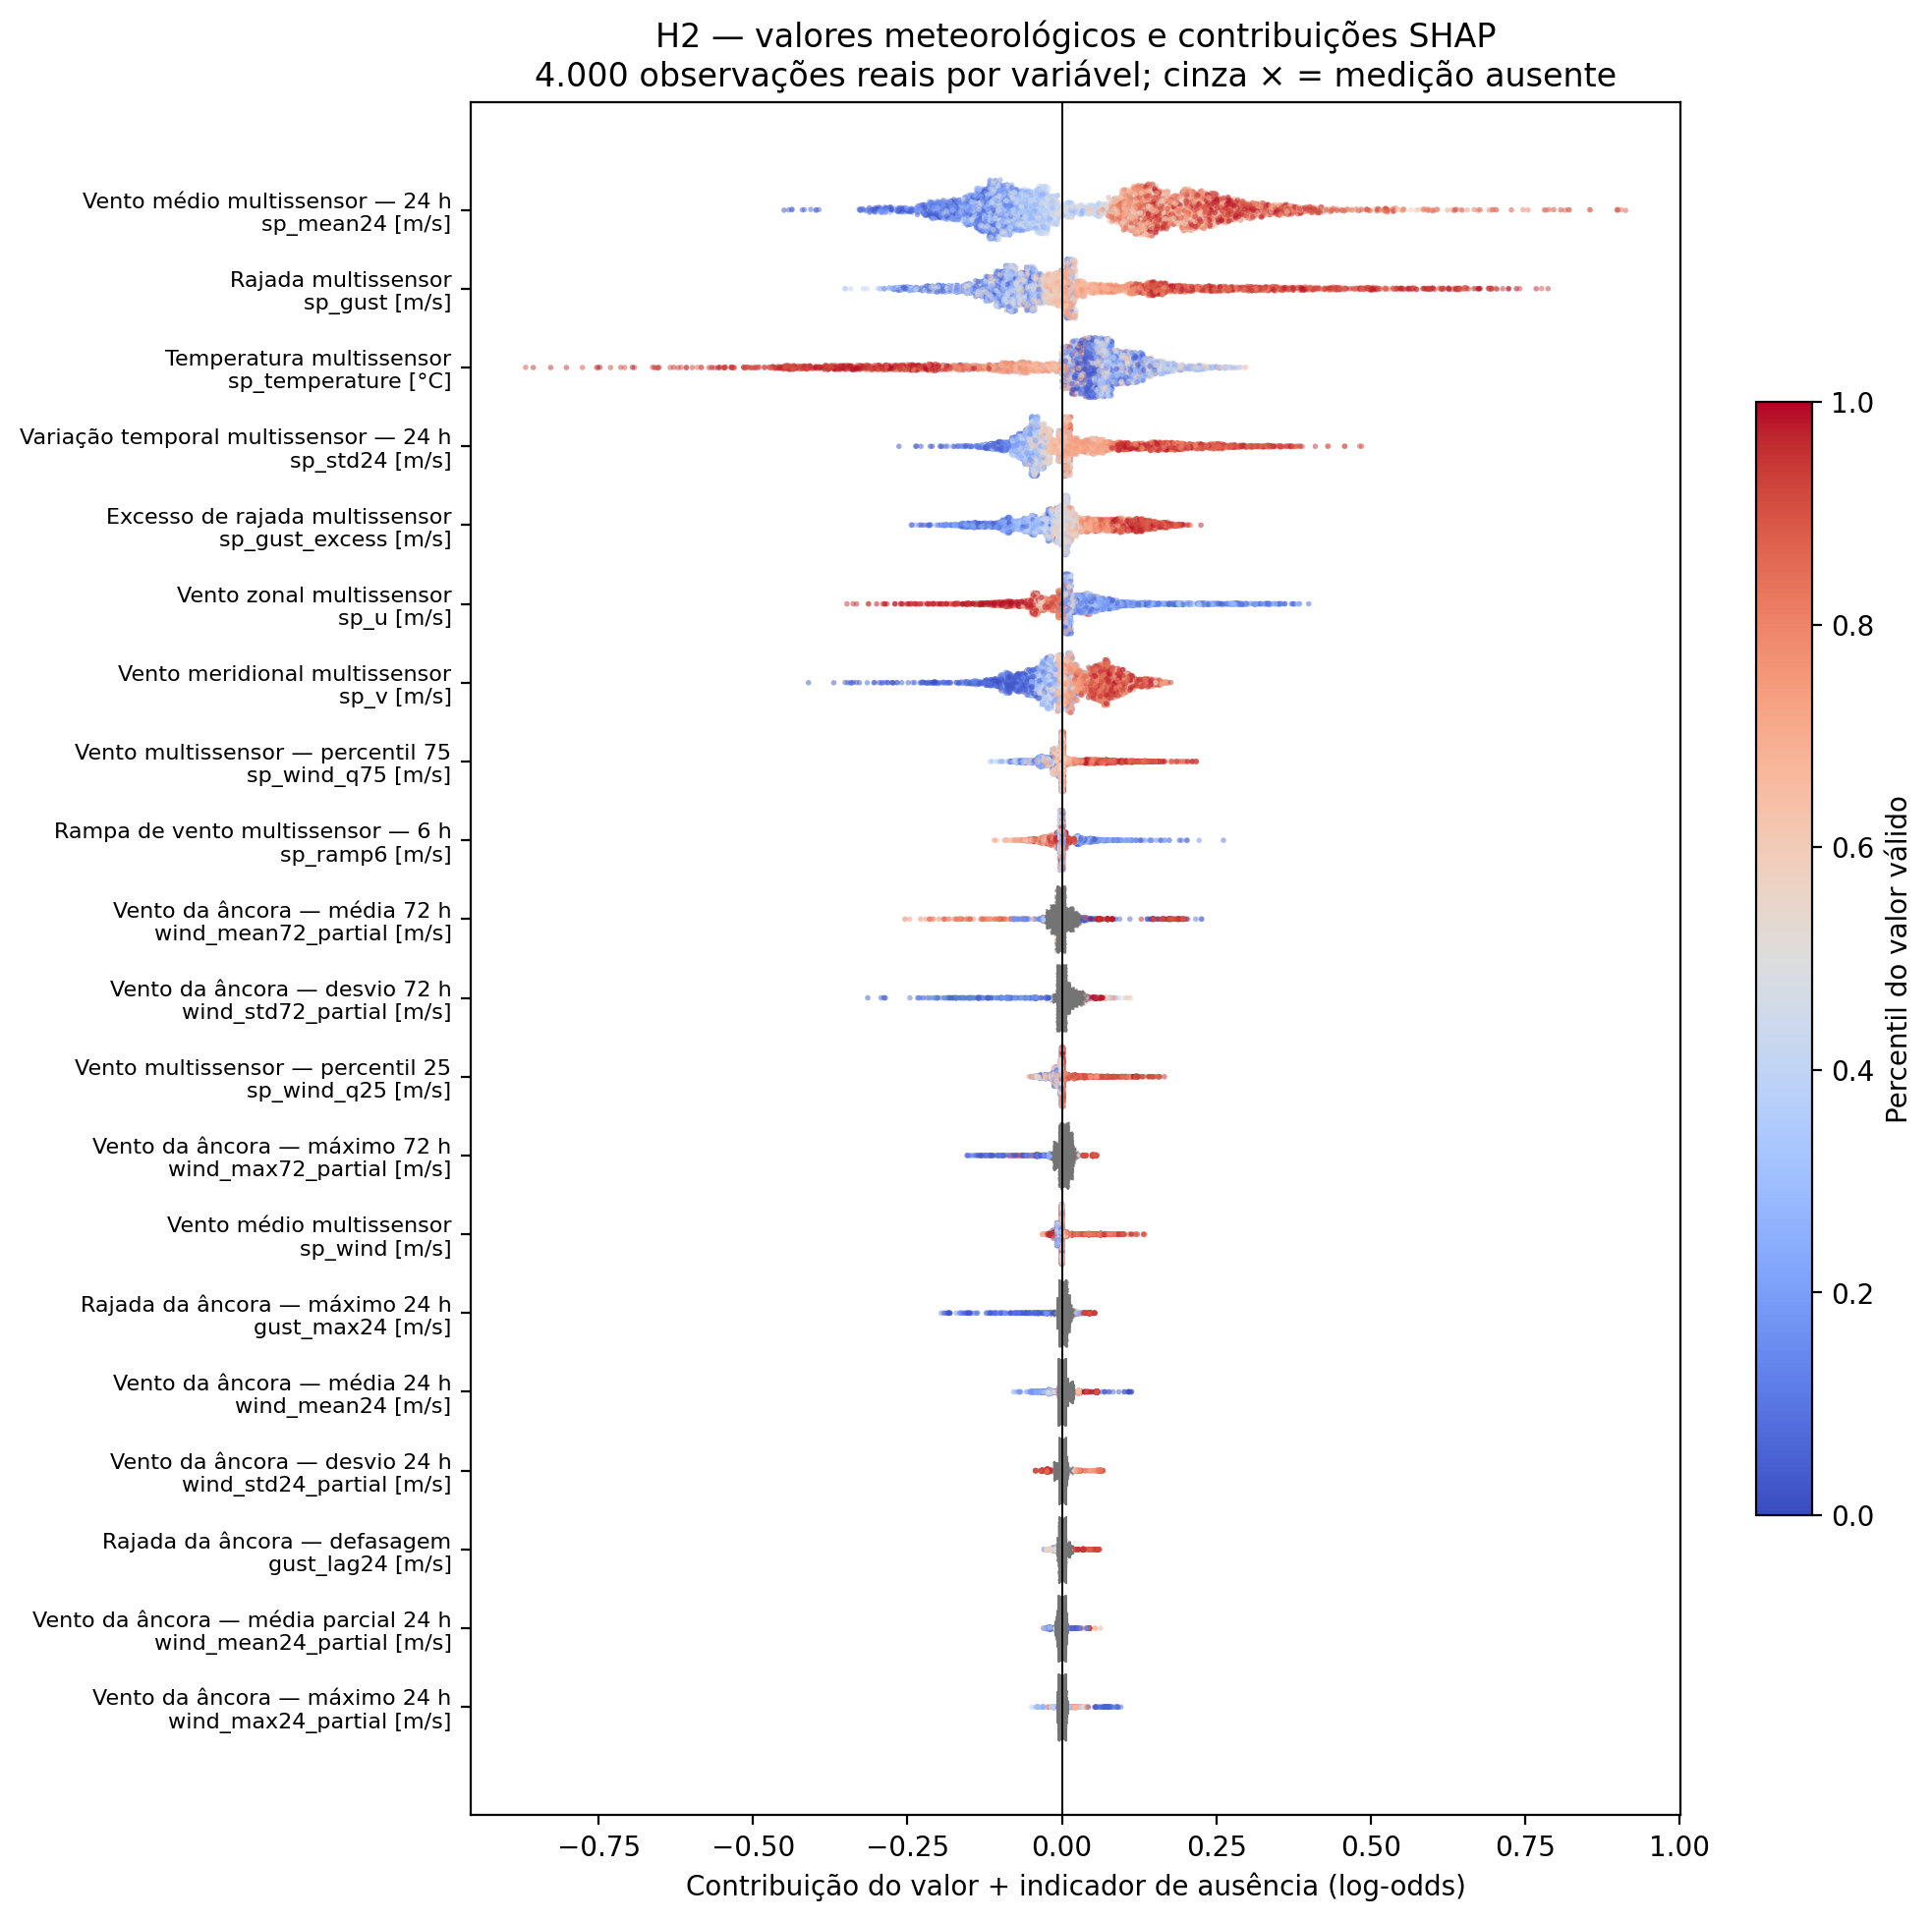

In [86]:
h2.guardar_figura(h2.figura_beeswarm(h2_shap), ROOT, 'h2_shap_beeswarm')


**Os valores altos sempre elevam o risco previsto?** Não necessariamente. Em parte das observações, valores maiores de vento e rajada multissensor estão associados a contribuições positivas; temperaturas mais altas aparecem frequentemente com contribuições negativas. O sinal depende também da hora, região, mês, variáveis correlacionadas e árvores ajustadas. O beeswarm mostra **associações aprendidas**, não a resposta física a uma intervenção sobre o vento.

Para compreender blocos de informação em vez de apenas atributos isolados, agrupamos as 51 variáveis em **quatro famílias físicas**: vento/rajada da estação âncora (**8**); dinâmica e resumos temporais (**20**); direção e outras medições atmosféricas (**9**); e dados de várias estações (**14**). O arquivo operacional original organiza os grupos como **8/22/7/14**, porque coloca duas componentes direcionais da âncora na categoria de engenharia temporal. A ordem e os valores das 51 entradas não mudam.

Há duas formas diferentes de agregar contribuições de uma família $F$:

$$\underbrace{E\!\left(\left|\sum_{j\in F}\psi_j\right|\right)}_{\text{contribuição líquida absoluta}}
\quad\text{e}\quad
\underbrace{\sum_{j\in F}E(|\psi_j|)}_{\text{soma de magnitudes individuais}}.$$

Na primeira, contribuições de sinais opostos podem se cancelar **antes** do módulo; na segunda, somamos intensidades independentemente do sinal. Nenhuma dessas operações refaz um cálculo de Shapley usando **famílias inteiras** como participantes. O gráfico seguinte exibe ambas para não confundi-las.


Família,Variáveis,Média |soma da família|,Soma das médias |variável|,Participação na soma individual (%)
Vento/rajada na âncora,8,"0,020152","0,025184","3,086052"
Dinâmica temporal,20,"0,036582","0,061860","7,580264"
Direção e atmosfera,9,"0,005263","0,007003","0,858180"
Multissensor,14,"0,420786","0,722013","88,475504"
Toda a meteorologia,51,"0,441560","0,816060","100,000000"


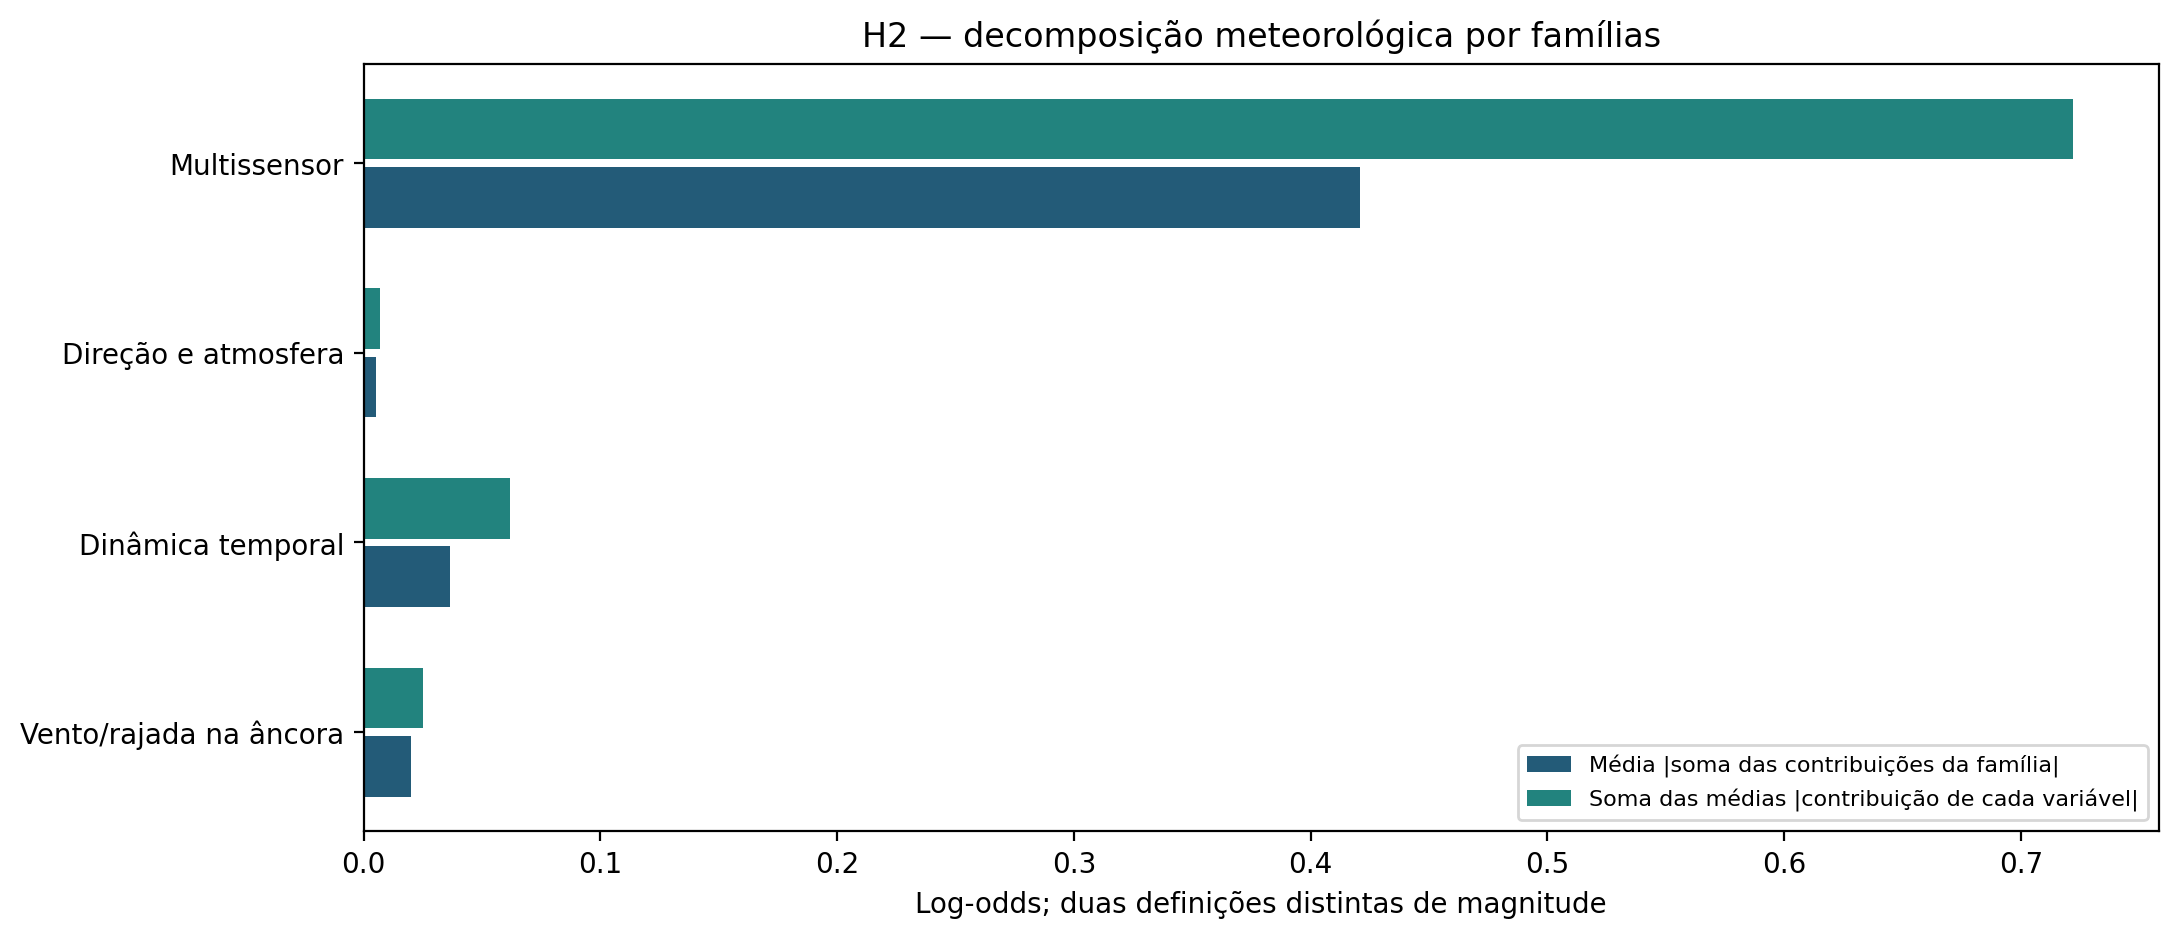

In [87]:
h2_fam = h2_shap['families'].copy()
h2_fam['family'] = h2_fam.family.map(h2.LABELS)
h2.mostrar(h2_fam.rename(columns={'family':'Família','n_features':'Variáveis',
    'mean_abs_family_sum':'Média |soma da família|','sum_mean_abs_variables':'Soma das médias |variável|',
    'share_sum_percent':'Participação na soma individual (%)'}), ROOT, 'h2_shap_familias',
    'Magnitudes em log-odds; participação relativa somente dentro da meteorologia')
h2.guardar_figura(h2.figura_familias(h2_shap), ROOT, 'h2_shap_familias')


A família **multissensor responde por 88,48% da soma das magnitudes SHAP das variáveis meteorológicas**. O denominador inclui apenas as 51 variáveis meteorológicas, **não o calendário**; logo, 88,48% não é a fração do desempenho explicado, da probabilidade prevista ou de um efeito causal. A mensagem é mais específica: **dentro de B, a maior parte da influência meteorológica atribuída pelo método está concentrada nas representações de várias estações**.

Essa concentração é coerente com a cobertura irregular da âncora observada na EDA: integrar sensores pode preservar informação nas horas em que uma única estação falha. Mas não demonstra que cada sensor adicional seja indispensável ou que a integração reflita exatamente as condições no rotor.

**Importâncias não são estáticas no tempo.** `sp_mean24` lidera abril, maio e agosto; `sp_gust`, junho e julho; `sp_temperature`, setembro. A concordância de Spearman entre rankings mensais varia de **0,546 a 0,795**. Essas variações motivam avaliar a seleção em múltiplas origens. Meses e regiões compartilham árvores, sensores e episódios meteorológicos: não devem ser tratados como réplicas independentes.


#### 15.2.3. Permutation Importance: o que acontece quando retiramos informação sem retreinar?

SHAP distribui a saída do modelo entre suas entradas. Para perguntar **quanto o desempenho depende delas**, mantemos as árvores de B *fixas* e perturbamos os valores recebidos [10]. A importância é a piora da métrica:

$$I_{AP}=AP_{\rm original}-AP_{\rm perturbado},\qquad
I_{Brier}=Brier_{\rm perturbado}-Brier_{\rm original}.$$

Assim, valores **positivos** significam que a perturbação prejudicou o modelo; valores negativos, que a métrica melhorou sob a perturbação. Não descartamos sinais desfavoráveis. Foram perturbados os **51 atributos**, cada uma das **quatro famílias** e o bloco **meteorológico completo**, com **20 repetições** e dois comprimentos de bloco: **24 e 168 horas**.

Para não embaralhar arbitrariamente registros independentes, a campanha troca **blocos temporais completos dentro do mês e modelo**, usando a mesma correspondência entre blocos nas oito regiões. A posição da hora dentro do bloco é preservada; o calendário e os rótulos das horas de destino permanecem fixos. Cada **valor meteorológico e seu indicador de ausência viajam juntos**; a população de avaliação continua sendo exatamente a mesma, mesmo quando perturbamos `sp_wind`. Blocos finais incompletos permanecem intactos.

Essa é uma perturbação definida para **diagnosticar dependência preditiva**, não uma substituição fisicamente realista do tempo meteorológico. Pode criar combinações de vento e temperatura que nunca ocorreram juntas. Os quantis de 5%–95% das 20 repetições descrevem a **variabilidade da permutação**, não um intervalo de confiança de generalização. O notebook apresenta resultados persistidos, sem executar novas permutações.


In [88]:
h2_pi = h2.tabela_permutacao(ROOT)
h2_pi.to_csv(OUT/'tabelas/h2_permutacao_quantidades_e_quantis.csv', index=False)
h2_pi_central = h2_pi.pivot(index='target', columns='hours', values=['i_ap_mean','i_brier_mean'])
h2_pi_central = h2_pi_central.reindex(h2.FAMILIES+['all_meteorology'])
h2_pi_central.columns = [f'{"I_AP" if m=="i_ap_mean" else "I_Brier"} — {horas} h'
                        for m,horas in h2_pi_central.columns]
h2_pi_central.index = h2_pi_central.index.map(h2.LABELS)
h2.mostrar(h2_pi_central.rename_axis('Família perturbada').reset_index(), ROOT, 'h2_permutacao_familias',
           'Média das 20 perturbações por configuração; valores positivos = degradação')


Família perturbada,I_AP — 24 h,I_AP — 168 h,I_Brier — 24 h,I_Brier — 168 h
Vento/rajada na âncora,"0,000150","0,000199","0,000121","0,000107"
Dinâmica temporal,"0,000063","0,000293","0,000053","0,000071"
Direção e atmosfera,"0,000037","0,000033","0,000009","0,000006"
Multissensor,"0,029201","0,022421","0,013200","0,008449"
Toda a meteorologia,"0,031699","0,024626","0,013984","0,009105"


**O bloco multissensor é o principal ponto de dependência de B.** Perturbá-lo reduz a AP, em média, em **0,029201** (blocos de 24 h) ou **0,022421** (168 h). Perturbar **toda** a meteorologia reduz a AP em **0,031699** e **0,024626**, respectivamente. As outras famílias têm degradações conjuntas menores. A coincidência qualitativa com SHAP é relevante, mas as magnitudes **não** são comparáveis: uma está em **log-odds** e a outra em **pontos absolutos de AP**.

Uma distinção impede uma interpretação enganosa: **$I_{AP}$ não é $AP(B)-AP(A)$**. No primeiro caso, damos meteorologia perturbada a um modelo B que já aprendeu a utilizá-la; no segundo, comparamos **modelos diferentes ajustados em separado**, inclusive com regularização distinta. Por isso, é perfeitamente possível ter **0,031699** de dependência por permutação e apenas **0,011699** de diferença pontual B−A.

Além disso, variáveis correlacionadas podem compensar umas às outras. `sp_temperature`, por exemplo, tem SHAP global elevado, mas baixa importância individual por permutação em certas configurações. **SHAP responde “como a previsão foi construída?”; permutação responde “quanto esse modelo fixo sente uma perturbação?”**. Para saber se podemos eliminar atributos sem perder desempenho, precisamos **retreinar** com um subconjunto e avaliá-lo temporalmente.


<a id="h2-selecao"></a>

#### 15.2.4. Do diagnóstico à seleção: reduzir sem usar a avaliação final

A análise anterior destacou o multissensor, mas **não escolhemos variáveis olhando seus rankings de abril–setembro/2026**. Para testar redução, organizamos um **novo desenvolvimento com 15 origens mensais entre janeiro/2025 e março/2026**, diferente dos **três blocos F1–F3** usados na seleção histórica da H2. Em cada origem, o ajuste utiliza uma janela móvel de **três meses de calendário**.

A previsão da hora-alvo $[t,t+1\mathrm{h})$ é emitida antes de $t$, com meteorologia disponível, sob o cenário adotado, somente até **$t-2$ h**. O rótulo é considerado conhecido **168 h após o fim da hora**. Assim, para a origem mensal $O$, a última hora admissível de treino é $O-170$ h (o corte exclusivo é $O-169$ h). A última validação termina em **24/03/2026 às 22h**, preservando o cenário de disponibilidade antes de abril.

**Onde se calcula o ranking?** Dentro do histórico de cada origem, um novo B é ajustado numa parcela cronologicamente anterior; as contribuições SHAP para ordenar atributos são calculadas numa **partição interna posterior, fora desse ajuste**, mas ainda anterior ao mês de validação. Selecionamos os top-k com desempate pela ordem histórica, mantendo pares direcionais juntos quando necessário. Só então cada variante é **retreinada na janela admissível completa** e avaliada fora dessa janela.

Todas as variantes utilizam a mesma elegibilidade (`y_ENE_02` conhecido e `sp_wind` disponível), mesmo que não recebam `sp_wind` como entrada. A primeira condição evita imputar eventos; a segunda impede que alterar o subconjunto mude silenciosamente a população de comparação. Os hiperparâmetros históricos permanecem fixos, com **L2=10** nos reduzidos. Nenhum resultado de abril–setembro participa do ranking ou da seleção.


In [89]:
h2_dev_datas = h2.csv(ROOT, 'desenvolvimento', 'split_dates.csv')
h2_dev_validacao = h2_dev_datas.loc[h2_dev_datas.role.eq('outer_validation')]
assert len(h2_dev_validacao)==15 and h2_dev_validacao.n.sum()==85185
assert pd.to_datetime(h2_dev_validacao.latest_label_available, utc=True).max() < pd.Timestamp('2026-04-01',tz=tz)
h2.mostrar(h2_dev_validacao[['origin','n','first','last']].rename(columns={
    'origin':'Origem','n':'Observações','first':'Primeira hora validada','last':'Última hora validada'}),
    ROOT,'h2_selecao_periodos','Desenvolvimento: 85.185 observações distintas, 18.913 positivas; março truncado')


Origem,Observações,Primeira hora validada,Última hora validada
2025-01,5950,2025-01-01 00:00:00-03:00,2025-01-31 23:00:00-03:00
2025-02,5347,2025-02-01 00:00:00-03:00,2025-02-28 23:00:00-03:00
2025-03,5942,2025-03-01 00:00:00-03:00,2025-03-31 23:00:00-03:00
2025-04,5747,2025-04-01 00:00:00-03:00,2025-04-30 23:00:00-03:00
2025-05,5912,2025-05-01 00:00:00-03:00,2025-05-31 23:00:00-03:00
2025-06,5684,2025-06-01 00:00:00-03:00,2025-06-30 23:00:00-03:00
2025-07,5828,2025-07-01 00:00:00-03:00,2025-07-31 23:00:00-03:00
2025-08,5857,2025-08-01 00:00:00-03:00,2025-08-31 23:00:00-03:00
2025-09,5624,2025-09-01 00:00:00-03:00,2025-09-30 23:00:00-03:00
2025-10,5824,2025-10-01 00:00:00-03:00,2025-10-31 23:00:00-03:00


O experimento considera **11 variantes**: calendário **A**, meteorologia completa **B**, apenas os **14 atributos multissensor** (`C_spatial`), políticas **top-5, top-10 e top-20**, retirada de cada uma das quatro famílias e um controle com as 51 variáveis meteorológicas, mas sem os indicadores explícitos de ausência.

Essas estratégias respondem a perguntas diferentes. **Top-k** tenta construir uma representação pequena a partir de importâncias internas; **retirar uma família** testa sua contribuição conjunta depois que as árvores podem se reajustar; **remover indicadores de ausência** avalia um detalhe da representação computacional, não a retirada de dados meteorológicos físicos. Não foi executada uma busca específica por representantes de clusters de correlação.

Antes da avaliação, registrou-se a margem prática de **0,01 de AP absoluta**. A regra considera um candidato reduzido **não inferior** somente quando os limites inferiores **nominais e simultâneos** de $AP(C)-AP(B)$ superam **−0,01**, para blocos de **168 e 672 h**. No desenvolvimento, a correção simultânea abrange os **oito candidatos reduzidos**. Essa margem é uma tolerância operacional pré-estabelecida, **não igualdade exata** entre modelos. Entre candidatos qualificados, o protocolo prioriza a representação com **menos variáveis**.


In [90]:
h2.mostrar(h2.tabela_desenvolvimento(ROOT), ROOT,'h2_selecao_desenvolvimento',
           'Desenvolvimento mensal: políticas top-k adaptativas, listas estruturais e ablações')


Estratégia,Variáveis meteorológicas,AP agrupada,AP mensal média,Brier,ΔAP vs B,Pior limite simultâneo,Critério
A,0,"0,713056","0,737986","0,111517","-0,003068",NaN,Referência/controle
B,51,"0,716124","0,739395","0,111076","0,000000",NaN,Referência/controle
C_spatial,14,"0,718922","0,739616","0,110567","0,002798","-0,000940",Satisfeito
C_top5,5–6,"0,714539","0,736189","0,111442","-0,001585","-0,009671",Satisfeito
C_top10,10–11,"0,716872","0,740063","0,111270","0,000748","-0,002822",Satisfeito
C_top20,20–21,"0,718017","0,742017","0,111301","0,001893","-0,001832",Satisfeito
B_minus_anchor,43,"0,719771","0,740308","0,110390","0,003647","-0,002125",Satisfeito
B_minus_temporal,31,"0,719226","0,739941","0,110420","0,003102","-0,001052",Satisfeito
B_minus_atmospheric,42,"0,714984","0,737760","0,111028","-0,001140","-0,005831",Satisfeito
B_minus_spatial,37,"0,710734","0,733872","0,111646","-0,005390","-0,016257",Não satisfeito


**O resultado negativo é tão informativo quanto os positivos.** Sete das oito reduções satisfizeram a regra agregada; **retirar a família multissensor não satisfez**: $\Delta AP=-0,005390$, pior limite inferior simultâneo **−0,016257** e perda de AP em **11 de 15 meses**. Isso reforça os diagnósticos SHAP e permutação: a informação espacial parece difícil de substituir completamente neste modelo.

Retirar a família âncora ou a temporal **melhorou pontualmente** a AP em **+0,003647** e **+0,003102**. Retirar direção/atmosfera trouxe pequena perda de **−0,001140**, ainda dentro da margem agregada. Tais resultados são compatíveis com redundância, mas não provam que cada variável descartada seja fisicamente irrelevante ou que nenhum mês tenha piorado.

A **política top-5 adaptativa** obteve AP **0,714539**, contra **0,716124** de B (diferença **−0,001585**). Seu pior limite simultâneo foi **−0,009671**, apenas **0,000329** acima da margem. O Brier piorou ligeiramente; a AP caiu em **nove meses** e os subconjuntos mudaram bastante entre origens (Jaccard médio **0,324**). Portanto, a regra formal foi satisfeita, mas a evidência de estabilidade da top-5 é **mais frágil** do que um único número agregado sugere.

O controle sem indicadores explícitos também gerou previsões diferentes após retreinamento, apesar de esses indicadores não terem participado de splits nos modelos históricos. Retirar colunas pode alterar a amostragem de entradas e o caminho de construção das árvores. Não inferimos identidade de previsões por inexistência de splits anteriores.


In [91]:
h2_dev_imp = h2.csv(ROOT,'desenvolvimento','development_importance_summary.csv')
h2.mostrar(h2_dev_imp.head(10)[['feature','mean_abs_joint_weighted','mean_rank']].rename(columns={
    'feature':'Variável','mean_abs_joint_weighted':'Média ponderada |SHAP lógico|','mean_rank':'Posição média'}),
    ROOT,'h2_importancia_desenvolvimento','Importâncias internas de desenvolvimento; resumo descritivo, não ranking final retrospectivo')


Variável,Média ponderada |SHAP lógico|,Posição média
sp_mean24,"0,172976","3,533333"
sp_wind_q75,"0,081338","5,066667"
sp_v,"0,070405","9,466667"
wind_mean72_partial,"0,058149","6,933333"
sp_gust_excess,"0,053512","11,533333"
sp_temperature,"0,052394","9,133333"
sp_std24,"0,048671","8,533333"
wind_max72_partial,"0,045256","8,800000"
sp_wind_q25,"0,043486","11,800000"
gust_max24,"0,039489","11,733333"


#### 15.2.5. Da seleção adaptativa ao experimento com uma lista fixa

**Política top-5** e **lista fixa de cinco atributos** não são o mesmo objeto experimental. Durante as 15 origens de desenvolvimento, a política recalculava um ranking usando apenas o passado admissível e podia escolher **atributos diferentes a cada mês**. Seus resultados validam esse procedimento de seleção, não uma lista única escolhida ao final.

Para obter uma lista **congelada** antes do semestre de avaliação, aplicou-se novamente a regra interna apenas ao histórico disponível até março/2026: treino de **24/12/2025 às 23h a 21/02/2026 às 22h** e cálculo das importâncias de **01/03 a 24/03/2026 às 22h**. O congelamento foi realizado *retrospectivamente* em novembro, simulando essa fronteira; não se afirma que a lista tivesse sido definida ou utilizada operacionalmente em março.

A regra de parcimônia escolheu **C_top5 como principal**, enquanto **C_spatial** foi mantido como comparação de sensibilidade com uma família inteira. A lista top-5 congelada contém, nesta ordem, `wind_mean72_partial`, `sp_gust`, `sp_temperature`, `sp_ramp6` e `sp_mean24`. Três são resumos multissensor; a primeira usa a estação âncora. Cada variável mantém seu indicador explícito de ausência. A alternativa multissensor contém **14 variáveis e seus 14 indicadores**.

**Na avaliação de abril–setembro, essas duas listas permanecem fixas.** As árvores podem ser reajustadas mensalmente conforme o protocolo histórico, mas **nenhum atributo é trocado depois de abrir o período avaliado**. A tabela seguinte traz tanto os nomes quanto o significado físico das variáveis escolhidas.


In [92]:
h2_frozen = json.loads((h2.data(ROOT)/'desenvolvimento/frozen/selection.json').read_text())
h2_defs = h2_shap['definitions'].set_index('feature')
h2_listas = pd.DataFrame([{'Sistema':c['variant'],'Papel':c['role'],
    'Variáveis meteorológicas':len(c['features']),'Entradas efetivas':len(c['effective_columns']),
    'Lista exata':', '.join(c['features'])} for c in h2_frozen['configurations']])
h2.mostrar(h2_listas,ROOT,'h2_listas_congeladas','Listas fixas; valor e indicador permanecem associados')
h2_top5_names = h2_frozen['configurations'][0]['features']
h2.mostrar(h2_defs.loc[h2_top5_names,['unit','operation']].reset_index().rename(columns={
    'feature':'Variável','unit':'Unidade','operation':'Construção física'}),ROOT,'h2_top5_significado',
    'Cinco entradas meteorológicas principais; informação até t−2 h')


Sistema,Papel,Variáveis meteorológicas,Entradas efetivas,Lista exata
C_top5,primary,5,16,"wind_mean72_partial, sp_gust, sp_temperature, sp_ramp6, sp_mean24"
C_spatial,sensitivity,14,34,"sp_wind, sp_count, sp_distance, sp_wind_std, sp_wind_q25, sp_wind_q75, sp_gust, sp_u, sp_v, sp_temperature, sp_ramp6, sp_mean24, sp_std24, sp_gust_excess"


Variável,Unidade,Construção física
wind_mean72_partial,m/s,mean de vento entre t-73h e t-2h; std usa ddof=1
sp_gust,m/s,rajada média ponderada em t-2h
sp_temperature,°C,temperatura média ponderada em t-2h
sp_ramp6,m/s,"sp_wind(t)-sp_wind(t-6h), medidas físicas t-2h e t-8h"
sp_mean24,m/s,média temporal de sp_wind; medidas físicas entre t-25h e t-2h


<a id="h2-avaliacao-reduzida"></a>

#### 15.2.6. A simplificação preserva a qualidade da previsão?

Comparamos quatro sistemas na **mesma população de 34.811 observações região × hora (11.521 ENE positivos, oito regiões)**, de abril a setembro/2026:

| Sistema | Informação | Entradas efetivas |
|---|---|---:|
| **A** | Calendário com interações | **6** |
| **B** | A + 51 variáveis meteorológicas e 51 indicadores | **108** |
| **C_top5** | A + cinco variáveis meteorológicas congeladas e seus indicadores | **16** |
| **C_spatial** | A + 14 variáveis multissensor congeladas e seus indicadores | **34** |

A/B são os **12 modelos históricos**, recuperados e verificados sem retreinamento; os **12 modelos reduzidos** foram ajustados do zero, um por lista e mês. Os reduzidos usam LightGBM 4.7.0, semente 5787, sete folhas, mínimo de 200 amostras por folha, 180 iterações, taxa 0,05, **L2=10** e os mesmos controles de amostragem e determinismo de B. A janela de treino continua tendo **três meses**, e a última hora de treino admissível em cada origem permanece $O-170$ h.

A lista das variáveis, a elegibilidade e as chaves são idênticas entre os meses, sem recalcular SHAP para selecionar novos atributos. No calendário de janela curta, `month` e `region_month` podem surgir como categorias desconhecidas; preservou-se o tratamento histórico `NaN`, sem reengenharia silenciosa. O notebook confere as probabilidades A/B e recalcula as métricas de todos os sistemas a partir das previsões persistidas.


In [93]:
h2_previsoes = h2.carregar_previsoes(ROOT)
print(h2.conferir_historicos(h2_previsoes, sistemas_h2))
h2_resumo,h2_mensais,h2_regionais = h2.recalcular_metricas(ROOT,h2_previsoes)
h2_resumo.to_csv(OUT/'tabelas/h2_reduzidos_metricas_completas.csv',index=False)
h2_mensais.to_csv(OUT/'tabelas/h2_reduzidos_metricas_mensais.csv',index=False)
h2_regionais.to_csv(OUT/'tabelas/h2_reduzidos_metricas_regionais.csv',index=False)
h2_principal = h2_resumo[['variant','ap','brier','roc_auc']].copy()
h2_principal.insert(1,'Variáveis meteorológicas',[0,51,5,14]);h2_principal.insert(2,'Entradas efetivas',[6,108,16,34])
h2.mostrar(h2_principal.rename(columns={'variant':'Sistema','ap':'AP agrupada','brier':'Brier','roc_auc':'ROC-AUC'}),
           ROOT,'h2_reduzidos_principal','Quatro sistemas na mesma população; probabilidades históricas preservadas')


A/B: chaves, rótulos, probabilidades e limiares idênticos aos da seção 15.2 original.


Sistema,Variáveis meteorológicas,Entradas efetivas,AP agrupada,Brier,ROC-AUC
A,0,6,"0,887727","0,087178","0,949562"
B,51,108,"0,899426","0,079880","0,954696"
C_top5,5,16,"0,902156","0,079388","0,955793"
C_spatial,14,34,"0,900128","0,079164","0,955043"


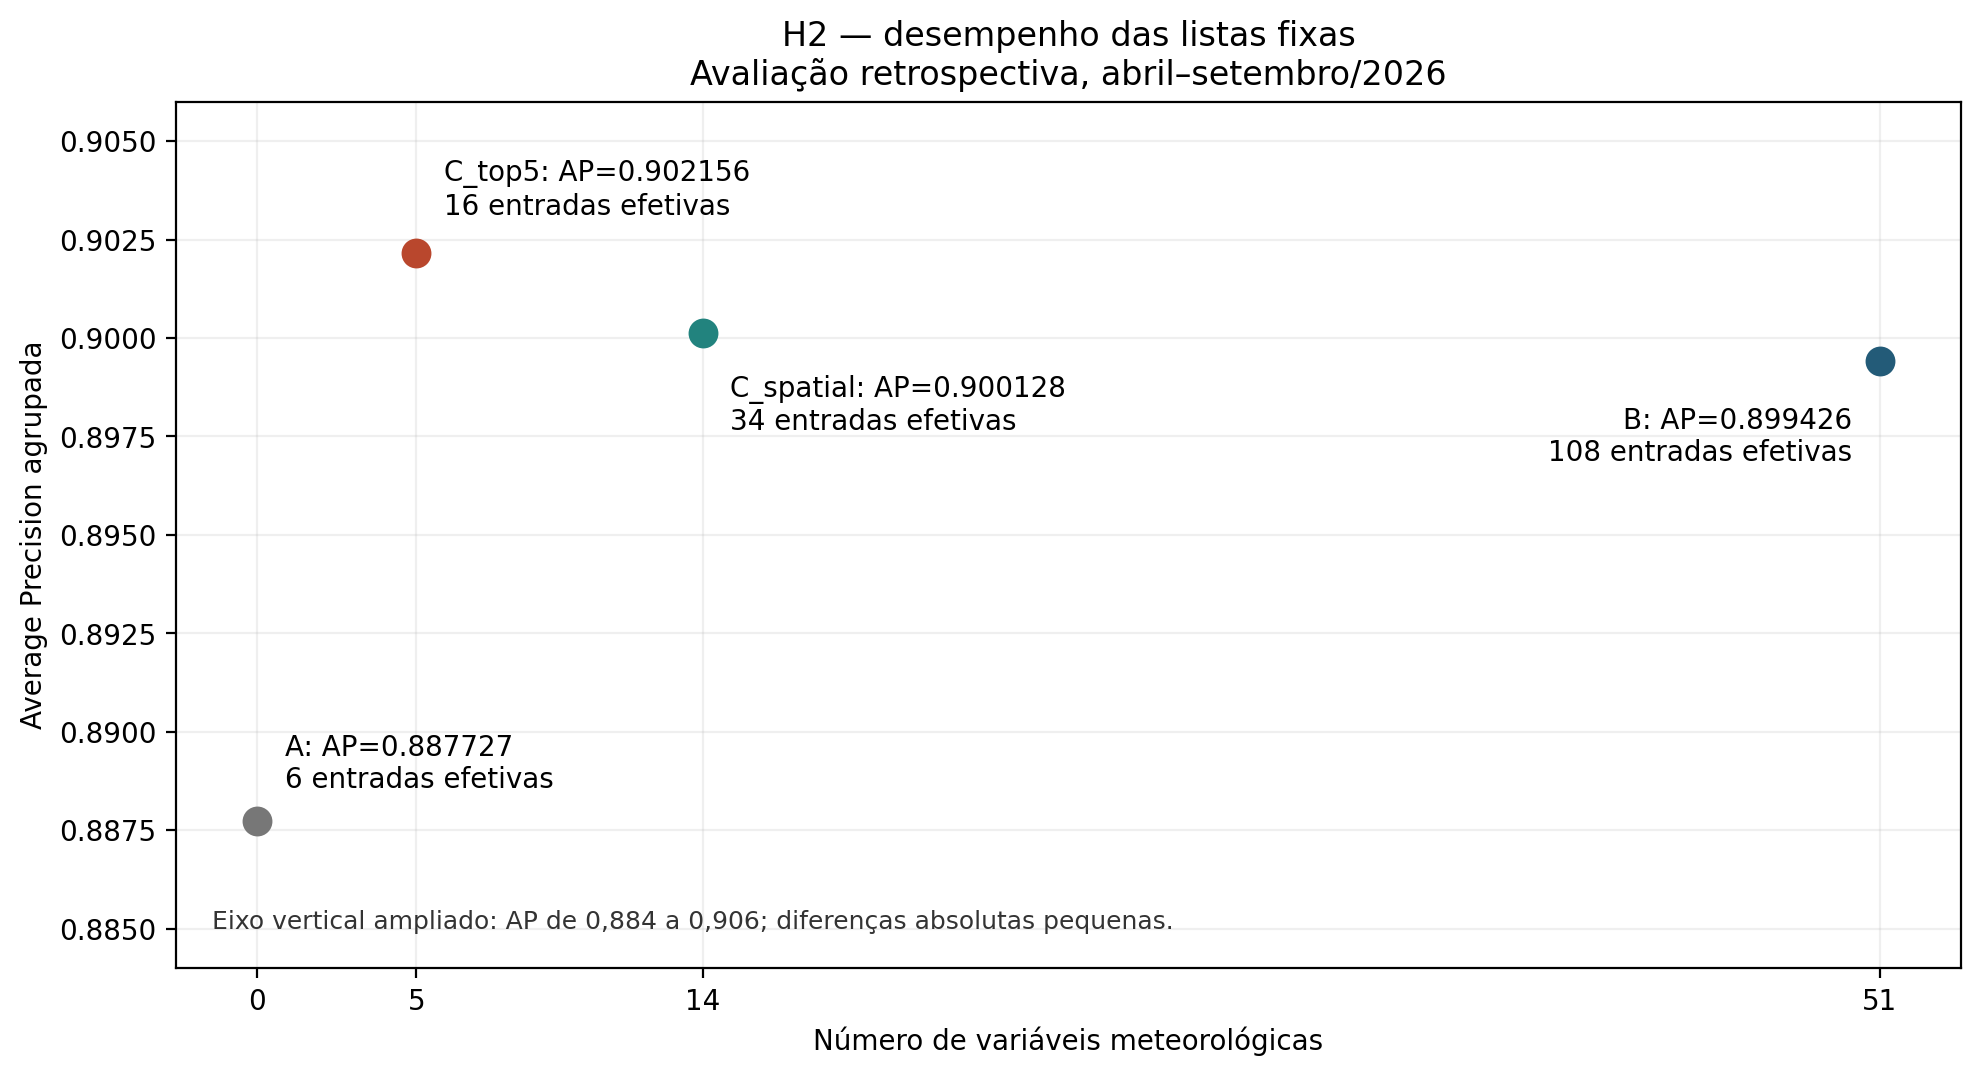

In [94]:
h2.guardar_figura(h2.figura_complexidade(ROOT,h2_resumo),ROOT,'h2_reduzidos_desempenho_complexidade')


**Resultado pontual.** A AP agrupada é **0,899426** para B, **0,902156** para C_top5 e **0,900128** para C_spatial. Os Brier respectivos são **0,079880**, **0,079388** e **0,079164**. As duas reduções preservam, na amostra, ordenação e qualidade probabilística próximas às do modelo completo, com **90,2%** e **72,5%** menos variáveis meteorológicas, respectivamente. Entretanto, valores pontuais ligeiramente melhores **não demonstram superioridade estatística**.

Para avaliar a margem de não inferioridade, a campanha sorteou **2.000 réplicas** de bootstrap **pareado**, sincronizando as oito regiões, em blocos de **168 h (27 blocos)** e **672 h (apenas sete blocos)**; sementes **5955 e 6459**. O bloco final incompleto foi mantido. Os intervalos nominais são os percentis **2,5%–97,5%** das diferenças simuladas.

Também se calcularam **limites inferiores simultâneos aproximados** para os **dois** contrastes reduzidos contra B, usando uma estatística máxima dos erros bootstrap centrados e padronizados. Esse ajuste considera a multiplicidade das duas comparações principais; no desenvolvimento, a seleção havia considerado oito candidatas. A regra exigiu **ambos os limites inferiores, nominal e simultâneo, acima de −0,01**, sob os dois comprimentos de bloco. O notebook reconstrói os intervalos a partir das **réplicas persistidas**, sem executar uma nova reamostragem.


Contraste,ΔAP,IC 95% AP — 168 h,IC 95% AP — 672 h,ΔBrier
B − A,"0,011699",[-0.004363; +0.034297],[-0.006591; +0.040125],"-0,007298"
C_spatial − A,"0,012401",[-0.002753; +0.033801],[-0.005148; +0.039454],"-0,008014"
C_spatial − B,"0,000702",[-0.001387; +0.002680],[-0.000554; +0.001849],"-0,000716"
C_top5 − A,"0,014429",[-0.000997; +0.037799],[-0.003431; +0.043833],"-0,007790"
C_top5 − B,"0,002730",[-0.001428; +0.007762],[-0.000036; +0.004834],"-0,000493"


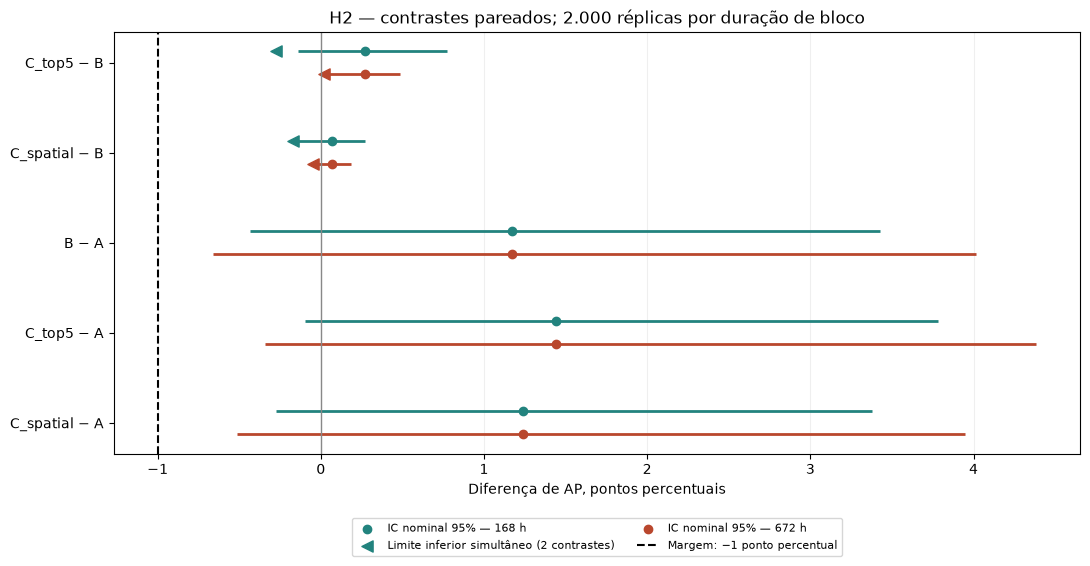

In [95]:
h2_intervalos = h2.recalcular_intervalos(ROOT,h2_resumo)
h2_intervalos.to_csv(OUT/'tabelas/h2_reduzidos_intervalos_completos.csv',index=False)
h2_ci_rows=[]
for h2_nome,h2_g in h2_intervalos.groupby('contrast',sort=False):
    h2_g=h2_g.set_index('block_hours')
    h2_ci_rows.append({'Contraste':h2_nome.replace('_minus_',' − '),'ΔAP':h2_g.loc[168,'delta_ap'],
        'IC 95% AP — 168 h':f"[{h2_g.loc[168,'ap_low']:+.6f}; {h2_g.loc[168,'ap_high']:+.6f}]",
        'IC 95% AP — 672 h':f"[{h2_g.loc[672,'ap_low']:+.6f}; {h2_g.loc[672,'ap_high']:+.6f}]",
        'ΔBrier':h2_g.loc[168,'delta_brier']})
h2.mostrar(pd.DataFrame(h2_ci_rows),ROOT,'h2_reduzidos_contrastes',
           'Diferenças pareadas; AP positiva e Brier negativo favorecem o primeiro sistema')
h2.guardar_figura(h2.figura_intervalos(h2_intervalos),ROOT,'h2_reduzidos_contrastes_pareados')


In [96]:
h2_ni = h2_intervalos.loc[h2_intervalos.contrast.isin(['C_top5_minus_B','C_spatial_minus_B']),
                         ['contrast','block_hours','ap_low','ap_simultaneous_low']].copy()
h2_ni['Margem']=-0.01
h2_ni['Critério satisfeito']=(h2_ni.ap_low > -0.01)&(h2_ni.ap_simultaneous_low > -0.01)
assert h2_ni['Critério satisfeito'].all()
h2.mostrar(h2_ni.rename(columns={'contrast':'Contraste','block_hours':'Bloco (h)',
    'ap_low':'Inferior nominal','ap_simultaneous_low':'Inferior simultâneo'}),ROOT,'h2_reduzidos_nao_inferioridade',
    'Verificação da margem predefinida, sem alterar critérios após observar os resultados')


Contraste,Bloco (h),Inferior nominal,Inferior simultâneo,Margem,Critério satisfeito
C_spatial_minus_B,168,"-0,001387","-0,001723","-0,010000",True
C_top5_minus_B,168,"-0,001428","-0,002748","-0,010000",True
C_spatial_minus_B,672,"-0,000554","-0,000505","-0,010000",True
C_top5_minus_B,672,"-0,000036","0,000209","-0,010000",True


**Conclusão da inferência:** C_top5 e C_spatial **satisfizeram a margem operacional de não inferioridade de 0,01 de AP** nas duas sensibilidades. Os piores limites inferiores simultâneos foram **−0,002748** (top-5) e **−0,001723** (multissensor), ambos acima de −0,01. Esse resultado é **mais específico** do que afirmar que os modelos são “iguais”: não inferioridade dentro de uma tolerância não é equivalência exata, nem prova de superioridade.

Os **intervalos nominais de 95%** de $\Delta AP$ e $\Delta Brier$ dos reduzidos contra B **incluem zero** nas duas sensibilidades. Um limite simultâneo positivo de top-5 com blocos de 672 h não foi selecionado isoladamente para sustentar superioridade: limites simultâneos e intervalos percentis têm construções diferentes e não precisam ser aninhados.

Além disso, há **somente sete blocos longos**, a inferência condiciona nos modelos e na seleção registrados e o período já havia sido examinado durante a pesquisa. A mensagem científica é, portanto, **simplificação expressiva sem perda superior à margem predefinida nesse protocolo retrospectivo**, e não superioridade universal da representação compacta.

Isso **não altera a H2 original**: comparada ao calendário A, a meteorologia melhora o Brier no par principal, enquanto o ganho de AP continua com intervalo incluindo zero.


#### 15.2.7. O que acontece mês a mês e entre regiões?

Uma AP calculada sobre **todas** as previsões do semestre não é a média aritmética das seis APs mensais. A AP é função do **ranking completo** e da prevalência; ao reunir meses, observações de períodos diferentes passam a competir entre si. Por isso, analisamos as duas medidas: a média mensal é **0,895049** para B, **0,897188** para top-5 e **0,895033** para multissensor. O último supera B ligeiramente na **AP agrupada**, mas não na **média simples mensal**.

O gráfico a seguir exibe $AP(C)-AP(B)$ separadamente para cada mês. Um ponto negativo representa uma perda real naquele mês; não é um erro de execução nem uma razão para recalcular a lista de variáveis.


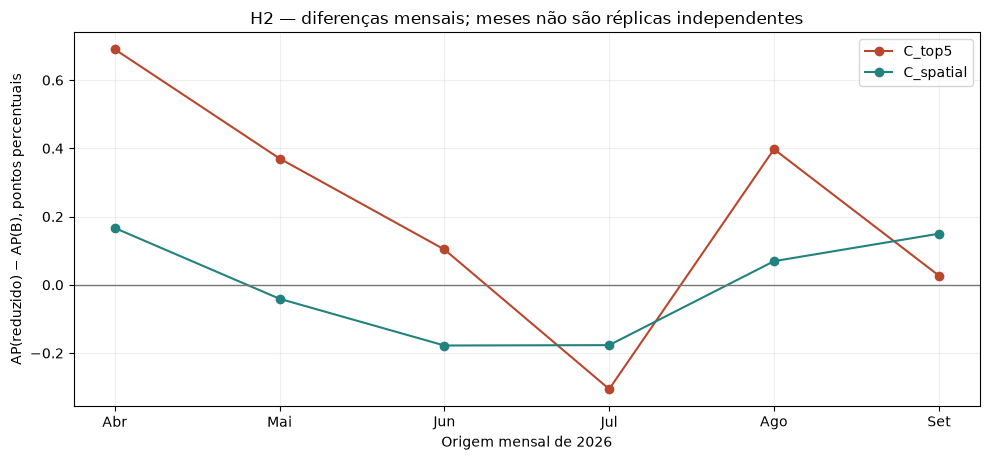

Região,AP B,ΔAP top-5−B,ΔAP multissensor−B
A408,"0,913801","0,002771","0,001388"
A423,"0,916086","0,002783","-0,000112"
A426,"0,908847","0,001378","0,002282"
A429,"0,912061","0,001747","0,000123"
A430,"0,915661","0,002285","0,000690"
A433,"0,897378","0,004482","0,001868"
A439,"0,881367","-0,000855","-0,001584"
A458,"0,850016","0,005752","0,000070"


In [97]:
h2.guardar_figura(h2.figura_mensal(h2_mensais),ROOT,'h2_reduzidos_diferencas_mensais')
h2_reg_ap=h2_regionais.pivot(index='region',columns='variant',values='ap')
h2_reg=pd.DataFrame({'Região':h2_reg_ap.index,'AP B':h2_reg_ap.B,
                    'ΔAP top-5−B':h2_reg_ap.C_top5-h2_reg_ap.B,
                    'ΔAP multissensor−B':h2_reg_ap.C_spatial-h2_reg_ap.B}).reset_index(drop=True)
h2.mostrar(h2_reg,ROOT,'h2_reduzidos_estabilidade_regional','Descrições regionais; sem tratar regiões como réplicas independentes')


C_top5 melhora a AP em **cinco dos seis meses** e **sete regiões**, mas perde em **julho (−0,003055)** e na região **A439 (−0,000855)**. C_spatial melhora em **três meses** e **seis regiões**, mas perde em maio, junho e julho, e nas regiões A423 e A439. Nenhum desses resultados negativos motivou troca de atributos após o congelamento.

Junho tem AP menor em **todos** os sistemas e prevalência de **23,40%**, embora B ainda supere A naquele mês em **0,086033**. Prevalência e distribuição dos casos mudam juntas; não podemos atribuir a queda de AP exclusivamente ao número menor de eventos. Meses vizinhos e regiões também compartilham episódios, sensores e históricos de treinamento. Portanto, essas comparações são **descritivas**, não testes independentes repetidos.

A representação reduzida preservou desempenho agregado segundo a margem escolhida, **não desempenho idêntico em cada mês ou região**. Essa diferença é importante para interpretar sua possível aplicação fora do período estudado.


#### 15.2.8. Um cuidado decisivo: probabilidade prevista não é política de alerta

AP, Brier e ROC-AUC usam **probabilidades**, independentemente do limiar de decisão. Já precisão, recall e F1 dependem de quando emitimos um alerta. O protocolo histórico ajusta limiares a partir de previsões fora do treinamento e **rótulos passados já disponíveis**, em até 90 dias de histórico, maximizando F1 na grade 0,01–0,99.

Os sistemas A/B preservaram a inicialização dos modelos históricos, com limiares **0,36/0,49 em abril**. Os reduzidos começaram em **0,24/0,21**, a partir do desenvolvimento mensal admissível; no caso top-5, esse histórico provém da política **adaptativa**, embora as previsões de avaliação usem a **lista fixa**. A regra de atualização dos limiares é a mesma nos meses seguintes, mas **a inicialização não é idêntica**. Essas diferenças foram registradas, sem otimização sobre os rótulos do próprio mês avaliado.

Consequentemente, **não podemos atribuir diferenças de F1, recall ou quantidade de alertas exclusivamente à retirada de variáveis**. Um sistema que avisa mais cedo pode recuperar mais eventos e, simultaneamente, emitir mais falsos positivos. As métricas independentes de limiar são as principais para julgar a redução de atributos.


In [98]:
h2_alertas=h2_resumo[['variant','precision','recall','f1','specificity','alert_fraction']].copy()
h2_alertas['alert_fraction']*=100
h2.mostrar(h2_alertas.rename(columns={'variant':'Sistema','precision':'Precisão','recall':'Recall',
    'f1':'F1','specificity':'Especificidade','alert_fraction':'Região × hora em alerta (%)'}),
    ROOT,'h2_reduzidos_alertas','Alertas sob as políticas registradas; interpretar junto aos limiares')
h2_limiares=pd.DataFrame({v:f.groupby('origin').threshold.first() for v,f in h2_previsoes.items()})
h2.mostrar(h2_limiares.rename_axis('Mês').reset_index(),ROOT,'h2_reduzidos_limiares','Limiares mensais efetivamente utilizados')


Sistema,Precisão,Recall,F1,Especificidade,Região × hora em alerta (%)
A,"0,772686","0,881000","0,823296","0,871790","37,735199"
B,"0,777716","0,856696","0,815298","0,878875","36,456867"
C_top5,"0,774061","0,929867","0,844841","0,865736","39,757548"
C_spatial,"0,764228","0,939415","0,842814","0,856634","40,682543"


Mês,A,B,C_top5,C_spatial
2026-04,"0,360000","0,490000","0,240000","0,210000"
2026-05,"0,320000","0,290000","0,240000","0,190000"
2026-06,"0,250000","0,220000","0,210000","0,190000"
2026-07,"0,150000","0,220000","0,210000","0,240000"
2026-08,"0,250000","0,330000","0,320000","0,300000"
2026-09,"0,440000","0,460000","0,430000","0,450000"


#### 15.2.9. Síntese: o que SHAP, permutação e retreinamento revelaram juntos?

A interpretação e os testes de redução contam uma história coerente, mas **não idêntica em cada método**:

- **SHAP** atribuiu à família multissensor **88,48%** da soma das magnitudes meteorológicas. Isso descreve a **influência nos modelos B históricos**, em log-odds.
- **Permutação** prejudicou muito mais a AP ao perturbar o bloco multissensor do que os demais. Isso descreve a **dependência de B fixo** sob uma perturbação definida.
- **Ablação** mostrou que retirar a família multissensor causou perda no desenvolvimento; outras remoções passaram pela margem. Isso descreve o que aconteceu **depois de retreinar** as árvores sem determinados grupos.
- **Seleção e avaliação** mostraram que **cinco variáveis/16 entradas** ou **14 variáveis/34 entradas** preservaram a AP dentro da margem de −0,01 frente às **51 variáveis/108 entradas** do sistema completo. A lista fixa top-5 foi avaliada **apenas na campanha final**, enquanto a política top-5 adaptativa foi a validada nas 15 origens.

A redução principal é de **90,2% das variáveis meteorológicas** e **85,2% das entradas efetivas do classificador**. Isso não significa reduzir em 90,2% os sensores necessários: os cinco atributos ainda requerem medições e transformações temporais e multissensor.

**A simplificação também veio acompanhada de melhores valores observados.** Na mesma população de 34.811 horas-região, **C_top5 superou pontualmente tanto A (calendário) quanto B (51 variáveis)** nas cinco métricas destacadas na tabela de resultados: **AP** (0,902156; contra 0,887727 e 0,899426), **Brier** (0,079388; contra 0,087178 e 0,079880, sendo menor melhor), **ROC-AUC** (0,955793; contra 0,949562 e 0,954696), **F1** (0,844841; contra 0,823296 e 0,815298) e **recall** (0,929867; contra 0,881000 e 0,856696). Os três primeiros indicadores não dependem do limiar de alerta; F1 e recall dependem. Esses números **não são uma promessa de superioridade em novos períodos**: o ganho de AP de top-5 sobre B foi de +0,002730, mas seu IC nominal de 95% com blocos de 168 h foi [−0,001428; +0,007762]. Em contraste, a **redução do Brier de top-5 frente ao calendário** foi −0,007790, com intervalo [−0,012917; −0,002753], inteiramente favorável ao modelo compacto.

**Os alertas mostram por que a escolha de métrica importa.** Top-5 apresentou **843 verdadeiros positivos e 306 falsos positivos adicionais** em relação a B; **766** dos verdadeiros positivos extras ocorreram em abril, quando seu limiar inicial era bastante menor. Multissensor apresentou **953 verdadeiros positivos e 518 falsos positivos adicionais**. A sensibilidade maior vem acompanhada de mais alertas, e **não demonstra isoladamente melhor representação meteorológica**.

O resultado mais defensável é a **redundância preditiva parcial sob o protocolo avaliado**, sem dispensabilidade universal das variáveis, superioridade estatística robusta ou relação causal entre temperatura/vento e a decisão operacional do ONS. Essa descoberta aprofunda H2 e **preserva sua conclusão original**: melhora do Brier com meteorologia e ganho de AP em relação ao calendário ainda inconclusivo sob os intervalos de incerteza.


### 15.3. H3 — A contribuição da meteorologia é diferente para ENE, CNF e REL?

ENE, CNF e REL têm significados operacionais e frequências diferentes. Para verificar se a informação meteorológica é igualmente útil, comparamos **um modelo de calendário e seu par com meteorologia para cada motivo**. Utilizamos as mesmas **34.484 horas em que os três rótulos são conhecidos**, no cenário de treinamento reajustado antes de abril e mantido durante o semestre.

É fundamental não confundir duas coisas: as horas comparadas são comuns, mas o evento positivo ENE não é o mesmo evento positivo CNF ou REL. Além disso, o algoritmo adequado a cada motivo pode mudar — por exemplo, logística em uma tarefa e boosting em outra. **Dentro de cada motivo**, porém, a comparação conserva a receita do algoritmo, alterando o bloco de meteorologia. Por isso, nossa pergunta principal é o que ocorre quando acrescentamos meteorologia *ao mesmo motivo*, não qual motivo tem maior AP absoluta.


Motivo,Modelo,Eventos,AP ↑,ROC-AUC ↑,Brier ↓
ENE,Calendário,11243,"0,8705","0,9436","0,0984"
ENE,Calendário + meteorologia,11243,"0,8667","0,9425","0,0974"
CNF,Calendário,778,"0,0528","0,6514","0,0222"
CNF,Calendário + meteorologia,778,"0,0349","0,6262","0,0243"
REL,Calendário,1544,"0,1530","0,7171","0,0438"
REL,Calendário + meteorologia,1544,"0,1090","0,6851","0,0421"


Motivo,Modelo,Limiar,Precisão ↑,Recall ↑,F1 ↑,Especificidade ↑,Acurácia ↑
ENE,Calendário,"0,2600","0,6536","0,9843","0,7856","0,7476","0,8248"
ENE,Calendário + meteorologia,"0,2400","0,6407","0,9865","0,7769","0,7324","0,8152"
CNF,Calendário,"0,0900","0,0852","0,1645","0,1123","0,9592","0,9413"
CNF,Calendário + meteorologia,"0,1100","0,0396","0,2224","0,0672","0,8755","0,8607"
REL,Calendário,"0,0800","0,0608","0,8115","0,1131","0,4120","0,4299"
REL,Calendário + meteorologia,"0,0900","0,1181","0,3187","0,1723","0,8884","0,8629"


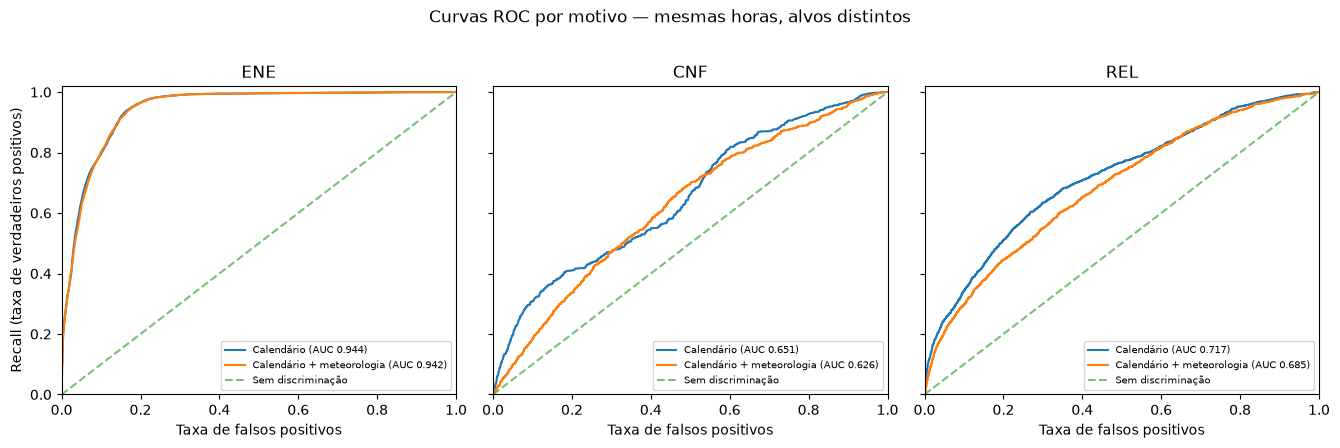

8574

In [99]:
from sklearn.metrics import roc_curve
mesmas_horas=None
for motivo in ['ENE','CNF','REL']:
    ref=selecionar_previsoes('E2','P1_AB','spatial_recent',motivo,'A')
    ids=pd.MultiIndex.from_frame(ref[['region','time_local']])
    mesmas_horas=ids if mesmas_horas is None else mesmas_horas.intersection(ids)
assert len(mesmas_horas)==34484

sistemas_h3={}; linhas_h3=[]
for motivo in ['ENE','CNF','REL']:
    sistemas_h3[motivo]={}
    for v,nome in [('A','Calendário'),('B','Calendário + meteorologia')]:
        g=selecionar_previsoes('E2','P1_AB','spatial_recent',motivo,v)
        g=g[pd.MultiIndex.from_frame(g[['region','time_local']]).isin(mesmas_horas)].copy()
        sistemas_h3[motivo][nome]=g
        m=cmp.metricas(g)
        linhas_h3.append({'Motivo':motivo,'Informação':nome,**m})
    cmp.validar_painel(sistemas_h3[motivo])

resultado_h3=pd.DataFrame(linhas_h3)
resultado_h3.to_csv(OUT/'tabelas/h3_metricas_completas.csv',index=False)
resumo_h3=resultado_h3[['Motivo','Informação','positivos','AP','ROC_AUC','Brier']].copy()
resumo_h3.columns=['Motivo','Modelo','Eventos','AP ↑','ROC-AUC ↑','Brier ↓']
cmp.mostrar(resumo_h3,'h3_ordenacao','H3 — ranking e probabilidade, com as mesmas 34.484 horas')
decisoes_h3=resultado_h3[['Motivo','Informação','limiar_min','precisao','recall','F1','especificidade','acuracia']].copy()
decisoes_h3.columns=['Motivo','Modelo','Limiar','Precisão ↑','Recall ↑','F1 ↑','Especificidade ↑','Acurácia ↑']
cmp.mostrar(decisoes_h3,'h3_decisoes','H3 — decisão por motivo, com limiar selecionado no desenvolvimento')

# Uma figura ROC para os três motivos, lado a lado: apenas dois modelos em cada painel.
fig,axs=plt.subplots(1,3,figsize=(13.5,4.35),sharex=True,sharey=True)
for ax,motivo in zip(axs,['ENE','CNF','REL']):
    for nome,g in sistemas_h3[motivo].items():
        fpr,tpr,_=roc_curve(g.y,g.p)
        auc=cmp.metricas(g)['ROC_AUC']
        ax.plot(fpr,tpr,label=f'{nome} (AUC {auc:.3f})')
    ax.plot([0,1],[0,1],'--',alpha=.65,label='Sem discriminação')
    ax.set(title=motivo,xlabel='Taxa de falsos positivos',xlim=(0,1),ylim=(0,1.02))
    ax.legend(fontsize=7,loc='lower right')
axs[0].set_ylabel('Recall (taxa de verdadeiros positivos)')
fig.suptitle('Curvas ROC por motivo — mesmas horas, alvos distintos',y=1.02)
fig.tight_layout();figura(fig,'h3_roc_motivos')
# Liberar temporários antes de carregar outros blocos de avaliação.
import gc
del sistemas_h1,sistemas_h2,sistemas_h3,linhas_h3
gc.collect()


**O benefício não foi uniforme.** Nesse experimento, acrescentar meteorologia reduziu a AP de ENE de aproximadamente **0,870 para 0,867**, a de CNF de **0,053 para 0,035**, e a de REL de **0,153 para 0,109**. Alguns erros probabilísticos ou medidas de decisão melhoraram em determinados motivos, mas as mudanças de ranking foram desfavoráveis aos três neste protocolo.

O número de eventos positivos também difere muito: ENE é frequente nesse recorte; CNF e REL são muito mais raros. Assim, não se deve concluir que CNF é “mais difícil” que REL apenas a partir das APs sem considerar suas prevalências. Uma acurácia elevada em CNF pode coexistir com recall baixo, simplesmente porque a maioria esmagadora das horas não possui esse evento.

A hipótese de diferenças por motivo encontra **comportamentos distintos**, mas **não um ganho meteorológico geral**. As informações disponíveis não permitem identificar uma causa elétrica específica, como o congestionamento de uma determinada linha de transmissão. A análise descreve associações e previsões, não diagnósticos causais da rede.


### 15.4. H4 — Atualizar o treinamento com observações recentes melhora a previsão?

A frequência das restrições mudou no histórico. Isso sugere que um modelo ajustado apenas com observações antigas pode perder a capacidade de representar padrões recentes. Para testar essa ideia, mantemos **a mesma regressão logística de calendário e as mesmas 15.584 horas de avaliação**, mas com três políticas de treinamento: congelada, reajustada antes de abril e reajustada mensalmente.

Nesse experimento, o algoritmo e os atributos de calendário permanecem equivalentes. Assim, a principal diferença é **o histórico utilizado no ajuste**. O ganho não deve ser atribuído ao vento: a comparação principal inclui **apenas calendário**.


**H4 — mesmo calendário, treinamento atualizado**

15.584 horas de abril–setembro de 2026; regressão logística sem meteorologia.

Mesmas **15,584 observações região × hora**, **5,127 eventos positivos** (**32.90%**).

Modelo,AP ↑,ROC-AUC ↑,Brier ↓,Log loss ↓,Probabilidade média
Calendário — treino congelado,"0,7498","0,8761","0,2749","1,1232","0,0405"
Calendário — atualizado antes de abril,"0,8346","0,9274","0,1981","0,5696","0,1119"
Calendário — atualizado mensalmente,"0,8407","0,9303","0,1938","0,5537","0,1152"


Modelo,Limiar de decisão,Precisão ↑,Recall ↑,F1 ↑,Especificidade ↑,Acurácia ↑
Calendário — treino congelado,0.05,"0,7773","0,3417","0,4747","0,9520","0,7512"
Calendário — atualizado antes de abril,0.05,"0,6764","0,9626","0,7945","0,7742","0,8362"
Calendário — atualizado mensalmente,0.05,"0,6788","0,9649","0,7969","0,7761","0,8382"


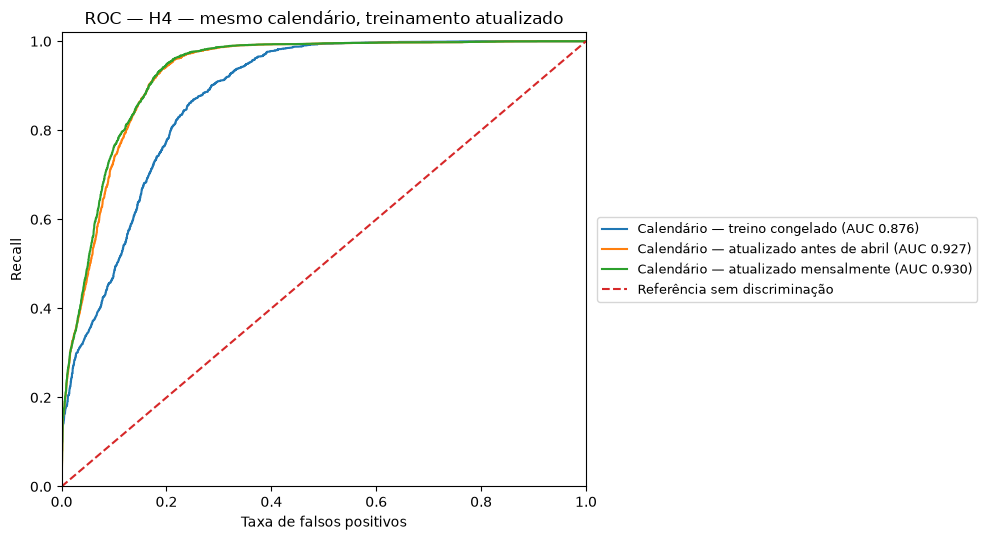

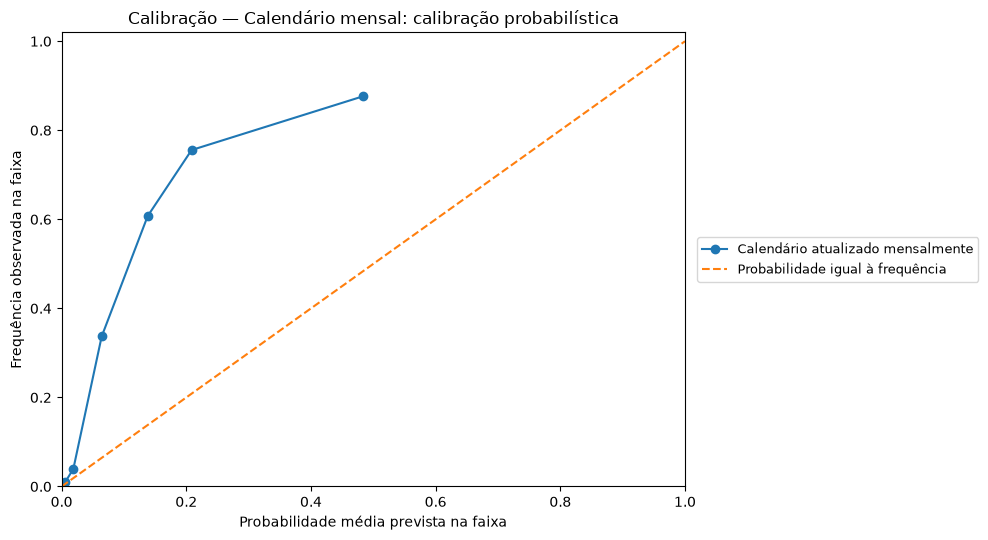

In [100]:
politicas_h4={'P0_logistic':'Calendário — treino congelado',
             'P1_access_only':'Calendário — atualizado antes de abril',
             'P2_access_only':'Calendário — atualizado mensalmente'}
sistemas_h4={nome:selecionar_previsoes('E1',pro,'v1_common','ENE','A')
             for pro,nome in politicas_h4.items()}
res_h4=cmp.painel(sistemas_h4,'h4_atualizacao','H4 — mesmo calendário, treinamento atualizado',
 '15.584 horas de abril–setembro de 2026; regressão logística sem meteorologia.',
 curvas=('roc',))
# Diagnóstico complementar de calibração do modelo mensal, sem acrescentar mais curvas à comparação principal.
cmp.curva({'Calendário atualizado mensalmente':sistemas_h4['Calendário — atualizado mensalmente']},
          'h4_calibracao_mensal','Calendário mensal: calibração probabilística','calibracao')

In [101]:
intervalos_h4 = tabela_intervalos(sistemas_h4, [
    ('Calendário — treino congelado', 'Calendário — atualizado mensalmente', 'Mensal − congelado')],
    'h4_intervalos_pareados')


Comparação,Métrica,Diferença observada,Intervalo 95% — blocos de 7 dias,Intervalo 95% — blocos de 28 dias
Mensal − congelado,AP,"0,0909","[+0,07217; +0,10477]","[+0,07410; +0,09969]"


**O ganho é expressivo e também ocorre sem vento.** A AP do calendário passou de aproximadamente **0,750**, com treino congelado, para **0,835** após incorporar observações recentes e **0,841** com atualização mensal. O Brier caiu de **0,2749 para 0,1938** entre os extremos. No limiar de cada política, o recall também aumentou muito: cerca de **34% para 96%**, acompanhado de uma redução de precisão e especificidade. Isso representa a mudança de um modelo com poucos alertas para um que detecta mais eventos, mas também alerta mais horas negativas.

A principal descoberta é sobre a relevância de aprender com exemplos recentes. **Nenhuma variável meteorológica entra nesse experimento**: apenas a idade das observações de treinamento e a frequência de reajuste foram alteradas.

A melhora do ranking não elimina todas as limitações probabilísticas. Na avaliação mensal do calendário, a probabilidade média prevista permaneceu bem abaixo da frequência observada. A curva de calibração ilustra essa diferença. Portanto, **melhor discriminação e boa calibração são objetivos relacionados, mas distintos**.

**A análise por blocos reforça a H4 — atualizar o treinamento com observações recentes melhora a previsão.** A diferença de AP entre calendário mensal e congelado é aproximadamente **+0,0909**, com intervalo semanal **[+0,0722; +0,1048]** e intervalo de 28 dias **[+0,0741; +0,0997]**. Ambos permanecem positivos. O contraste avaliado é mensal − congelado: ele não testa separadamente a vantagem menor sobre o ajuste único anterior a abril. Os três calendários usam o mesmo limiar numérico de **0,05**; as decisões mudam porque as probabilidades mudam, não porque o ponto de corte foi trocado.


### Síntese das quatro comparações de ocorrência

As quatro perguntas produzem uma história integrada. **H1 — o calendário contém informação preditiva** recebe evidência favorável, e um sistema que combina dois modos de aprendê-lo apresenta ganho pontual sobre a logística isolada. **H2 — a meteorologia acrescenta informação ao calendário** recebe evidência favorável para o Brier de um par LightGBM com o mesmo desenho de treino, mas seu ganho de AP não é estável nos intervalos examinados nem universal entre experimentos. **H3 — o efeito meteorológico varia entre ENE, CNF e REL** revela comportamentos distintos, sem ganho uniforme. **H4 — atualizar o treinamento melhora a previsão** apresenta um avanço importante, inclusive em modelos que não recebem meteorologia.

As curvas e tabelas desta seção mantêm o foco nas quatro perguntas, com modelos comparados nas mesmas observações dentro de cada experimento.

A referência de frequência recente liga a primeira comparação diretamente à EDA: mesmo uma regra de contagem já distingue riscos, e os modelos aprendidos acrescentam capacidade de ordenação. Os intervalos ajudam a separar esse resultado da vantagem mais incerta da combinação sobre a logística. Na atualização temporal, o ganho de AP permanece positivo nos dois tamanhos de bloco, enquanto na meteorologia a evidência difere entre AP e Brier.

**Aprofundamento da H2.** As análises de SHAP, permutação e ablação indicaram a importância das representações multissensor. Após seleção temporal e retreinamento, listas fixas de **cinco** ou **14 variáveis meteorológicas** preservaram a AP do modelo completo dentro da margem operacional de não inferioridade previamente estabelecida. Isso responde a uma pergunta de **parcimônia da representação**, diferente de demonstrar que acrescentar meteorologia ao calendário melhora robustamente a AP.



<a id="secao-16"></a>

## 16. Previsão da intensidade dos cortes de geração

A classificação responde **se uma restrição ultrapassa um limiar**. Entretanto, uma hora com 3% de energia restringida e outra com 60% podem receber o mesmo rótulo positivo. Como a análise exploratória encontrou muitas horas sem corte e uma ampla faixa de intensidades positivas, também investigamos **quanto da energia de referência será restringida**, considerando o total de motivos.

O alvo da regressão é uma fração entre 0 e 1. Assim, um MAE de 0,12 significa erro absoluto médio de **12 pontos percentuais da referência**, e não 12 MWh. A média dos erros ao quadrado (RMSE) pesa mais fortemente grandes desvios.

### 16.1. Regressão direta: calendário versus calendário com meteorologia

Começamos com uma comparação simples: dois modelos LightGBM que estimam diretamente a **mediana condicional da fração total**, um com calendário e outro que acrescenta meteorologia. Ambos utilizam o mesmo alvo e as mesmas **35.112 observações de avaliação**, permitindo calcular a diferença de MAE e seu intervalo por blocos.


Modelo,Observações,MAE,RMSE,Viés
Calendário,35112,"0,1346","0,2623","-0,0954"
Calendário + meteorologia,35112,"0,1276","0,2485","-0,0888"


Δ MAE (meteorologia − calendário),Intervalo inferior,Intervalo superior,Duração do bloco (h)
"-0,0070","-0,0100","-0,0034",672


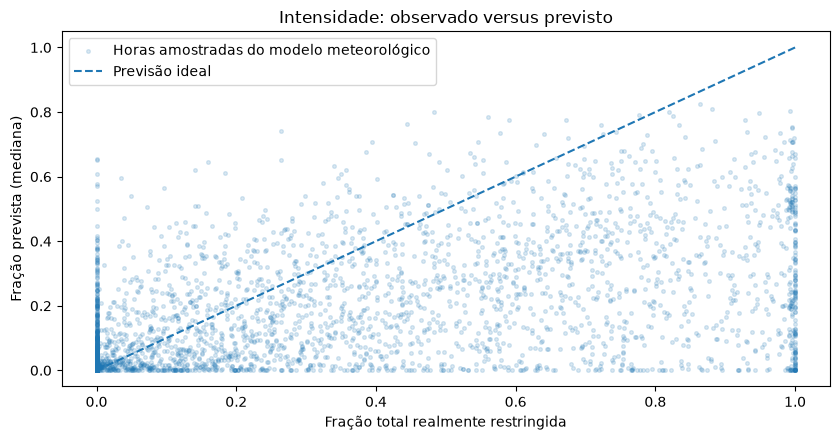

In [102]:
mag2=previsoes_temporais[(previsoes_temporais.reason=='magnitude')&
                          (previsoes_temporais.protocol=='P1_task')].copy()
ma2=mag2[mag2.variant=='A'].copy();mb2=mag2[mag2.variant=='B'].copy()
assert len(apoio.parear(ma2,mb2))==35112
metricas_mag=[]
for v,g in [('A',ma2),('B',mb2)]:
    m=apoio.regressao(g.y,g.p)
    metricas_mag.append({'Modelo':'Calendário' if v=='A' else 'Calendário + meteorologia',
                         'Observações':len(g),'MAE':m['MAE'],'RMSE':m['RMSE'],'Viés':m['vies']})
resultado_magnitude=pd.DataFrame(metricas_mag)
cmp.mostrar(resultado_magnitude,'magnitude_direta_principal',
             'Previsão direta da fração total: mesmas horas e mediana prevista')
mm2=pd.DataFrame([{'variante':v,**apoio.regressao(g.y,g.p)}
                  for v,g in [('A',ma2),('B',mb2)]]).set_index('variante')
reducao=(mm2.loc['A','MAE']-mm2.loc['B','MAE'])/mm2.loc['A','MAE']
hist_mag2=pd.read_csv(ROOT/'dados/contrastes_regressao_direta.csv')
ci=hist_mag2[(hist_mag2.contrast=='B-A')&(hist_mag2.metric=='MAE difference')&
             (hist_mag2.block_hours==672)]
assert len(ci)==1
np.testing.assert_allclose(ci.estimate,mm2.loc['B','MAE']-mm2.loc['A','MAE'],atol=1e-10,rtol=0)
cmp.mostrar(ci[['estimate','low','high','block_hours']].rename(columns={
 'estimate':'Δ MAE (meteorologia − calendário)','low':'Intervalo inferior','high':'Intervalo superior',
 'block_hours':'Duração do bloco (h)'}),'magnitude_contraste_ci',
 'Diferença pareada de MAE: valores negativos favorecem a meteorologia')
fig,ax=plt.subplots(figsize=(8.5,4.5))
g=mb2.sample(min(6000,len(mb2)),random_state=SEED)
ax.scatter(g.y,g.p,s=7,alpha=.16,label='Horas amostradas do modelo meteorológico')
ax.plot([0,1],[0,1],'--',label='Previsão ideal')
ax.set(xlabel='Fração total realmente restringida',ylabel='Fração prevista (mediana)',
       title='Intensidade: observado versus previsto')
ax.legend();fig.tight_layout();figura(fig,'magnitude_observado_previsto_principal')


A meteorologia reduziu o MAE de aproximadamente **0,13456 para 0,12759**: uma diminuição relativa de **5,18%** no erro absoluto médio. O intervalo pareado por blocos favorece a versão meteorológica nesse contraste, embora a avaliação permaneça retrospectiva. Esse resultado mostra que **a meteorologia pode ajudar a estimar quanto se restringe mesmo quando não melhora consistentemente a classificação da ocorrência**.

A dispersão de observado versus previsto revela uma dificuldade adicional. Muitas horas têm corte zero ou pequeno, enquanto restrições severas são raras e apresentam erros importantes. Por isso, o MAE global deve ser acompanhado de atenção aos extremos; um modelo bom em média não garante acerto em todas as situações críticas.

O experimento de intensidade complementa a classificação: em vez de tratar todos os eventos acima do limiar como equivalentes, estima a fração total restringida. **As duas regressões diretas comparam a mesma mediana prevista nas mesmas horas**, e as métricas mostram tanto a redução média de erro quanto o comportamento dos desvios. Prever corretamente a ocorrência e estimar sua severidade são tarefas relacionadas, mas distintas.

<a id="secao-17"></a>

## 17. O que os resultados permitem concluir sobre as hipóteses?

As análises anteriores articulam as decisões feitas desde a integração das fontes. Cada hipótese deve ser avaliada pelo experimento correspondente, sem atribuir a uma variável o ganho produzido por mudar simultaneamente algoritmo, população e treinamento.

### H1 — Os padrões de calendário contêm informação preditiva sobre a ocorrência de ENE?

**Sim, há evidência favorável.** Um calendário logístico já ordena os riscos muito melhor que uma previsão sem capacidade de discriminação. Na mesma população, a combinação de um componente logístico ponderado com um LightGBM recente aumenta AP e ROC-AUC e reduz Brier. A qualidade da representação do calendário é, portanto, uma contribuição própria do projeto — e define uma referência competitiva para acrescentar meteorologia.

A comparação com a **frequência recente por região e horário** reforça essa conclusão: a regra empírica já é informativa, e os calendários logístico e combinado a superam em AP nos intervalos examinados. A vantagem adicional do combinado sobre a logística é menor e sensível ao tamanho do bloco. Portanto, a utilidade do calendário e a superioridade de uma arquitetura particular não devem ser tratadas como a mesma afirmação.

### H2 — Acrescentar dados meteorológicos melhora a previsão em relação ao calendário?

**Em condições específicas, sim; não de maneira universal.** No par LightGBM com calendário e interações, acrescentar meteorologia ampliada aumentou AP e ROC-AUC e reduziu Brier. Ao mesmo tempo, houve pequena redução de recall e F1 sob os limiares de decisão adotados. Em outras receitas, vento básico não produziu o mesmo benefício. Assim, a associação entre vento e corte observada na EDA **não basta** para garantir incremento preditivo.

Os intervalos qualificam o contraste principal: o ganho pontual de AP com meteorologia inclui zero sob os dois tamanhos de bloco; a redução de Brier, por sua vez, tem intervalos favoráveis. Assim, o resultado sustenta uma melhora probabilística localizada, e não superioridade uniforme de ranking, alertas ou calibração.

**Quais atributos meteorológicos são necessários?** Essa questão adicional foi investigada com SHAP, importância por permutação, seleção e ablações temporais. Entre as contribuições meteorológicas dos modelos B históricos, a família multissensor concentrou **88,48%** da soma das magnitudes SHAP; as perturbações e ablações também apontaram sua relevância. Na avaliação retrospectiva, as representações congeladas com **cinco** e **14 variáveis meteorológicas**, comparadas às 51 originais, satisfizeram a margem operacional de **0,01 de AP** para não inferioridade. **A lista fixa de cinco variáveis não apenas preservou essa margem: apresentou melhores valores pontuais de AP (0,902156), Brier (0,079388) e ROC-AUC (0,955793) do que B (0,899426; 0,079880; 0,954696) e A (0,887727; 0,087178; 0,949562).** Seu F1 (0,844841) e recall (0,929867) também superaram os dois referenciais sob as políticas de alerta avaliadas, embora com mais alertas, menor especificidade e limiares iniciais distintos. O contraste de Brier contra A foi −0,007790, com ICs de 95% inteiramente negativos nos dois tamanhos de bloco; já os ICs do ganho de AP incluem zero. '
Não houve evidência robusta de superioridade dos modelos reduzidos. A política top-5 variava entre origens no desenvolvimento; **a lista final fixa foi avaliada separadamente**. A redução de variáveis, portanto, não muda a conclusão original de B versus A nem demonstra causalidade física.


### H3 — A contribuição meteorológica é diferente entre ENE, CNF e REL?

**O comportamento difere entre motivos, mas não encontramos vantagem uniforme.** Na interseção de horas com os três motivos conhecidos, o ganho meteorológico de AP foi desfavorável para os três no protocolo escolhido, com alterações distintas de precisão, recall e especificidade. A interpretação depende da prevalência de cada motivo. Não podemos transformar essa associação em diagnóstico causal de congestionamentos ou outros mecanismos específicos da rede.

### H4 — Incorporar dados recentes ao treinamento melhora a previsão?

**Há forte evidência favorável no contraste temporal realizado.** Mantendo a regressão logística de calendário e as mesmas horas avaliadas, incorporar dados recentes elevou muito AP e reduziu Brier. A atualização mensal acrescentou um benefício menor sobre o ajuste anterior a abril. Em compensação, maior recall trouxe novos falsos positivos, e a escala média das probabilidades permaneceu subestimada. Atualização melhora o aprendizado neste histórico, **não certifica um sistema operacional calibrado**.

O intervalo pareado de AP para mensal − congelado permanece positivo com blocos semanais e de 28 dias. Essa é uma evidência de estabilidade do ganho no período avaliado, condicionada aos modelos e às previsões disponíveis; não substitui avaliação em novos períodos.

### Intensidade: informação complementar

O experimento separado de previsão da fração total encontrou **redução de aproximadamente 5,18% no MAE** ao acrescentar meteorologia à regressão direta. Essa é uma contribuição para estimar a **severidade** da restrição, diferente de decidir se ENE ultrapassará 2%.


### Limitações e alcance das inferências

**Fontes e representação espacial.** Os conjuntos classificados como BA pelo ONS não equivalem automaticamente a todos os parques fisicamente instalados na Bahia. As estações INMET medem condições de superfície, não necessariamente o vento nos rotores. Os agrupamentos por proximidade não descrevem a topologia elétrica.

**Tempo e avaliação.** Os atrasos de disponibilidade dos dados são cenários assumidos. Horas vizinhas e regiões no mesmo instante podem compartilhar episódios; intervalos por blocos preservam parte dessa dependência, mas não toda a incerteza associada à escolha de modelos. As avaliações são retrospectivas e já foram examinadas durante o desenvolvimento: não constituem confirmação prospectiva.

**Risco previsto e decisão.** A subestimação probabilística identificada em alguns sistemas permanece uma limitação. Por isso, AP ou ROC-AUC elevadas não garantem alertas confiáveis sem avaliar calibração e custos de decisão. Precisão e recall variam com o limiar.

**Ganhos atribuíveis.** Comparar dois calendários de estruturas diferentes mede o desempenho de sistemas completos. Comparar populações de cobertura diferente não isola o ganho de uma variável. Nossa interpretação se baseia nos contrastes com desenho explícito, preservando também os resultados desfavoráveis.

**Interpretação e redução de atributos.** SHAP e permutação avaliam propriedades diferentes de modelos já ajustados e são afetados pela dependência entre variáveis. A política top-5 validada no desenvolvimento selecionava listas adaptativas, enquanto a lista de cinco nomes congelada foi examinada na avaliação retrospectiva. A margem de **0,01 de AP** é uma convenção operacional, não prova de equivalência exata; a sensibilidade de bootstrap com blocos de 672 h conta com apenas **sete blocos**. Por fim, os modelos completos e reduzidos utilizam limiares iniciais de alerta distintos, de modo que diferenças de F1 e recall não podem ser atribuídas somente à seleção de atributos.



<a id="secao-18"></a>

## 18. Reprodutibilidade dos resultados

O notebook calcula as estatísticas, análises exploratórias, atributos demonstrativos, testes por postos, gráficos e métricas e executa um exemplo completo de treinamento logístico. Para os demais modelos apresentados, as previsões individuais registradas permitem **recalcular as avaliações** sem repetir os ajustes computacionalmente mais custosos.

Para executar, extraia o pacote, mantenha `dados/`, `codigo/` e `configuracoes/` ao lado do notebook e utilize *Restart Kernel and Run All*. Os procedimentos de instalação constam de `LEIA-ME.md` e `documentacao/DADOS_E_REPRODUCAO.md`. As tabelas da seção 13 leem os **registros dos ajustes e dos blocos de validação** usados nos experimentos aqui mostrados. A seção 14 demonstra, com observações reais, como selecionar regularização e limiar de alerta sem olhar o período de avaliação.

**O que é reexecutado:** preparação e exploração dos dados fornecidos, treinamento logístico demonstrativo e cálculo de métricas dos modelos centrais a partir de suas previsões. **O que é documentado sem ser retreinado:** os ajustes de LightGBM e os componentes de combinação, seus intervalos de treinamento e as escolhas registradas na validação. Os registros de pontuação permitem conferir a escolha das receitas, mas as previsões individuais de todas as validações não acompanham este pacote; portanto, não afirmamos que a busca inteira é executada novamente aqui.

Os arquivos de entrada são mantidos sem alteração. As verificações de chaves, rótulos e métricas impedem que horas diferentes sejam comparadas como se fossem a mesma população. A análise é retrospectiva, condicionada às hipóteses de disponibilidade temporal dos dados; não constitui validação operacional prospectiva.

Também são executados integralmente o armazenamento e a consulta da base documental, a seleção da janela e do limiar da referência empírica e o cálculo dos intervalos pareados. As frequências são estimadas novamente a partir da base, e suas previsões de validação, previsões de avaliação e janelas admissíveis são gravadas. As réplicas dos intervalos são preservadas em formato NumPy, com semente fixa, para conferir os percentis. A demonstração documental reabre o banco e compara tanto as chaves quanto o conteúdo com a tabela de origem. TinyDB é usado de fato nessa demonstração; as opções de instalação e execução offline constam do guia do pacote.


### 18.1. Rastreabilidade do aprofundamento da H2

Os arquivos compactos em `dados/h2_aprofundamento/` incluem **contribuições SHAP nativas**, medições reais pareadas, previsões dos quatro sistemas, tabelas do desenvolvimento e **réplicas bootstrap já calculadas**. O notebook confere A/B contra as previsões da comparação histórica, refaz as métricas e agrega SHAP por atributo/família. As **sete figuras do aprofundamento**, incluindo a decomposição didática de uma previsão real, são reconstruídas desses dados. **Não** se treinam LightGBM, se recalcula TreeSHAP nas árvores ou se executam novas permutações.

`documentacao/REPRODUCAO_H2.md` descreve cada nível de reprodução e aponta para os procedimentos completos preservados em `documentacao/campanhas_h2/`. `configuracoes/manifesto_h2_aprofundamento.json` guarda hashes e proveniência; `codigo/testar_h2.py` verifica populações, valores, listas e margens. O pacote didático não requer instalar LightGBM, SHAP ou PyArrow, e não contém os modelos serializados da campanha científica integral.


<a id="secao-19"></a>

## 19. Conclusões

O estudo integrou registros de geração e restrições do ONS a medições meteorológicas do INMET para caracterizar e prever restrições eólicas em oito regiões de análise. A primeira contribuição foi construir uma base com **significado energético e temporal consistente**: potência foi convertida em energia, os conjuntos e estações foram associados explicitamente, valores ausentes foram distinguidos de zeros e horas com motivos ambíguos não receberam rótulos artificialmente precisos.

O armazenamento documental exemplifica como preservar essa integração também na organização e na consulta: cada região e hora reúne grupos ONS e INMET, e a seleção no banco foi conferida contra os registros da tabela, sem alterar a informação científica.

A **análise exploratória orientou a modelagem**. Os padrões por hora, mês e região motivaram atributos de calendário; as lacunas meteorológicas motivaram considerar várias estações; as associações com o vento motivaram testar informação atmosférica adicional; a diferença de frequência entre ENE, CNF e REL motivou classificadores separados; e as mudanças no histórico motivaram atualizar o treinamento. A construção das variáveis, portanto, foi uma consequência das características identificadas nos dados, e não uma coleção de transformações escolhidas ao acaso.

As previsões mostraram que **calendário é uma fonte importante de informação**. Combinar uma regressão logística que aproveita um histórico ponderado com um modelo recente e flexível melhorou o desempenho pontual sem acrescentar meteorologia. Além disso, atualizar o treinamento melhorou de forma expressiva os resultados do calendário. Essas duas descobertas mostram que avanços relevantes podem resultar da representação dos padrões e da escolha de exemplos de treinamento, não apenas da utilização de algoritmos mais complexos.

A referência empírica dá uma interpretação concreta a esse resultado: repetir as frequências recentes por região e horário já produz previsões úteis, mas os calendários aprendidos conseguem melhorar a AP. Os intervalos favorecem esses contrastes; já a vantagem adicional da combinação sobre a logística é sensível ao tamanho dos blocos. O ganho de atualização mensal sobre o modelo congelado permanece positivo sob ambas as reamostragens.

**A meteorologia teve contribuição condicional.** Em uma comparação controlada de LightGBM com e sem atributos meteorológicos, AP, ROC-AUC e Brier melhoraram; sob os limiares selecionados, porém, recall e F1 diminuíram ligeiramente. Para outros motivos e receitas, os ganhos não foram consistentes. Na tarefa complementar de intensidade total, a informação meteorológica reduziu o MAE em aproximadamente **5,18%** no contraste direto estudado. Assim, a resposta depende do alvo, da população, da representação e da métrica.

A análise de incerteza distingue o ganho pontual da estabilidade da evidência: no par meteorológico, os intervalos de AP incluem zero, enquanto os de redução do Brier permanecem favoráveis. Essas conclusões não são contraditórias, pois ordenação e perda probabilística avaliam propriedades diferentes das previsões.

Por fim, o trabalho evidencia que **uma boa avaliação precisa examinar tanto a capacidade de ordenar riscos quanto a qualidade das probabilidades e dos alertas**. A atualização temporal aumentou a AP, mas não eliminou a subestimação probabilística observada. As restrições operacionais não podem ser explicadas apenas pelo vento, e os resultados permanecem retrospectivos, sem identificação causal de componentes específicos da rede.

**A contribuição mais geral do projeto é metodológica:** gestão e limpeza estabeleceram quais dados eram confiáveis; integração deu sentido às observações; EDA e engenharia de atributos transformaram padrões em perguntas testáveis; e a comparação entre modelos permitiu reconhecer ganhos reais sem esconder seus limites. Essa sequência exemplifica como as etapas de Ciência dos Dados se complementam na investigação de um sistema físico e operacional complexo.


### Simplificação da representação meteorológica dentro da H2

O aprofundamento da H2 respondeu a uma pergunta que a comparação original A/B não resolvia: **precisamos das 51 variáveis meteorológicas para preservar a qualidade preditiva?** SHAP e permutação destacaram as representações multissensor; a seleção temporal e as ablações permitiram avaliar essa importância por meio de novos modelos, ajustados com subconjuntos de variáveis.

Na avaliação retrospectiva, a lista fixa **C_top5 reduziu de 51 para cinco as variáveis meteorológicas (−90,2%)** e de 108 para 16 as entradas efetivas do classificador (−85,2%). Mesmo com essa simplificação, seus resultados foram **pontualmente melhores que os de A e B nas cinco métricas examinadas conjuntamente**: **AP** de 0,902156 (A: 0,887727; B: 0,899426), **Brier** de 0,079388 (A: 0,087178; B: 0,079880), **ROC-AUC** de 0,955793 (A: 0,949562; B: 0,954696), **F1** de 0,844841 (A: 0,823296; B: 0,815298) e **recall** de 0,929867 (A: 0,881000; B: 0,856696). A alternativa **C_spatial**, com 14 variáveis e 34 entradas efetivas, também preservou desempenho próximo ao B completo.

**O achado central é a seleção bem-sucedida de uma representação muito mais parcimoniosa:** tanto C_top5 quanto C_spatial satisfizeram o critério pré-definido de **não inferioridade com margem de 0,01 em AP** nas duas sensibilidades de bootstrap. As diferenças pontuais favoráveis de AP **não demonstram superioridade estatística robusta**, pois os intervalos nominais incluem zero. Já a redução do **Brier de C_top5 frente a A foi −0,007790**, com IC de 95% **[−0,012917; −0,002753]** para blocos de 168 h e **[−0,014723; −0,001466]** para 672 h, ambos favoráveis. Isso complementa — sem contradizer — a H2 original: a meteorologia melhora a qualidade das previsões probabilísticas neste contraste, mas o ganho adicional de AP em relação ao calendário permanece inconclusivo sob os intervalos examinados.

Os ganhos de **F1 e recall** são resultados observados dos sistemas completos, mas dependem também dos limiares iniciais de alerta, diferentes para A/B e os reduzidos; C_top5 emitiu mais alertas e apresentou precisão/especificidade um pouco menores que B. A lista top-5 validada no desenvolvimento era **adaptativa**, enquanto a lista fixa foi avaliada posteriormente, em um **semestre retrospectivo já examinado**. Assim, a evidência sustenta simplificação com desempenho preservado e melhorias pontuais, **não superioridade universal, eliminação de sensores ou causalidade física**.


## Referências

**[1] ONS e fontes dos dados.** Operador Nacional do Sistema Elétrico. Portal de Dados Abertos: restrições de operação por *constrained-off* de usinas eólicas e respectivo detalhamento; dicionários de dados e rotina RO-AO.BR.13. INMET. Dados históricos de estações meteorológicas automáticas. ANEEL. SIGA e cadastros geográficos utilizados na identificação dos empreendimentos. Os arquivos e datas de aquisição estão identificados no catálogo de fontes do pacote.

**[2] Materiais da PCS5787.** Corrêa, P. L. P. *Conceitos de Ciência dos Dados e Big Data*; *Caracterização dos dados e análise exploratória*; *Seleção dos Dados — Engenharia de Atributos*; *Análise de Desempenho de Modelos*. Escola Politécnica da USP, materiais de aula de 2025–2026. O ciclo de vida apresentado nesses materiais utiliza as boas práticas DataONE.

**[3] Textos de apoio.** Faceli, K.; Lorena, A. C.; Gama, J.; Carvalho, A. C. P. L. F. *Inteligência Artificial: uma abordagem de aprendizado de máquina*. Jain, R. *The Art of Computer Systems Performance Analysis*. Wiley, 1991. Referências de estatística, preparação e avaliação indicadas nos materiais da disciplina.

**[4] Implementação e pré-processamento.** Scikit-learn, documentação de [pipelines e transformações](https://scikit-learn.org/stable/modules/compose.html), [seleção de atributos](https://scikit-learn.org/stable/modules/feature_selection.html), [PCA](https://scikit-learn.org/stable/modules/decomposition.html#pca), [avaliação](https://scikit-learn.org/stable/modules/model_evaluation.html) e [calibração](https://scikit-learn.org/stable/modules/calibration.html). Perez, G. *Pre-Process Data like a Pro: Intro to Scikit-Learn Pipelines*, 2020. Raj, J. T. *A beginner’s guide to dimensionality reduction in Machine Learning*, 2019. Textos de apoio fornecidos com a disciplina.

**[5] Comparação por postos.** SciPy, documentação de [`scipy.stats.mannwhitneyu`](https://docs.scipy.org/doc/scipy-1.17.0/reference/generated/scipy.stats.mannwhitneyu.html): definição do teste, tratamento de empates e aproximação assintótica.

**[6] Armazenamento documental.** TinyDB, documentação oficial de [armazenamento e consultas aninhadas](https://tinydb.readthedocs.io/en/latest/usage.html). Núcleo de execução 4.8.2, licença MIT; código e licença identificados no pacote.

**[7] Incerteza com dependência temporal.** Lahiri, S. N. *Resampling Methods for Dependent Data*. Springer, 2003. [DOI: 10.1007/978-1-4757-3803-2](https://doi.org/10.1007/978-1-4757-3803-2). O notebook utiliza reamostragem pareada de blocos não sobrepostos, com dois comprimentos para sensibilidade. A implementação da AP ponderada é conferida com [`average_precision_score`](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.average_precision_score.html).

**Referências específicas do aprofundamento da H2 (itens adicionados).**

**[8] SHAP e valores de Shapley.** Lundberg, S. M.; Lee, S.-I. (2017). *A Unified Approach to Interpreting Model Predictions*. Advances in Neural Information Processing Systems 30. [Publicação](https://proceedings.neurips.cc/paper_files/paper/2017/hash/8a20a8621978632d76c43dfd28b67767-Abstract.html).

**[9] Explicações de árvores.** Lundberg, S. M.; Erion, G.; Chen, H.; et al. (2020). *From local explanations to global understanding with explainable AI for trees*. Nature Machine Intelligence, 2, 56–67. [DOI: 10.1038/s42256-019-0138-9](https://doi.org/10.1038/s42256-019-0138-9).

**[10] Importância por permutação.** Fisher, A.; Rudin, C.; Dominici, F. (2019). *All Models are Wrong, but Many are Useful: Learning a Variable's Importance by Studying an Entire Class of Prediction Models Simultaneously*. Journal of Machine Learning Research, 20(177), 1–81. [Artigo](https://www.jmlr.org/papers/v20/18-760.html).

**[11] Gradient boosting.** Ke, G.; Meng, Q.; Finley, T.; et al. (2017). *LightGBM: A Highly Efficient Gradient Boosting Decision Tree*. Advances in Neural Information Processing Systems 30. [Artigo](https://papers.nips.cc/paper_files/paper/2017/hash/6449f44a102fde848669bdd9eb6b76fa-Abstract.html).

**[12] Seleção de atributos.** Guyon, I.; Elisseeff, A. (2003). *An Introduction to Variable and Feature Selection*. Journal of Machine Learning Research, 3, 1157–1182. [Artigo](https://jmlr.org/papers/v3/guyon03a.html).


### Evidências internas do aprofundamento da H2

- [Importância SHAP e permutação — relatório técnico](documentacao/campanhas_h2/h2_feature_importance/REPORT.md).
- [Seleção e ablação no desenvolvimento — relatório técnico](documentacao/campanhas_h2/h2_feature_selection_dev/REPORT.md).
- [Avaliação retrospectiva dos subconjuntos congelados — relatório técnico](documentacao/campanhas_h2/h2_feature_selection_eval/REPORT.md).
- [Níveis de reprodução, arquivos e limites](documentacao/REPRODUCAO_H2.md).

Esses documentos descrevem os experimentos efetivamente executados, seus parâmetros e limitações. O material não reivindica DOI ou publicação ainda inexistente. Direitos, condições de uso e referências das fontes ONS, INMET e ANEEL permanecem sujeitos à verificação do pacote de divulgação.
